# Credit Scoring System — Improved Pipeline
## Master's Thesis | FULL RUN Notebook — Enhanced AUC & Default Detection
### Binary Classification + Probability Calibration + MLP Model

**Author:** Maksat Kaparov  
**Dataset:** Home Credit Default Risk (Kaggle)  
**Platform:** Google Colab  
**Date:** April 2026

---

### Key Improvements Over Previous Version
1. **Enhanced EDA** with feature importance preview, missingness-vs-default, safe binning
2. **Richer feature engineering**: missing indicators, EXT_SOURCE interactions/ratios, bureau/installment/CC/POS enrichment
3. **MLP model** with class-weighted BCELoss and early stopping (PyTorch)
4. **All-features versions** for LightGBM, XGBoost, CatBoost, and MLP
5. **F2 score + cost-sensitive + fixed-recall thresholding** for better default detection
6. **Improved stacking** with more base learners
7. **Streamlit app** for interactive prediction (optional)

---


## Phase 1: Setup and Data Loading

### 1.1 Install & Import Packages

In [1]:
# Install/upgrade packages (run once)
!pip install -q lightgbm xgboost catboost optuna shap scikit-learn imbalanced-learn statsmodels scipy pandas numpy matplotlib seaborn torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 37.6 MB/s eta 0:00:00


In [2]:
%matplotlib inline

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os
import time
import gc
import re
import inspect
from scipy import stats
from IPython.display import display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_predict
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve, auc,
    confusion_matrix, classification_report, brier_score_loss,
    f1_score, precision_score, recall_score, fbeta_score,
    average_precision_score, log_loss, balanced_accuracy_score
)
from sklearn.calibration import calibration_curve
import lightgbm as lgb
import xgboost as xgb

# MLP
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
    HAS_TORCH = True
    print(f"PyTorch {torch.__version__} available")
except ImportError:
    HAS_TORCH = False
    print("PyTorch not available — MLP will use sklearn MLPClassifier")

# CatBoost
try:
    from catboost import CatBoostClassifier
    HAS_CATBOOST = True
    print("CatBoost available")
except ImportError:
    HAS_CATBOOST = False
    print("CatBoost not available — skipping")

print("All imports loaded successfully.")

PyTorch 2.10.0+cu128 available
CatBoost available
All imports loaded successfully.


In [3]:
# FULL FINAL RUN CONFIGURATION
# Set FAST_CHECK=False for serious thesis metrics on full datasets.
# This version intentionally uses larger models, stronger tuning, full blind scoring,
# and longer MLP training. Expect a long Colab runtime.

FAST_CHECK = False
FAST_RANDOM_STATE = 42

# Fast-check settings kept for emergency debugging only
FAST_TRAIN_ROWS = 50000
FAST_BLIND_ROWS = 10000
FAST_N_FOLDS = 2
FAST_LGBM_ESTIMATORS = 120
FAST_XGB_ESTIMATORS = 120
FAST_RF_ESTIMATORS = 120
FAST_ALL_FEATURE_ESTIMATORS = 150
FAST_EARLY_STOPPING_ROUNDS = 15
FAST_TUNE_SAMPLE_FRAC = 0.15
FAST_TUNE_N_SPLITS = 2
FAST_TUNE_TRIALS = 3
FAST_TUNE_TIMEOUT = 120
FAST_MLP_EPOCHS = 5
FAST_MLP_PATIENCE = 3
FAST_MLP_BATCH_SIZE = 2048
FAST_MLP_HIDDEN_DIMS = [128, 64, 32]
FAST_MLP_DROPOUT = 0.30
FAST_SHAP_SAMPLE = 200

# Final full-run settings
FINAL_N_FOLDS = 5
FINAL_LGBM_ESTIMATORS = 1400
FINAL_XGB_ESTIMATORS = 1400
FINAL_RF_ESTIMATORS = 500
FINAL_ALL_FEATURE_ESTIMATORS = 1800
FINAL_CATBOOST_ITERATIONS = 1600
FINAL_EARLY_STOPPING_ROUNDS = 100
FINAL_MLP_EPOCHS = 80
FINAL_MLP_PATIENCE = 12
FINAL_MLP_BATCH_SIZE = 1024
FINAL_MLP_HIDDEN_DIMS = [384, 192, 96]
FINAL_MLP_DROPOUT = 0.25
FINAL_SHAP_SAMPLE = 1500

# Final Optuna budgets. Adjust downward only if Colab runtime is too long.
FINAL_LR_TUNE_SAMPLE_FRAC = 0.80
FINAL_LR_TUNE_N_SPLITS = 5
FINAL_LR_TUNE_TRIALS = 60
FINAL_LR_TUNE_TIMEOUT = 90 * 60

FINAL_XGB_TUNE_SAMPLE_FRAC = 0.60
FINAL_XGB_TUNE_N_SPLITS = 4
FINAL_XGB_TUNE_TRIALS = 80
FINAL_XGB_TUNE_TIMEOUT = 120 * 60

FINAL_LGBM_TUNE_SAMPLE_FRAC = 0.70
FINAL_LGBM_TUNE_N_SPLITS = 4
FINAL_LGBM_TUNE_TRIALS = 100
FINAL_LGBM_TUNE_TIMEOUT = 120 * 60

FINAL_RF_TUNE_SAMPLE_FRAC = 0.50
FINAL_RF_TUNE_N_SPLITS = 3
FINAL_RF_TUNE_TRIALS = 40
FINAL_RF_TUNE_TIMEOUT = 90 * 60


def get_setting(fast_val, final_val):
    return fast_val if FAST_CHECK else final_val

N_FOLDS = get_setting(FAST_N_FOLDS, FINAL_N_FOLDS)
N_FOLDS_CV = N_FOLDS
N_FOLDS_US = N_FOLDS
CV_RANDOM_STATE = 42

print('FAST_CHECK mode:', FAST_CHECK)
if FAST_CHECK:
    print(f'FAST labelled sample: {FAST_TRAIN_ROWS:,}; FAST blind sample: {FAST_BLIND_ROWS:,}; folds: {N_FOLDS}')
else:
    print('FULL RUN: using all labelled rows and full blind application_test.csv.')
    print(f'Full CV folds: {N_FOLDS}')
    print(f'LGBM/XGB/RF/All-feature estimators: {FINAL_LGBM_ESTIMATORS}/{FINAL_XGB_ESTIMATORS}/{FINAL_RF_ESTIMATORS}/{FINAL_ALL_FEATURE_ESTIMATORS}')
    print(f'MLP epochs: {FINAL_MLP_EPOCHS}, patience: {FINAL_MLP_PATIENCE}')
    print(f'Optuna trials LR/XGB/LGBM/RF: {FINAL_LR_TUNE_TRIALS}/{FINAL_XGB_TUNE_TRIALS}/{FINAL_LGBM_TUNE_TRIALS}/{FINAL_RF_TUNE_TRIALS}')


FAST_CHECK mode: False
FULL RUN: using all labelled rows and full blind application_test.csv.
Full CV folds: 5
LGBM/XGB/RF/All-feature estimators: 1400/1400/500/1800
MLP epochs: 80, patience: 12
Optuna trials LR/XGB/LGBM/RF: 60/80/100/40


### 1.2 Mount Google Drive & Load Data

In [4]:
# Mount Google Drive & resolve data path robustly
import os
from pathlib import Path

try:
    from google.colab import drive
    if not os.path.exists("/content/drive"):
        drive.mount("/content/drive")
    else:
        try:
            drive.mount("/content/drive", force_remount=False)
        except Exception:
            pass
except Exception as e:
    print(f"Drive mount skipped: {e}")

candidate_dirs = [
    os.environ.get("HOME_CREDIT_DATA_DIR", ""),
    "/content/drive/MyDrive/home_credit_dataset",
    "/content/drive/MyDrive/HomeCredit",
    "/content/drive/MyDrive/home_credit",
    "/content/drive/MyDrive/datasets/home_credit_dataset",
    "/mnt/data",
    ".",
]

required_core = ["application_train.csv", "application_test.csv", "bureau.csv", "bureau_balance.csv",
                 "previous_application.csv", "POS_CASH_balance.csv", "credit_card_balance.csv"]

DATA_DIR = None
for cand in candidate_dirs:
    if cand and os.path.isdir(cand):
        files = set(os.listdir(cand))
        if sum(f in files for f in required_core) >= 5:
            DATA_DIR = cand
            break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not automatically locate the Home Credit dataset folder. "
        "Set HOME_CREDIT_DATA_DIR or place the CSVs in /content/drive/MyDrive/home_credit_dataset."
    )

print(f"Resolved DATA_DIR: {DATA_DIR}")
print("Files found:")
for f in sorted(os.listdir(DATA_DIR)):
    if f.endswith(".csv"):
        size_mb = os.path.getsize(os.path.join(DATA_DIR, f)) / 1e6
        print(f"  {f:<40s} {size_mb:>8.1f} MB")

Mounted at /content/drive
Resolved DATA_DIR: /content/drive/MyDrive/home_credit_dataset
Files found:
  HomeCredit_columns_description.csv            0.0 MB
  POS_CASH_balance.csv                        392.7 MB
  application_test.csv                         26.6 MB
  application_train.csv                       166.1 MB
  bureau.csv                                  170.0 MB
  bureau_balance.csv                          375.6 MB
  credit_card_balance.csv                     424.6 MB
  installments_payments.csv                   723.1 MB
  previous_application.csv                    405.0 MB
  sample_submission.csv                         0.5 MB
  submission.csv                                1.3 MB
  submission_improved.csv                       1.3 MB


In [5]:
# Load all Home Credit tables
print("Loading tables...")
t0 = time.time()

def reduce_mem_usage(df):
    for col in df.columns:
        col_type = df[col].dtype
        if pd.api.types.is_integer_dtype(col_type):
            c_min, c_max = df[col].min(), df[col].max()
            if c_min >= np.iinfo(np.int8).min and c_max <= np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min >= np.iinfo(np.int16).min and c_max <= np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min >= np.iinfo(np.int32).min and c_max <= np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
        elif pd.api.types.is_float_dtype(col_type):
            df[col] = pd.to_numeric(df[col], downcast='float')
    return df

def read_csv_safely(filename):
    full_path = os.path.join(DATA_DIR, filename)
    if not os.path.exists(full_path):
        raise FileNotFoundError(f"Missing required file: {full_path}")
    df = pd.read_csv(full_path)
    return reduce_mem_usage(df)

app_train  = read_csv_safely("application_train.csv")
app_test   = read_csv_safely("application_test.csv")
bureau     = read_csv_safely("bureau.csv")
bureau_bal = read_csv_safely("bureau_balance.csv")
prev_app   = read_csv_safely("previous_application.csv")
pos_cash   = read_csv_safely("POS_CASH_balance.csv")
cc_bal     = read_csv_safely("credit_card_balance.csv")

inst_path = os.path.join(DATA_DIR, "installments_payments.csv")
inst_pay = read_csv_safely("installments_payments.csv") if os.path.exists(inst_path) else None

tables = {
    'application_train': app_train, 'application_test': app_test,
    'bureau': bureau, 'bureau_balance': bureau_bal,
    'previous_application': prev_app, 'POS_CASH_balance': pos_cash,
    'credit_card_balance': cc_bal
}
if inst_pay is not None:
    tables['installments_payments'] = inst_pay

print(f"\nLoading complete in {time.time()-t0:.1f}s\n")
print(f"{'Table':<30s} {'Rows':>12s} {'Cols':>6s}")
print("-" * 50)
for name, t in tables.items():
    print(f"{name:<30s} {t.shape[0]:>12,} {t.shape[1]:>6}")

Loading tables...

Loading complete in 94.4s

Table                                  Rows   Cols
--------------------------------------------------
application_train                   307,511    122
application_test                     48,744    121
bureau                            1,716,428     17
bureau_balance                   27,299,925      3
previous_application              1,670,214     37
POS_CASH_balance                 10,001,358      8
credit_card_balance               3,840,312     23
installments_payments            13,605,401      8


### 1.3 Schema Verification

In [6]:
# Verify unique client counts across tables
print("Unique clients (SK_ID_CURR) in each table:")
print(f"  application_train:     {app_train['SK_ID_CURR'].nunique():>10,}")
print(f"  application_test:      {app_test['SK_ID_CURR'].nunique():>10,}")
print(f"  bureau:                {bureau['SK_ID_CURR'].nunique():>10,}")
print(f"  previous_application:  {prev_app['SK_ID_CURR'].nunique():>10,}")
print(f"  POS_CASH_balance:      {pos_cash['SK_ID_CURR'].nunique():>10,}")
print(f"  credit_card_balance:   {cc_bal['SK_ID_CURR'].nunique():>10,}")
print(f"  installments_payments: {inst_pay['SK_ID_CURR'].nunique():>10,}")

# Detailed look at application_train
print(f"\n=== application_train ===")
print(f"Shape: {app_train.shape}")
print(f"\nColumn types:")
print(app_train.dtypes.value_counts())
print(f"\nFirst 5 rows:")
display(app_train.head())

Unique clients (SK_ID_CURR) in each table:
  application_train:        307,511
  application_test:          48,744
  bureau:                   305,811
  previous_application:     338,857
  POS_CASH_balance:         337,252
  credit_card_balance:      103,558
  installments_payments:    339,587

=== application_train ===
Shape: (307511, 122)

Column types:
float32    64
int8       37
object     16
int32       2
int16       2
float64     1
Name: count, dtype: int64

First 5 rows:


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0000,406597.5000,24700.5000,351000.0000,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0188,-9461,-637,-3648.0000,-2120,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000
1,100003,0,Cash loans,F,N,N,0,270000.0000,1293502.5000,35698.5000,1129500.0000,Family,State servant,Higher education,Married,House / apartment,0.0035,-16765,-1188,-1186.0000,-291,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,100004,0,Revolving loans,M,Y,Y,0,67500.0000,135000.0000,6750.0000,135000.0000,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0100,-19046,-225,-4260.0000,-2531,26.0000,1,1,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,100006,0,Cash loans,F,N,Y,0,135000.0000,312682.5000,29686.5000,297000.0000,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.0080,-19005,-3039,-9833.0000,-2437,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0000,513000.0000,21865.5000,513000.0000,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0287,-19932,-3038,-4311.0000,-3458,NaN,1,1,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


In [7]:
# Descriptive statistics for numerical columns
display(app_train.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0000,278180.5200,102790.1800,100002.0000,189145.5000,278202.0000,367142.5000,456255.0000
TARGET,307511.0000,0.0800,0.2700,0.0000,0.0000,0.0000,0.0000,1.0000
CNT_CHILDREN,307511.0000,0.4200,0.7200,0.0000,0.0000,0.0000,1.0000,19.0000
AMT_INCOME_TOTAL,307511.0000,168797.9200,237123.1500,25650.0000,112500.0000,147150.0000,202500.0000,117000000.0000
AMT_CREDIT,307511.0000,599025.9400,402479.5300,45000.0000,270000.0000,513531.0000,808650.0000,4050000.0000
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0000,0.0100,0.1100,0.0000,0.0000,0.0000,0.0000,9.0000
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0000,0.0300,0.2000,0.0000,0.0000,0.0000,0.0000,8.0000
AMT_REQ_CREDIT_BUREAU_MON,265992.0000,0.2700,0.9200,0.0000,0.0000,0.0000,0.0000,27.0000
AMT_REQ_CREDIT_BUREAU_QRT,265992.0000,0.2700,0.8000,0.0000,0.0000,0.0000,0.0000,261.0000


---
## Phase 2: Enhanced Exploratory Data Analysis

---

### 2.1 Target Variable Analysis

Target Distribution:
  0 (Repaid):   282,686  (91.93%)
  1 (Default):   24,825  (8.07%)
  Imbalance ratio: 11.4 : 1


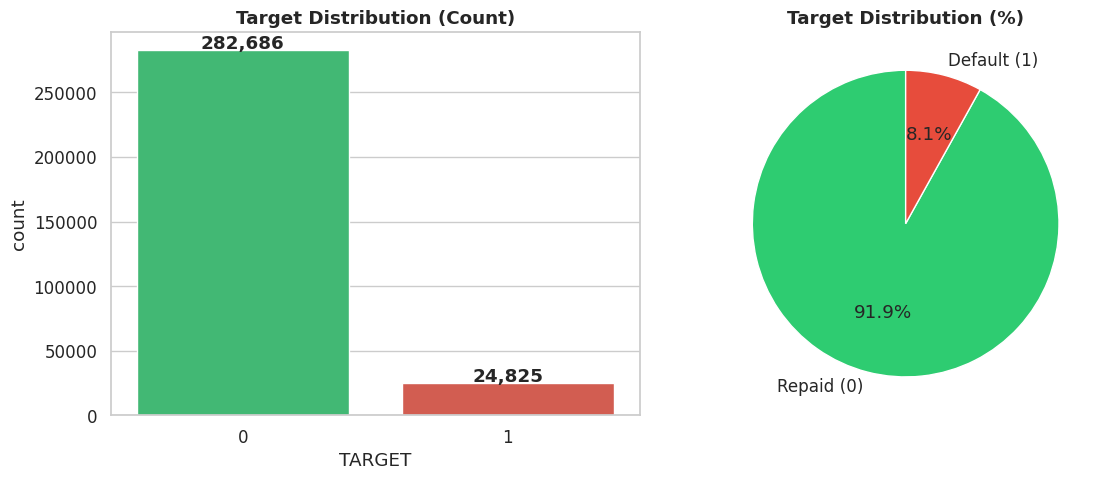

In [8]:
target_counts = app_train["TARGET"].value_counts()
target_pct = app_train["TARGET"].value_counts(normalize=True) * 100

print("Target Distribution:")
print(f"  0 (Repaid):  {target_counts[0]:>8,}  ({target_pct[0]:.2f}%)")
print(f"  1 (Default): {target_counts[1]:>8,}  ({target_pct[1]:.2f}%)")
print(f"  Imbalance ratio: {target_counts[0] / target_counts[1]:.1f} : 1")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar plot
sns.countplot(x="TARGET", data=app_train, ax=axes[0], palette=["#2ecc71", "#e74c3c"])
axes[0].set_title("Target Distribution (Count)", fontweight='bold')
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 1000, f"{v:,}", ha='center', fontweight='bold')

# Pie chart
axes[1].pie(target_counts.values, labels=["Repaid (0)", "Default (1)"],
            autopct='%1.1f%%', colors=["#2ecc71", "#e74c3c"], startangle=90)
axes[1].set_title("Target Distribution (%)", fontweight='bold')

plt.tight_layout()
plt.show()

### 2.2 Missing Values Investigation

In [9]:
df = app_train.copy()

missing_pct = (df.isnull().mean() * 100).sort_values(ascending=False)
missing_count = df.isnull().sum().sort_values(ascending=False)
missing_summary = pd.DataFrame({
    "missing_count": missing_count,
    "missing_pct": missing_pct.round(2)
})
missing_summary = missing_summary[missing_summary["missing_pct"] > 0]

print(f"Columns with missing values: {len(missing_summary)} out of {df.shape[1]}")
print(f"Columns with > 50% missing: {(missing_pct > 50).sum()}")
print(f"Columns with > 30% missing: {(missing_pct > 30).sum()}")
display(missing_summary.head(20))

Columns with missing values: 64 out of 122
Columns with > 50% missing: 41
Columns with > 30% missing: 50


,missing_count,missing_pct
COMMONAREA_AVG,214865,69.8700
COMMONAREA_MODE,214865,69.8700
COMMONAREA_MEDI,214865,69.8700
NONLIVINGAPARTMENTS_MEDI,213514,69.4300
NONLIVINGAPARTMENTS_MODE,213514,69.4300
NONLIVINGAPARTMENTS_AVG,213514,69.4300
FONDKAPREMONT_MODE,210295,68.3900
LIVINGAPARTMENTS_AVG,210199,68.3500
LIVINGAPARTMENTS_MEDI,210199,68.3500
LIVINGAPARTMENTS_MODE,210199,68.3500


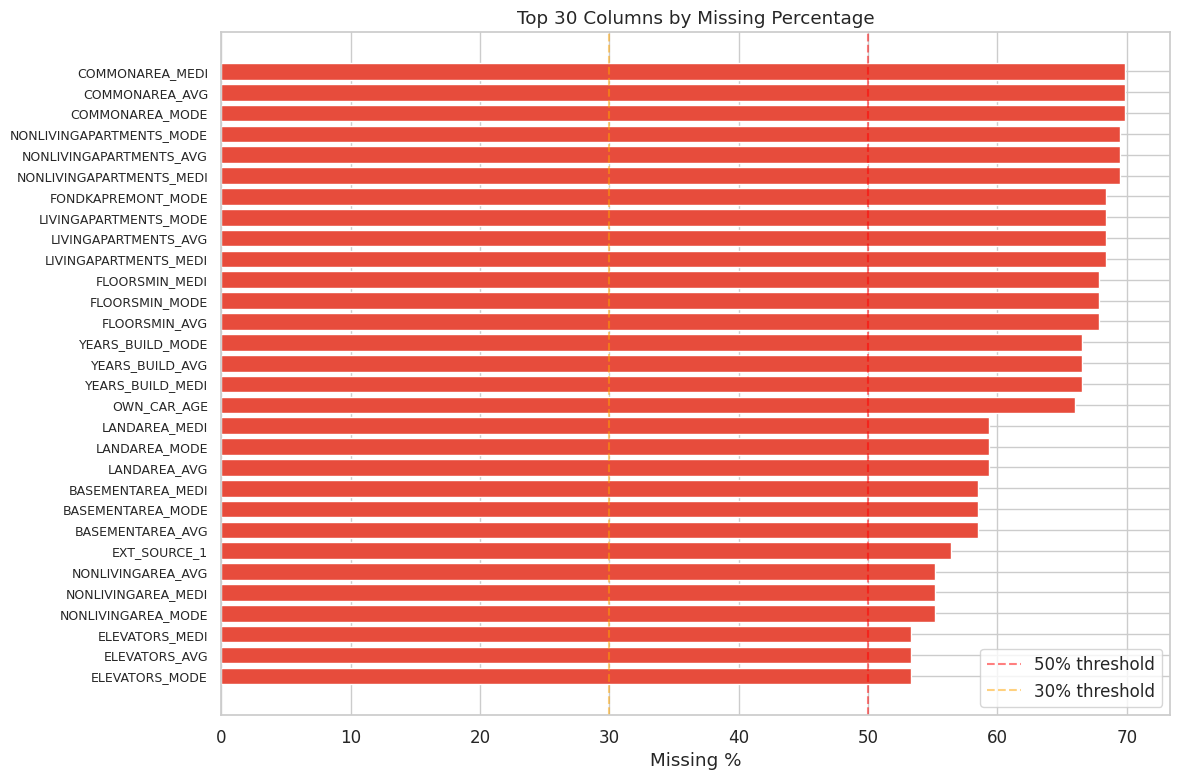

In [10]:
# Visualize top 30 missing columns
plt.figure(figsize=(12, 8))
top_missing = missing_summary.head(30).sort_values("missing_pct")
colors = ["#e74c3c" if v > 50 else "#f39c12" if v > 30 else "#3498db" for v in top_missing["missing_pct"]]
plt.barh(range(len(top_missing)), top_missing["missing_pct"], color=colors)
plt.yticks(range(len(top_missing)), top_missing.index, fontsize=9)
plt.xlabel("Missing %")
plt.title("Top 30 Columns by Missing Percentage")
plt.axvline(x=50, color='red', linestyle='--', alpha=0.5, label='50% threshold')
plt.axvline(x=30, color='orange', linestyle='--', alpha=0.5, label='30% threshold')
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# Grouped missingness analysis
building_cols = [c for c in df.columns if any(x in c for x in ["AVG", "MODE", "MEDI"])
                 and c not in ["FONDKAPREMONT_MODE"]]

building_missing = df[building_cols[:6]].isnull()
print("Building-related columns missing together (correlation):")
print(building_missing.corr().round(2).iloc[:5, :5])

# Missingness as predictive signal
key_missing_cols = [
    "OCCUPATION_TYPE", "OWN_CAR_AGE", "EXT_SOURCE_1", "EXT_SOURCE_3",
    "APARTMENTS_AVG", "BASEMENTAREA_AVG", "YEARS_BUILD_AVG",
    "AMT_REQ_CREDIT_BUREAU_YEAR"
]

print("\nDefault rate by missingness status:")
print("=" * 60)
for col in key_missing_cols:
    if col in df.columns:
        missing_flag = df[col].isnull().astype(int)
        rates = df.groupby(missing_flag)["TARGET"].agg(["mean", "count"])
        rates.index = ["Present", "Missing"]
        print(f"\n{col}:")
        for idx, row in rates.iterrows():
            print(f"  {idx:<10s}  Default: {row['mean']:.4f}  (n={int(row['count']):,})")

Building-related columns missing together (correlation):
                             APARTMENTS_AVG  BASEMENTAREA_AVG  \
APARTMENTS_AVG                       1.0000            0.8400   
BASEMENTAREA_AVG                     0.8400            1.0000   
YEARS_BEGINEXPLUATATION_AVG          0.9500            0.8200   
YEARS_BUILD_AVG                      0.7100            0.7800   
COMMONAREA_AVG                       0.6600            0.7500   

                             YEARS_BEGINEXPLUATATION_AVG  YEARS_BUILD_AVG  \
APARTMENTS_AVG                                    0.9500           0.7100   
BASEMENTAREA_AVG                                  0.8200           0.7800   
YEARS_BEGINEXPLUATATION_AVG                       1.0000           0.6900   
YEARS_BUILD_AVG                                   0.6900           1.0000   
COMMONAREA_AVG                                    0.6400           0.9100   

                             COMMONAREA_AVG  
APARTMENTS_AVG                       0.6600

### 2.3 Numerical Feature Analysis

In [12]:
# Feature engineering for EDA (will be reused later)
df["DAYS_EMPLOYED_ANOMALY"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)
df.loc[df["DAYS_EMPLOYED"] == 365243, "DAYS_EMPLOYED"] = np.nan
df["AGE_YEARS"] = (-df["DAYS_BIRTH"]) / 365.25
df["EMPLOYED_YEARS"] = (-df["DAYS_EMPLOYED"]) / 365.25
df["CREDIT_INCOME_RATIO"] = df["AMT_CREDIT"] / (df["AMT_INCOME_TOTAL"] + 1)
df["ANNUITY_INCOME_RATIO"] = df["AMT_ANNUITY"] / (df["AMT_INCOME_TOTAL"] + 1)
df["ANNUITY_CREDIT_RATIO"] = df["AMT_ANNUITY"] / (df["AMT_CREDIT"] + 1)
df["INCOME_PER_PERSON"] = df["AMT_INCOME_TOTAL"] / (df["CNT_FAM_MEMBERS"] + 1)
df["EXT_SOURCE_MEAN"] = df[["EXT_SOURCE_1","EXT_SOURCE_2","EXT_SOURCE_3"]].mean(axis=1)

numerical_features = [
    "AGE_YEARS", "EMPLOYED_YEARS", "AMT_INCOME_TOTAL", "AMT_CREDIT",
    "AMT_ANNUITY", "AMT_GOODS_PRICE", "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO", "ANNUITY_CREDIT_RATIO", "INCOME_PER_PERSON",
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "EXT_SOURCE_MEAN"
]

stats_df = df[numerical_features].describe().T
stats_df["skewness"] = df[numerical_features].skew()
stats_df["kurtosis"] = df[numerical_features].kurtosis()
display(stats_df.round(2))

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
AGE_YEARS,307511.0000,43.9100,11.9500,20.5000,33.9800,43.1200,53.8900,69.0700,0.1200,-1.0500
EMPLOYED_YEARS,252137.0000,6.5300,6.4000,-0.0000,2.1000,4.5100,8.6900,49.0400,1.9700,4.7500
AMT_INCOME_TOTAL,307511.0000,168797.9200,237123.1500,25650.0000,112500.0000,147150.0000,202500.0000,117000000.0000,391.5600,191786.5500
AMT_CREDIT,307511.0000,599025.9400,402479.5300,45000.0000,270000.0000,513531.0000,808650.0000,4050000.0000,1.2300,1.9300
AMT_ANNUITY,307499.0000,27108.5700,14493.2300,1615.5000,16524.0000,24903.0000,34596.0000,258025.5000,1.5800,7.7100
AMT_GOODS_PRICE,307233.0000,538396.1200,369542.6600,40500.0000,238500.0000,450000.0000,679500.0000,4050000.0000,1.3500,2.4300
CREDIT_INCOME_RATIO,307511.0000,3.9600,2.6900,0.0000,2.0200,3.2700,5.1600,84.7300,1.8400,8.3700
ANNUITY_INCOME_RATIO,307499.0000,0.1800,0.0900,0.0000,0.1100,0.1600,0.2300,1.8800,1.5100,5.4500
ANNUITY_CREDIT_RATIO,307499.0000,0.0500,0.0200,0.0200,0.0400,0.0500,0.0600,0.1200,1.1200,0.5300
INCOME_PER_PERSON,307509.0000,57482.2500,65851.6600,2647.0600,33750.0000,49500.0000,67500.0000,29250000.0000,286.2900,125719.5000


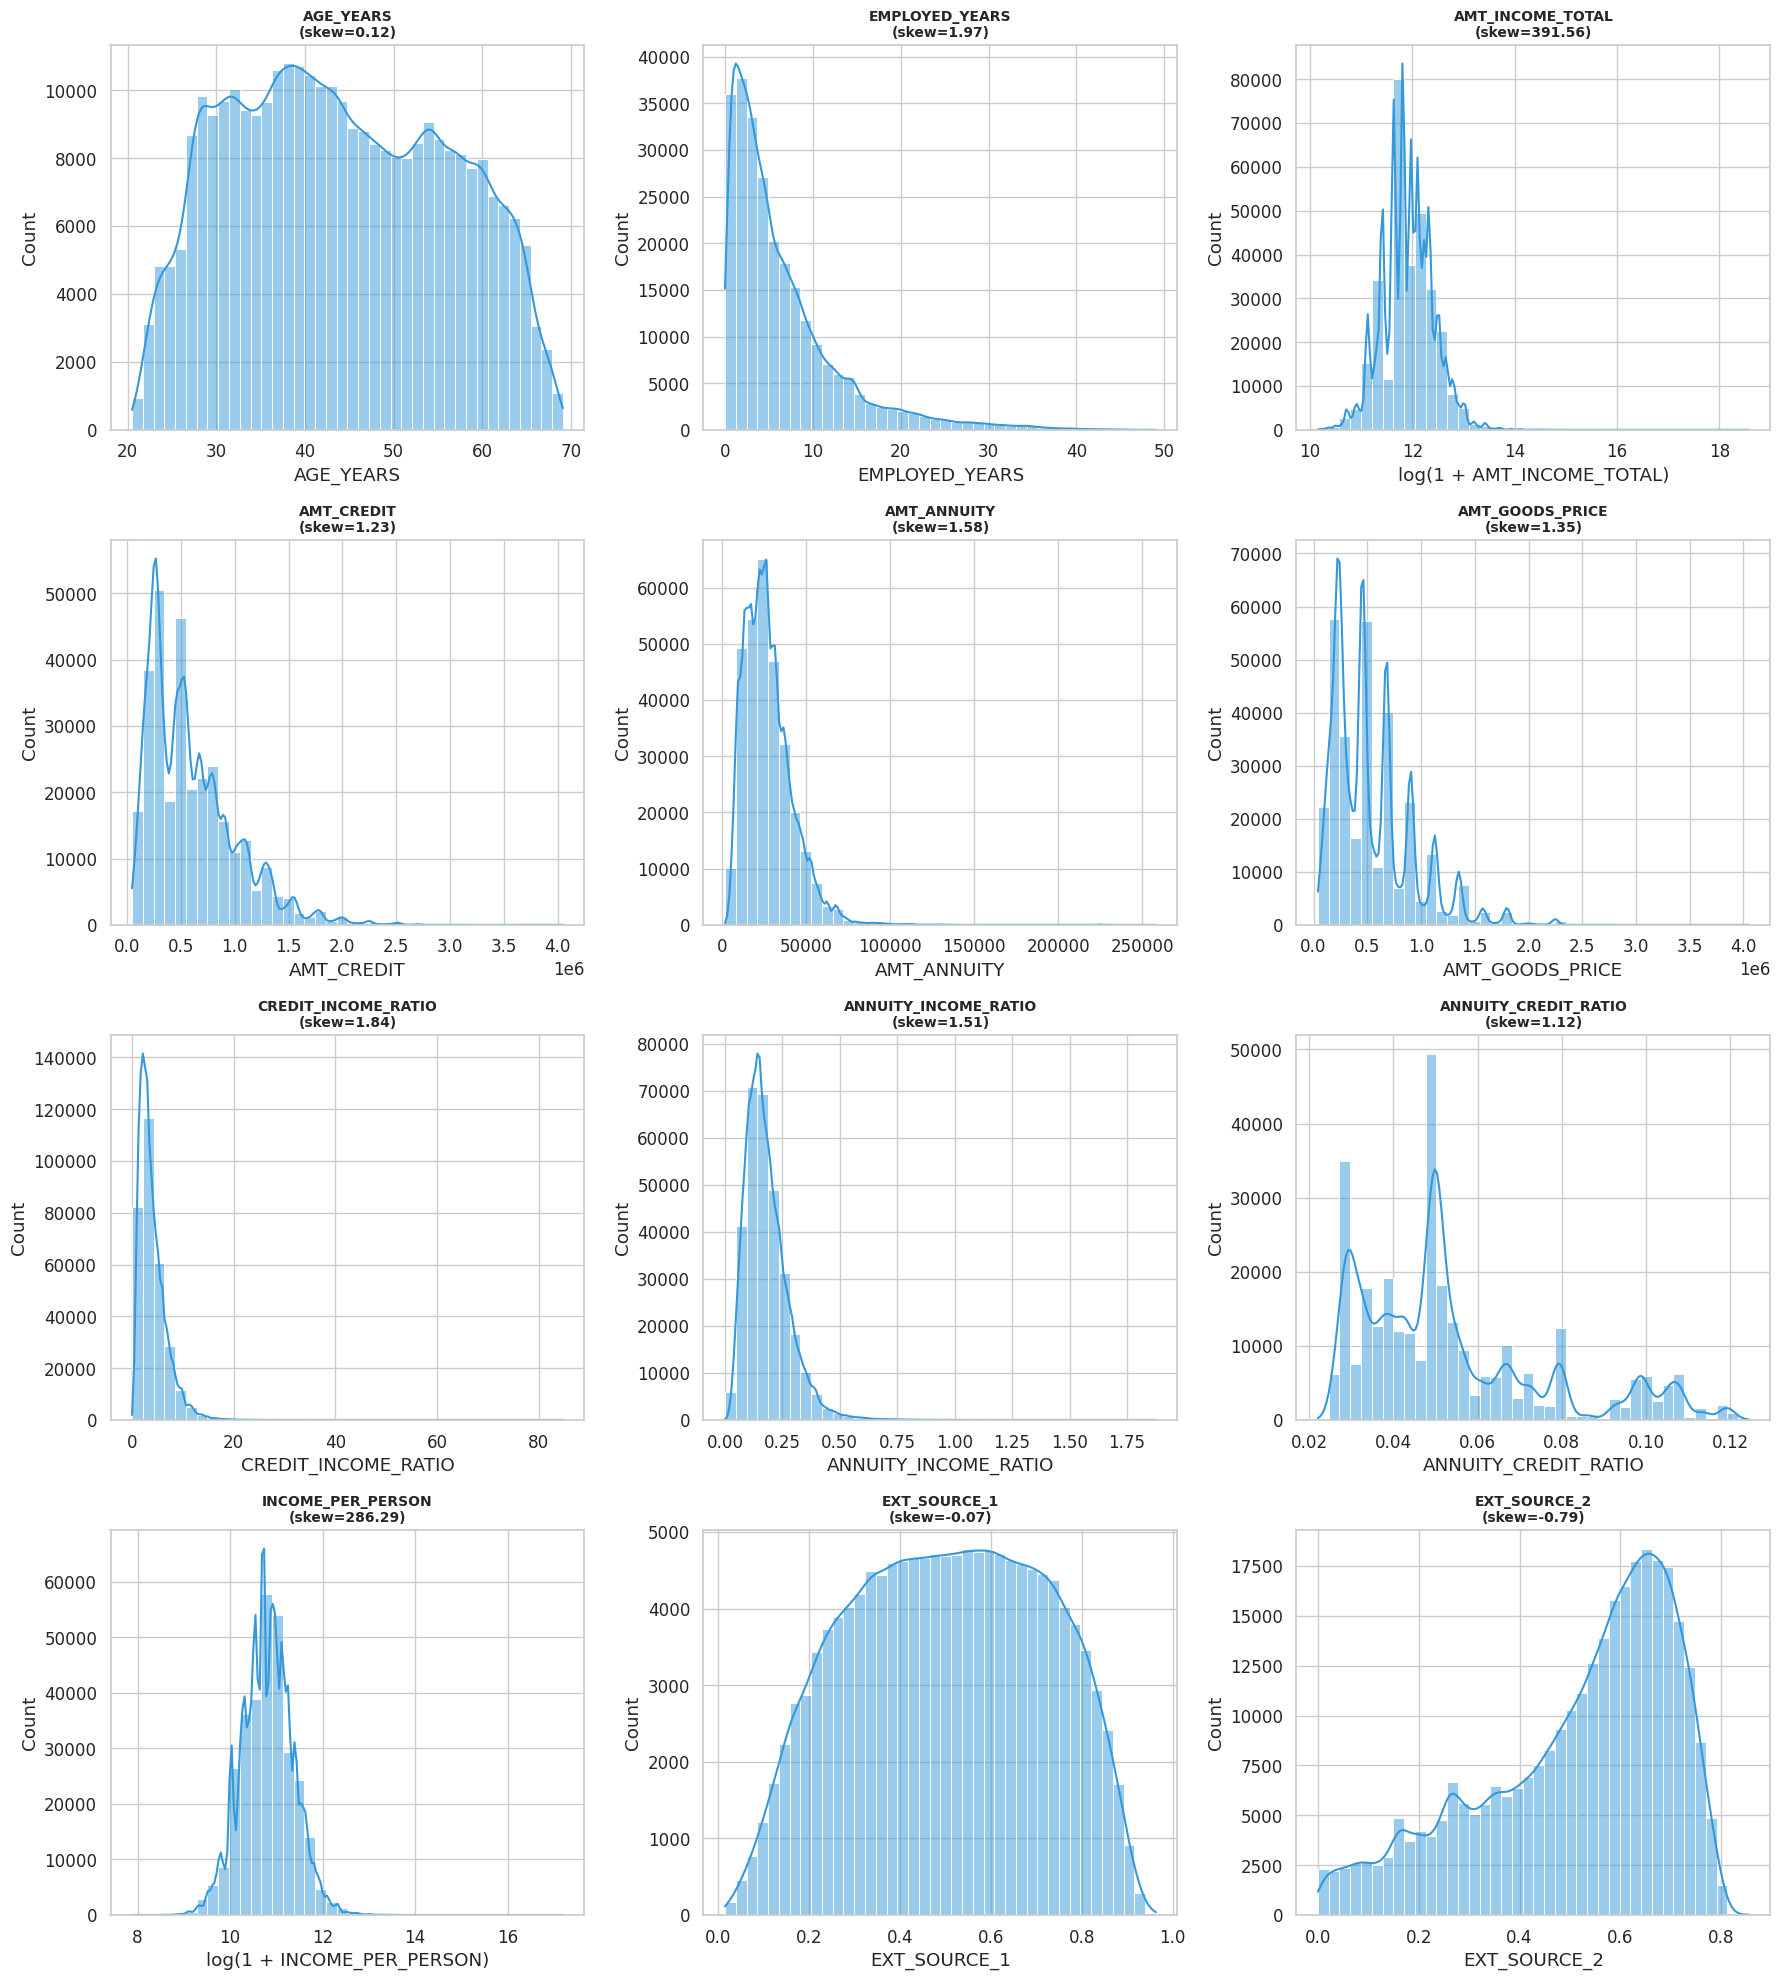

In [13]:
# Distribution plots
fig, axes = plt.subplots(4, 3, figsize=(18, 20))
axes = axes.flatten()

for i, feature in enumerate(numerical_features[:12]):
    ax = axes[i]
    data = df[feature].dropna()
    if data.skew() > 3:
        data_plot = np.log1p(data)
        ax.set_xlabel(f"log(1 + {feature})")
    else:
        data_plot = data
        ax.set_xlabel(feature)
    sns.histplot(data_plot, bins=40, ax=ax, color="#3498db", kde=True)
    ax.set_title(f"{feature}\n(skew={data.skew():.2f})", fontweight='bold', fontsize=10)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

,Feature,Q1,Q3,IQR,Outliers,Outlier_Pct
0,AGE_YEARS,33.9800,53.8900,19.9000,0,0.0000
1,EMPLOYED_YEARS,2.1000,8.6900,6.5900,15149,6.0100
2,AMT_INCOME_TOTAL,112500.0000,202500.0000,90000.0000,14035,4.5600
3,AMT_CREDIT,270000.0000,808650.0000,538650.0000,6562,2.1300
4,AMT_ANNUITY,16524.0000,34596.0000,18072.0000,7504,2.4400
5,AMT_GOODS_PRICE,238500.0000,679500.0000,441000.0000,14728,4.7900
6,CREDIT_INCOME_RATIO,2.0200,5.1600,3.1400,11493,3.7400
7,ANNUITY_INCOME_RATIO,0.1100,0.2300,0.1100,7878,2.5600
8,ANNUITY_CREDIT_RATIO,0.0400,0.0600,0.0300,15933,5.1800


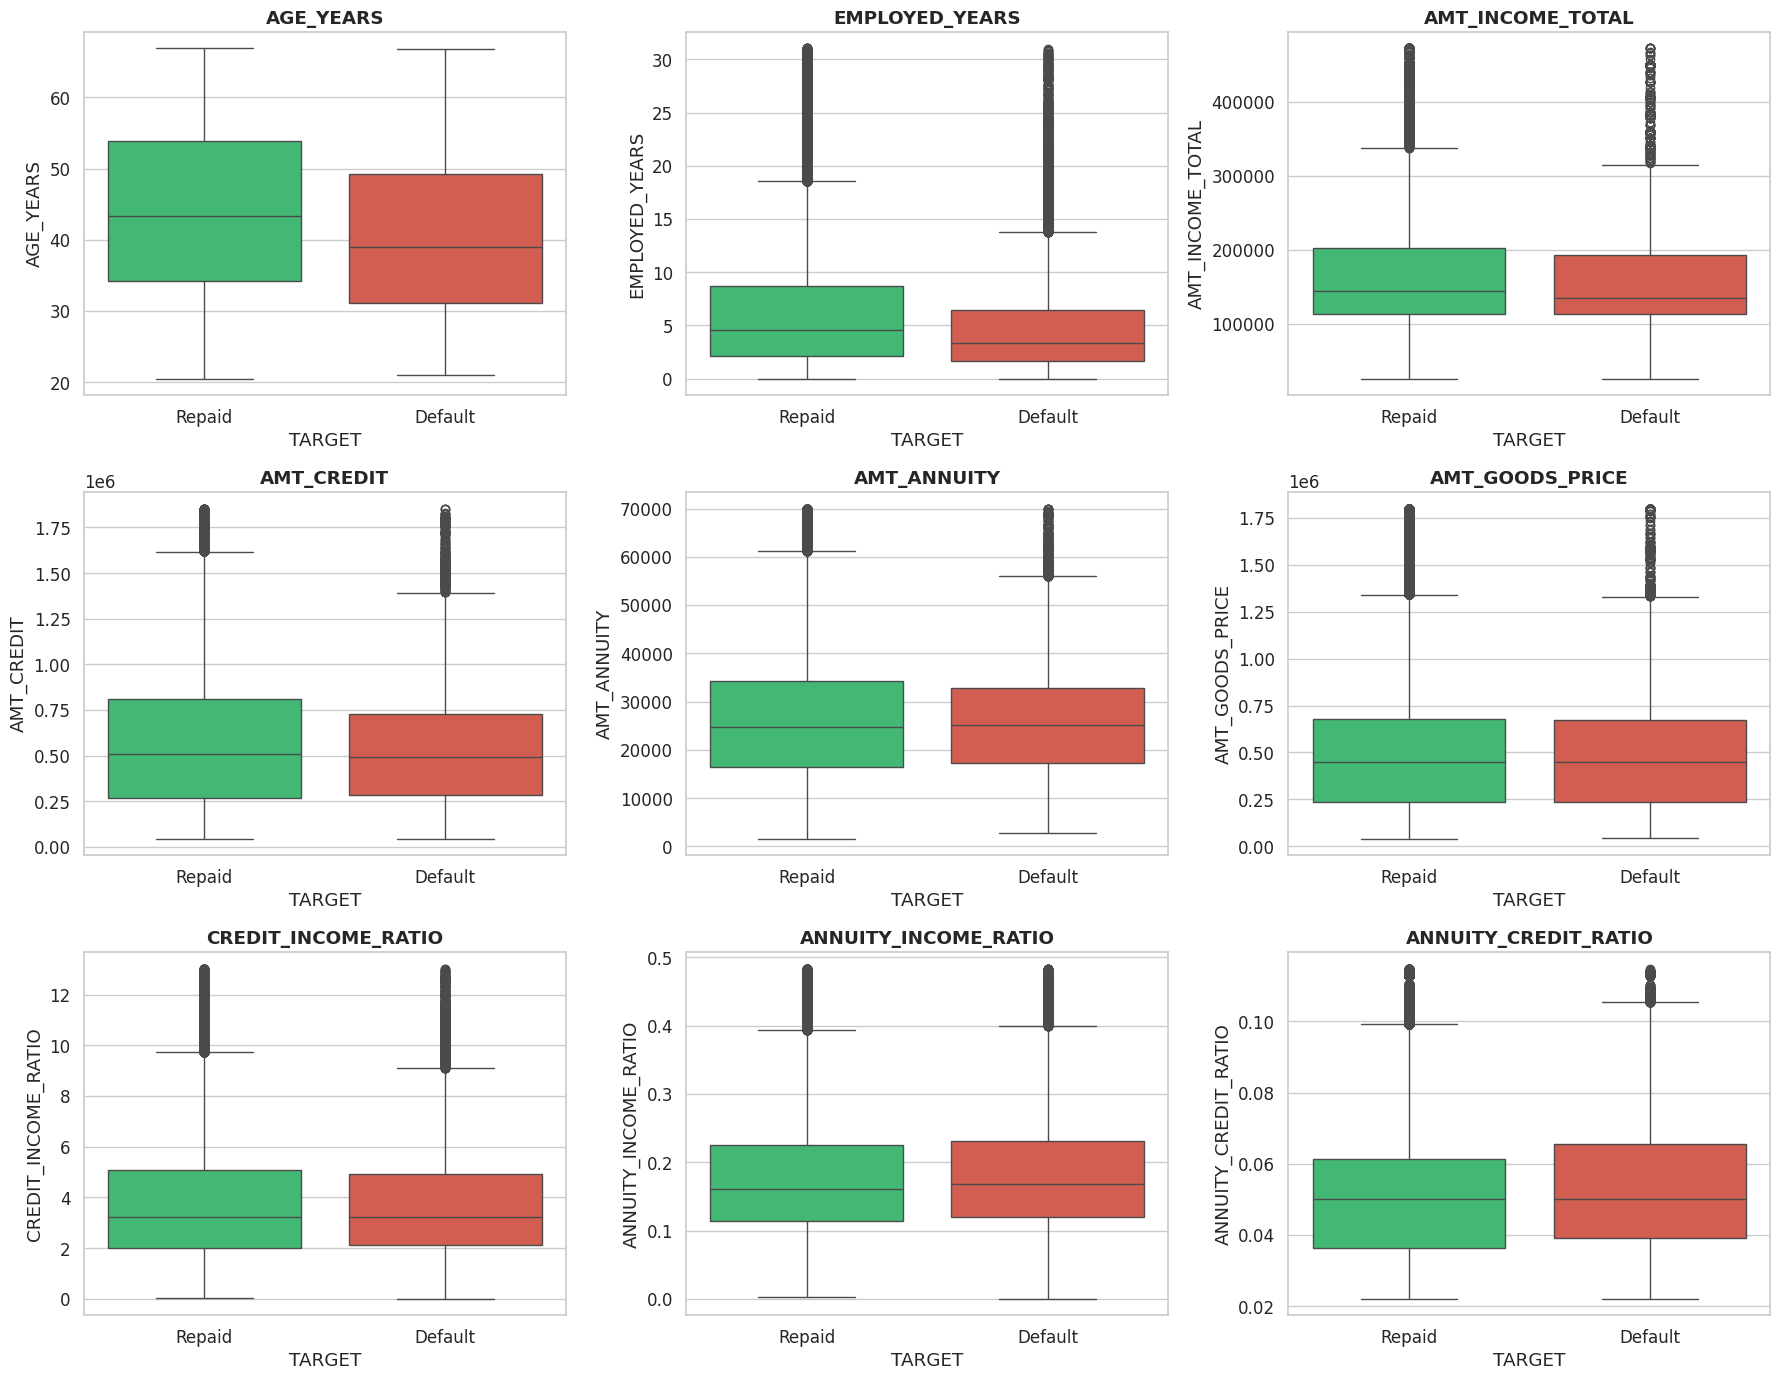

In [14]:
# Outlier analysis (IQR method)
important_numerical = [
    "AGE_YEARS", "EMPLOYED_YEARS", "AMT_INCOME_TOTAL", "AMT_CREDIT",
    "AMT_ANNUITY", "AMT_GOODS_PRICE", "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO", "ANNUITY_CREDIT_RATIO"
]

outlier_info = []
for feat in important_numerical:
    data = df[feat].dropna()
    q1, q3 = data.quantile(0.25), data.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((data < lower) | (data > upper)).sum()
    outlier_info.append({"Feature": feat, "Q1": q1, "Q3": q3, "IQR": iqr,
                         "Outliers": n_outliers, "Outlier_Pct": n_outliers/len(data)*100})

outlier_df = pd.DataFrame(outlier_info)
display(outlier_df.round(2))

# Box plots
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()
for i, feat in enumerate(important_numerical):
    ax = axes[i]
    data = df[feat].dropna()
    cap = data.quantile(0.99)
    data_capped = data[data <= cap]
    sns.boxplot(x=df.loc[data_capped.index, "TARGET"],
                y=data_capped, ax=ax, palette=["#2ecc71", "#e74c3c"])
    ax.set_title(feat, fontweight='bold')
    ax.set_xticklabels(["Repaid", "Default"])
plt.tight_layout()
plt.show()

### 2.4 Categorical Feature Analysis (Chi-Square Tests)

In [15]:
def analyze_categorical(data, column, target="TARGET", min_count=100):
    contingency = pd.crosstab(data[column], data[target])
    chi2, p_value, dof, expected = stats.chi2_contingency(contingency)
    rates = data.groupby(column)[target].agg(["mean", "count"])
    rates.columns = ["default_rate", "count"]
    rates = rates[rates["count"] >= min_count].sort_values("default_rate", ascending=False)
    return chi2, p_value, dof, rates

categorical_cols = df.select_dtypes(include='object').columns.tolist()
cat_results = {}
for col in categorical_cols:
    chi2, p_val, dof, rates = analyze_categorical(df, col)
    cat_results[col] = {"chi2": chi2, "p_value": p_val, "dof": dof, "categories": len(rates)}

chi2_summary = pd.DataFrame(cat_results).T
chi2_summary["significant"] = chi2_summary["p_value"] < 0.05
chi2_summary = chi2_summary.sort_values("chi2", ascending=False)

print("Chi-Square Test Results (all categorical features vs TARGET):")
display(chi2_summary.round(4))
sig_count = chi2_summary["significant"].sum()
print(f"\n{sig_count} out of {len(chi2_summary)} features are significant (p < 0.05)")

Chi-Square Test Results (all categorical features vs TARGET):


,chi2,p_value,dof,categories,significant
ORGANIZATION_TYPE,1609.2406,0.0000,57.0000,53.0000,True
OCCUPATION_TYPE,1402.8468,0.0000,17.0000,18.0000,True
NAME_INCOME_TYPE,1253.4708,0.0000,7.0000,4.0000,True
NAME_EDUCATION_TYPE,1019.2132,0.0000,4.0000,5.0000,True
CODE_GENDER,920.7913,0.0000,2.0000,2.0000,True
NAME_FAMILY_STATUS,504.6941,0.0000,5.0000,5.0000,True
NAME_HOUSING_TYPE,420.5562,0.0000,5.0000,6.0000,True
NAME_CONTRACT_TYPE,293.1505,0.0000,1.0000,2.0000,True
FLAG_OWN_CAR,146.6560,0.0000,1.0000,2.0000,True
WALLSMATERIAL_MODE,139.2353,0.0000,6.0000,7.0000,True



16 out of 16 features are significant (p < 0.05)


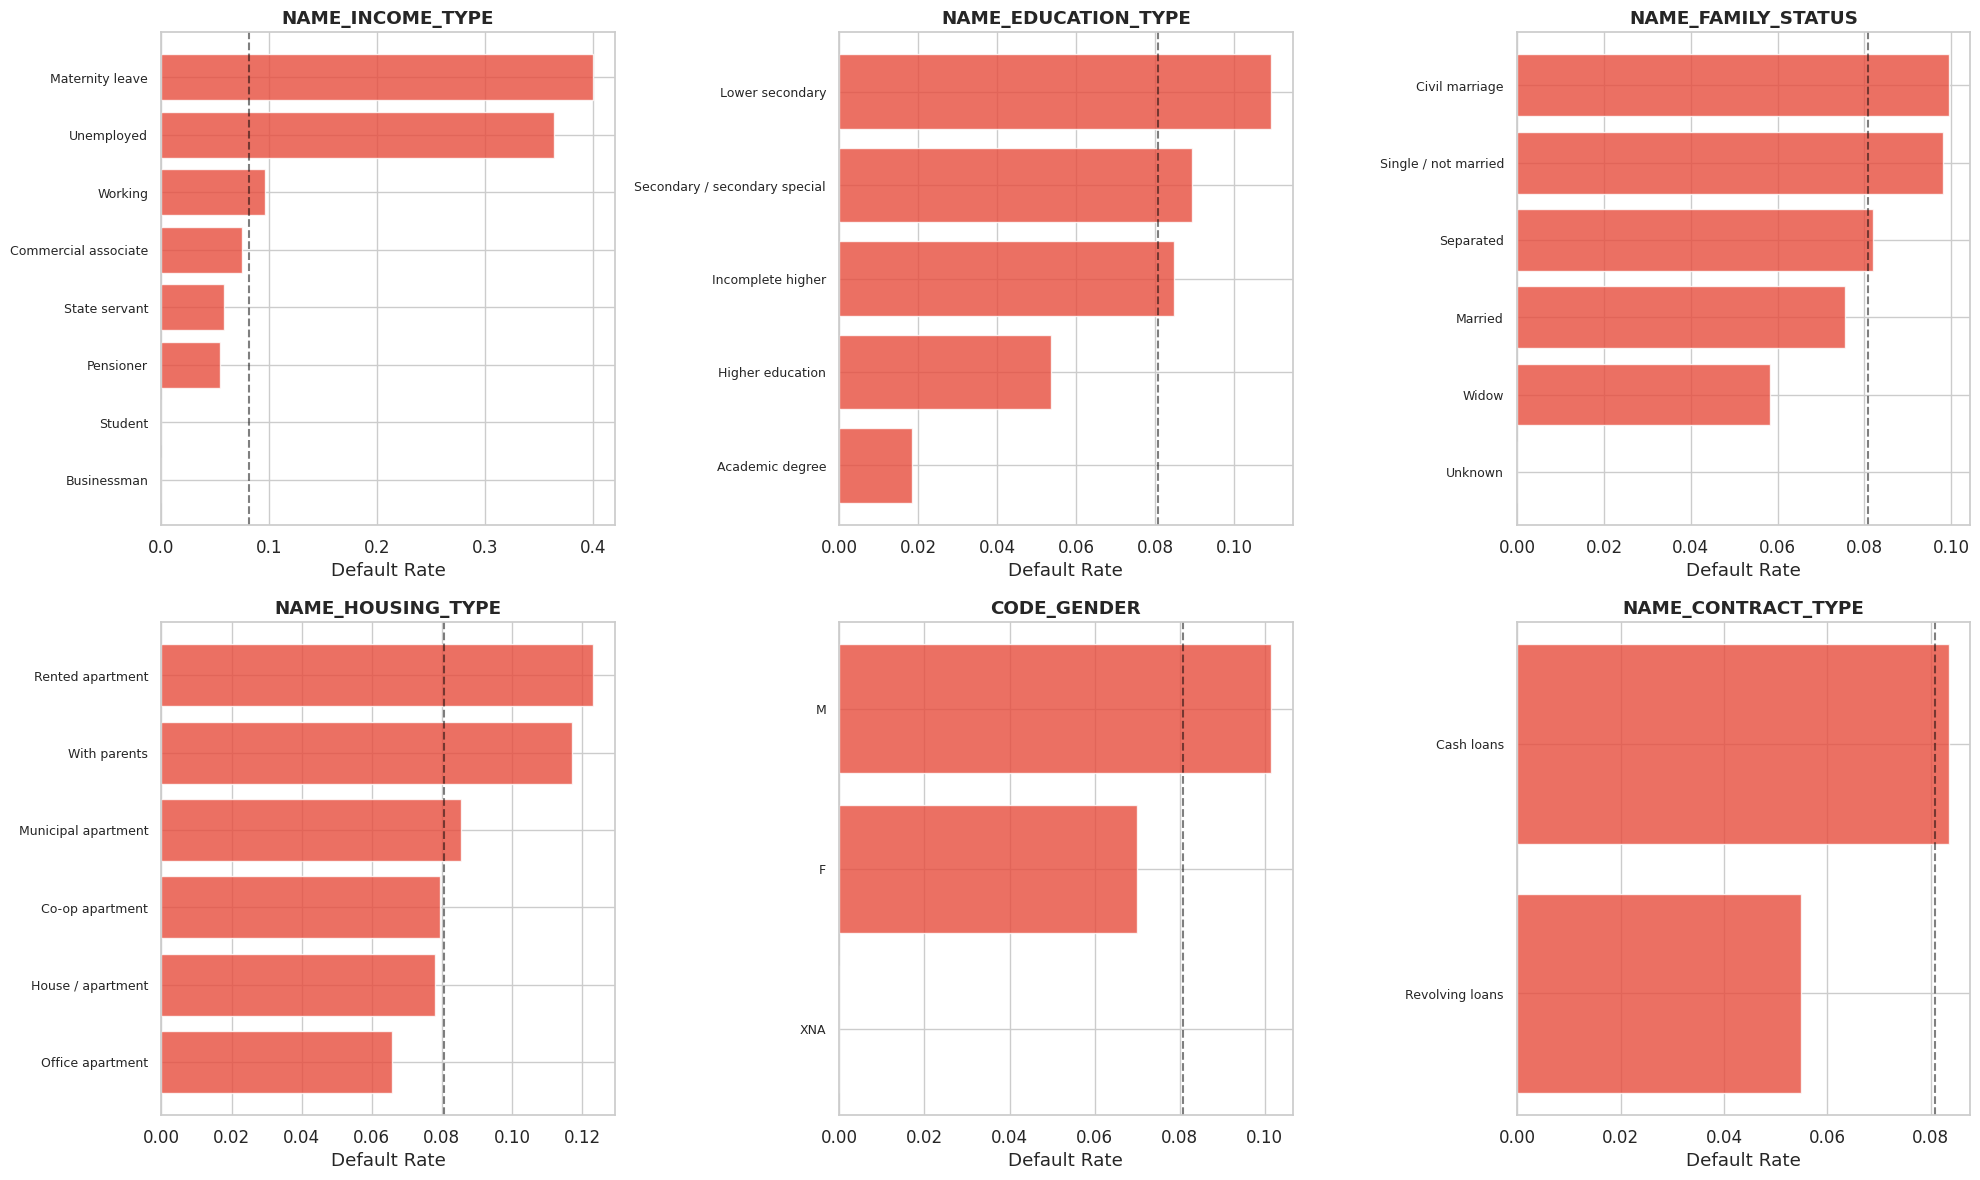

In [16]:
# Default rates for top categorical features
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

plot_cats = ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS",
             "NAME_HOUSING_TYPE", "CODE_GENDER", "NAME_CONTRACT_TYPE"]

for i, col in enumerate(plot_cats):
    ax = axes[i]
    rates = df.groupby(col)["TARGET"].mean().sort_values(ascending=True)
    bars = ax.barh(range(len(rates)), rates.values, color="#e74c3c", alpha=0.8)
    ax.set_yticks(range(len(rates)))
    ax.set_yticklabels(rates.index, fontsize=9)
    ax.set_xlabel("Default Rate")
    ax.set_title(f"{col}", fontweight='bold')
    ax.axvline(x=df["TARGET"].mean(), color='black', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 2.5 External Credit Scores Deep Dive (EXT_SOURCE_1/2/3)

=== External Credit Scores Descriptive Statistics ===

EXT_SOURCE_1:
count   134133.0000
mean         0.5021
std          0.2111
min          0.0146
25%          0.3340
50%          0.5060
75%          0.6751
max          0.9627
Name: EXT_SOURCE_1, dtype: float64
Missingness: 173378 (56.38%)

EXT_SOURCE_2:
count   306851.0000
mean         0.5144
std          0.1911
min          0.0000
25%          0.3925
50%          0.5660
75%          0.6636
max          0.8550
Name: EXT_SOURCE_2, dtype: float64
Missingness: 660 (0.21%)

EXT_SOURCE_3:
count   246546.0000
mean         0.5109
std          0.1948
min          0.0005
25%          0.3706
50%          0.5353
75%          0.6691
max          0.8960
Name: EXT_SOURCE_3, dtype: float64
Missingness: 60965 (19.83%)



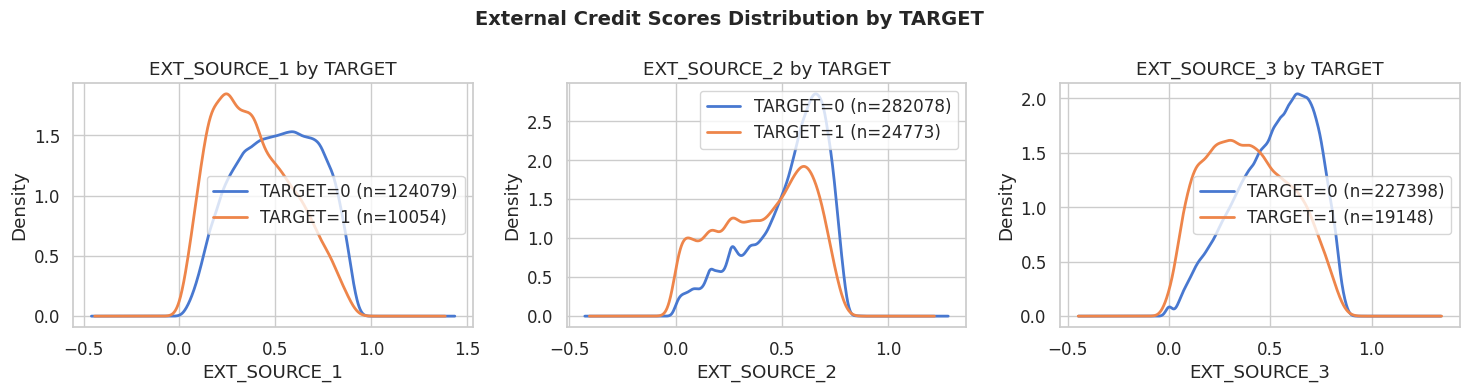

In [17]:
ext_sources = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']

print("=== External Credit Scores Descriptive Statistics ===\n")
for ext in ext_sources:
    print(f"{ext}:")
    print(df[ext].describe())
    print(f"Missingness: {df[ext].isna().sum()} ({df[ext].isna().sum()/len(df)*100:.2f}%)\n")

# KDE distribution plots by TARGET
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('External Credit Scores Distribution by TARGET', fontsize=14, fontweight='bold')

for idx, ext in enumerate(ext_sources):
    ax = axes[idx]
    for target in [0, 1]:
        data = df[df['TARGET'] == target][ext].dropna()
        data.plot.kde(ax=ax, label=f'TARGET={target} (n={len(data)})', linewidth=2)
    ax.set_xlabel(ext)
    ax.set_ylabel('Density')
    ax.set_title(f'{ext} by TARGET')
    ax.legend()

plt.tight_layout()
plt.show()

=== Kolmogorov-Smirnov Tests (Default vs Repaid) ===

EXT_SOURCE_1: KS=0.2427, p=0.000000, Significant=True
EXT_SOURCE_2: KS=0.2237, p=0.000000, Significant=True
EXT_SOURCE_3: KS=0.2698, p=0.000000, Significant=True


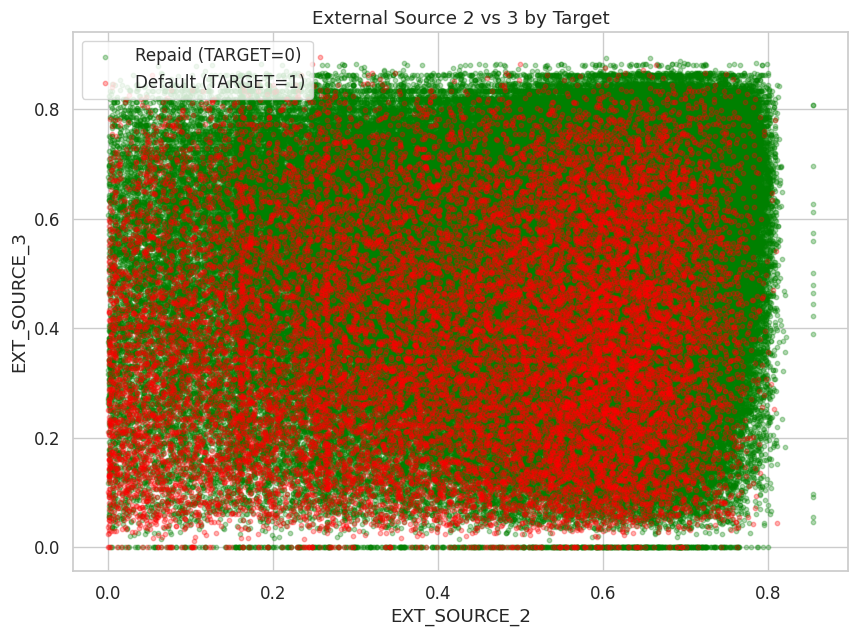

In [18]:
# Kolmogorov-Smirnov tests
print("=== Kolmogorov-Smirnov Tests (Default vs Repaid) ===\n")
for ext in ext_sources:
    default = df[df['TARGET'] == 1][ext].dropna()
    repaid = df[df['TARGET'] == 0][ext].dropna()
    ks_stat, p_value = stats.ks_2samp(default, repaid)
    print(f"{ext}: KS={ks_stat:.4f}, p={p_value:.6f}, Significant={p_value < 0.05}")

# Scatter: EXT_SOURCE_2 vs EXT_SOURCE_3
valid_mask = df['EXT_SOURCE_2'].notna() & df['EXT_SOURCE_3'].notna()
fig, ax = plt.subplots(figsize=(10, 7))
scatter = ax.scatter(df[valid_mask & (df['TARGET']==0)]['EXT_SOURCE_2'],
                     df[valid_mask & (df['TARGET']==0)]['EXT_SOURCE_3'],
                     c='green', alpha=0.3, s=10, label='Repaid (TARGET=0)')
scatter = ax.scatter(df[valid_mask & (df['TARGET']==1)]['EXT_SOURCE_2'],
                     df[valid_mask & (df['TARGET']==1)]['EXT_SOURCE_3'],
                     c='red', alpha=0.3, s=10, label='Default (TARGET=1)')
ax.set_xlabel('EXT_SOURCE_2')
ax.set_ylabel('EXT_SOURCE_3')
ax.set_title('External Source 2 vs 3 by Target')
ax.legend()
plt.show()

### 2.6 Statistical Testing (Mann-Whitney U)

=== Mann-Whitney U Test Results (Default vs Repaid) ===

Feature                   U Statistic     P-value      Significant 
-----------------------------------------------------------------
AGE_YEARS                 2926354692      0.000000     YES
EMPLOYED_YEARS            2100007078      0.000000     YES
AMT_INCOME_TOTAL          3374530804      0.000000     YES
AMT_CREDIT                3378434520      0.000000     YES
AMT_ANNUITY               3508145704      0.967562     NO
CREDIT_INCOME_RATIO       3495289335      0.312271     NO
ANNUITY_INCOME_RATIO      3645674242      0.000000     YES
EXT_SOURCE_1              417059756       0.000000     YES
EXT_SOURCE_2              2403004364      0.000000     YES
EXT_SOURCE_3              1395962956      0.000000     YES
EXT_SOURCE_MEAN           1987036292      0.000000     YES


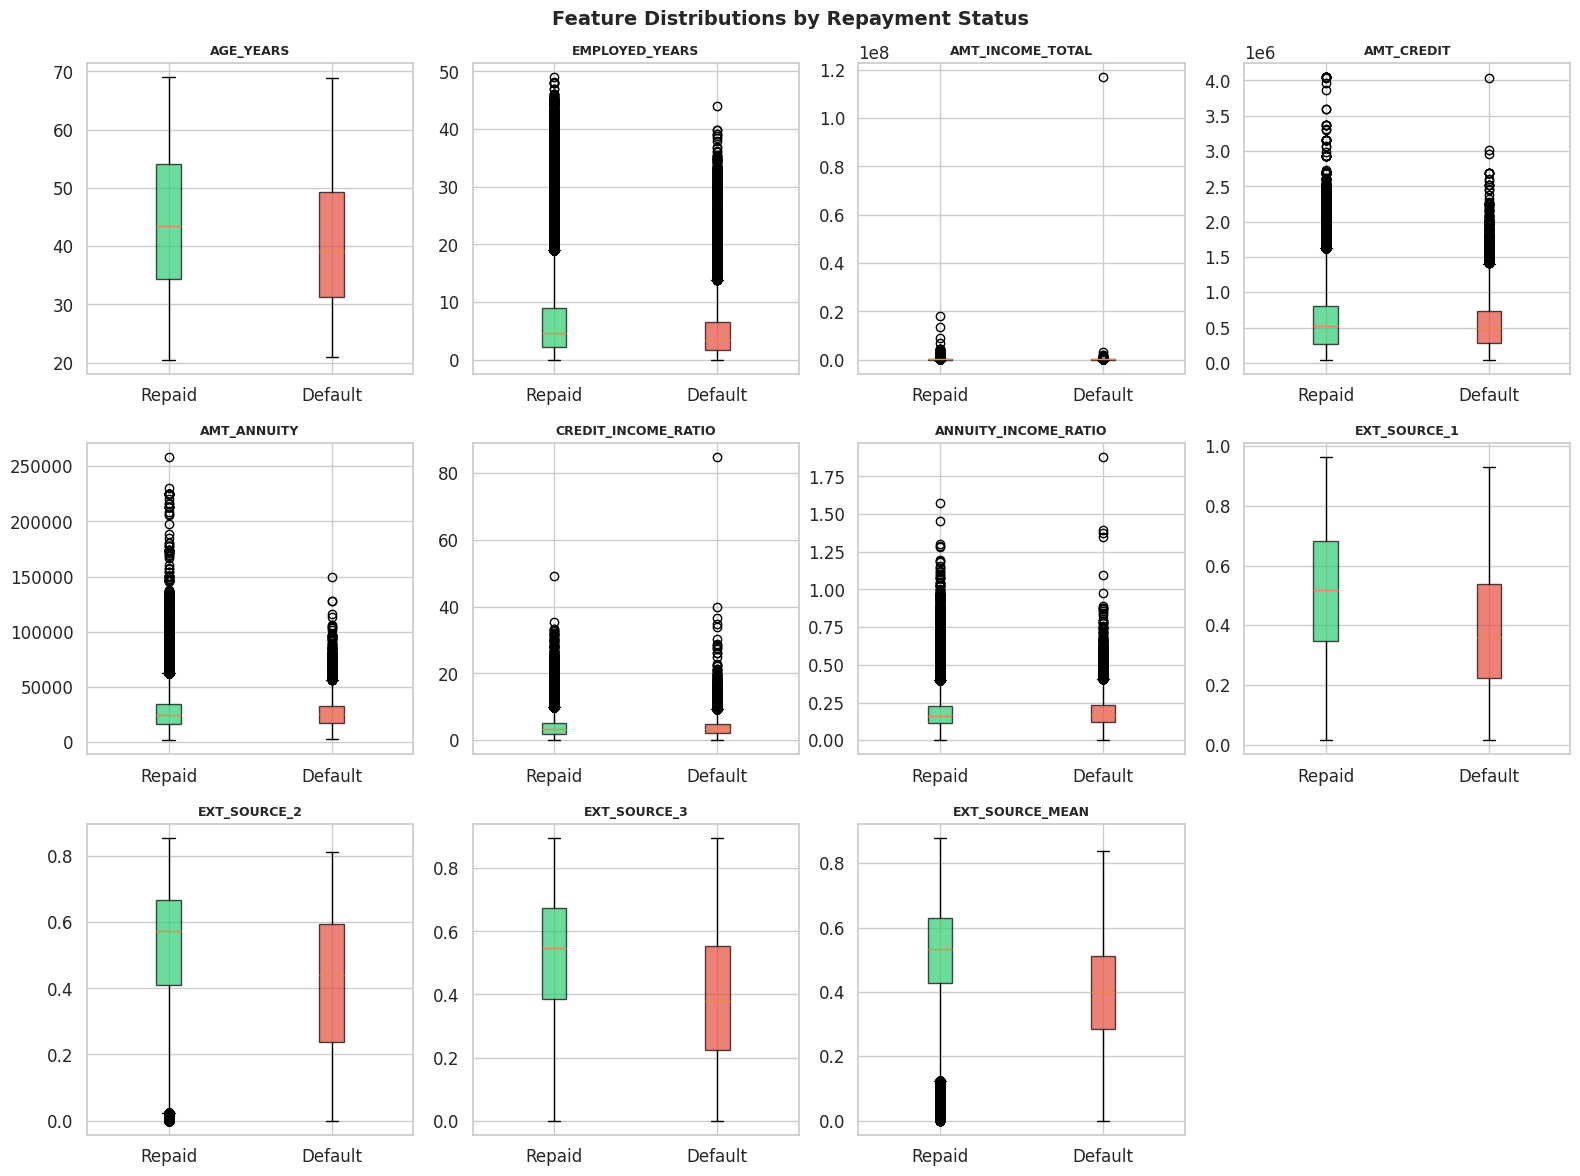

In [19]:
test_features = ['AGE_YEARS', 'EMPLOYED_YEARS', 'AMT_INCOME_TOTAL', 'AMT_CREDIT',
                 'AMT_ANNUITY', 'CREDIT_INCOME_RATIO', 'ANNUITY_INCOME_RATIO',
                 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'EXT_SOURCE_MEAN']

print("=== Mann-Whitney U Test Results (Default vs Repaid) ===\n")
print(f"{'Feature':<25} {'U Statistic':<15} {'P-value':<12} {'Significant':<12}")
print("-" * 65)

mw_results = []
for feature in test_features:
    default = df[df['TARGET'] == 1][feature].dropna()
    repaid = df[df['TARGET'] == 0][feature].dropna()
    u_stat, p_value = stats.mannwhitneyu(default, repaid, alternative='two-sided')
    sig = "YES" if p_value < 0.05 else "NO"
    print(f"{feature:<25} {u_stat:<15.0f} {p_value:<12.6f} {sig}")
    mw_results.append({'Feature': feature, 'U_stat': u_stat, 'p_value': p_value, 'Significant': sig})

# Boxplots by TARGET
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
fig.suptitle('Feature Distributions by Repayment Status', fontsize=14, fontweight='bold')
for idx, feature in enumerate(test_features):
    ax = axes[idx // 4, idx % 4]
    data_by_target = [df[df['TARGET'] == 0][feature].dropna(),
                      df[df['TARGET'] == 1][feature].dropna()]
    bp = ax.boxplot(data_by_target, labels=['Repaid', 'Default'], patch_artist=True)
    for patch, color in zip(bp['boxes'], ['#2ecc71', '#e74c3c']):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax.set_title(feature, fontsize=9, fontweight='bold')

if len(test_features) < 12:
    axes[-1, -1].set_visible(False)
plt.tight_layout()
plt.show()

### 2.7 Binned Risk Analysis

=== Age Group Risk Analysis ===

           Defaults  Total  Default_Rate
AGE_GROUP                               
20-30          5171  45186        0.1144
30-40          7897  82349        0.0959
40-50          5853  76581        0.0764
50-60          4168  68109        0.0612
60-70          1736  35286        0.0492


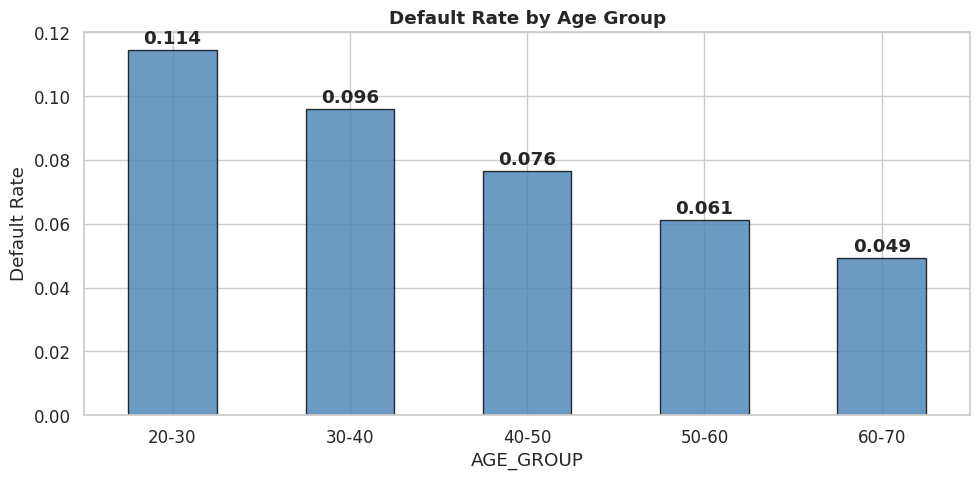


=== EXT_SOURCE_3 Quintile Risk Analysis ===

              Defaults   Total  Default_Rate
EXT_QUINTILE                                
Q1 (Worst)        9334   61993        0.1506
Q2               10287  122349        0.0841
Q3                  38     655        0.0580
Q4                3017   61523        0.0490
Q5 (Best)         2149   60991        0.0352


In [20]:
# Age group risk analysis
df['AGE_GROUP'] = pd.cut(df['AGE_YEARS'], bins=[20, 30, 40, 50, 60, 70],
                         labels=['20-30', '30-40', '40-50', '50-60', '60-70'])
age_risk = df.groupby('AGE_GROUP', observed=True)['TARGET'].agg(['sum', 'count', 'mean'])
age_risk.columns = ['Defaults', 'Total', 'Default_Rate']
print("=== Age Group Risk Analysis ===\n")
print(age_risk)

fig, ax = plt.subplots(figsize=(10, 5))
age_risk['Default_Rate'].plot(kind='bar', ax=ax, color='steelblue', alpha=0.8, edgecolor='black')
ax.set_ylabel('Default Rate')
ax.set_title('Default Rate by Age Group', fontweight='bold')
ax.set_xticklabels(age_risk.index, rotation=0)
for i, v in enumerate(age_risk['Default_Rate']):
    ax.text(i, v + 0.002, f'{v:.3f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

# EXT_SOURCE_3 quintile analysis
df['EXT_QUINTILE'] = pd.qcut(df['EXT_SOURCE_3'].fillna(df['EXT_SOURCE_3'].median()),
                             q=5, labels=['Q1 (Worst)', 'Q2', 'Q3', 'Q4', 'Q5 (Best)'],
                             duplicates='drop')
ext_risk = df.groupby('EXT_QUINTILE', observed=True)['TARGET'].agg(['sum', 'count', 'mean'])
ext_risk.columns = ['Defaults', 'Total', 'Default_Rate']
print("\n=== EXT_SOURCE_3 Quintile Risk Analysis ===\n")
print(ext_risk)

### 2.8 Information Value (IV) & Weight of Evidence (WoE)

**Industry-standard** credit scoring metrics. IV measures overall predictive power.

| IV Range | Predictive Power |
|----------|-----------------|
| < 0.02 | Useless |
| 0.02 – 0.1 | Weak |
| 0.1 – 0.3 | Medium |
| 0.3 – 0.5 | Strong |
| > 0.5 | Suspicious (overfitting) |

=== Information Value (IV) — Feature Ranking ===



,Feature,IV,Predictive_Power
3,EXT_SOURCE_MEAN,0.6086,Suspicious
2,EXT_SOURCE_3,0.4101,Strong
0,EXT_SOURCE_1,0.3465,Strong
1,EXT_SOURCE_2,0.3071,Strong
12,ANNUITY_CREDIT_RATIO,0.1326,Medium
5,EMPLOYED_YEARS,0.0925,Weak
9,AMT_GOODS_PRICE,0.0920,Weak
4,AGE_YEARS,0.0842,Weak
15,REGION_RATING_CLIENT_W_CITY,0.0512,Weak
14,REGION_RATING_CLIENT,0.0483,Weak


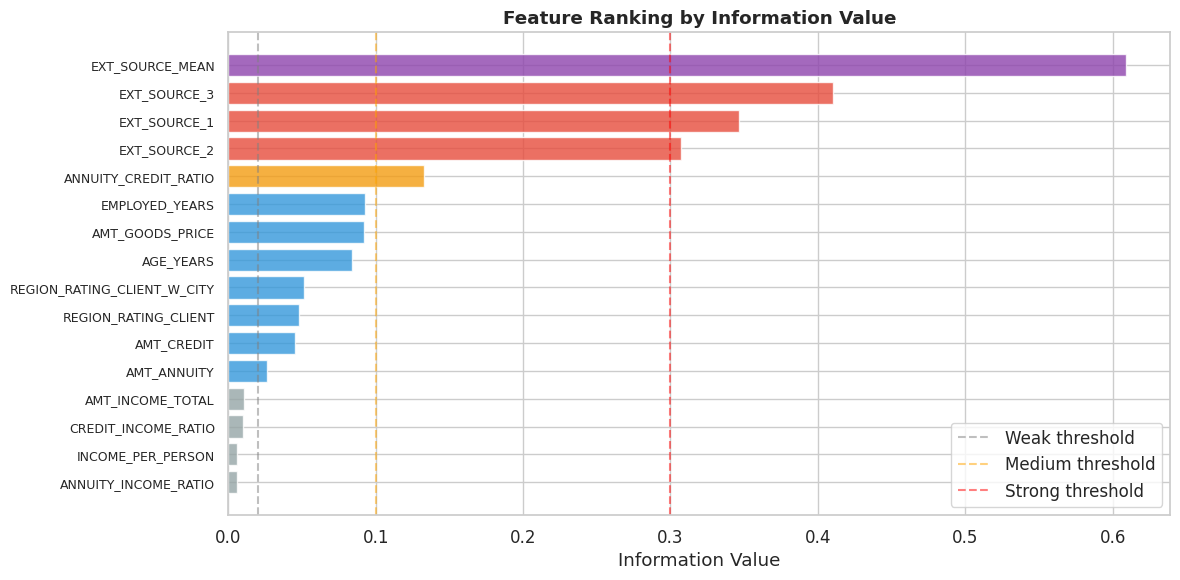

In [21]:
def calculate_iv_woe(data, feature, target='TARGET', bins=10):
    """Calculate Information Value and Weight of Evidence for a feature."""
    d = data[[feature, target]].dropna().copy()

    # Bin continuous features
    if d[feature].nunique() > bins:
        d['bin'] = pd.qcut(d[feature], q=bins, duplicates='drop')
    else:
        d['bin'] = d[feature]

    grouped = d.groupby('bin', observed=True)[target].agg(['sum', 'count'])
    grouped.columns = ['bad', 'total']
    grouped['good'] = grouped['total'] - grouped['bad']

    # Avoid division by zero
    grouped['bad'] = grouped['bad'].replace(0, 0.5)
    grouped['good'] = grouped['good'].replace(0, 0.5)

    grouped['bad_pct'] = grouped['bad'] / grouped['bad'].sum()
    grouped['good_pct'] = grouped['good'] / grouped['good'].sum()
    grouped['woe'] = np.log(grouped['good_pct'] / grouped['bad_pct'])
    grouped['iv'] = (grouped['good_pct'] - grouped['bad_pct']) * grouped['woe']

    iv_total = grouped['iv'].sum()
    return iv_total, grouped

# Calculate IV for all key features
iv_features = [
    'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'EXT_SOURCE_MEAN',
    'AGE_YEARS', 'EMPLOYED_YEARS', 'AMT_INCOME_TOTAL', 'AMT_CREDIT',
    'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'CREDIT_INCOME_RATIO',
    'ANNUITY_INCOME_RATIO', 'ANNUITY_CREDIT_RATIO', 'INCOME_PER_PERSON',
    'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY'
]

iv_results = []
for feat in iv_features:
    if feat in df.columns:
        iv_val, _ = calculate_iv_woe(df, feat)
        power = ('Useless' if iv_val < 0.02 else 'Weak' if iv_val < 0.1
                 else 'Medium' if iv_val < 0.3 else 'Strong' if iv_val < 0.5 else 'Suspicious')
        iv_results.append({'Feature': feat, 'IV': iv_val, 'Predictive_Power': power})

iv_df = pd.DataFrame(iv_results).sort_values('IV', ascending=False)
print("=== Information Value (IV) — Feature Ranking ===\n")
display(iv_df.round(4))

# Visualize IV
fig, ax = plt.subplots(figsize=(12, 6))
colors = {'Strong': '#e74c3c', 'Medium': '#f39c12', 'Weak': '#3498db', 'Useless': '#95a5a6', 'Suspicious': '#8e44ad'}
bar_colors = [colors.get(p, '#95a5a6') for p in iv_df['Predictive_Power']]
ax.barh(range(len(iv_df)), iv_df['IV'], color=bar_colors, alpha=0.8, edgecolor='white')
ax.set_yticks(range(len(iv_df)))
ax.set_yticklabels(iv_df['Feature'], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Information Value')
ax.set_title('Feature Ranking by Information Value', fontweight='bold')
ax.axvline(x=0.02, color='gray', linestyle='--', alpha=0.5, label='Weak threshold')
ax.axvline(x=0.1, color='orange', linestyle='--', alpha=0.5, label='Medium threshold')
ax.axvline(x=0.3, color='red', linestyle='--', alpha=0.5, label='Strong threshold')
ax.legend()
plt.tight_layout()
plt.show()

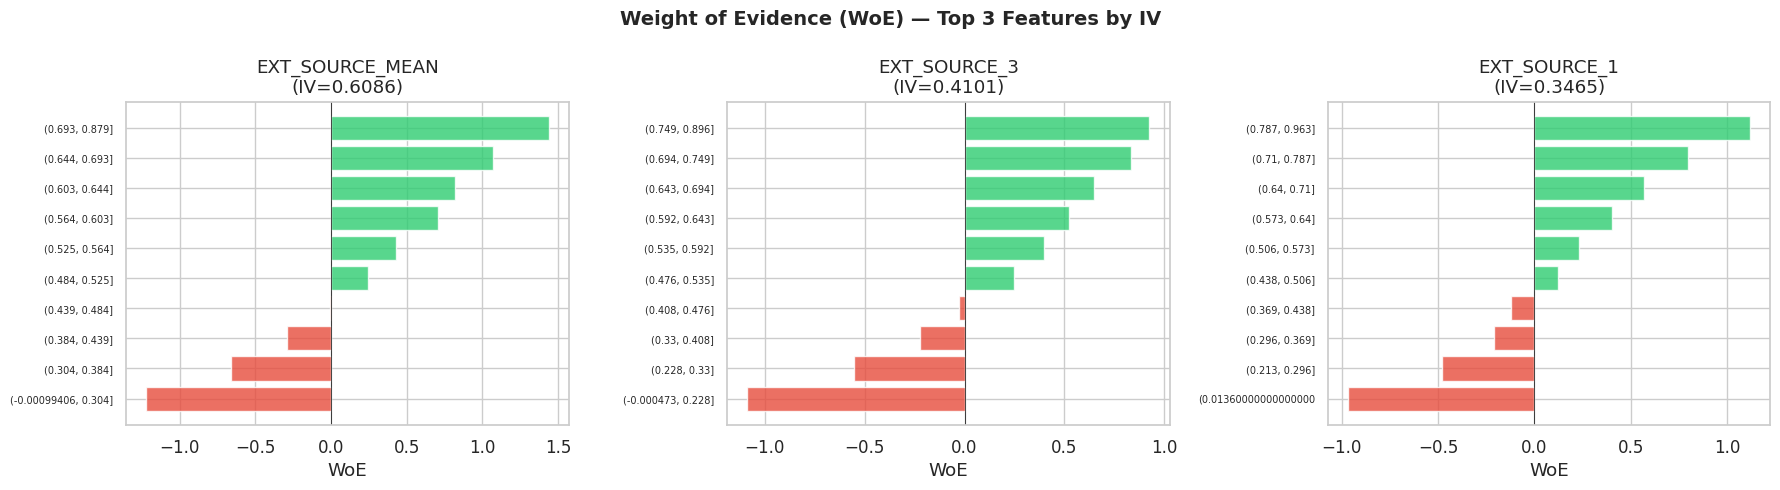

In [22]:
# WoE plot for top 3 features by IV
top3_iv = iv_df.head(3)['Feature'].tolist()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Weight of Evidence (WoE) — Top 3 Features by IV', fontsize=14, fontweight='bold')

for idx, feat in enumerate(top3_iv):
    ax = axes[idx]
    _, woe_table = calculate_iv_woe(df, feat)
    woe_vals = woe_table['woe'].values
    bin_labels = [str(b)[:20] for b in woe_table.index]
    colors_woe = ['#2ecc71' if w > 0 else '#e74c3c' for w in woe_vals]
    ax.barh(range(len(woe_vals)), woe_vals, color=colors_woe, alpha=0.8)
    ax.set_yticks(range(len(woe_vals)))
    ax.set_yticklabels(bin_labels, fontsize=7)
    ax.set_xlabel('WoE')
    ax.set_title(f'{feat}\n(IV={iv_df[iv_df["Feature"]==feat]["IV"].values[0]:.4f})')
    ax.axvline(x=0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()

### 2.9 Correlation Analysis & Multicollinearity (VIF)

In [23]:
# Point-biserial correlation with TARGET (for continuous features)
from scipy.stats import pointbiserialr

corr_features = [
    'AGE_YEARS', 'EMPLOYED_YEARS', 'AMT_INCOME_TOTAL', 'AMT_CREDIT',
    'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'CREDIT_INCOME_RATIO',
    'ANNUITY_INCOME_RATIO', 'ANNUITY_CREDIT_RATIO', 'INCOME_PER_PERSON',
    'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'EXT_SOURCE_MEAN'
]

pb_results = []
for feat in corr_features:
    data = df[[feat, 'TARGET']].dropna()
    corr, pval = pointbiserialr(data['TARGET'], data[feat])
    pb_results.append({'Feature': feat, 'Correlation': corr, 'Abs_Corr': abs(corr), 'P_value': pval})

pb_df = pd.DataFrame(pb_results).sort_values('Abs_Corr', ascending=False)
print("=== Point-Biserial Correlation with TARGET ===\n")
display(pb_df.round(4))

=== Point-Biserial Correlation with TARGET ===



,Feature,Correlation,Abs_Corr,P_value
13,EXT_SOURCE_MEAN,-0.2221,0.2221,0.0000
12,EXT_SOURCE_3,-0.1789,0.1789,0.0000
11,EXT_SOURCE_2,-0.1605,0.1605,0.0000
10,EXT_SOURCE_1,-0.1553,0.1553,0.0000
0,AGE_YEARS,-0.0782,0.0782,0.0000
1,EMPLOYED_YEARS,-0.0750,0.0750,0.0000
5,AMT_GOODS_PRICE,-0.0396,0.0396,0.0000
3,AMT_CREDIT,-0.0304,0.0304,0.0000
7,ANNUITY_INCOME_RATIO,0.0143,0.0143,0.0000
4,AMT_ANNUITY,-0.0128,0.0128,0.0000


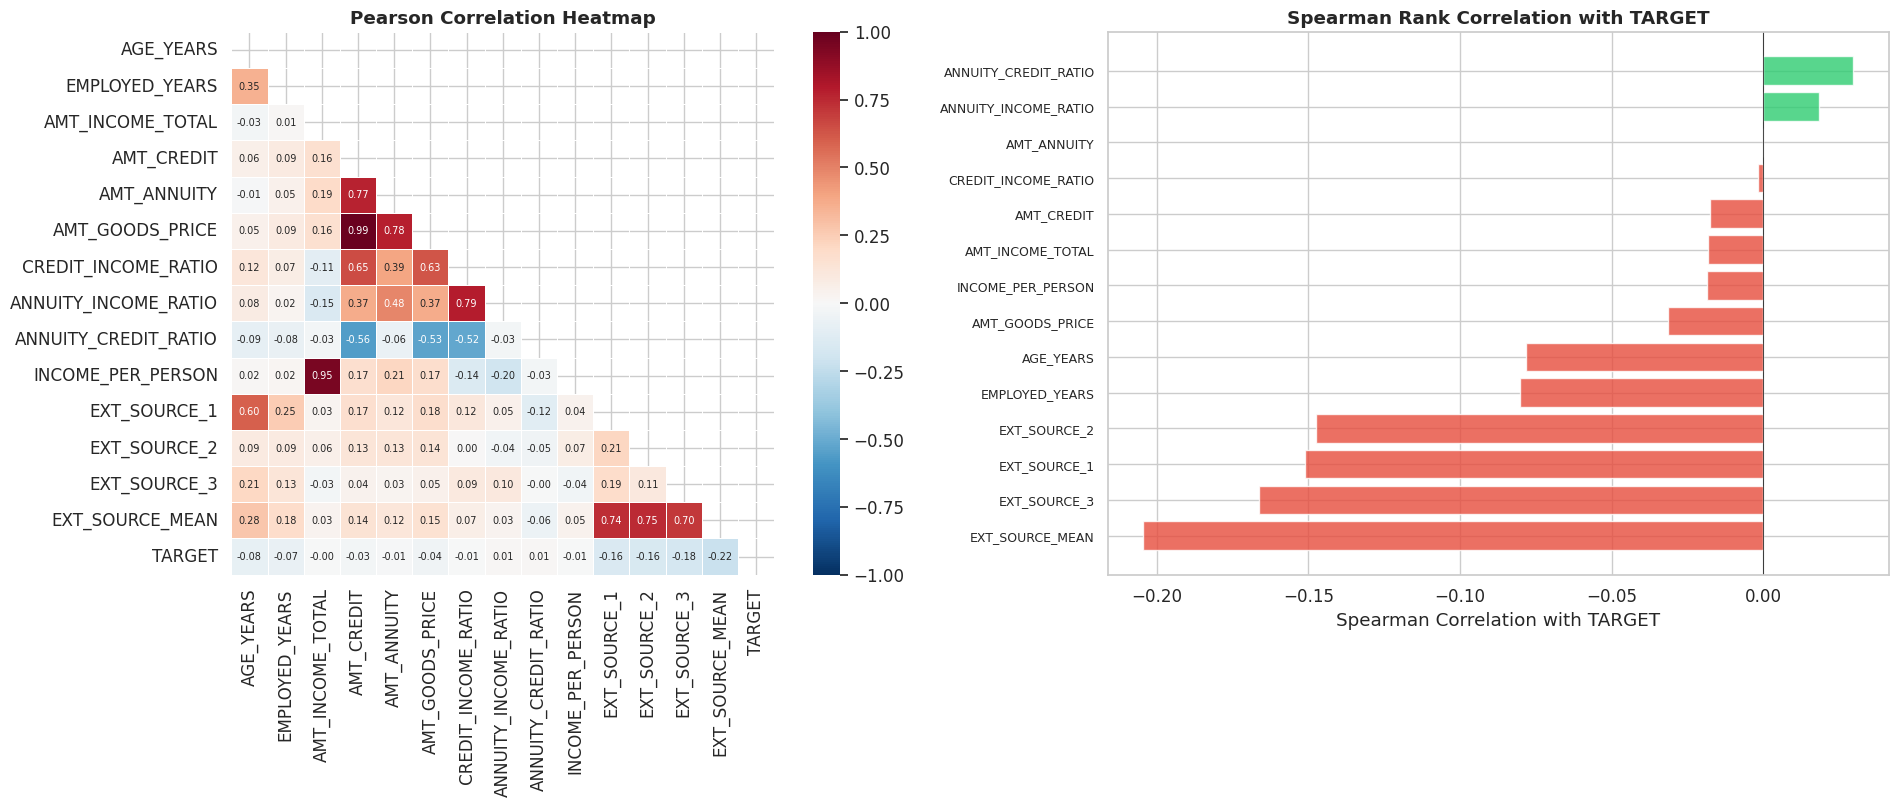

In [24]:
# Correlation heatmap for key features
corr_cols = corr_features + ['TARGET']
corr_cols_valid = [c for c in corr_cols if c in df.columns]
corr_matrix = df[corr_cols_valid].corr()

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Pearson correlation heatmap
ax = axes[0]
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, ax=ax, vmin=-1, vmax=1, square=True,
            annot_kws={'size': 7}, linewidths=0.5)
ax.set_title('Pearson Correlation Heatmap', fontweight='bold')

# Spearman correlation with TARGET only
ax = axes[1]
spearman_corr = df[corr_cols_valid].corr(method='spearman')['TARGET'].drop('TARGET').sort_values()
colors = ['#e74c3c' if v < 0 else '#2ecc71' for v in spearman_corr.values]
ax.barh(range(len(spearman_corr)), spearman_corr.values, color=colors, alpha=0.8)
ax.set_yticks(range(len(spearman_corr)))
ax.set_yticklabels(spearman_corr.index, fontsize=9)
ax.set_xlabel('Spearman Correlation with TARGET')
ax.set_title('Spearman Rank Correlation with TARGET', fontweight='bold')
ax.axvline(x=0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()

In [25]:
# VIF — Variance Inflation Factor (multicollinearity detection)
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_features = [c for c in corr_features if c in df.columns]
vif_data = df[vif_features].dropna()

# Subsample for speed
vif_sample = vif_data.sample(min(50000, len(vif_data)), random_state=42)

vif_results = []
for i, col in enumerate(vif_features):
    try:
        vif_val = variance_inflation_factor(vif_sample.values, i)
        vif_results.append({'Feature': col, 'VIF': vif_val})
    except:
        vif_results.append({'Feature': col, 'VIF': np.nan})

vif_df = pd.DataFrame(vif_results).sort_values('VIF', ascending=False)
vif_df['Multicollinearity'] = vif_df['VIF'].apply(
    lambda x: 'SEVERE (>10)' if x > 10 else ('MODERATE (5-10)' if x > 5 else 'LOW (<5)'))

print("=== Variance Inflation Factor (VIF) ===\n")
print("VIF > 10 → severe multicollinearity (consider removing)")
print("VIF 5-10 → moderate multicollinearity")
print("VIF < 5 → acceptable\n")
display(vif_df.round(2))

=== Variance Inflation Factor (VIF) ===

VIF > 10 → severe multicollinearity (consider removing)
VIF 5-10 → moderate multicollinearity
VIF < 5 → acceptable



,Feature,VIF,Multicollinearity
13,EXT_SOURCE_MEAN,562949953421312.0000,SEVERE (>10)
11,EXT_SOURCE_2,73229262233666.6094,SEVERE (>10)
10,EXT_SOURCE_1,65269559816963.7109,SEVERE (>10)
12,EXT_SOURCE_3,65269559816963.7109,SEVERE (>10)
3,AMT_CREDIT,168.3900,SEVERE (>10)
5,AMT_GOODS_PRICE,126.7600,SEVERE (>10)
7,ANNUITY_INCOME_RATIO,56.4300,SEVERE (>10)
6,CREDIT_INCOME_RATIO,46.6700,SEVERE (>10)
4,AMT_ANNUITY,46.0800,SEVERE (>10)
0,AGE_YEARS,24.2000,SEVERE (>10)


### 2.10 Feature Importance Preview (Quick LightGBM)

A quick LightGBM model trained on application-level features to preview which features
have the strongest discriminative power before full feature engineering.

FEATURE IMPORTANCE PREVIEW — Quick LightGBM on Application Features

Top 20 most predictive application-level features:


,Feature,Importance,Importance_Pct
109,ANNUITY_CREDIT_RATIO,371,12.9900
111,EXT_SOURCE_MEAN,183,6.4100
29,EXT_SOURCE_3,177,6.2000
27,EXT_SOURCE_1,157,5.5000
28,EXT_SOURCE_2,124,4.3400
105,AGE_YEARS,96,3.3600
4,AMT_GOODS_PRICE,95,3.3300
6,DAYS_BIRTH,93,3.2600
7,DAYS_EMPLOYED,91,3.1900
77,DAYS_LAST_PHONE_CHANGE,90,3.1500


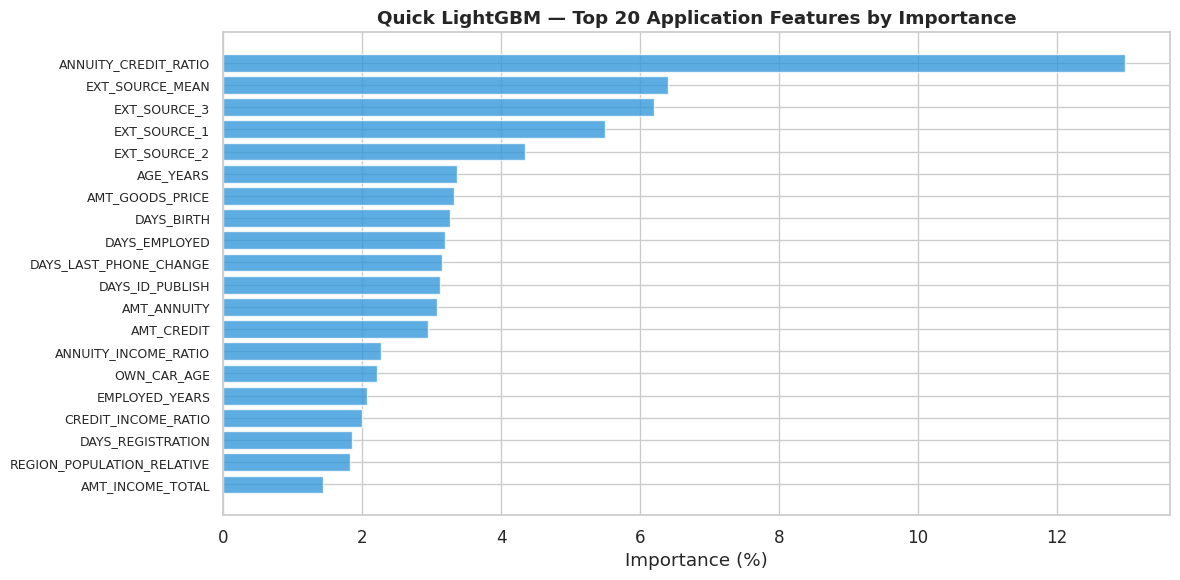


Insight: EXT_SOURCE variables dominate. Financial ratios and age/employment features follow.
Action: Feature engineering should focus on enriching EXT_SOURCE combinations and bureau/payment behavior.


86270

In [26]:
# Quick feature importance preview using LightGBM
print("=" * 60)
print("FEATURE IMPORTANCE PREVIEW — Quick LightGBM on Application Features")
print("=" * 60)

preview_features = [c for c in df.select_dtypes(include=[np.number]).columns
                    if c not in ['SK_ID_CURR', 'TARGET'] and c in df.columns]

df_preview = df[preview_features + ['TARGET']].dropna(subset=['TARGET']).copy()
for col in preview_features:
    df_preview[col] = df_preview[col].fillna(df_preview[col].median())

X_prev = df_preview[preview_features]
y_prev = df_preview['TARGET']

quick_lgbm = lgb.LGBMClassifier(
    n_estimators=100, max_depth=5, learning_rate=0.1,
    class_weight='balanced', random_state=42, verbose=-1, n_jobs=1
)
quick_lgbm.fit(X_prev, y_prev)

preview_imp = pd.DataFrame({
    'Feature': preview_features,
    'Importance': quick_lgbm.feature_importances_
}).sort_values('Importance', ascending=False)
preview_imp['Importance_Pct'] = preview_imp['Importance'] / preview_imp['Importance'].sum() * 100

print("\nTop 20 most predictive application-level features:")
display(preview_imp.head(20).round(2))

fig, ax = plt.subplots(figsize=(12, 6))
top20 = preview_imp.head(20)
ax.barh(range(len(top20)), top20['Importance_Pct'], color='#3498db', alpha=0.8)
ax.set_yticks(range(len(top20)))
ax.set_yticklabels(top20['Feature'], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Importance (%)')
ax.set_title('Quick LightGBM — Top 20 Application Features by Importance', fontweight='bold')
plt.tight_layout()
plt.show()

print("\nInsight: EXT_SOURCE variables dominate. Financial ratios and age/employment features follow.")
print("Action: Feature engineering should focus on enriching EXT_SOURCE combinations and bureau/payment behavior.")
del df_preview, X_prev, y_prev, quick_lgbm
gc.collect()

---
## Phase 3: Enhanced Feature Engineering & Data Preparation

Goal: Transform raw data into a feature-rich master table with stronger predictive features.

---

### 3.1 Application Table Engineering (Enhanced)

In [27]:
def engineer_application_features(app_df):
    df = app_df.copy()

    # Fix DAYS_EMPLOYED sentinel value
    df["DAYS_EMPLOYED_ANOMALY"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)
    df.loc[df["DAYS_EMPLOYED"] == 365243, "DAYS_EMPLOYED"] = np.nan

    # Time conversions
    df["AGE_YEARS"] = (-df["DAYS_BIRTH"]) / 365.25
    df["EMPLOYED_YEARS"] = (-df["DAYS_EMPLOYED"]) / 365.25

    # Financial ratios
    df["CREDIT_INCOME_RATIO"] = df["AMT_CREDIT"] / (df["AMT_INCOME_TOTAL"] + 1)
    df["ANNUITY_INCOME_RATIO"] = df["AMT_ANNUITY"] / (df["AMT_INCOME_TOTAL"] + 1)
    df["ANNUITY_CREDIT_RATIO"] = df["AMT_ANNUITY"] / (df["AMT_CREDIT"] + 1)
    df["GOODS_CREDIT_RATIO"] = df["AMT_GOODS_PRICE"] / (df["AMT_CREDIT"] + 1)
    df["FAMILY_SIZE_SAFE"] = df["CNT_FAM_MEMBERS"].fillna(1).clip(lower=1)
    df["INCOME_PER_PERSON"] = df["AMT_INCOME_TOTAL"] / df["FAMILY_SIZE_SAFE"]
    df["CREDIT_PER_PERSON"] = df["AMT_CREDIT"] / df["FAMILY_SIZE_SAFE"]
    df["ANNUITY_PER_PERSON"] = df["AMT_ANNUITY"] / df["FAMILY_SIZE_SAFE"]
    df["PAYMENT_RATE"] = df["AMT_ANNUITY"] / (df["AMT_CREDIT"] + 1)
    df["DAYS_EMPLOYED_RATIO"] = df["DAYS_EMPLOYED"] / (df["DAYS_BIRTH"] + 1)
    df["CAR_AGE_TO_AGE_RATIO"] = df["OWN_CAR_AGE"] / (df["AGE_YEARS"] + 1)
    df["CHILDREN_RATIO"] = df["CNT_CHILDREN"] / df["FAMILY_SIZE_SAFE"]

    # EXT_SOURCE combinations (CRITICAL for AUC)
    ext_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
    df["EXT_SOURCE_MEAN"] = df[ext_cols].mean(axis=1)
    df["EXT_SOURCE_MIN"] = df[ext_cols].min(axis=1)
    df["EXT_SOURCE_MAX"] = df[ext_cols].max(axis=1)
    df["EXT_SOURCE_STD"] = df[ext_cols].std(axis=1)
    df["EXT_SOURCE_RANGE"] = df["EXT_SOURCE_MAX"] - df["EXT_SOURCE_MIN"]
    df["EXT_SOURCE_PROD"] = df["EXT_SOURCE_1"].fillna(1) * df["EXT_SOURCE_2"].fillna(1) * df["EXT_SOURCE_3"].fillna(1)
    df["EXT_SOURCE_SUM"] = df[ext_cols].sum(axis=1)

    # EXT_SOURCE ratios
    df["EXT_SOURCE_1_TO_2"] = df["EXT_SOURCE_1"] / (df["EXT_SOURCE_2"] + 0.001)
    df["EXT_SOURCE_1_TO_3"] = df["EXT_SOURCE_1"] / (df["EXT_SOURCE_3"] + 0.001)
    df["EXT_SOURCE_2_TO_3"] = df["EXT_SOURCE_2"] / (df["EXT_SOURCE_3"] + 0.001)

    # EXT_SOURCE availability
    df["EXT_SOURCE_AVAIL_COUNT"] = df[ext_cols].notna().sum(axis=1).astype(np.int8)
    df["EXT_SOURCE_MISS_COUNT"] = df[ext_cols].isna().sum(axis=1).astype(np.int8)

    # Missing indicators (TASK 2A)
    missing_flag_cols = [
        "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
        "OWN_CAR_AGE", "AMT_ANNUITY", "AMT_GOODS_PRICE",
        "OCCUPATION_TYPE",
        "AMT_REQ_CREDIT_BUREAU_YEAR", "AMT_REQ_CREDIT_BUREAU_QRT",
        "AMT_REQ_CREDIT_BUREAU_MON", "AMT_REQ_CREDIT_BUREAU_WEEK",
        "AMT_REQ_CREDIT_BUREAU_DAY", "AMT_REQ_CREDIT_BUREAU_HOUR",
    ]
    for col in missing_flag_cols:
        if col in df.columns:
            df[f"IS_MISSING_{col}"] = df[col].isnull().astype(np.int8)

    return df

# Apply to both train and test
df = engineer_application_features(app_train)

anomaly_count = (app_train["DAYS_EMPLOYED"] == 365243).sum()
print(f"DAYS_EMPLOYED == 365243 count: {anomaly_count:,} ({anomaly_count/len(app_train)*100:.2f}%)")
print(f"Application features engineered. Shape: {df.shape}")


DAYS_EMPLOYED == 365243 count: 55,374 (18.01%)
Application features engineered. Shape: (307511, 162)


### 3.2 Bureau Aggregation (Enhanced)

In [28]:
# Enhanced Bureau aggregation
bureau_agg = bureau.groupby('SK_ID_CURR').agg({
    'AMT_CREDIT_SUM': ['mean', 'max', 'sum'],
    'AMT_CREDIT_SUM_DEBT': ['mean', 'max', 'sum'],
    'AMT_CREDIT_SUM_OVERDUE': ['mean', 'max', 'sum'],
    'AMT_CREDIT_SUM_LIMIT': ['mean', 'sum'],
    'DAYS_CREDIT': ['mean', 'max', 'min'],
    'DAYS_CREDIT_ENDDATE': ['mean', 'max', 'min'],
    'CNT_CREDIT_PROLONG': ['mean', 'sum'],
    'AMT_ANNUITY': ['mean', 'max'],
    'SK_ID_BUREAU': 'count'
}).reset_index()
bureau_agg.columns = ['SK_ID_CURR'] + [f'BUREAU_{a}_{b}'.upper() for a, b in bureau_agg.columns[1:]]

# Derived bureau features
bureau_agg['BUREAU_OVERDUE_RATIO'] = bureau_agg['BUREAU_AMT_CREDIT_SUM_OVERDUE_SUM'] / bureau_agg['BUREAU_AMT_CREDIT_SUM_SUM'].replace(0, np.nan)
bureau_agg['BUREAU_DEBT_CREDIT_RATIO'] = bureau_agg['BUREAU_AMT_CREDIT_SUM_DEBT_SUM'] / bureau_agg['BUREAU_AMT_CREDIT_SUM_SUM'].replace(0, np.nan)
bureau_agg.rename(columns={'BUREAU_SK_ID_BUREAU_COUNT': 'BUREAU_COUNT'}, inplace=True)

# Active/closed loan counts
if 'CREDIT_ACTIVE' in bureau.columns:
    active_counts = bureau.groupby('SK_ID_CURR')['CREDIT_ACTIVE'].apply(lambda x: (x == 'Active').sum()).reset_index()
    active_counts.columns = ['SK_ID_CURR', 'BUREAU_ACTIVE_COUNT']
    closed_counts = bureau.groupby('SK_ID_CURR')['CREDIT_ACTIVE'].apply(lambda x: (x == 'Closed').sum()).reset_index()
    closed_counts.columns = ['SK_ID_CURR', 'BUREAU_CLOSED_COUNT']
    bureau_agg = bureau_agg.merge(active_counts, on='SK_ID_CURR', how='left')
    bureau_agg = bureau_agg.merge(closed_counts, on='SK_ID_CURR', how='left')
    bureau_agg['BUREAU_ACTIVE_RATIO'] = bureau_agg['BUREAU_ACTIVE_COUNT'] / bureau_agg['BUREAU_COUNT'].replace(0, np.nan)

    # Credit status proportions
    status_dummies = pd.get_dummies(bureau['CREDIT_ACTIVE'], prefix='BUREAU_STATUS')
    status_with_id = pd.concat([bureau[['SK_ID_CURR']], status_dummies], axis=1)
    bureau_status = status_with_id.groupby('SK_ID_CURR').mean().reset_index()
    bureau_agg = bureau_agg.merge(bureau_status, on='SK_ID_CURR', how='left')

# Overdue counts
if 'AMT_CREDIT_SUM_OVERDUE' in bureau.columns:
    overdue_flag = (bureau['AMT_CREDIT_SUM_OVERDUE'] > 0).astype(int)
    overdue_ct = bureau.assign(_overdue=overdue_flag).groupby('SK_ID_CURR')['_overdue'].agg(['sum', 'mean']).reset_index()
    overdue_ct.columns = ['SK_ID_CURR', 'BUREAU_OVERDUE_COUNT', 'BUREAU_OVERDUE_LOAN_RATIO']
    bureau_agg = bureau_agg.merge(overdue_ct, on='SK_ID_CURR', how='left')

# Credit type counts
if 'CREDIT_TYPE' in bureau.columns:
    top_types = bureau['CREDIT_TYPE'].value_counts().head(5).index.tolist()
    for ct in top_types:
        safe_name = re.sub(r'[^A-Za-z0-9]', '_', ct).upper()
        counts = bureau[bureau['CREDIT_TYPE'] == ct].groupby('SK_ID_CURR').size().reset_index(name=f'BUREAU_CT_{safe_name}')
        bureau_agg = bureau_agg.merge(counts, on='SK_ID_CURR', how='left')

print(f"Bureau aggregation: {bureau_agg.shape}")
# Ratio NaNs mean no denominator/history; fill them after ratio calculation.
ratio_cols = [c for c in bureau_agg.columns if c.endswith('_RATIO')]
bureau_agg[ratio_cols] = bureau_agg[ratio_cols].replace([np.inf, -np.inf], np.nan).fillna(0)


Bureau aggregation: (305811, 39)


### 3.3 Previous Application Aggregation (Enhanced)

In [29]:
# Enhanced Previous Application aggregation
prev_agg = prev_app.groupby('SK_ID_CURR').agg({
    'AMT_APPLICATION': ['mean', 'sum', 'max'],
    'SK_ID_PREV': 'count',
    'AMT_CREDIT': ['mean', 'sum', 'max'],
    'AMT_ANNUITY': ['mean', 'max'],
    'DAYS_DECISION': ['mean', 'min', 'max'],
}).reset_index()
prev_agg.columns = ['SK_ID_CURR', 'PREV_AMT_APPLICATION_MEAN', 'PREV_AMT_APPLICATION_SUM', 'PREV_AMT_APPLICATION_MAX',
    'PREV_APPLICATION_COUNT', 'PREV_AMT_CREDIT_MEAN', 'PREV_AMT_CREDIT_SUM', 'PREV_AMT_CREDIT_MAX',
    'PREV_AMT_ANNUITY_MEAN', 'PREV_AMT_ANNUITY_MAX',
    'PREV_DAYS_DECISION_MEAN', 'PREV_DAYS_DECISION_MIN', 'PREV_DAYS_DECISION_MAX']

# Contract status proportions
if 'NAME_CONTRACT_STATUS' in prev_app.columns:
    status_dummies = pd.get_dummies(prev_app['NAME_CONTRACT_STATUS'], prefix='PREV_STATUS')
    status_with_id = pd.concat([prev_app[['SK_ID_CURR']], status_dummies], axis=1)
    prev_status = status_with_id.groupby('SK_ID_CURR').mean().reset_index()
    prev_agg = prev_agg.merge(prev_status, on='SK_ID_CURR', how='left')

    # Approved/refused counts
    for status_name in ['Approved', 'Refused', 'Canceled', 'Unused offer']:
        col_name = f'PREV_STATUS_{status_name}'
        if col_name in prev_agg.columns:
            prev_agg[f'PREV_{status_name.upper().replace(" ", "_")}_COUNT'] = prev_agg[col_name] * prev_agg['PREV_APPLICATION_COUNT']

if 'PREV_STATUS_Approved' in prev_agg.columns:
    prev_agg['PREV_APPROVAL_RATE'] = prev_agg['PREV_STATUS_Approved']

# Contract type ratios
if 'NAME_CONTRACT_TYPE' in prev_app.columns:
    ct_dummies = pd.get_dummies(prev_app['NAME_CONTRACT_TYPE'], prefix='PREV_CT')
    ct_with_id = pd.concat([prev_app[['SK_ID_CURR']], ct_dummies], axis=1)
    ct_agg = ct_with_id.groupby('SK_ID_CURR').mean().reset_index()
    prev_agg = prev_agg.merge(ct_agg, on='SK_ID_CURR', how='left')

prev_agg['PREV_CREDIT_APP_RATIO'] = prev_agg['PREV_AMT_CREDIT_SUM'] / (prev_agg['PREV_AMT_APPLICATION_SUM'] + 1)

print(f"Previous app aggregation: {prev_agg.shape}")

Previous app aggregation: (338857, 27)


### 3.4 Installments Payments Aggregation (Enhanced)

In [30]:
# Enhanced Installments aggregation
if inst_pay is not None:
    inst_pay['DAYS_LATE'] = inst_pay['DAYS_ENTRY_PAYMENT'] - inst_pay['DAYS_INSTALMENT']
    inst_pay['PAYMENT_DIFF'] = inst_pay['AMT_INSTALMENT'] - inst_pay['AMT_PAYMENT']
    inst_pay['IS_LATE'] = (inst_pay['DAYS_LATE'] > 0).astype(int)
    inst_pay['IS_SHORT'] = (inst_pay['PAYMENT_DIFF'] > 0).astype(int)
    inst_pay['PAYMENT_RATIO'] = inst_pay['AMT_PAYMENT'] / (inst_pay['AMT_INSTALMENT'] + 1)
    inst_pay['IS_UNDERPAY'] = (inst_pay['PAYMENT_RATIO'] < 0.95).astype(int)

    inst_agg = inst_pay.groupby('SK_ID_CURR').agg({
        'SK_ID_PREV': 'count',
        'DAYS_LATE': ['mean', 'max', 'std'],
        'PAYMENT_DIFF': ['mean', 'max'],
        'IS_LATE': ['mean', 'sum'],
        'IS_SHORT': 'mean',
        'PAYMENT_RATIO': ['mean', 'min'],
        'IS_UNDERPAY': ['mean', 'sum'],
    }).reset_index()
    inst_agg.columns = ['SK_ID_CURR', 'INST_COUNT', 'INST_DAYS_LATE_MEAN', 'INST_DAYS_LATE_MAX',
        'INST_DAYS_LATE_STD', 'INST_PAYMENT_DIFF_MEAN', 'INST_PAYMENT_DIFF_MAX',
        'INST_LATE_RATIO', 'INST_LATE_COUNT', 'INST_SHORTFALL_RATIO',
        'INST_PAYMENT_RATIO_MEAN', 'INST_PAYMENT_RATIO_MIN',
        'INST_UNDERPAY_RATIO', 'INST_UNDERPAY_COUNT']

    # Recent installment behavior (last 12 months ~ last 360 days)
    recent_inst = inst_pay[inst_pay['DAYS_INSTALMENT'] >= -360]
    if len(recent_inst) > 0:
        recent_agg = recent_inst.groupby('SK_ID_CURR').agg({
            'IS_LATE': 'mean',
            'DAYS_LATE': 'mean',
            'PAYMENT_RATIO': 'mean',
        }).reset_index()
        recent_agg.columns = ['SK_ID_CURR', 'INST_RECENT_LATE_RATIO', 'INST_RECENT_LATE_MEAN', 'INST_RECENT_PAY_RATIO']
        inst_agg = inst_agg.merge(recent_agg, on='SK_ID_CURR', how='left')

    print(f"Installments aggregation: {inst_agg.shape}")
else:
    inst_agg = pd.DataFrame(columns=['SK_ID_CURR'])
    print("installments_payments.csv not available — skipping")

Installments aggregation: (339587, 17)


### 3.5 POS/Cash Balance Aggregation (Enhanced)

In [31]:
# Enhanced POS/Cash aggregation
pos_dpd_cols = [col for col in pos_cash.columns if 'SK_DPD' in col]
pos_agg_dict = {}
for col in pos_dpd_cols:
    pos_agg_dict[col] = ['mean', 'max', 'sum']
pos_agg_dict['MONTHS_BALANCE'] = ['min', 'max', 'count']

pos_dpd_agg = pos_cash.groupby('SK_ID_CURR').agg(pos_agg_dict).reset_index()
pos_dpd_agg.columns = ['_'.join(col).strip('_') for col in pos_dpd_agg.columns.values]
pos_dpd_agg.rename(columns=lambda x: 'POS_' + x if x != 'SK_ID_CURR' else x, inplace=True)

# Contract status
if 'NAME_CONTRACT_STATUS' in pos_cash.columns:
    pos_status = pd.get_dummies(pos_cash['NAME_CONTRACT_STATUS'], prefix='POS_STATUS')
    pos_status_agg = pd.concat([pos_cash[['SK_ID_CURR']], pos_status], axis=1).groupby('SK_ID_CURR').mean().reset_index()
    pos_dpd_agg = pos_dpd_agg.merge(pos_status_agg, on='SK_ID_CURR', how='left')

print(f"POS/Cash aggregation: {pos_dpd_agg.shape}")

POS/Cash aggregation: (337252, 19)


### 3.6 Credit Card Balance Aggregation (Enhanced)

In [32]:
# Enhanced Credit Card aggregation
cc_bal['CC_UTILIZATION'] = cc_bal['AMT_BALANCE'] / (cc_bal['AMT_CREDIT_LIMIT_ACTUAL'] + 1)
cc_bal['CC_PAYMENT_RATIO'] = cc_bal['AMT_PAYMENT_CURRENT'] / (cc_bal['AMT_INST_MIN_REGULARITY'] + 1)

cc_dpd_cols = [col for col in cc_bal.columns if 'SK_DPD' in col]
cc_agg_dict = {}
for col in cc_dpd_cols:
    cc_agg_dict[col] = ['mean', 'max', 'sum']
cc_agg_dict['CC_UTILIZATION'] = ['mean', 'max']
cc_agg_dict['AMT_BALANCE'] = ['mean', 'sum', 'max']
cc_agg_dict['AMT_CREDIT_LIMIT_ACTUAL'] = ['mean', 'max']
cc_agg_dict['CNT_INSTALMENT_MATURE_CUM'] = 'sum'

if 'AMT_DRAWINGS_ATM_CURRENT' in cc_bal.columns:
    cc_agg_dict['AMT_DRAWINGS_ATM_CURRENT'] = ['mean', 'sum']
if 'CC_PAYMENT_RATIO' in cc_bal.columns:
    cc_agg_dict['CC_PAYMENT_RATIO'] = ['mean', 'min']

cc_agg = cc_bal.groupby('SK_ID_CURR').agg(cc_agg_dict).reset_index()
cc_agg.columns = ['_'.join(col).strip('_') for col in cc_agg.columns.values]
cc_agg.rename(columns=lambda x: 'CC_' + x if x != 'SK_ID_CURR' else x, inplace=True)

# CC record count
cc_count = cc_bal.groupby('SK_ID_CURR').size().reset_index(name='CC_RECORD_COUNT')
cc_agg = cc_agg.merge(cc_count, on='SK_ID_CURR', how='left')

print(f"Credit card aggregation: {cc_agg.shape}")

Credit card aggregation: (103558, 20)


### 3.7 Bureau Balance Aggregation (Enhanced)

In [33]:
# Enhanced Bureau Balance aggregation
status_mapping = {'C': 0, '0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5, 'X': 0}
bureau_bal['STATUS_NUM'] = bureau_bal['STATUS'].map(status_mapping).fillna(0)
bureau_bal['IS_DPD'] = (bureau_bal['STATUS'].isin(['1','2','3','4','5'])).astype(int)

bureau_id_map = bureau[['SK_ID_BUREAU', 'SK_ID_CURR']].drop_duplicates()
bureau_bal_mapped = bureau_bal.merge(bureau_id_map, on='SK_ID_BUREAU', how='left')

bb_agg = bureau_bal_mapped.groupby('SK_ID_CURR').agg({
    'STATUS_NUM': ['mean', 'max', 'std'],
    'IS_DPD': ['mean', 'sum'],
    'MONTHS_BALANCE': ['min', 'max', 'count']
}).reset_index()
bb_agg.columns = ['SK_ID_CURR', 'BB_STATUS_MEAN', 'BB_STATUS_MAX', 'BB_STATUS_STD',
    'BB_DPD_RATIO', 'BB_DPD_COUNT', 'BB_MONTHS_MIN', 'BB_MONTHS_MAX', 'BB_RECORD_COUNT']

# Status category counts
for status_val in ['0', '1', '2', '3', '4', '5', 'C', 'X']:
    flag_col = f'BB_STATUS_{status_val}_RATIO'
    status_flag = (bureau_bal_mapped['STATUS'] == status_val).astype(int)
    status_ratio = bureau_bal_mapped.assign(_flag=status_flag).groupby('SK_ID_CURR')['_flag'].mean().reset_index()
    status_ratio.columns = ['SK_ID_CURR', flag_col]
    bb_agg = bb_agg.merge(status_ratio, on='SK_ID_CURR', how='left')

print(f"Bureau balance aggregation: {bb_agg.shape}")

Bureau balance aggregation: (134542, 17)


### 3.7b Trend Features (7th Place Kaggle Technique)

Linear regression slope on bureau_balance STATUS_NUM over time — captures whether client delinquency is getting **worse** or **better**.  
Technique from [7th place solution by js-aguiar](https://www.kaggle.com/jsaguiar/lightgbm-7th-place-solution).

In [34]:
# Trend Features — vectorized OLS slope (7th place technique)
# Captures whether delinquency is worsening or improving over time

def add_trend_feature(df, group_col, value_col, prefix):
    """Compute linear regression slope per group — vectorized closed-form OLS."""
    g = df[[group_col, value_col]].dropna(subset=[value_col]).copy()
    g['_rank'] = g.groupby(group_col).cumcount()
    g['_count'] = g.groupby(group_col)[value_col].transform('count')
    g = g[g['_count'] >= 2]
    if len(g) == 0:
        return pd.Series(dtype=np.float32, name=f'{prefix}_TREND_{value_col}')
    g['_mean_x'] = g.groupby(group_col)['_rank'].transform('mean')
    g['_mean_y'] = g.groupby(group_col)[value_col].transform('mean')
    g['_dx'] = g['_rank'] - g['_mean_x']
    g['_dy'] = g[value_col] - g['_mean_y']
    g['_dx_dy'] = g['_dx'] * g['_dy']
    g['_dx2'] = g['_dx'] ** 2
    numerator = g.groupby(group_col)['_dx_dy'].sum()
    denominator = g.groupby(group_col)['_dx2'].sum()
    slopes = (numerator / denominator.replace(0, np.nan)).fillna(0)
    slopes.name = f'{prefix}_TREND_{value_col}'
    return slopes.astype(np.float32)

print("Computing trend features on bureau_balance...")
trend_slopes = add_trend_feature(bureau_bal, 'SK_ID_BUREAU', 'STATUS_NUM', 'BB')
trend_df = trend_slopes.reset_index()
trend_df.columns = ['SK_ID_BUREAU', 'BB_TREND_STATUS_NUM']
trend_df = trend_df.merge(bureau_id_map, on='SK_ID_BUREAU', how='left')
trend_agg = trend_df.groupby('SK_ID_CURR')['BB_TREND_STATUS_NUM'].agg(['mean', 'max', 'min']).reset_index()
trend_agg.columns = ['SK_ID_CURR', 'BB_TREND_MEAN', 'BB_TREND_MAX', 'BB_TREND_MIN']

# Merge trend features into bureau_balance aggregation
bb_agg = bb_agg.merge(trend_agg, on='SK_ID_CURR', how='left')
print(f"  Trend features added: BB_TREND_MEAN, BB_TREND_MAX, BB_TREND_MIN")
print(f"  bb_agg shape: {bb_agg.shape}")
del trend_slopes, trend_df, trend_agg; gc.collect()


Computing trend features on bureau_balance...
  Trend features added: BB_TREND_MEAN, BB_TREND_MAX, BB_TREND_MIN
  bb_agg shape: (134542, 20)


27662

### 3.7c Advanced Statistical Aggregations (7th Place)

Skewness, median, IQR for key numeric columns across all supplementary tables.  
These capture distributional shape beyond simple mean/std.

In [35]:
# Advanced statistical aggregations (7th place technique)
# Adds skew, median, IQR for key columns

def add_advanced_stats(df, group_col, value_col, prefix):
    """Compute skew, median, IQR per group."""
    agg = df.groupby(group_col)[value_col].agg(['median', 'skew']).reset_index()
    q75 = df.groupby(group_col)[value_col].quantile(0.75).reset_index()
    q25 = df.groupby(group_col)[value_col].quantile(0.25).reset_index()
    q75.columns = [group_col, f'{prefix}_{value_col}_Q75']
    q25.columns = [group_col, f'{prefix}_{value_col}_Q25']
    agg.columns = [group_col, f'{prefix}_{value_col}_MEDIAN', f'{prefix}_{value_col}_SKEW']
    agg = agg.merge(q75, on=group_col, how='left').merge(q25, on=group_col, how='left')
    agg[f'{prefix}_{value_col}_IQR'] = agg[f'{prefix}_{value_col}_Q75'] - agg[f'{prefix}_{value_col}_Q25']
    agg.drop([f'{prefix}_{value_col}_Q75', f'{prefix}_{value_col}_Q25'], axis=1, inplace=True)
    return agg

print("Computing advanced stats...")

# Bureau: credit sum debt
if 'AMT_CREDIT_SUM_DEBT' in bureau.columns:
    adv_bur = add_advanced_stats(bureau, 'SK_ID_CURR', 'AMT_CREDIT_SUM_DEBT', 'BUR')
    bureau_agg = bureau_agg.merge(adv_bur, on='SK_ID_CURR', how='left')
    del adv_bur
    print("  + Bureau AMT_CREDIT_SUM_DEBT: median, skew, IQR")

# Installments: DAYS_LATE
if inst_pay is not None and 'DAYS_LATE' in inst_pay.columns:
    adv_inst = add_advanced_stats(inst_pay, 'SK_ID_CURR', 'DAYS_LATE', 'INST')
    inst_agg = inst_agg.merge(adv_inst, on='SK_ID_CURR', how='left')
    del adv_inst
    print("  + Installments DAYS_LATE: median, skew, IQR")

# Credit card: utilization
if 'AMT_BALANCE' in cc_bal.columns and 'AMT_CREDIT_LIMIT_ACTUAL' in cc_bal.columns:
    cc_temp = cc_bal.copy()
    cc_temp['CC_UTIL'] = np.where(cc_temp['AMT_CREDIT_LIMIT_ACTUAL'] > 0,
                                   cc_temp['AMT_BALANCE'] / cc_temp['AMT_CREDIT_LIMIT_ACTUAL'], np.nan)
    adv_cc = add_advanced_stats(cc_temp, 'SK_ID_CURR', 'CC_UTIL', 'CC')
    cc_agg = cc_agg.merge(adv_cc, on='SK_ID_CURR', how='left')
    del adv_cc, cc_temp
    print("  + Credit Card utilization: median, skew, IQR")

gc.collect()
print("Advanced stats done.")


Computing advanced stats...
  + Bureau AMT_CREDIT_SUM_DEBT: median, skew, IQR
  + Installments DAYS_LATE: median, skew, IQR
  + Credit Card utilization: median, skew, IQR
Advanced stats done.


### 3.8 Master Table Merge

In [36]:
# Merge all aggregations into master table
df_full = df.copy()

agg_tables = [
    (bureau_agg, 'bureau'),
    (prev_agg, 'previous_app'),
    (inst_agg, 'installments'),
    (pos_dpd_agg, 'pos_cash'),
    (cc_agg, 'credit_card'),
    (bb_agg, 'bureau_balance')
]

for agg_df, name in agg_tables:
    before = df_full.shape[1]
    df_full = df_full.merge(agg_df, on='SK_ID_CURR', how='left')
    print(f"Merged {name:<20s}: {before} → {df_full.shape[1]} columns (+{df_full.shape[1]-before})")

print(f"\nMaster table shape: {df_full.shape}")

# Build the same master table for application_test
df_test = engineer_application_features(app_test)
df_test_full = df_test.copy()

for agg_df, name in agg_tables:
    before = df_test_full.shape[1]
    df_test_full = df_test_full.merge(agg_df, on='SK_ID_CURR', how='left')

print(f"\napplication_test master table shape: {df_test_full.shape}")

Merged bureau              : 162 → 203 columns (+41)
Merged previous_app        : 203 → 229 columns (+26)
Merged installments        : 229 → 248 columns (+19)
Merged pos_cash            : 248 → 266 columns (+18)
Merged credit_card         : 266 → 288 columns (+22)
Merged bureau_balance      : 288 → 307 columns (+19)

Master table shape: (307511, 307)

application_test master table shape: (48744, 306)


### 3.8b Metric-Boost Feature Engineering

In [37]:
def add_metric_boost_features(frame):
    df = frame.copy()

    def add_ratio(new_col, num_col, den_col, eps=1.0):
        if num_col in df.columns and den_col in df.columns:
            df[new_col] = df[num_col] / (df[den_col] + eps)

    # Row-level missingness count
    df["ROW_MISSING_COUNT"] = df.isnull().sum(axis=1).astype(np.int16)

    # Application-level ratios
    add_ratio("CREDIT_TERM", "AMT_CREDIT", "AMT_ANNUITY")
    add_ratio("GOODS_CREDIT_RATIO_2", "AMT_GOODS_PRICE", "AMT_CREDIT")
    add_ratio("CREDIT_GOODS_RATIO", "AMT_CREDIT", "AMT_GOODS_PRICE")
    add_ratio("INCOME_CREDIT_RATIO_2", "AMT_INCOME_TOTAL", "AMT_CREDIT")
    add_ratio("INCOME_ANNUITY_RATIO", "AMT_INCOME_TOTAL", "AMT_ANNUITY")
    add_ratio("EMPLOYED_AGE_RATIO", "EMPLOYED_YEARS", "AGE_YEARS")
    add_ratio("CHILDREN_INCOME_RATIO", "CNT_CHILDREN", "AMT_INCOME_TOTAL")
    add_ratio("FAM_INCOME_RATIO", "CNT_FAM_MEMBERS", "AMT_INCOME_TOTAL")

    # Bureau stress ratios
    add_ratio("BUREAU_DEBT_CREDIT_RATIO_2", "BUREAU_AMT_CREDIT_SUM_DEBT_SUM", "BUREAU_AMT_CREDIT_SUM_SUM")
    add_ratio("BUREAU_OVERDUE_DEBT_RATIO", "BUREAU_OVERDUE_SUM" if "BUREAU_OVERDUE_SUM" in df.columns else "BUREAU_AMT_CREDIT_SUM_OVERDUE_SUM", "BUREAU_AMT_CREDIT_SUM_DEBT_SUM")
    add_ratio("BUREAU_CREDIT_PER_LOAN", "BUREAU_AMT_CREDIT_SUM_SUM", "BUREAU_COUNT")
    add_ratio("BUREAU_DEBT_PER_LOAN", "BUREAU_AMT_CREDIT_SUM_DEBT_SUM", "BUREAU_COUNT")

    # Previous application
    add_ratio("PREV_CREDIT_APPLICATION_RATIO", "PREV_AMT_CREDIT_SUM", "PREV_AMT_APPLICATION_SUM")
    add_ratio("PREV_CREDIT_PER_APP", "PREV_AMT_CREDIT_SUM", "PREV_APPLICATION_COUNT")
    add_ratio("PREV_APP_PER_CURR_CREDIT", "PREV_AMT_APPLICATION_SUM", "AMT_CREDIT")

    # Installment stress
    add_ratio("INST_DPD_PER_RECORD", "INST_DAYS_LATE_MAX", "INST_COUNT")
    if "INST_LATE_RATIO" in df.columns and "INST_DAYS_LATE_MEAN" in df.columns:
        df["INST_LATE_SEVERITY"] = df["INST_LATE_RATIO"] * df["INST_DAYS_LATE_MEAN"]
    if "INST_SHORTFALL_RATIO" in df.columns and "INST_PAYMENT_DIFF_MEAN" in df.columns:
        df["INST_SHORT_SEVERITY"] = df["INST_SHORTFALL_RATIO"] * df["INST_PAYMENT_DIFF_MEAN"]

    # Credit card / bureau balance stability
    add_ratio("CC_BALANCE_PER_INSTALLMENT", "CC_AMT_BALANCE_sum", "CC_CNT_INSTALMENT_MATURE_CUM_sum")
    add_ratio("BB_DPD_RECORD_RATIO", "BB_DPD_COUNT", "BB_RECORD_COUNT")

    # Cross-source interactions (key for AUC improvement)
    if "EXT_SOURCE_MEAN" in df.columns and "INST_LATE_RATIO" in df.columns:
        df["RISK_EXT_X_LATE"] = (1 - df["EXT_SOURCE_MEAN"].fillna(0.5)) * df["INST_LATE_RATIO"].fillna(0)
    if "EXT_SOURCE_MEAN" in df.columns and "BUREAU_DEBT_CREDIT_RATIO" in df.columns:
        df["RISK_EXT_X_BUREAU"] = (1 - df["EXT_SOURCE_MEAN"].fillna(0.5)) * df["BUREAU_DEBT_CREDIT_RATIO"].fillna(0)
    if "EXT_SOURCE_MEAN" in df.columns and "ANNUITY_INCOME_RATIO" in df.columns:
        df["RISK_EXT_X_ANNUITY"] = (1 - df["EXT_SOURCE_MEAN"].fillna(0.5)) * df["ANNUITY_INCOME_RATIO"].fillna(0)
    if "EXT_SOURCE_MEAN" in df.columns and "BB_DPD_RATIO" in df.columns:
        df["RISK_EXT_X_BB_DPD"] = (1 - df["EXT_SOURCE_MEAN"].fillna(0.5)) * df["BB_DPD_RATIO"].fillna(0)
    if "EXT_SOURCE_MEAN" in df.columns and "AGE_YEARS" in df.columns:
        df["RISK_EXT_X_AGE"] = (1 - df["EXT_SOURCE_MEAN"].fillna(0.5)) * (1 / (df["AGE_YEARS"].fillna(40) + 1))

    # Missing indicators for aggregate columns
    for prefix in ['BUREAU_', 'PREV_', 'INST_', 'CC_', 'BB_', 'POS_']:
        first_col = [c for c in df.columns if c.startswith(prefix)]
        if first_col:
            df[f'HAS_{prefix.strip("_")}'] = df[first_col[0]].notna().astype(np.int8)

    # Clean infinities
    num_cols = df.select_dtypes(include=[np.number]).columns
    df[num_cols] = df[num_cols].replace([np.inf, -np.inf], np.nan)

    return df

df_full = add_metric_boost_features(df_full)
df_test_full = add_metric_boost_features(df_test_full)

print(f"Metric-boost features added. TRAIN shape: {df_full.shape}, TEST shape: {df_test_full.shape}")

Metric-boost features added. TRAIN shape: (307511, 339), TEST shape: (48744, 338)


### 3.8d KNN Features on EXT_SOURCE (1st Place Kaggle Technique)

K-nearest neighbors on EXT_SOURCE_1/2/3 — computes the **mean default rate of the K closest clients** in the external-score space.  
This was the **single most important feature** in the [1st place solution](https://www.kaggle.com/c/home-credit-default-risk/discussion/64821).

Memory-optimized: uses K=100 only (K=500 removed for Colab compatibility).

In [38]:
# KNN Features on EXT_SOURCE (1st place technique)
# Computes neighbor target mean/std for K nearest neighbors in EXT_SOURCE space

from sklearn.neighbors import NearestNeighbors

print("Computing KNN features on EXT_SOURCE...")

ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']

# Use df_full (train) and df_test_full (test) which already have EXT_SOURCE
ext_train = df_full[ext_cols].copy()
ext_test = df_test_full[ext_cols].copy()

for c in ext_cols:
    med = ext_train[c].median()
    ext_train[c] = ext_train[c].fillna(med)
    ext_test[c] = ext_test[c].fillna(med)

ext_train_arr = ext_train.values.astype(np.float32)
ext_test_arr = ext_test.values.astype(np.float32)
y_knn = df_full['TARGET'].values

K = 100
print(f"  Fitting KNN with K={K}...")
nn = NearestNeighbors(n_neighbors=K + 1, algorithm='ball_tree', n_jobs=1)
nn.fit(ext_train_arr)

# Train: skip self (index 0)
dists_tr, idx_tr = nn.kneighbors(ext_train_arr)
neighbor_targets_tr = y_knn[idx_tr[:, 1:]]  # exclude self
df_full[f'KNN_{K}_TARGET_MEAN'] = neighbor_targets_tr.mean(axis=1).astype(np.float32)
df_full[f'KNN_{K}_TARGET_STD'] = neighbor_targets_tr.std(axis=1).astype(np.float32)
df_full[f'KNN_{K}_DIST_MEAN'] = dists_tr[:, 1:].mean(axis=1).astype(np.float32)
del dists_tr, idx_tr, neighbor_targets_tr; gc.collect()

# Test: all K neighbors are from train
dists_te, idx_te = nn.kneighbors(ext_test_arr)
neighbor_targets_te = y_knn[idx_te[:, :K]]
df_test_full[f'KNN_{K}_TARGET_MEAN'] = neighbor_targets_te.mean(axis=1).astype(np.float32)
df_test_full[f'KNN_{K}_TARGET_STD'] = neighbor_targets_te.std(axis=1).astype(np.float32)
df_test_full[f'KNN_{K}_DIST_MEAN'] = dists_te[:, :K].mean(axis=1).astype(np.float32)
del dists_te, idx_te, neighbor_targets_te, nn; gc.collect()

del ext_train, ext_test, ext_train_arr, ext_test_arr
gc.collect()

print(f"  KNN features added: KNN_{K}_TARGET_MEAN, KNN_{K}_TARGET_STD, KNN_{K}_DIST_MEAN")
print(f"  df_full shape: {df_full.shape}")
print(f"  df_test_full shape: {df_test_full.shape}")


Computing KNN features on EXT_SOURCE...
  Fitting KNN with K=100...
  KNN features added: KNN_100_TARGET_MEAN, KNN_100_TARGET_STD, KNN_100_DIST_MEAN
  df_full shape: (307511, 342)
  df_test_full shape: (48744, 341)


### 3.8c New Feature Engineering Summary

In [39]:
# Feature engineering summary
app_only_cols = [c for c in df.columns if c not in app_train.columns]
total_new = df_full.shape[1] - app_train.shape[1]

print("=" * 60)
print("NEW FEATURE ENGINEERING SUMMARY")
print("=" * 60)
print(f"Original application_train columns: {app_train.shape[1]}")
print(f"Final master table columns: {df_full.shape[1]}")
print(f"Total new features created: {total_new}")
print(f"\nFeature groups:")
for prefix, label in [('EXT_SOURCE_', 'EXT_SOURCE combinations'), ('IS_MISSING_', 'Missing indicators'),
                       ('BUREAU_', 'Bureau aggregates'), ('PREV_', 'Previous app aggregates'),
                       ('INST_', 'Installment aggregates'), ('POS_', 'POS cash aggregates'),
                       ('CC_', 'Credit card aggregates'), ('BB_', 'Bureau balance aggregates'),
                       ('RISK_', 'Cross-source risk interactions'), ('HAS_', 'Source availability flags')]:
    count = sum(1 for c in df_full.columns if c.startswith(prefix))
    if count > 0:
        print(f"  {label}: {count}")

NEW FEATURE ENGINEERING SUMMARY
Original application_train columns: 122
Final master table columns: 342
Total new features created: 220

Feature groups:
  EXT_SOURCE combinations: 15
  Missing indicators: 13
  Bureau aggregates: 42
  Previous app aggregates: 29
  Installment aggregates: 22
  POS cash aggregates: 18
  Credit card aggregates: 23
  Bureau balance aggregates: 20
  Cross-source risk interactions: 5
  Source availability flags: 6


### 3.9 Imputation & Encoding

In [40]:
# Model-ready preprocessing helpers
# - evaluation preprocessing will be fitted ONLY on the outer-train split (Cell 66)
# - production preprocessing below is fitted on all labelled data and used ONLY after final model selection

df_full_raw = df_full.copy()
df_test_full_raw = df_test_full.copy()

# FAST_CHECK: stratified sample of labelled rows and smaller blind sample for quick full-notebook validation
if globals().get('FAST_CHECK', False):
    if len(df_full_raw) > FAST_TRAIN_ROWS:
        sampled_idx, _ = train_test_split(
            df_full_raw.index,
            train_size=FAST_TRAIN_ROWS,
            stratify=df_full_raw['TARGET'],
            random_state=FAST_RANDOM_STATE
        )
        df_full_raw = df_full_raw.loc[sampled_idx].sort_index().reset_index(drop=True)
    if len(df_test_full_raw) > FAST_BLIND_ROWS:
        df_test_full_raw = df_test_full_raw.sample(FAST_BLIND_ROWS, random_state=FAST_RANDOM_STATE).sort_values('SK_ID_CURR').reset_index(drop=True)
    print(f'FAST_CHECK sampled labelled rows: {df_full_raw.shape}; blind rows: {df_test_full_raw.shape}')


agg_prefixes = ['BUREAU_', 'PREV_', 'INST_', 'POS_', 'CC_', 'BB_']

def fit_master_preprocessor(train_df):
    train_work = train_df.copy()

    agg_cols = [c for c in train_work.columns if any(c.startswith(p) for p in agg_prefixes)]

    ext_cols = [c for c in ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'EXT_SOURCE_MEAN'] if c in train_work.columns]
    ext_fill_values = {col: train_work[col].median() for col in ext_cols}

    num_cols = train_work.select_dtypes(include=[np.number]).columns.tolist()
    num_fill_values = train_work[num_cols].median(numeric_only=True).to_dict()

    cat_cols = train_work.select_dtypes(include='object').columns.tolist()
    category_mappings = {}
    for col in cat_cols:
        train_vals = train_work[col].fillna('Unknown').astype(str)
        seen_categories = sorted(train_vals.unique())
        category_mappings[col] = {cat: idx for idx, cat in enumerate(seen_categories)}

    return {
        'agg_cols': agg_cols,
        'ext_cols': ext_cols,
        'ext_fill_values': ext_fill_values,
        'num_cols': num_cols,
        'num_fill_values': num_fill_values,
        'cat_cols': cat_cols,
        'category_mappings': category_mappings,
    }

def transform_master_table(df_in, preprocessor):
    df_out = df_in.copy()

    # Step 1: aggregation NaNs -> 0  (no prior history = no events recorded)
    existing_agg_cols = [c for c in preprocessor['agg_cols'] if c in df_out.columns]
    if existing_agg_cols:
        df_out[existing_agg_cols] = df_out[existing_agg_cols].fillna(0)

    # Step 2: EXT_SOURCE columns -> training medians
    for col, fill_value in preprocessor['ext_fill_values'].items():
        if col in df_out.columns:
            df_out[col] = df_out[col].fillna(fill_value)

    # Step 3: remaining numeric columns -> training medians
    for col, fill_value in preprocessor['num_fill_values'].items():
        if col in df_out.columns:
            df_out[col] = df_out[col].fillna(fill_value)

    # Step 4: categorical columns -> training-fitted mapping, unseen categories -> -1
    for col, mapping in preprocessor['category_mappings'].items():
        if col in df_out.columns:
            vals = df_out[col].fillna('Unknown').astype(str)
            df_out[col] = vals.map(mapping).fillna(-1).astype(int)

    return df_out

# Production-only preprocessing fit on all labelled data.
# This is used later for the final blind scoring refit after model selection.
production_preprocessor = fit_master_preprocessor(df_full_raw)
df_full = transform_master_table(df_full_raw, production_preprocessor)
df_test_full = transform_master_table(df_test_full_raw, production_preprocessor)

print("Saved raw master tables: df_full_raw, df_test_full_raw")
print("Created reusable preprocessing helpers: fit_master_preprocessor(), transform_master_table()")
print("Production preprocessing fit on full labelled data for final blind scoring only.")
print(f"Production-ready labelled table: {df_full.shape}, remaining NaNs={df_full.isnull().sum().sum()}")
print(f"Production-ready blind table:   {df_test_full.shape}, remaining NaNs={df_test_full.isnull().sum().sum()}")

Saved raw master tables: df_full_raw, df_test_full_raw
Created reusable preprocessing helpers: fit_master_preprocessor(), transform_master_table()
Production preprocessing fit on full labelled data for final blind scoring only.
Production-ready labelled table: (307511, 342), remaining NaNs=0
Production-ready blind table:   (48744, 341), remaining NaNs=0


---
## Phase 4: Baseline Modeling

Train models with baseline hyperparameters to establish performance baselines.
**New: Includes MLP model.**

---

### 4.1 Feature Tier Definitions & Data Preparation

In [41]:
# Feature Tier Definitions (based on EDA evidence + metric-boost features)
TIER_1 = [
    'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'EXT_SOURCE_MEAN',
    'EXT_SOURCE_STD', 'EXT_SOURCE_RANGE', 'RISK_EXT_X_LATE',
    'INST_LATE_RATIO', 'BUREAU_DAYS_CREDIT_MEAN', 'INST_SHORTFALL_RATIO',
    'KNN_100_TARGET_MEAN', 'KNN_100_TARGET_STD', 'KNN_100_DIST_MEAN',
]

TIER_2 = [
    'BB_TREND_MEAN', 'BB_TREND_MAX', 'BB_TREND_MIN',
    'CC_CC_UTILIZATION_mean', 'BUREAU_DAYS_CREDIT_MIN',
    'BUREAU_DAYS_CREDIT_MAX', 'PREV_DAYS_DECISION_MEAN',
    'PREV_DAYS_DECISION_MIN', 'AGE_YEARS', 'ANNUITY_INCOME_RATIO',
    'BUREAU_DEBT_CREDIT_RATIO', 'BB_DPD_RECORD_RATIO', 'CREDIT_TERM',
]

TIER_3 = [
    'BB_DPD_RATIO', 'BUREAU_OVERDUE_RATIO', 'CREDIT_INCOME_RATIO',
    'EMPLOYED_YEARS', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE',
    'INCOME_PER_PERSON', 'ANNUITY_CREDIT_RATIO', 'DAYS_EMPLOYED_ANOMALY',
    'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'CNT_FAM_MEMBERS',
    'GOODS_CREDIT_RATIO', 'ROW_MISSING_COUNT', 'PREV_CREDIT_APPLICATION_RATIO'
]

ALL_TIER_FEATURES = TIER_1 + TIER_2 + TIER_3
ALL_TIER_FEATURES = [f for f in ALL_TIER_FEATURES if f in df_full_raw.columns]
missing_feats = [f for f in (TIER_1 + TIER_2 + TIER_3) if f not in df_full_raw.columns]
if missing_feats:
    print(f"WARNING: Features not found in df_full_raw: {missing_feats}")

# Define the complete model-ready feature space from the production-preprocessed labelled table
all_num_cols = df_full.select_dtypes(include=[np.number]).columns.tolist()
all_num_cols = [c for c in all_num_cols if c not in ['SK_ID_CURR', 'TARGET']]

print(f"Tier features: {len(ALL_TIER_FEATURES)}")
print(f"All model-ready numerical features: {len(all_num_cols)}")

# Outer split is done on RAW labelled data first to avoid preprocessing leakage
y = df_full_raw['TARGET'].to_numpy()
train_idx, test_idx = train_test_split(
    df_full_raw.index,
    test_size=0.2,
    random_state=42,
    stratify=y
)

df_train_eval_raw = df_full_raw.loc[train_idx].copy()
df_holdout_eval_raw = df_full_raw.loc[test_idx].copy()

# Evaluation preprocessing is fitted ONLY on the outer-train split
evaluation_preprocessor = fit_master_preprocessor(df_train_eval_raw)
df_train_eval = transform_master_table(df_train_eval_raw, evaluation_preprocessor)
df_holdout_eval = transform_master_table(df_holdout_eval_raw, evaluation_preprocessor)
df_blind_eval = transform_master_table(df_test_full_raw, evaluation_preprocessor)

# Labeled train matrices for modelling/evaluation
X_train = df_train_eval[ALL_TIER_FEATURES].copy()
X_test = df_holdout_eval[ALL_TIER_FEATURES].copy()
y_train = df_train_eval['TARGET'].to_numpy()
y_test = df_holdout_eval['TARGET'].to_numpy()

X_all_train = df_train_eval.reindex(columns=all_num_cols, fill_value=0).copy()
X_all_test = df_holdout_eval.reindex(columns=all_num_cols, fill_value=0).copy()

# Blind / unlabeled application_test matrices (evaluation-preprocessed, never used for fitting/metrics)
blind_test_ids = df_test_full_raw['SK_ID_CURR'].copy()
X_blind_tier = df_blind_eval.reindex(columns=ALL_TIER_FEATURES, fill_value=0).copy()
X_blind_all = df_blind_eval.reindex(columns=all_num_cols, fill_value=0).copy()

# Inner stratified validation split (used only for diagnostics / optional early stopping)
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)
X_all_fit = X_all_train.loc[X_fit.index].copy()
X_all_valid = X_all_train.loc[X_valid.index].copy()

# Scaled version for baseline LR diagnostics
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print("\nEvaluation preprocessing fitted on outer-train only.")
print(f"Outer train (model development): {X_train.shape}")
print(f"Outer test  (final labeled holdout): {X_test.shape}")
print(f"Inner fit / validation split: {X_fit.shape} / {X_valid.shape}")
print(f"Train default rate: {y_train.mean():.4f}, Holdout default rate: {y_test.mean():.4f}")
print(f"application_test blind matrix (tier, evaluation-preprocessed): {X_blind_tier.shape}")
print(f"application_test blind matrix (all features, evaluation-preprocessed): {X_blind_all.shape}")

Tier features: 42
All model-ready numerical features: 340

Evaluation preprocessing fitted on outer-train only.
Outer train (model development): (246008, 42)
Outer test  (final labeled holdout): (61503, 42)
Inner fit / validation split: (196806, 42) / (49202, 42)
Train default rate: 0.0807, Holdout default rate: 0.0807
application_test blind matrix (tier, evaluation-preprocessed): (48744, 42)
application_test blind matrix (all features, evaluation-preprocessed): (48744, 340)


### 4.2 Baseline Models Training (K-Fold CV + Train/Test Split)

In [42]:
# ═══════════════════════════════════════════════════════
# BASELINE MODELS — consistent stratified splitting with class-weight handling
# ═══════════════════════════════════════════════════════

import inspect
from sklearn.impute import SimpleImputer

CV_RANDOM_STATE = 42
N_FOLDS_CV = FAST_N_FOLDS if globals().get('FAST_CHECK', False) else 5
N_FOLDS_US = N_FOLDS_CV  # backward compatibility for later cells

baseline_results = {}

def make_stratified_cv(n_splits=N_FOLDS_CV, random_state=CV_RANDOM_STATE):
    return StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

def _safe_slice(obj, idx):
    return obj.iloc[idx].copy() if hasattr(obj, "iloc") else obj[idx]

def _safe_target(y):
    return y.to_numpy(copy=False) if hasattr(y, "to_numpy") else np.asarray(y)

def compute_pos_weight(y_values):
    y_arr = _safe_target(y_values)
    pos = max(1, int(y_arr.sum()))
    neg = max(1, len(y_arr) - pos)
    return float(neg / pos)

def make_class_weight_dict(pos_weight):
    return {0: 1.0, 1: float(pos_weight)}

def compute_all_metrics(y_true, y_pred_proba, y_pred_class, label=""):
    # Focused classification / probability metrics for imbalanced credit scoring
    metrics = {
        'AUC': roc_auc_score(y_true, y_pred_proba),
        'Precision': precision_score(y_true, y_pred_class, zero_division=0),
        'Recall': recall_score(y_true, y_pred_class, zero_division=0),
        'F1': f1_score(y_true, y_pred_class, zero_division=0),
        'AP': average_precision_score(y_true, y_pred_proba),
        'Brier': brier_score_loss(y_true, y_pred_proba),
        'LogLoss': log_loss(y_true, y_pred_proba),
    }
    return metrics

def find_optimal_threshold(y_true, y_proba, grid=None):
    thresholds = np.arange(0.03, 0.50, 0.01) if grid is None else np.array(grid)
    f1s = [f1_score(y_true, (y_proba >= t).astype(int), zero_division=0) for t in thresholds]
    return float(thresholds[np.argmax(f1s)])

def compute_ece(y_true, y_pred_proba, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(y_pred_proba, bins[1:-1], right=True)
    ece = 0.0
    for b in range(n_bins):
        mask = bin_ids == b
        if mask.sum() == 0:
            continue
        avg_conf = y_pred_proba[mask].mean()
        avg_acc = y_true[mask].mean()
        ece += np.abs(avg_acc - avg_conf) * (mask.sum() / len(y_true))
    return ece

def confusion_metric_summary(y_true, y_pred_class):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred_class, labels=[0, 1]).ravel()
    return {
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'Specificity': tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        'FPR': fp / (tn + fp) if (tn + fp) > 0 else 0.0,
        'FNR': fn / (fn + tp) if (fn + tp) > 0 else 0.0,
        'Pred_Default_Rate': (tp + fp) / len(y_true)
    }

def calculate_psi(reference_scores, new_scores, bins=10):
    quantiles = np.linspace(0, 1, bins + 1)
    breakpoints = np.unique(np.quantile(reference_scores, quantiles))
    if len(breakpoints) < 3:
        return 0.0

    ref_counts, _ = np.histogram(reference_scores, bins=breakpoints)
    new_counts, _ = np.histogram(new_scores, bins=breakpoints)

    ref_pct = np.clip(ref_counts / ref_counts.sum(), 1e-6, None)
    new_pct = np.clip(new_counts / new_counts.sum(), 1e-6, None)

    return np.sum((new_pct - ref_pct) * np.log(new_pct / ref_pct))

def _fit_model_with_optional_eval(model, X_fit, y_fit, X_val=None, y_val=None, use_early_stopping=False, early_stopping_rounds=get_setting(FAST_EARLY_STOPPING_ROUNDS, FINAL_EARLY_STOPPING_ROUNDS)):
    if use_early_stopping and isinstance(model, xgb.XGBClassifier):
        model.fit(
            X_fit, y_fit,
            eval_set=[(X_val, _safe_target(y_val))],
            verbose=False
        )
    elif use_early_stopping and isinstance(model, lgb.LGBMClassifier):
        model.fit(
            X_fit, y_fit,
            eval_set=[(X_val, _safe_target(y_val))],
            callbacks=[
                lgb.early_stopping(early_stopping_rounds, verbose=False, first_metric_only=True),
                lgb.log_evaluation(0)
            ]
        )
    else:
        fit_kwargs = {}
        try:
            fit_sig = inspect.signature(model.fit).parameters
            if 'verbose' in fit_sig and isinstance(model, xgb.XGBClassifier):
                fit_kwargs['verbose'] = False
        except Exception:
            pass

        try:
            model.fit(X_fit, y_fit, **fit_kwargs)
        except TypeError:
            fit_kwargs.pop('verbose', None)
            model.fit(X_fit, y_fit, **fit_kwargs)
    return model

def train_with_stratified_kfold_weighted(
    X_tr,
    y_tr,
    X_te,
    model_factory,
    n_folds=N_FOLDS_CV,
    model_name="WeightedModel",
    use_early_stopping=False,
    early_stopping_rounds=get_setting(FAST_EARLY_STOPPING_ROUNDS, FINAL_EARLY_STOPPING_ROUNDS),
):
    """OOF + holdout prediction with fold-specific class weighting and no leakage."""
    y_array = _safe_target(y_tr)
    oof_proba = np.zeros(len(y_array), dtype=np.float32)
    test_probas = []
    fold_models = []

    cv = make_stratified_cv(n_splits=n_folds)
    for fold_i, (tr_idx, val_idx) in enumerate(cv.split(X_tr, y_array), start=1):
        X_fold_tr = _safe_slice(X_tr, tr_idx)
        y_fold_tr = _safe_slice(y_tr, tr_idx) if hasattr(y_tr, "iloc") else y_array[tr_idx]
        X_fold_val = _safe_slice(X_tr, val_idx)
        y_fold_val = _safe_slice(y_tr, val_idx) if hasattr(y_tr, "iloc") else y_array[val_idx]

        pos_weight = compute_pos_weight(y_fold_tr)
        model = model_factory(pos_weight)

        model = _fit_model_with_optional_eval(
            model,
            X_fold_tr,
            y_fold_tr,
            X_fold_val,
            y_fold_val,
            use_early_stopping=use_early_stopping,
            early_stopping_rounds=early_stopping_rounds,
        )

        oof_proba[val_idx] = model.predict_proba(X_fold_val)[:, 1]
        test_probas.append(model.predict_proba(X_te)[:, 1].astype(np.float32))
        fold_models.append(model)

        print(
            f"  {model_name} Fold {fold_i}: "
            f"train_default={_safe_target(y_fold_tr).mean():.4f}, "
            f"val_default={_safe_target(y_fold_val).mean():.4f}, "
            f"pos_weight={pos_weight:.2f}, "
            f"n_train={len(tr_idx):,}, n_val={len(val_idx):,}"
        )

    test_proba = np.mean(test_probas, axis=0).astype(np.float32)
    return oof_proba, test_proba, fold_models

def register_cv_result(
    model_name,
    oof_proba,
    test_proba,
    fold_models,
    y_train_ref,
    y_test_ref,
    result_container=None,
):
    threshold = find_optimal_threshold(y_train_ref, oof_proba)
    train_pred = (oof_proba >= threshold).astype(int)
    test_pred = (test_proba >= threshold).astype(int)

    result = {
        'model': fold_models,
        'train_metrics': compute_all_metrics(y_train_ref, oof_proba, train_pred),
        'test_metrics': compute_all_metrics(y_test_ref, test_proba, test_pred),
        'train_proba': oof_proba,
        'test_proba': test_proba,
        'threshold': threshold,
        'train_pred': train_pred,
        'test_pred': test_pred
    }

    baseline_results[model_name] = result
    if result_container is not None:
        result_container[model_name] = result

    print(f"\nThreshold (OOF): {threshold:.2f}")
    print(f"Train AUC (OOF): {result['train_metrics']['AUC']:.4f}, Test AUC: {result['test_metrics']['AUC']:.4f}")
    print(f"Train F1  (OOF): {result['train_metrics']['F1']:.4f},  Test F1:  {result['test_metrics']['F1']:.4f}")
    print(f"Precision: {result['test_metrics']['Precision']:.4f}, Recall: {result['test_metrics']['Recall']:.4f}")
    print(f"Overfit gap: {result['train_metrics']['AUC'] - result['test_metrics']['AUC']:.4f}")

    return result

def build_lr_pipeline(best_params=None, pos_weight=None):
    params = {} if best_params is None else dict(best_params)

    solver = params.get("solver", "lbfgs")
    penalty = params.get("penalty", "l2")
    max_iter = int(params.get("max_iter", get_setting(500, 2000)))
    class_weight = params.get("class_weight", None)
    C = float(params.get("C", 0.1 if best_params is None else 1.0))

    if class_weight is None:
        class_weight = make_class_weight_dict(pos_weight) if pos_weight is not None else "balanced"

    lr_kwargs = {
        "C": C,
        "penalty": penalty,
        "solver": solver,
        "class_weight": class_weight,
        "max_iter": max_iter,
        "random_state": 42,
    }

    if "l1_ratio" in params and penalty == "elasticnet":
        lr_kwargs["l1_ratio"] = params["l1_ratio"]

    if solver in ("liblinear", "saga"):
        lr_kwargs["n_jobs"] = -1

    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(**lr_kwargs)),
    ])

def build_rf_model(best_params=None, pos_weight=None):
    params = {} if best_params is None else dict(best_params)
    max_depth = params.get("max_depth", 10)
    if max_depth == "None":
        max_depth = None

    rf_kwargs = {
        "n_estimators": int(params.get("n_estimators", get_setting(FAST_RF_ESTIMATORS, FINAL_RF_ESTIMATORS))),
        "max_depth": None if max_depth is None else int(max_depth),
        "min_samples_split": int(params.get("min_samples_split", 40)),
        "min_samples_leaf": int(params.get("min_samples_leaf", 20)),
        "max_features": params.get("max_features", "sqrt"),
        "bootstrap": True,
        "class_weight": make_class_weight_dict(pos_weight) if pos_weight is not None else "balanced_subsample",
        "random_state": 42,
        "n_jobs": -1,
    }
    return RandomForestClassifier(**rf_kwargs)

print(f"Stratified setup ready: {N_FOLDS_CV}-fold CV, random_state={CV_RANDOM_STATE}, imbalance_strategy=dynamic_class_weight")
print("Optional early stopping support is enabled for tuned LightGBM/XGBoost folds.")


Stratified setup ready: 5-fold CV, random_state=42, imbalance_strategy=dynamic_class_weight
Optional early stopping support is enabled for tuned LightGBM/XGBoost folds.


In [43]:
# ─── 1. Logistic Regression (Stratified K-Fold + Class Weights) ───
print("\n" + "=" * 60)
print("Training: Logistic Regression (baseline + stratified class weighting)")
print("=" * 60)

def lr_factory(pos_weight=None):
    return build_lr_pipeline(pos_weight=pos_weight)

lr_oof_proba, lr_test_proba, lr_fold_models = train_with_stratified_kfold_weighted(
    X_train, y_train, X_test, lr_factory, model_name="LR"
)

lr_result = register_cv_result(
    'Logistic Regression',
    lr_oof_proba,
    lr_test_proba,
    lr_fold_models,
    y_train,
    y_test
)

print("Note: all train metrics are out-of-fold and all fold splits are stratified.")


Training: Logistic Regression (baseline + stratified class weighting)
  LR Fold 1: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  LR Fold 2: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  LR Fold 3: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  LR Fold 4: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,807, n_val=49,201
  LR Fold 5: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,807, n_val=49,201

Threshold (OOF): 0.49
Train AUC (OOF): 0.7449, Test AUC: 0.7470
Train F1  (OOF): 0.2556,  Test F1:  0.2558
Precision: 0.1569, Recall: 0.6916
Overfit gap: -0.0022
Note: all train metrics are out-of-fold and all fold splits are stratified.


In [44]:
# ─── 2. LightGBM (Stratified K-Fold + Class Weights) ───
print("\n" + "=" * 60)
print("Training: LightGBM (baseline + stratified class weighting)")
print("=" * 60)

def lgbm_factory(pos_weight=None):
    class_weight = make_class_weight_dict(pos_weight) if pos_weight is not None else "balanced"
    return lgb.LGBMClassifier(
        n_estimators=get_setting(FAST_LGBM_ESTIMATORS, FINAL_LGBM_ESTIMATORS),
        max_depth=6,
        learning_rate=0.05,
        num_leaves=31,
        min_child_samples=50,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight=class_weight,
        random_state=42,
        n_jobs=1,
        metric='auc',
        verbose=-1
    )

lgbm_oof_proba, lgbm_test_proba, lgbm_fold_models = train_with_stratified_kfold_weighted(
    X_train, y_train, X_test, lgbm_factory, model_name="LGBM",
    use_early_stopping=True,
    early_stopping_rounds=get_setting(FAST_EARLY_STOPPING_ROUNDS, FINAL_EARLY_STOPPING_ROUNDS)
)

lgbm_result = register_cv_result(
    'LightGBM',
    lgbm_oof_proba,
    lgbm_test_proba,
    lgbm_fold_models,
    y_train,
    y_test
)



Training: LightGBM (baseline + stratified class weighting)
  LGBM Fold 1: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  LGBM Fold 2: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  LGBM Fold 3: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  LGBM Fold 4: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,807, n_val=49,201
  LGBM Fold 5: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,807, n_val=49,201

Threshold (OOF): 0.49
Train AUC (OOF): 0.7686, Test AUC: 0.7722
Train F1  (OOF): 0.2810,  Test F1:  0.2856
Precision: 0.1807, Recall: 0.6814
Overfit gap: -0.0036


In [45]:
# ─── 3. XGBoost (Stratified K-Fold + Class Weights) ───
import gc
print("\n" + "=" * 60)
print("Training: XGBoost (baseline + stratified class weighting)")
print("=" * 60)

def xgb_factory(pos_weight=None):
    return xgb.XGBClassifier(
        n_estimators=get_setting(FAST_XGB_ESTIMATORS, FINAL_XGB_ESTIMATORS),
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=100,
        reg_alpha=1.0,
        reg_lambda=5.0,
        scale_pos_weight=1.0 if pos_weight is None else float(pos_weight),
        eval_metric='auc',
        early_stopping_rounds=get_setting(FAST_EARLY_STOPPING_ROUNDS, FINAL_EARLY_STOPPING_ROUNDS),
        random_state=42,
        n_jobs=1,
        verbosity=0
    )

xgb_oof_proba, xgb_test_proba, xgb_fold_models = train_with_stratified_kfold_weighted(
    X_train, y_train, X_test, xgb_factory, model_name="XGB",
    use_early_stopping=True,
    early_stopping_rounds=get_setting(FAST_EARLY_STOPPING_ROUNDS, FINAL_EARLY_STOPPING_ROUNDS)
)

xgb_result = register_cv_result(
    'XGBoost',
    xgb_oof_proba,
    xgb_test_proba,
    xgb_fold_models,
    y_train,
    y_test
)
gc.collect()



Training: XGBoost (baseline + stratified class weighting)
  XGB Fold 1: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  XGB Fold 2: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  XGB Fold 3: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  XGB Fold 4: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,807, n_val=49,201
  XGB Fold 5: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,807, n_val=49,201

Threshold (OOF): 0.49
Train AUC (OOF): 0.7697, Test AUC: 0.7733
Train F1  (OOF): 0.2815,  Test F1:  0.2863
Precision: 0.1812, Recall: 0.6812
Overfit gap: -0.0036


103

In [46]:
# ─── 4. Random Forest (Stratified K-Fold + Class Weights) ───
import gc
print("\n" + "=" * 60)
print("Training: Random Forest (baseline + stratified class weighting)")
print("=" * 60)

def rf_factory(pos_weight=None):
    return build_rf_model(pos_weight=pos_weight)

rf_oof_proba, rf_test_proba, rf_fold_models = train_with_stratified_kfold_weighted(
    X_train, y_train, X_test, rf_factory, model_name="RF"
)

rf_result = register_cv_result(
    'Random Forest',
    rf_oof_proba,
    rf_test_proba,
    rf_fold_models,
    y_train,
    y_test
)
gc.collect()



Training: Random Forest (baseline + stratified class weighting)
  RF Fold 1: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  RF Fold 2: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  RF Fold 3: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  RF Fold 4: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,807, n_val=49,201
  RF Fold 5: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,807, n_val=49,201

Threshold (OOF): 0.49
Train AUC (OOF): 0.7511, Test AUC: 0.7533
Train F1  (OOF): 0.2765,  Test F1:  0.2784
Precision: 0.1796, Recall: 0.6187
Overfit gap: -0.0022


144

### 4.2b MLP Model (PyTorch)

In [47]:
# ─── 5. MLP Model (PyTorch or sklearn fallback) ───
import copy
import gc

# Re-import torch modules (safe if runtime restarted between cells)
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False

print("\n" + "=" * 60)
print("Training: MLP (Multi-Layer Perceptron)")
print("=" * 60)

if HAS_TORCH:
    class CreditMLP(nn.Module):
        def __init__(self, input_dim, hidden_dims=[256, 128, 64], dropout=0.3):
            super().__init__()
            layers = []
            prev_dim = input_dim
            for h in hidden_dims:
                layers.extend([
                    nn.Linear(prev_dim, h),
                    nn.BatchNorm1d(h),
                    nn.ReLU(),
                    nn.Dropout(dropout),
                ])
                prev_dim = h
            layers.append(nn.Linear(prev_dim, 1))
            self.network = nn.Sequential(*layers)

        def forward(self, x):
            return self.network(x)

    def train_mlp_fold(X_train_np, y_train_np, X_val_np, y_val_np,
                       epochs=10, batch_size=2048, lr=5e-4, pos_weight_val=1.0, patience=5):
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        scaler_mlp = StandardScaler()
        X_tr_scaled = scaler_mlp.fit_transform(X_train_np)
        X_val_scaled = scaler_mlp.transform(X_val_np)

        X_tr_t = torch.FloatTensor(X_tr_scaled).to(device)
        y_tr_t = torch.FloatTensor(y_train_np).unsqueeze(1).to(device)
        X_val_t = torch.FloatTensor(X_val_scaled).to(device)
        y_val_t = torch.FloatTensor(y_val_np).unsqueeze(1).to(device)

        dataset = TensorDataset(X_tr_t, y_tr_t)
        loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

        model = CreditMLP(
            X_train_np.shape[1],
            hidden_dims=get_setting(FAST_MLP_HIDDEN_DIMS, FINAL_MLP_HIDDEN_DIMS),
            dropout=get_setting(FAST_MLP_DROPOUT, FINAL_MLP_DROPOUT)
        ).to(device)
        criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight_val]).to(device))
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=2, factor=0.5)

        best_val_auc = 0
        best_state = None
        no_improve = 0

        for epoch in range(epochs):
            model.train()
            for X_batch, y_batch in loader:
                optimizer.zero_grad()
                out = model(X_batch)
                loss = criterion(out, y_batch)
                loss.backward()
                optimizer.step()

            model.eval()
            with torch.no_grad():
                val_logits = model(X_val_t)
                val_proba = torch.sigmoid(val_logits).cpu().numpy().flatten()
                val_auc = roc_auc_score(y_val_np, val_proba)
                val_loss = criterion(val_logits, y_val_t).item()

            scheduler.step(val_loss)

            if val_auc > best_val_auc:
                best_val_auc = val_auc
                best_state = copy.deepcopy(model.state_dict())
                no_improve = 0
            else:
                no_improve += 1
                if no_improve >= patience:
                    break

        model.load_state_dict(best_state)
        return model, scaler_mlp, device

    def predict_mlp(model, scaler_mlp, X_np, device):
        model.eval()
        X_scaled = scaler_mlp.transform(X_np)
        X_t = torch.FloatTensor(X_scaled).to(device)
        with torch.no_grad():
            logits = model(X_t)
            proba = torch.sigmoid(logits).cpu().numpy().flatten()
        return proba

    # MLP K-Fold training
    mlp_oof_proba = np.zeros(len(y_train), dtype=np.float32)
    mlp_test_probas = []
    mlp_fold_models = []

    cv_mlp = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
    mlp_epochs = get_setting(FAST_MLP_EPOCHS, FINAL_MLP_EPOCHS)
    mlp_batch = get_setting(FAST_MLP_BATCH_SIZE, FINAL_MLP_BATCH_SIZE)
    mlp_patience = get_setting(FAST_MLP_PATIENCE, FINAL_MLP_PATIENCE)

    for fold_i, (tr_idx, val_idx) in enumerate(cv_mlp.split(X_train, y_train), start=1):
        X_tr_fold = X_train.iloc[tr_idx].values.astype(np.float32)
        y_tr_fold = y_train[tr_idx].astype(np.float32)
        X_val_fold = X_train.iloc[val_idx].values.astype(np.float32)
        y_val_fold = y_train[val_idx].astype(np.float32)

        pw = compute_pos_weight(y_tr_fold)

        # Fill NaN for MLP
        col_medians = np.nanmedian(X_tr_fold, axis=0)
        col_medians = np.where(np.isnan(col_medians), 0, col_medians)
        X_tr_fold = np.where(np.isnan(X_tr_fold), col_medians, X_tr_fold)
        X_val_fold = np.where(np.isnan(X_val_fold), col_medians, X_val_fold)
        X_te_fold = np.where(np.isnan(X_test.values.astype(np.float32)), col_medians, X_test.values.astype(np.float32))

        model_mlp, scaler_mlp, device = train_mlp_fold(
            X_tr_fold, y_tr_fold, X_val_fold, y_val_fold,
            epochs=mlp_epochs, batch_size=mlp_batch, pos_weight_val=pw, patience=mlp_patience
        )

        mlp_oof_proba[val_idx] = predict_mlp(model_mlp, scaler_mlp, X_val_fold, device)
        mlp_test_probas.append(predict_mlp(model_mlp, scaler_mlp, X_te_fold, device))
        mlp_fold_models.append((model_mlp, scaler_mlp, device, col_medians))

        print(f"  MLP Fold {fold_i}: val_AUC={roc_auc_score(y_val_fold, mlp_oof_proba[val_idx]):.4f}")

    mlp_test_proba = np.mean(mlp_test_probas, axis=0).astype(np.float32)

else:
    # sklearn fallback
    from sklearn.neural_network import MLPClassifier

    def mlp_factory(pos_weight=None):
        return Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
            ('model', MLPClassifier(
                hidden_layer_sizes=(256, 128, 64),
                activation='relu',
                max_iter=get_setting(50, FINAL_MLP_EPOCHS),
                early_stopping=True,
                validation_fraction=0.15,
                random_state=42,
            ))
        ])

    mlp_oof_proba, mlp_test_proba, mlp_fold_models = train_with_stratified_kfold_weighted(
        X_train, y_train, X_test, mlp_factory, model_name="MLP"
    )

# Register MLP result
mlp_threshold = find_optimal_threshold(y_train, mlp_oof_proba)
mlp_train_pred = (mlp_oof_proba >= mlp_threshold).astype(int)
mlp_test_pred = (mlp_test_proba >= mlp_threshold).astype(int)

baseline_results['MLP'] = {
    'model': mlp_fold_models,
    'train_metrics': compute_all_metrics(y_train, mlp_oof_proba, mlp_train_pred),
    'test_metrics': compute_all_metrics(y_test, mlp_test_proba, mlp_test_pred),
    'train_proba': mlp_oof_proba,
    'test_proba': mlp_test_proba,
    'threshold': mlp_threshold,
    'train_pred': mlp_train_pred,
    'test_pred': mlp_test_pred,
}

print(f"\nMLP Test AUC: {baseline_results['MLP']['test_metrics']['AUC']:.4f}")
print(f"MLP Test F1:  {baseline_results['MLP']['test_metrics']['F1']:.4f}")
gc.collect()



Training: MLP (Multi-Layer Perceptron)
  MLP Fold 1: val_AUC=0.7555
  MLP Fold 2: val_AUC=0.7534
  MLP Fold 3: val_AUC=0.7556
  MLP Fold 4: val_AUC=0.7601
  MLP Fold 5: val_AUC=0.7549

MLP Test AUC: 0.7573
MLP Test F1:  0.2608


0

### 4.3 Baseline Results Comparison

In [48]:
# Comprehensive metrics comparison table
print("=" * 100)
print("BASELINE MODEL COMPARISON — FOCUSED METRICS")
print("=" * 100)

metrics_list = ['AUC', 'Precision', 'Recall', 'F1', 'AP', 'Brier', 'LogLoss']

# Build comparison DataFrame
rows = []
for model_name, res in baseline_results.items():
    row_train = {'Model': model_name, 'Set': 'Train'}
    row_test = {'Model': model_name, 'Set': 'Test'}
    for m in metrics_list:
        row_train[m] = res['train_metrics'][m]
        row_test[m] = res['test_metrics'][m]
    rows.append(row_train)
    rows.append(row_test)

comparison_df = pd.DataFrame(rows)
print("\n--- Train Set Metrics ---")
display(comparison_df[comparison_df['Set'] == 'Train'].set_index('Model').drop('Set', axis=1).round(4))
print("\n--- Test Set Metrics ---")
display(comparison_df[comparison_df['Set'] == 'Test'].set_index('Model').drop('Set', axis=1).round(4))

BASELINE MODEL COMPARISON — FOCUSED METRICS

--- Train Set Metrics ---


,AUC,Precision,Recall,F1,AP,Brier,LogLoss
Model,,,,,,,
Logistic Regression,0.7449,0.1567,0.6938,0.2556,0.2256,0.2043,0.5957
LightGBM,0.7686,0.1772,0.6782,0.2810,0.2540,0.1810,0.5391
XGBoost,0.7697,0.1776,0.6777,0.2815,0.2560,0.1804,0.5378
Random Forest,0.7511,0.1781,0.6180,0.2765,0.2321,0.1770,0.5342
MLP,0.7558,0.1604,0.7119,0.2618,0.2374,0.1974,0.5760



--- Test Set Metrics ---


,AUC,Precision,Recall,F1,AP,Brier,LogLoss
Model,,,,,,,
Logistic Regression,0.7470,0.1569,0.6916,0.2558,0.2328,0.2030,0.5927
LightGBM,0.7722,0.1807,0.6814,0.2856,0.2667,0.1790,0.5349
XGBoost,0.7733,0.1812,0.6812,0.2863,0.2661,0.1786,0.5340
Random Forest,0.7533,0.1796,0.6187,0.2784,0.2385,0.1759,0.5318
MLP,0.7573,0.1600,0.7047,0.2608,0.2507,0.1960,0.5729


### 4.4 Overfitting / Underfitting Detection

OVERFITTING / UNDERFITTING ANALYSIS


,Model,Train AUC,Test AUC,AUC Gap,Train F1,Test F1,F1 Gap,Status
0,Logistic Regression,0.7449,0.7470,-0.0022,0.2556,0.2558,-0.0002,GOOD FIT
1,LightGBM,0.7686,0.7722,-0.0036,0.2810,0.2856,-0.0047,GOOD FIT
2,XGBoost,0.7697,0.7733,-0.0036,0.2815,0.2863,-0.0048,GOOD FIT
3,Random Forest,0.7511,0.7533,-0.0022,0.2765,0.2784,-0.0019,GOOD FIT
4,MLP,0.7558,0.7573,-0.0014,0.2618,0.2608,0.0010,GOOD FIT


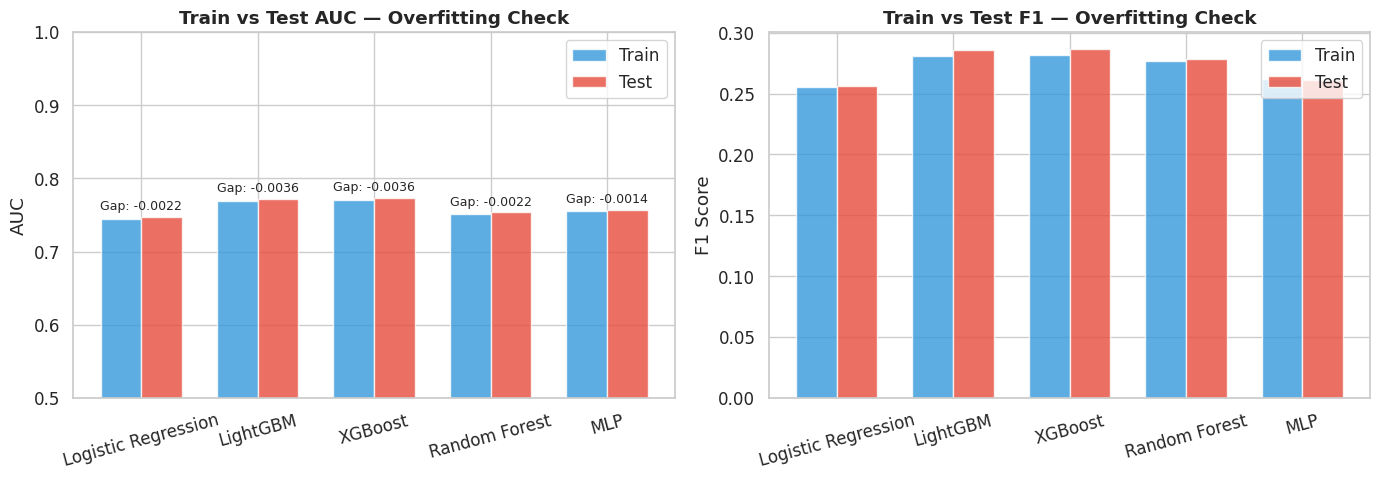

In [49]:
# Train vs Test comparison for overfitting detection
print("=" * 80)
print("OVERFITTING / UNDERFITTING ANALYSIS")
print("=" * 80)

overfit_rows = []
for model_name, res in baseline_results.items():
    train_auc = res['train_metrics']['AUC']
    test_auc = res['test_metrics']['AUC']
    gap = train_auc - test_auc

    train_f1 = res['train_metrics']['F1']
    test_f1 = res['test_metrics']['F1']
    f1_gap = train_f1 - test_f1

    if gap > 0.05:
        status = "OVERFITTING"
    elif gap < -0.01:
        status = "UNDERFITTING"
    else:
        status = "GOOD FIT"

    overfit_rows.append({
        'Model': model_name,
        'Train AUC': train_auc, 'Test AUC': test_auc, 'AUC Gap': gap,
        'Train F1': train_f1, 'Test F1': test_f1, 'F1 Gap': f1_gap,
        'Status': status
    })

overfit_df = pd.DataFrame(overfit_rows)
display(overfit_df.round(4))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# AUC comparison
ax = axes[0]
models = list(baseline_results.keys())
train_aucs = [baseline_results[m]['train_metrics']['AUC'] for m in models]
test_aucs = [baseline_results[m]['test_metrics']['AUC'] for m in models]
x = np.arange(len(models))
width = 0.35
bars1 = ax.bar(x - width/2, train_aucs, width, label='Train', color='#3498db', alpha=0.8)
bars2 = ax.bar(x + width/2, test_aucs, width, label='Test', color='#e74c3c', alpha=0.8)
ax.set_ylabel('AUC')
ax.set_title('Train vs Test AUC — Overfitting Check', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15)
ax.legend()
ax.set_ylim(0.5, 1.0)
for i, (tr, te) in enumerate(zip(train_aucs, test_aucs)):
    ax.annotate(f'Gap: {tr-te:.4f}', (i, max(tr, te) + 0.01), ha='center', fontsize=9)

# F1 comparison
ax = axes[1]
train_f1s = [baseline_results[m]['train_metrics']['F1'] for m in models]
test_f1s = [baseline_results[m]['test_metrics']['F1'] for m in models]
bars1 = ax.bar(x - width/2, train_f1s, width, label='Train', color='#3498db', alpha=0.8)
bars2 = ax.bar(x + width/2, test_f1s, width, label='Test', color='#e74c3c', alpha=0.8)
ax.set_ylabel('F1 Score')
ax.set_title('Train vs Test F1 — Overfitting Check', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15)
ax.legend()

plt.tight_layout()
plt.show()

### 4.5 Detailed Evaluation — Confusion Matrices, ROC Curves, Error Analysis

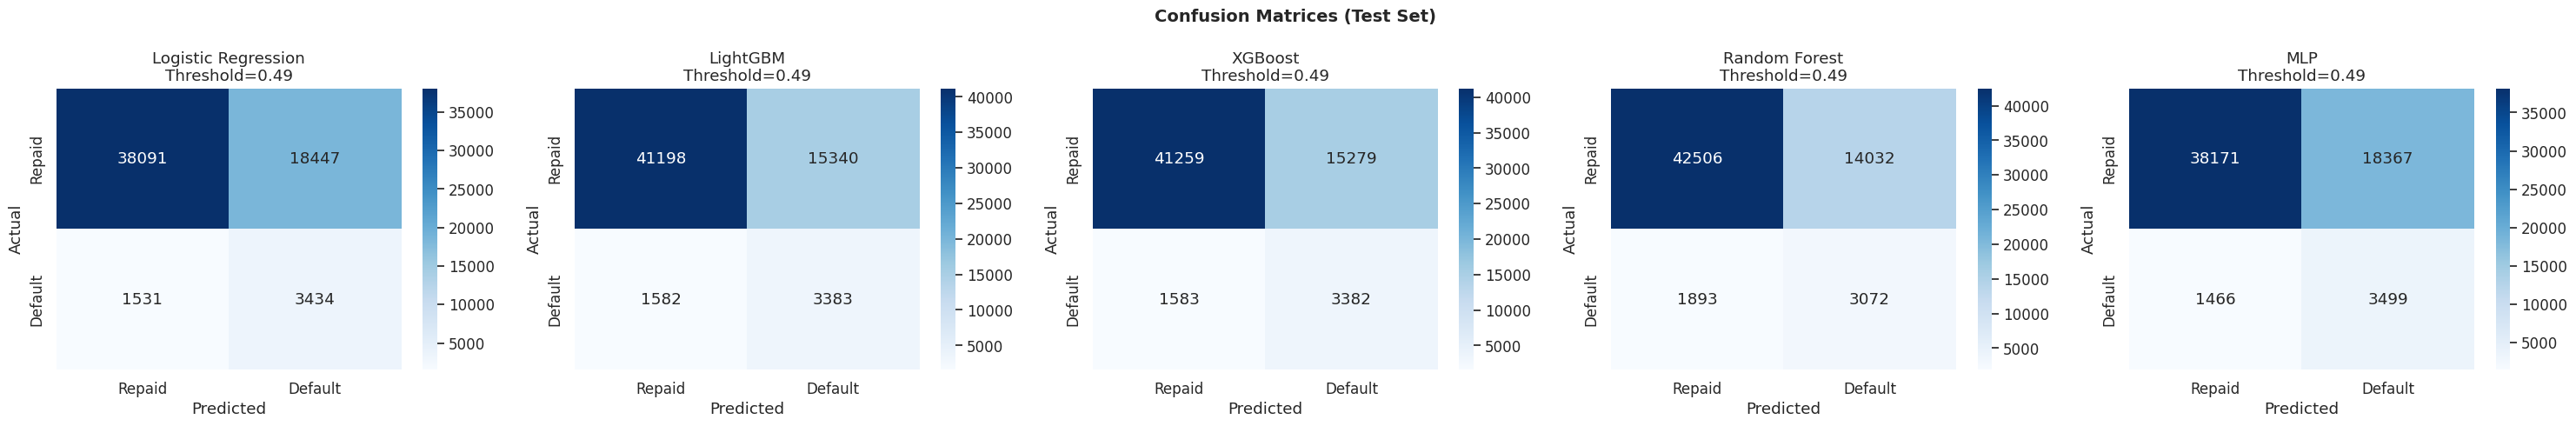


Classification Report: Logistic Regression
              precision    recall  f1-score   support

      Repaid       0.96      0.67      0.79     56538
     Default       0.16      0.69      0.26      4965

    accuracy                           0.68     61503
   macro avg       0.56      0.68      0.52     61503
weighted avg       0.90      0.68      0.75     61503


Classification Report: LightGBM
              precision    recall  f1-score   support

      Repaid       0.96      0.73      0.83     56538
     Default       0.18      0.68      0.29      4965

    accuracy                           0.72     61503
   macro avg       0.57      0.71      0.56     61503
weighted avg       0.90      0.72      0.79     61503


Classification Report: XGBoost
              precision    recall  f1-score   support

      Repaid       0.96      0.73      0.83     56538
     Default       0.18      0.68      0.29      4965

    accuracy                           0.73     61503
   macro avg       

In [50]:
# Confusion Matrices for all models
n_models = len(baseline_results)
fig, axes = plt.subplots(1, n_models, figsize=(6 * n_models, 5))
if n_models == 1: axes = [axes]
fig.suptitle('Confusion Matrices (Test Set)', fontsize=14, fontweight='bold')

for idx, (model_name, res) in enumerate(baseline_results.items()):
    ax = axes[idx]
    cm = confusion_matrix(y_test, res['test_pred'], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Repaid', 'Default'], yticklabels=['Repaid', 'Default'])
    ax.set_title(f'{model_name}\nThreshold={res["threshold"]:.2f}')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.tight_layout()
plt.show()

# Classification reports
for model_name, res in baseline_results.items():
    print(f"\n{'='*50}")
    print(f"Classification Report: {model_name}")
    print(f"{'='*50}")
    print(classification_report(y_test, res['test_pred'], target_names=['Repaid', 'Default']))


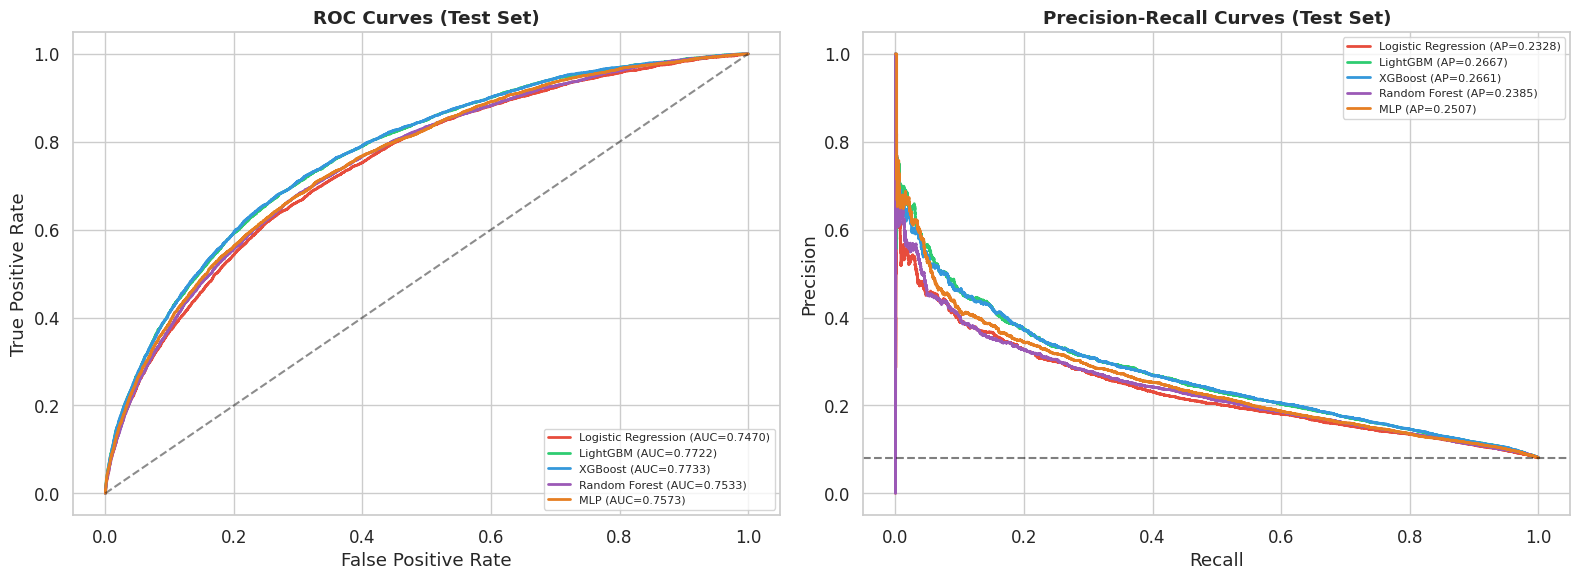

In [51]:
# ROC Curves
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Dynamic color palette
import itertools
_color_cycle = itertools.cycle(['#e74c3c', '#2ecc71', '#3498db', '#9b59b6', '#e67e22', '#1abc9c', '#f39c12', '#34495e'])
model_colors = {name: next(_color_cycle) for name in baseline_results.keys()}

# ROC Curves
ax = axes[0]
for model_name, res in baseline_results.items():
    fpr, tpr, _ = roc_curve(y_test, res['test_proba'])
    ax.plot(fpr, tpr, color=model_colors.get(model_name, 'gray'), lw=2,
            label=f"{model_name} (AUC={res['test_metrics']['AUC']:.4f})")
ax.plot([0,1], [0,1], 'k--', alpha=0.5)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves (Test Set)', fontweight='bold')
ax.legend(loc='lower right', fontsize=8)

# Precision-Recall Curves
ax = axes[1]
for model_name, res in baseline_results.items():
    precision_vals, recall_vals, _ = precision_recall_curve(y_test, res['test_proba'])
    ap = res['test_metrics']['AP']
    ax.plot(recall_vals, precision_vals, color=model_colors.get(model_name, 'gray'), lw=2,
            label=f"{model_name} (AP={ap:.4f})")
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curves (Test Set)', fontweight='bold')
ax.legend(loc='upper right', fontsize=8)
ax.axhline(y=y_test.mean(), color='black', linestyle='--', alpha=0.5, label='Baseline')

plt.tight_layout()
plt.show()


ERROR ANALYSIS — Where do models make mistakes?
Detailed error analysis model: XGBoost

True Negatives (correct repaid):  41,259
True Positives (caught defaults):  3,382
False Positives (false alarms):   15,279
False Negatives (missed defaults): 1,583


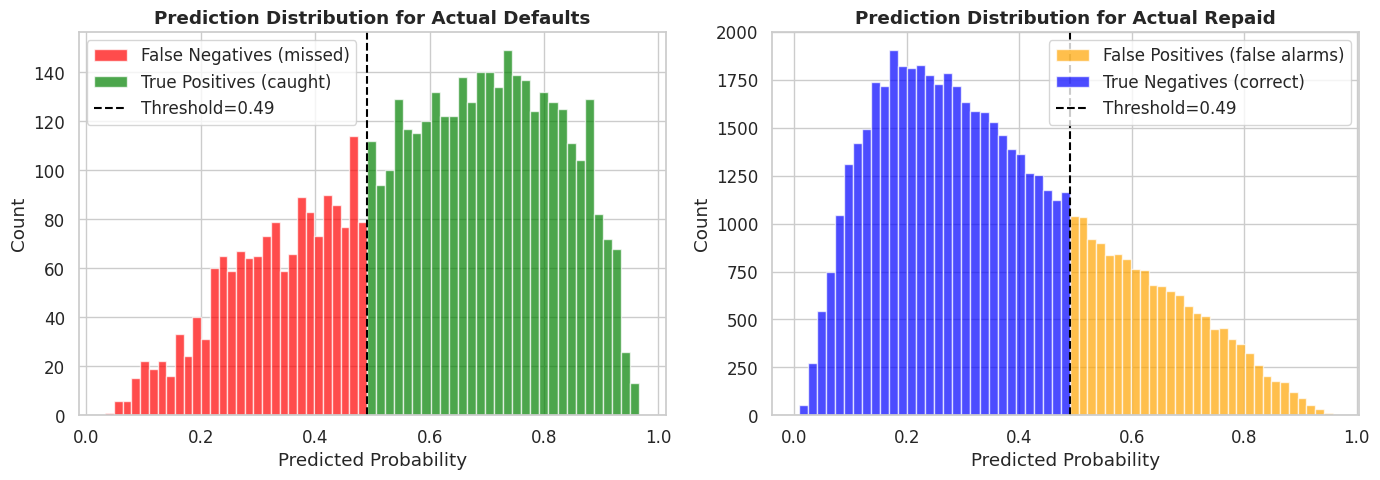


--- Average feature values by prediction outcome ---

EXT_SOURCE_MEAN:
  True Positives:  0.3314
  False Negatives: 0.5392
  False Positives: 0.3736
  True Negatives:  0.5737

AGE_YEARS:
  True Positives:  38.9744
  False Negatives: 45.4187
  False Positives: 39.6853
  True Negatives:  45.9387

CREDIT_INCOME_RATIO:
  True Positives:  3.7320
  False Negatives: 4.1637
  False Positives: 3.8272
  True Negatives:  4.0055

ANNUITY_INCOME_RATIO:
  True Positives:  0.1859
  False Negatives: 0.1801
  False Positives: 0.1848
  True Negatives:  0.1792

INST_LATE_RATIO:
  True Positives:  0.1106
  False Negatives: 0.0697
  False Positives: 0.1021
  True Negatives:  0.0567


In [52]:
# Error Analysis — analyze where models fail
print("=" * 70)
print("ERROR ANALYSIS — Where do models make mistakes?")
print("=" * 70)

# Use the current best single model for detailed error analysis
single_model_candidates = [k for k in baseline_results.keys() if k != 'Stacking Ensemble']
best_name = max(single_model_candidates, key=lambda k: baseline_results[k]['test_metrics']['AUC'])
best_res = baseline_results[best_name]

print(f"Detailed error analysis model: {best_name}")

# False Negatives (missed defaults) and False Positives (false alarms)
fn_mask = (y_test == 1) & (best_res['test_pred'] == 0)  # missed defaults
fp_mask = (y_test == 0) & (best_res['test_pred'] == 1)  # false alarms
tp_mask = (y_test == 1) & (best_res['test_pred'] == 1)  # caught defaults
tn_mask = (y_test == 0) & (best_res['test_pred'] == 0)  # correct repaid

print(f"\nTrue Negatives (correct repaid):  {tn_mask.sum():>6,}")
print(f"True Positives (caught defaults): {tp_mask.sum():>6,}")
print(f"False Positives (false alarms):   {fp_mask.sum():>6,}")
print(f"False Negatives (missed defaults):{fn_mask.sum():>6,}")

# Probability distribution for errors
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.hist(best_res['test_proba'][fn_mask], bins=30, alpha=0.7, color='red', label='False Negatives (missed)')
ax.hist(best_res['test_proba'][tp_mask], bins=30, alpha=0.7, color='green', label='True Positives (caught)')
ax.set_xlabel('Predicted Probability')
ax.set_ylabel('Count')
ax.set_title('Prediction Distribution for Actual Defaults', fontweight='bold')
ax.axvline(x=best_res['threshold'], color='black', linestyle='--', label=f'Threshold={best_res["threshold"]:.2f}')
ax.legend()

ax = axes[1]
ax.hist(best_res['test_proba'][fp_mask], bins=30, alpha=0.7, color='orange', label='False Positives (false alarms)')
ax.hist(best_res['test_proba'][tn_mask], bins=30, alpha=0.7, color='blue', label='True Negatives (correct)')
ax.set_xlabel('Predicted Probability')
ax.set_ylabel('Count')
ax.set_title('Prediction Distribution for Actual Repaid', fontweight='bold')
ax.axvline(x=best_res['threshold'], color='black', linestyle='--', label=f'Threshold={best_res["threshold"]:.2f}')
ax.legend()

plt.tight_layout()
plt.show()

# Feature analysis of errors
print("\n--- Average feature values by prediction outcome ---")
error_analysis_features = ['EXT_SOURCE_MEAN', 'AGE_YEARS', 'CREDIT_INCOME_RATIO', 'ANNUITY_INCOME_RATIO', 'INST_LATE_RATIO']
error_analysis_features = [f for f in error_analysis_features if f in X_test.columns]

for feat in error_analysis_features:
    print(f"\n{feat}:")
    print(f"  True Positives:  {X_test.loc[tp_mask, feat].mean():.4f}")
    print(f"  False Negatives: {X_test.loc[fn_mask, feat].mean():.4f}")
    print(f"  False Positives: {X_test.loc[fp_mask, feat].mean():.4f}")
    print(f"  True Negatives:  {X_test.loc[tn_mask, feat].mean():.4f}")

### 4.6 Enhanced Threshold Optimization

The default 0.5 threshold is suboptimal for imbalanced data. We evaluate:
1. **F1-maximizing** threshold
2. **F2-maximizing** threshold (emphasizes recall — better for credit risk)
3. **Fixed recall ≥ 0.60** threshold
4. **Fixed precision ≥ 0.25** threshold
5. **Cost-sensitive** threshold (missed default = 10× false alarm)

ENHANCED THRESHOLD OPTIMIZATION

Model: XGBoost

Threshold comparison (evaluated on holdout):
----------------------------------------------------------------------------------------------------


,Strategy,Threshold,Precision,Recall,F1,F2,Pred_Default_Rate,TP,FP,FN,TN
0,F1-optimal,0.4950,0.1831,0.6745,0.2880,0.4389,0.2974,3349,14944,1616,41594
1,F2-optimal,0.4700,0.1733,0.7049,0.2783,0.4369,0.3283,3500,16691,1465,39847
2,Cost-sensitive,0.4950,0.1831,0.6745,0.2880,0.4389,0.2974,3349,14944,1616,41594
3,Recall>=0.60,0.4950,0.1831,0.6745,0.2880,0.4389,0.2974,3349,14944,1616,41594
4,Precision>=0.25,0.4950,0.1831,0.6745,0.2880,0.4389,0.2974,3349,14944,1616,41594


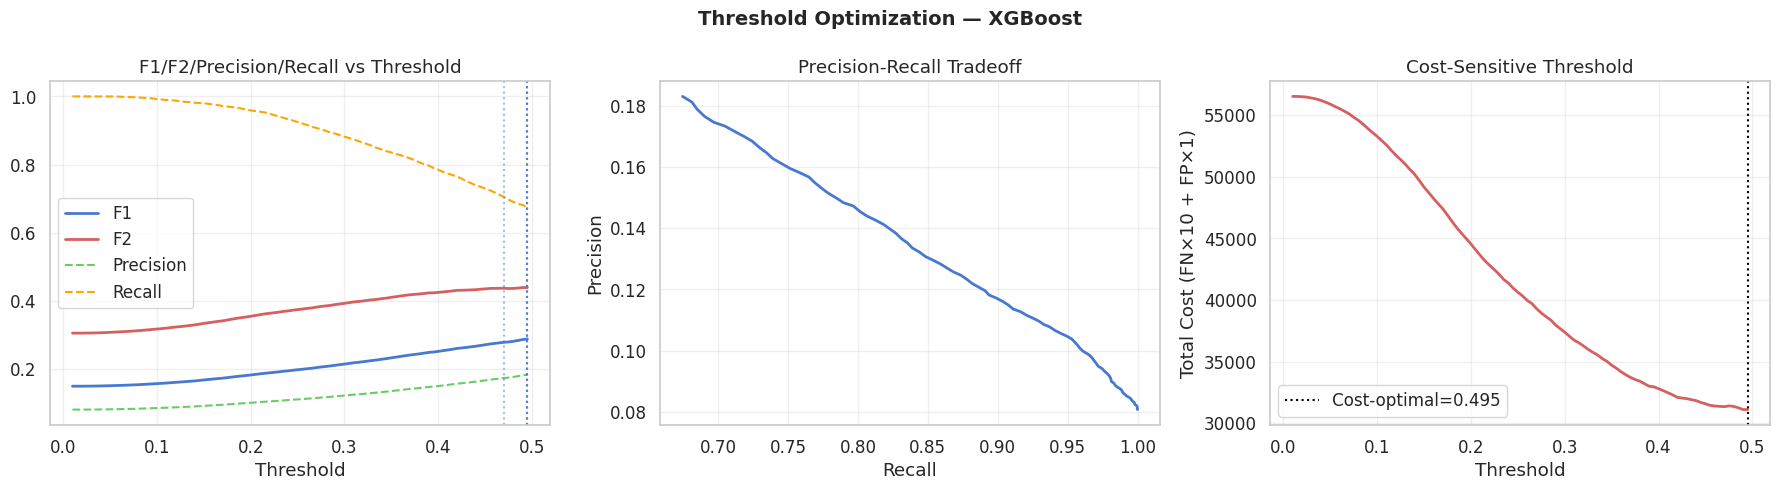


Business recommendation: Use F2-optimal or cost-sensitive threshold for credit scoring.
F2 threshold (0.470) emphasizes catching defaulters while maintaining reasonable precision.


In [53]:
# Enhanced threshold optimization (TASK 5)
print("=" * 80)
print("ENHANCED THRESHOLD OPTIMIZATION")
print("=" * 80)

# Use best baseline model
best_baseline_name = max(baseline_results.keys(), key=lambda k: baseline_results[k]['test_metrics']['AUC'])
best_proba = baseline_results[best_baseline_name]['test_proba']
best_oof = baseline_results[best_baseline_name]['train_proba']

thresholds = np.arange(0.01, 0.50, 0.005)

# Compute all metrics across thresholds (on OOF for selection, holdout for reporting)
def compute_threshold_metrics(y_true, y_proba, thresholds):
    results = []
    for t in thresholds:
        pred = (y_proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        results.append({
            'threshold': t,
            'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred, zero_division=0),
            'f1': f1_score(y_true, pred, zero_division=0),
            'f2': fbeta_score(y_true, pred, beta=2, zero_division=0),
            'predicted_default_rate': pred.mean(),
            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'cost': fn * 10 + fp * 1,  # cost-sensitive: missed default = 10x false alarm
        })
    return pd.DataFrame(results)

# Select thresholds on OOF (no leakage)
oof_metrics = compute_threshold_metrics(y_train, best_oof, thresholds)

thresh_f1 = oof_metrics.loc[oof_metrics['f1'].idxmax(), 'threshold']
thresh_f2 = oof_metrics.loc[oof_metrics['f2'].idxmax(), 'threshold']
thresh_cost = oof_metrics.loc[oof_metrics['cost'].idxmin(), 'threshold']

# Fixed recall >= 0.60
recall_mask = oof_metrics['recall'] >= 0.60
thresh_recall60 = oof_metrics.loc[recall_mask, 'threshold'].max() if recall_mask.any() else thresh_f2

# Fixed precision >= 0.25
prec_mask = oof_metrics['precision'] >= 0.25
thresh_prec25 = oof_metrics.loc[prec_mask, 'threshold'].min() if prec_mask.any() else thresh_f1

# Evaluate all thresholds on holdout
threshold_strategies = {
    'F1-optimal': thresh_f1,
    'F2-optimal': thresh_f2,
    'Cost-sensitive': thresh_cost,
    'Recall>=0.60': thresh_recall60,
    'Precision>=0.25': thresh_prec25,
}

print(f"\nModel: {best_baseline_name}")
print(f"\nThreshold comparison (evaluated on holdout):")
print("-" * 100)

threshold_comparison_rows = []
for strategy, t in threshold_strategies.items():
    pred = (best_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    row = {
        'Strategy': strategy,
        'Threshold': t,
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0),
        'F2': fbeta_score(y_test, pred, beta=2, zero_division=0),
        'Pred_Default_Rate': pred.mean(),
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
    }
    threshold_comparison_rows.append(row)

threshold_df = pd.DataFrame(threshold_comparison_rows)
display(threshold_df.round(4))

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(f'Threshold Optimization — {best_baseline_name}', fontsize=14, fontweight='bold')

holdout_metrics = compute_threshold_metrics(y_test, best_proba, thresholds)

ax = axes[0]
ax.plot(thresholds, holdout_metrics['f1'], 'b-', lw=2, label='F1')
ax.plot(thresholds, holdout_metrics['f2'], 'r-', lw=2, label='F2')
ax.plot(thresholds, holdout_metrics['precision'], 'g--', lw=1.5, label='Precision')
ax.plot(thresholds, holdout_metrics['recall'], 'orange', lw=1.5, label='Recall', linestyle='--')
for name, t in threshold_strategies.items():
    ax.axvline(x=t, linestyle=':', alpha=0.5)
ax.legend()
ax.set_xlabel('Threshold')
ax.set_title('F1/F2/Precision/Recall vs Threshold')
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(holdout_metrics['recall'], holdout_metrics['precision'], 'b-', lw=2)
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Tradeoff')
ax.grid(True, alpha=0.3)

ax = axes[2]
ax.plot(thresholds, holdout_metrics['cost'], 'r-', lw=2)
ax.axvline(x=thresh_cost, color='black', linestyle=':', label=f'Cost-optimal={thresh_cost:.3f}')
ax.set_xlabel('Threshold')
ax.set_ylabel('Total Cost (FN×10 + FP×1)')
ax.set_title('Cost-Sensitive Threshold')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nBusiness recommendation: Use F2-optimal or cost-sensitive threshold for credit scoring.")
print(f"F2 threshold ({thresh_f2:.3f}) emphasizes catching defaulters while maintaining reasonable precision.")

### 4.7 Learning Curves

In [54]:
# Learning curves for key models — SAFE VERSION
# ------------------------------------------------------------------
# Why this cell was changed:
# sklearn.learning_curve repeatedly refits each model and cannot pass
# fold-specific eval_set to XGBoost/LightGBM early stopping. The old
# version crashed at XGBoost with:
# "Must have at least 1 validation dataset for early stopping."
#
# For the final thesis run, learning curves are optional diagnostics.
# They are not needed for model metrics, calibration, stacking, or blind
# scoring. By default this cell is skipped so the notebook can continue
# after the expensive model-training phase.
#
# If you really want learning curves, set RUN_LEARNING_CURVES = True.
# The optional version below uses safe diagnostic models WITHOUT early
# stopping and a capped sample size to avoid another multi-hour rerun.

RUN_LEARNING_CURVES = False

if not RUN_LEARNING_CURVES:
    print("Learning curves skipped safely.")
    print("Reason: learning_curve refits models without eval_set, which breaks early-stopping XGBoost/LightGBM.")
    print("This does NOT affect model training, tuning, calibration, stacking, or blind scoring.")
    print("Continue with the next cell.")
else:
    from sklearn.model_selection import learning_curve
    from sklearn.base import clone

    # Cap rows for diagnostics. Full-data learning curves are very expensive.
    LC_MAX_ROWS = 60000
    if len(X_train) > LC_MAX_ROWS:
        lc_idx, _ = train_test_split(
            np.arange(len(y_train)),
            train_size=LC_MAX_ROWS,
            stratify=y_train,
            random_state=42
        )
        X_lc = X_train.iloc[lc_idx].copy()
        y_lc = y_train[lc_idx]
    else:
        X_lc = X_train.copy()
        y_lc = y_train

    lc_pos_weight = compute_pos_weight(y_lc)

    def lgbm_lc_factory(pos_weight=None):
        return lgb.LGBMClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.05,
            num_leaves=31,
            min_child_samples=50,
            subsample=0.8,
            colsample_bytree=0.8,
            class_weight=make_class_weight_dict(pos_weight) if pos_weight is not None else "balanced",
            random_state=42,
            n_jobs=1,
            metric='auc',
            verbose=-1
        )

    def xgb_lc_factory(pos_weight=None):
        # IMPORTANT: no early_stopping_rounds here because learning_curve
        # cannot provide eval_set to each internal fit.
        return xgb.XGBClassifier(
            n_estimators=300,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=100,
            reg_alpha=1.0,
            reg_lambda=5.0,
            scale_pos_weight=1.0 if pos_weight is None else float(pos_weight),
            eval_metric='auc',
            random_state=42,
            n_jobs=1,
            verbosity=0
        )

    models_for_lc = {
        'Logistic Regression': build_lr_pipeline(pos_weight=lc_pos_weight),
        'LightGBM': lgbm_lc_factory(lc_pos_weight),
        'XGBoost': xgb_lc_factory(lc_pos_weight),
        'Random Forest': rf_factory(lc_pos_weight),
    }

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    axes = axes.ravel()
    fig.suptitle('Learning Curves — Bias/Variance Diagnosis', fontsize=14, fontweight='bold')

    train_sizes = np.linspace(0.2, 1.0, 5)
    cv_lc = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

    for idx, (name, model) in enumerate(models_for_lc.items()):
        ax = axes[idx]
        try:
            train_sizes_abs, train_scores, val_scores = learning_curve(
                model,
                X_lc,
                y_lc,
                train_sizes=train_sizes,
                cv=cv_lc,
                scoring='roc_auc',
                n_jobs=1,
                error_score=np.nan
            )

            train_mean = np.nanmean(train_scores, axis=1)
            train_std = np.nanstd(train_scores, axis=1)
            val_mean = np.nanmean(val_scores, axis=1)
            val_std = np.nanstd(val_scores, axis=1)

            ax.fill_between(train_sizes_abs, train_mean - train_std, train_mean + train_std, alpha=0.15)
            ax.fill_between(train_sizes_abs, val_mean - val_std, val_mean + val_std, alpha=0.15)
            ax.plot(train_sizes_abs, train_mean, 'o-', label='Training score')
            ax.plot(train_sizes_abs, val_mean, 'o-', label='Validation score')
            ax.set_title(f'{name}\nGap: {(train_mean[-1] - val_mean[-1]):.4f}', fontweight='bold')
            ax.legend(loc='best')
        except Exception as e:
            ax.text(0.5, 0.5, f'{name}\nSkipped: {type(e).__name__}', ha='center', va='center')
            ax.set_title(f'{name} — skipped')

        ax.set_xlabel('Training Examples')
        ax.set_ylabel('ROC-AUC')
        ax.set_ylim(0.5, 1.0)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()



Learning curves skipped safely.
Reason: learning_curve refits models without eval_set, which breaks early-stopping XGBoost/LightGBM.
This does NOT affect model training, tuning, calibration, stacking, or blind scoring.
Continue with the next cell.


### Runtime fix note

The previous learning-curve cell failed because `sklearn.learning_curve` refits XGBoost without an `eval_set`, while the XGBoost factory used early stopping. The fixed cell skips learning curves by default and provides an optional safe version without early stopping. Continue running from the next cell; previous trained model outputs are still valid.


---
## Phase 5: Hyperparameter Tuning (Optuna)

Optimize all models using stratified cross-validation on the training partition only.

---

In [55]:
# === FAST Logistic Regression tuning with Optuna ===
# build_lr_pipeline() is defined in the helpers cell above (Cell 66).
# This cell only contains the Optuna tuning logic.

import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

# Fast tuning settings
LR_TUNE_SAMPLE_FRAC = get_setting(FAST_TUNE_SAMPLE_FRAC, FINAL_LR_TUNE_SAMPLE_FRAC)
LR_TUNE_N_SPLITS = get_setting(FAST_TUNE_N_SPLITS, FINAL_LR_TUNE_N_SPLITS)
LR_TUNE_N_TRIALS = get_setting(FAST_TUNE_TRIALS, FINAL_LR_TUNE_TRIALS)
LR_TUNE_TIMEOUT = get_setting(FAST_TUNE_TIMEOUT, FINAL_LR_TUNE_TIMEOUT)


# Stratified sample only for LR tuning
X_lr_tune, _, y_lr_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=LR_TUNE_SAMPLE_FRAC,
    stratify=y_train,
    random_state=42
)


def lr_objective(trial):
    params = {
        "C": trial.suggest_float("C", 1e-3, 50.0, log=True),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        "solver": trial.suggest_categorical("solver", ["lbfgs", "liblinear"]),
        "penalty": "l2",
        "max_iter": get_setting(500, 2000)
    }

    skf_lr = StratifiedKFold(
        n_splits=LR_TUNE_N_SPLITS,
        shuffle=True,
        random_state=42
    )

    cv_scores = []

    for fold_idx, (tr_idx, vl_idx) in enumerate(skf_lr.split(X_lr_tune, y_lr_tune), start=1):
        if hasattr(X_lr_tune, "iloc"):
            X_tr, X_vl = X_lr_tune.iloc[tr_idx], X_lr_tune.iloc[vl_idx]
        else:
            X_tr, X_vl = X_lr_tune[tr_idx], X_lr_tune[vl_idx]

        if hasattr(y_lr_tune, "iloc"):
            y_tr, y_vl = y_lr_tune.iloc[tr_idx], y_lr_tune.iloc[vl_idx]
        else:
            y_tr, y_vl = y_lr_tune[tr_idx], y_lr_tune[vl_idx]

        model = build_lr_pipeline(params)
        model.fit(X_tr, y_tr)

        pred = model.predict_proba(X_vl)[:, 1]
        fold_auc = roc_auc_score(y_vl, pred)
        cv_scores.append(fold_auc)

        trial.report(float(np.mean(cv_scores)), step=fold_idx)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return float(np.mean(cv_scores))


print("=" * 60)
print("Tuning Logistic Regression with Optuna (FULL version)")
print(f"Sample fraction: {LR_TUNE_SAMPLE_FRAC}")
print(f"CV folds: {LR_TUNE_N_SPLITS}")
print(f"Trials: {LR_TUNE_N_TRIALS}")
print(f"Timeout (sec): {LR_TUNE_TIMEOUT}")
print("=" * 60)

study_lr = optuna.create_study(
    direction="maximize",
    study_name="lr_tuning_full",
    sampler=TPESampler(seed=42),
    pruner=MedianPruner(n_startup_trials=5, n_warmup_steps=1)
)

study_lr.optimize(
    lr_objective,
    n_trials=LR_TUNE_N_TRIALS,
    timeout=LR_TUNE_TIMEOUT,
    show_progress_bar=True
)

best_lr_params = {
    **study_lr.best_params,
    "penalty": "l2",
    "max_iter": get_setting(500, 2000)
}
best_lr_cv_auc = study_lr.best_value

print(f"\nBest Logistic Regression CV AUC: {best_lr_cv_auc:.4f}")
print(f"Best params: {best_lr_params}")


[I 2026-05-19 05:50:31,934] A new study created in memory with name: lr_tuning_full


Tuning Logistic Regression with Optuna (FULL version)
Sample fraction: 0.8
CV folds: 5
Trials: 60
Timeout (sec): 5400


  0%|          | 0/60 [00:00<?, ?it/s]

[I 2026-05-19 05:50:44,892] Trial 0 finished with value: 0.7448671652569014 and parameters: {'C': 0.05753773794117188, 'class_weight': None, 'solver': 'lbfgs'}. Best is trial 0 with value: 0.7448671652569014.
[I 2026-05-19 05:51:02,290] Trial 1 finished with value: 0.7448187010114106 and parameters: {'C': 0.005407712220288121, 'class_weight': 'balanced', 'solver': 'liblinear'}. Best is trial 0 with value: 0.7448671652569014.
[I 2026-05-19 05:51:11,792] Trial 2 finished with value: 0.7445343310597404 and parameters: {'C': 0.0012494702536130701, 'class_weight': None, 'solver': 'lbfgs'}. Best is trial 0 with value: 0.7448671652569014.
[I 2026-05-19 05:51:24,090] Trial 3 finished with value: 0.7448304245499019 and parameters: {'C': 0.0072746531356694235, 'class_weight': 'balanced', 'solver': 'lbfgs'}. Best is trial 0 with value: 0.7448671652569014.
[I 2026-05-19 05:51:48,648] Trial 4 finished with value: 0.7448603466201117 and parameters: {'C': 0.7500295933641418, 'class_weight': 'balanced

In [56]:
# ─── XGBoost Tuning with Optuna (FAST + class weighting) ───
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

XGB_TUNE_SAMPLE_FRAC = get_setting(FAST_TUNE_SAMPLE_FRAC, FINAL_XGB_TUNE_SAMPLE_FRAC)
XGB_TUNE_N_SPLITS = get_setting(FAST_TUNE_N_SPLITS, FINAL_XGB_TUNE_N_SPLITS)
XGB_TUNE_N_TRIALS = get_setting(FAST_TUNE_TRIALS, FINAL_XGB_TUNE_TRIALS)
XGB_TUNE_TIMEOUT = get_setting(FAST_TUNE_TIMEOUT, FINAL_XGB_TUNE_TIMEOUT)

X_xgb_tune, _, y_xgb_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=XGB_TUNE_SAMPLE_FRAC,
    stratify=y_train,
    random_state=42
)

def xgb_objective(trial):
    base_params = {
        'max_depth': trial.suggest_int('max_depth', 3, 6),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.12, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 50, 250),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 3.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 5.0, log=True),
        'gamma': trial.suggest_float('gamma', 0.0, 2.0),
        'n_estimators': get_setting(FAST_XGB_ESTIMATORS, FINAL_XGB_ESTIMATORS),
        'random_state': 42,
        'n_jobs': 1,
        'verbosity': 0,
        'eval_metric': 'auc',
        'early_stopping_rounds': get_setting(FAST_EARLY_STOPPING_ROUNDS, FINAL_EARLY_STOPPING_ROUNDS)
    }

    skf_tune = StratifiedKFold(
        n_splits=XGB_TUNE_N_SPLITS,
        shuffle=True,
        random_state=42
    )

    cv_scores = []

    for fold_idx, (tr_idx, vl_idx) in enumerate(skf_tune.split(X_xgb_tune, y_xgb_tune), start=1):
        X_tr, X_vl = X_xgb_tune.iloc[tr_idx], X_xgb_tune.iloc[vl_idx]

        if hasattr(y_xgb_tune, "iloc"):
            y_tr, y_vl = y_xgb_tune.iloc[tr_idx], y_xgb_tune.iloc[vl_idx]
        else:
            y_tr, y_vl = y_xgb_tune[tr_idx], y_xgb_tune[vl_idx]

        fold_params = dict(base_params)
        fold_params['scale_pos_weight'] = compute_pos_weight(y_tr)

        model = xgb.XGBClassifier(**fold_params)
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_vl, y_vl)],
            verbose=False
        )

        pred = model.predict_proba(X_vl)[:, 1]
        fold_auc = roc_auc_score(y_vl, pred)
        cv_scores.append(fold_auc)

        trial.report(float(np.mean(cv_scores)), step=fold_idx)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return float(np.mean(cv_scores))

print("=" * 60)
print("Tuning XGBoost with Optuna (FULL + class weighting)")
print(f"Sample fraction: {XGB_TUNE_SAMPLE_FRAC}")
print(f"CV folds: {XGB_TUNE_N_SPLITS}")
print(f"Trials: {XGB_TUNE_N_TRIALS}")
print(f"Timeout (sec): {XGB_TUNE_TIMEOUT}")
print("=" * 60)

study_xgb = optuna.create_study(
    direction='maximize',
    study_name='xgb_tuning_full',
    sampler=TPESampler(seed=42),
    pruner=MedianPruner(n_startup_trials=4, n_warmup_steps=1)
)

study_xgb.optimize(
    xgb_objective,
    n_trials=XGB_TUNE_N_TRIALS,
    timeout=XGB_TUNE_TIMEOUT,
    show_progress_bar=True
)

print(f"\nBest XGBoost CV AUC: {study_xgb.best_value:.4f}")
print(f"Best params: {study_xgb.best_params}")


[I 2026-05-19 05:55:50,184] A new study created in memory with name: xgb_tuning_full


Tuning XGBoost with Optuna (FULL + class weighting)
Sample fraction: 0.6
CV folds: 4
Trials: 80
Timeout (sec): 7200


  0%|          | 0/80 [00:00<?, ?it/s]

[I 2026-05-19 05:56:30,091] Trial 0 finished with value: 0.7645852789584874 and parameters: {'max_depth': 4, 'learning_rate': 0.10985745201142037, 'min_child_weight': 197, 'subsample': 0.8795975452591109, 'colsample_bytree': 0.6624074561769746, 'reg_alpha': 0.003486678167045121, 'reg_lambda': 0.0016400214911202306, 'gamma': 1.7323522915498704}. Best is trial 0 with value: 0.7645852789584874.
[I 2026-05-19 05:57:12,047] Trial 1 finished with value: 0.7618389997992947 and parameters: {'max_depth': 5, 'learning_rate': 0.07112422668158716, 'min_child_weight': 54, 'subsample': 0.9909729556485982, 'colsample_bytree': 0.9329770563201687, 'reg_alpha': 0.005474303040596575, 'reg_lambda': 0.004705059281907645, 'gamma': 0.36680901970686763}. Best is trial 0 with value: 0.7645852789584874.
[I 2026-05-19 05:58:14,435] Trial 2 finished with value: 0.7646370287035089 and parameters: {'max_depth': 4, 'learning_rate': 0.051211779757401, 'min_child_weight': 136, 'subsample': 0.7873687420594125, 'colsamp

In [57]:
# ─── LightGBM Tuning with Optuna (FAST + class weighting) ───
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

LGBM_TUNE_SAMPLE_FRAC = get_setting(FAST_TUNE_SAMPLE_FRAC, FINAL_LGBM_TUNE_SAMPLE_FRAC)
LGBM_TUNE_N_SPLITS = get_setting(FAST_TUNE_N_SPLITS, FINAL_LGBM_TUNE_N_SPLITS)
LGBM_TUNE_N_TRIALS = get_setting(FAST_TUNE_TRIALS, FINAL_LGBM_TUNE_TRIALS)
LGBM_TUNE_TIMEOUT = get_setting(FAST_TUNE_TIMEOUT, FINAL_LGBM_TUNE_TIMEOUT)

X_lgb_tune, _, y_lgb_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=LGBM_TUNE_SAMPLE_FRAC,
    stratify=y_train,
    random_state=42
)

def lgbm_objective(trial):
    params = {
        'max_depth': trial.suggest_int('max_depth', 4, 7),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.12, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 24, 80),
        'min_child_samples': trial.suggest_int('min_child_samples', 50, 250),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 3.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 5.0, log=True),
        'min_split_gain': trial.suggest_float('min_split_gain', 0.0, 0.3),
        'n_estimators': get_setting(FAST_LGBM_ESTIMATORS, FINAL_LGBM_ESTIMATORS),
        'metric': 'auc',
        'random_state': 42,
        'n_jobs': 1,
        'verbose': -1
    }

    skf_tune = StratifiedKFold(
        n_splits=LGBM_TUNE_N_SPLITS,
        shuffle=True,
        random_state=42
    )

    cv_scores = []

    for fold_idx, (tr_idx, vl_idx) in enumerate(skf_tune.split(X_lgb_tune, y_lgb_tune), start=1):
        X_tr, X_vl = X_lgb_tune.iloc[tr_idx], X_lgb_tune.iloc[vl_idx]

        if hasattr(y_lgb_tune, "iloc"):
            y_tr, y_vl = y_lgb_tune.iloc[tr_idx], y_lgb_tune.iloc[vl_idx]
        else:
            y_tr, y_vl = y_lgb_tune[tr_idx], y_lgb_tune[vl_idx]

        fold_class_weight = make_class_weight_dict(compute_pos_weight(y_tr))
        model = lgb.LGBMClassifier(**params, class_weight=fold_class_weight)
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_vl, y_vl)],
            callbacks=[
                lgb.early_stopping(get_setting(FAST_EARLY_STOPPING_ROUNDS, FINAL_EARLY_STOPPING_ROUNDS), verbose=False, first_metric_only=True),
                lgb.log_evaluation(0)
            ]
        )

        pred = model.predict_proba(X_vl)[:, 1]
        fold_auc = roc_auc_score(y_vl, pred)
        cv_scores.append(fold_auc)

        trial.report(float(np.mean(cv_scores)), step=fold_idx)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return float(np.mean(cv_scores))

print("=" * 60)
print("Tuning LightGBM with Optuna (FULL + class weighting)")
print(f"Sample fraction: {LGBM_TUNE_SAMPLE_FRAC}")
print(f"CV folds: {LGBM_TUNE_N_SPLITS}")
print(f"Trials: {LGBM_TUNE_N_TRIALS}")
print(f"Timeout (sec): {LGBM_TUNE_TIMEOUT}")
print("=" * 60)

study_lgbm = optuna.create_study(
    direction='maximize',
    study_name='lgbm_tuning_full',
    sampler=TPESampler(seed=42),
    pruner=MedianPruner(n_startup_trials=5, n_warmup_steps=1)
)

study_lgbm.optimize(
    lgbm_objective,
    n_trials=LGBM_TUNE_N_TRIALS,
    timeout=LGBM_TUNE_TIMEOUT,
    show_progress_bar=True
)

print(f"\nBest LightGBM CV AUC: {study_lgbm.best_value:.4f}")
print(f"Best params: {study_lgbm.best_params}")


[I 2026-05-19 07:01:58,933] A new study created in memory with name: lgbm_tuning_full


Tuning LightGBM with Optuna (FULL + class weighting)
Sample fraction: 0.7
CV folds: 4
Trials: 100
Timeout (sec): 7200


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-05-19 07:02:34,361] Trial 0 finished with value: 0.7642392734316581 and parameters: {'max_depth': 5, 'learning_rate': 0.10985745201142037, 'num_leaves': 65, 'min_child_samples': 170, 'subsample': 0.7468055921327309, 'colsample_bytree': 0.662397808134481, 'reg_alpha': 0.001592075878523403, 'reg_lambda': 1.599409170128044, 'min_split_gain': 0.18033450352296262}. Best is trial 0 with value: 0.7642392734316581.
[I 2026-05-19 07:04:53,336] Trial 1 finished with value: 0.7657583571290231 and parameters: {'max_depth': 6, 'learning_rate': 0.020751421204777677, 'num_leaves': 79, 'min_child_samples': 217, 'subsample': 0.7637017332034828, 'colsample_bytree': 0.6727299868828402, 'reg_alpha': 0.004342298948286134, 'reg_lambda': 0.01334697757417809, 'min_split_gain': 0.15742692948967135}. Best is trial 1 with value: 0.7657583571290231.
[I 2026-05-19 07:06:07,134] Trial 2 finished with value: 0.7649747155475106 and parameters: {'max_depth': 5, 'learning_rate': 0.03370158413473581, 'num_leaves

In [58]:
# ─── Random Forest Tuning with Optuna (FAST + class weighting) ───
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

RF_TUNE_SAMPLE_FRAC = get_setting(FAST_TUNE_SAMPLE_FRAC, FINAL_RF_TUNE_SAMPLE_FRAC)
RF_TUNE_N_SPLITS = get_setting(FAST_TUNE_N_SPLITS, FINAL_RF_TUNE_N_SPLITS)
RF_TUNE_N_TRIALS = get_setting(FAST_TUNE_TRIALS, FINAL_RF_TUNE_TRIALS)
RF_TUNE_TIMEOUT = get_setting(FAST_TUNE_TIMEOUT, FINAL_RF_TUNE_TIMEOUT)

X_rf_tune, _, y_rf_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=RF_TUNE_SAMPLE_FRAC,
    stratify=y_train,
    random_state=42
)

def rf_objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', get_setting(FAST_RF_ESTIMATORS, 300), get_setting(160, 900), step=get_setting(40, 100)),
        'max_depth': trial.suggest_categorical('max_depth', [8, 10, 12, 16, None]),
        'min_samples_split': trial.suggest_int('min_samples_split', 10, 80, step=10),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 5, 30, step=5),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
    }

    skf_tune = StratifiedKFold(
        n_splits=RF_TUNE_N_SPLITS,
        shuffle=True,
        random_state=42
    )

    cv_scores = []

    for fold_idx, (tr_idx, vl_idx) in enumerate(skf_tune.split(X_rf_tune, y_rf_tune), start=1):
        X_tr, X_vl = X_rf_tune.iloc[tr_idx], X_rf_tune.iloc[vl_idx]

        if hasattr(y_rf_tune, "iloc"):
            y_tr, y_vl = y_rf_tune.iloc[tr_idx], y_rf_tune.iloc[vl_idx]
        else:
            y_tr, y_vl = y_rf_tune[tr_idx], y_rf_tune[vl_idx]

        model = build_rf_model(params, pos_weight=compute_pos_weight(y_tr))
        model.fit(X_tr, y_tr)

        pred = model.predict_proba(X_vl)[:, 1]
        fold_auc = roc_auc_score(y_vl, pred)
        cv_scores.append(fold_auc)

        trial.report(float(np.mean(cv_scores)), step=fold_idx)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return float(np.mean(cv_scores))

print("=" * 60)
print("Tuning Random Forest with Optuna (FULL + class weighting)")
print(f"Sample fraction: {RF_TUNE_SAMPLE_FRAC}")
print(f"CV folds: {RF_TUNE_N_SPLITS}")
print(f"Trials: {RF_TUNE_N_TRIALS}")
print(f"Timeout (sec): {RF_TUNE_TIMEOUT}")
print("=" * 60)

study_rf = optuna.create_study(
    direction='maximize',
    study_name='rf_tuning_full',
    sampler=TPESampler(seed=42),
    pruner=MedianPruner(n_startup_trials=4, n_warmup_steps=1)
)

study_rf.optimize(
    rf_objective,
    n_trials=RF_TUNE_N_TRIALS,
    timeout=RF_TUNE_TIMEOUT,
    show_progress_bar=True
)

print(f"\nBest Random Forest CV AUC: {study_rf.best_value:.4f}")
print(f"Best params: {study_rf.best_params}")


[I 2026-05-19 08:21:01,979] A new study created in memory with name: rf_tuning_full


Tuning Random Forest with Optuna (FULL + class weighting)
Sample fraction: 0.5
CV folds: 3
Trials: 40
Timeout (sec): 5400


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-05-19 08:21:40,288] Trial 0 finished with value: 0.745801229555152 and parameters: {'n_estimators': 500, 'max_depth': 8, 'min_samples_split': 10, 'min_samples_leaf': 30, 'max_features': 'log2'}. Best is trial 0 with value: 0.745801229555152.
[I 2026-05-19 08:22:48,715] Trial 1 finished with value: 0.7458003117591977 and parameters: {'n_estimators': 900, 'max_depth': 8, 'min_samples_split': 50, 'min_samples_leaf': 15, 'max_features': 'log2'}. Best is trial 0 with value: 0.745801229555152.
[I 2026-05-19 08:23:51,855] Trial 2 finished with value: 0.7492060822924004 and parameters: {'n_estimators': 500, 'max_depth': 12, 'min_samples_split': 50, 'min_samples_leaf': 5, 'max_features': 'sqrt'}. Best is trial 2 with value: 0.7492060822924004.
[I 2026-05-19 08:28:14,417] Trial 3 finished with value: 0.7466092178673339 and parameters: {'n_estimators': 900, 'max_depth': 8, 'min_samples_split': 40, 'min_samples_leaf': 5, 'max_features': 0.5}. Best is trial 2 with value: 0.7492060822924004.

In [59]:
# Train tuned models with best hyperparameters (with stratified K-fold + class weighting)
import gc
print("\n" + "=" * 60)
print("Training TUNED models with best hyperparameters")
print("=" * 60)

def tuned_lr_factory(pos_weight=None):
    return build_lr_pipeline(best_lr_params, pos_weight=pos_weight)

tuned_lr_oof_proba, tuned_lr_test_proba, tuned_lr_fold_models = train_with_stratified_kfold_weighted(
    X_train, y_train, X_test, tuned_lr_factory, n_folds=N_FOLDS_CV, model_name="LR_TUNED"
)

tuned_lr_result = register_cv_result(
    'Logistic Regression (Tuned)',
    tuned_lr_oof_proba,
    tuned_lr_test_proba,
    tuned_lr_fold_models,
    y_train,
    y_test
)

def tuned_lgbm_factory(pos_weight=None):
    tuned_params = dict(study_lgbm.best_params)
    return lgb.LGBMClassifier(
        **tuned_params,
        n_estimators=get_setting(FAST_LGBM_ESTIMATORS, FINAL_LGBM_ESTIMATORS),
        metric='auc',
        class_weight=make_class_weight_dict(pos_weight) if pos_weight is not None else "balanced",
        random_state=42,
        n_jobs=1,
        verbose=-1
    )

tuned_lgbm_oof_proba, tuned_lgbm_test_proba, tuned_lgbm_fold_models = train_with_stratified_kfold_weighted(
    X_train,
    y_train,
    X_test,
    tuned_lgbm_factory,
    n_folds=N_FOLDS_CV,
    model_name="LGBM_TUNED",
    use_early_stopping=True,
    early_stopping_rounds=get_setting(FAST_EARLY_STOPPING_ROUNDS, FINAL_EARLY_STOPPING_ROUNDS)
)

tuned_lgbm_result = register_cv_result(
    'LightGBM (Tuned)',
    tuned_lgbm_oof_proba,
    tuned_lgbm_test_proba,
    tuned_lgbm_fold_models,
    y_train,
    y_test
)

def tuned_xgb_factory(pos_weight=None):
    tuned_params = dict(study_xgb.best_params)
    return xgb.XGBClassifier(
        **tuned_params,
        n_estimators=get_setting(FAST_XGB_ESTIMATORS, FINAL_XGB_ESTIMATORS),
        scale_pos_weight=1.0 if pos_weight is None else float(pos_weight),
        eval_metric='auc',
        early_stopping_rounds=get_setting(FAST_EARLY_STOPPING_ROUNDS, FINAL_EARLY_STOPPING_ROUNDS),
        random_state=42,
        n_jobs=1,
        verbosity=0
    )

tuned_xgb_oof_proba, tuned_xgb_test_proba, tuned_xgb_fold_models = train_with_stratified_kfold_weighted(
    X_train,
    y_train,
    X_test,
    tuned_xgb_factory,
    n_folds=N_FOLDS_CV,
    model_name="XGB_TUNED",
    use_early_stopping=True,
    early_stopping_rounds=get_setting(FAST_EARLY_STOPPING_ROUNDS, FINAL_EARLY_STOPPING_ROUNDS)
)

tuned_xgb_result = register_cv_result(
    'XGBoost (Tuned)',
    tuned_xgb_oof_proba,
    tuned_xgb_test_proba,
    tuned_xgb_fold_models,
    y_train,
    y_test
)

best_rf_params = dict(study_rf.best_params)

def tuned_rf_factory(pos_weight=None):
    return build_rf_model(best_rf_params, pos_weight=pos_weight)

tuned_rf_oof_proba, tuned_rf_test_proba, tuned_rf_fold_models = train_with_stratified_kfold_weighted(
    X_train,
    y_train,
    X_test,
    tuned_rf_factory,
    n_folds=N_FOLDS_CV,
    model_name="RF_TUNED"
)

tuned_rf_result = register_cv_result(
    'Random Forest (Tuned)',
    tuned_rf_oof_proba,
    tuned_rf_test_proba,
    tuned_rf_fold_models,
    y_train,
    y_test
)

print("\nTuned LightGBM/XGBoost now propagate the full Optuna parameter set and use fold-level early stopping.")
print("All tuned models, including Random Forest, were evaluated with the same stratified outer holdout and the same stratified 5-fold OOF logic.")
gc.collect()



Training TUNED models with best hyperparameters
  LR_TUNED Fold 1: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  LR_TUNED Fold 2: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  LR_TUNED Fold 3: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  LR_TUNED Fold 4: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,807, n_val=49,201
  LR_TUNED Fold 5: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,807, n_val=49,201

Threshold (OOF): 0.49
Train AUC (OOF): 0.7449, Test AUC: 0.7470
Train F1  (OOF): 0.2557,  Test F1:  0.2558
Precision: 0.1569, Recall: 0.6914
Overfit gap: -0.0022
  LGBM_TUNED Fold 1: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  LGBM_TUNED Fold 2: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  LGBM_TUNED Fold 3: 

124

---
## Phase 6: All Features Experiment & Blind External Test Setup

### 6.1 All-Feature Models (LGBM, XGB, RF, MLP)

In [60]:
# Single full-feature model — keep one robust all-features benchmark only
import gc
print("=" * 60)
print("ALL FEATURES EXPERIMENT — FULL FEATURE MODELS")
print("=" * 60)
print("Full-run version trains strong all-feature models; LightGBM remains the main production candidate unless another all-feature model wins.")

all_feature_results = {}

def all_features_lgbm_factory(pos_weight):
    return lgb.LGBMClassifier(
        objective='binary',
        boosting_type='gbdt',
        n_estimators=get_setting(FAST_ALL_FEATURE_ESTIMATORS, FINAL_ALL_FEATURE_ESTIMATORS),
        learning_rate=0.03,
        num_leaves=48,
        max_depth=-1,
        min_child_samples=120,
        subsample=0.80,
        subsample_freq=1,
        colsample_bytree=0.70,
        reg_alpha=0.15,
        reg_lambda=8.0,
        min_split_gain=0.01,
        scale_pos_weight=float(pos_weight),
        random_state=42,
        n_jobs=1,
        verbose=-1
    )

all_oof_proba, all_test_proba, all_fold_models = train_with_stratified_kfold_weighted(
    X_all_train,
    y_train,
    X_all_test,
    all_features_lgbm_factory,
    n_folds=N_FOLDS_US,
    model_name="LGBM_ALL"
)

all_feature_model_name = 'LightGBM (All Features)'
all_feature_result = register_cv_result(
    all_feature_model_name,
    all_oof_proba,
    all_test_proba,
    all_fold_models,
    y_train,
    y_test,
    result_container=all_feature_results
)

best_all_feature_key = all_feature_model_name
best_all_feature_result = all_feature_result
best_all_feature_overall_key = all_feature_model_name
best_all_feature_overall_result = all_feature_result
best_all_feature_label = "LGBM_All"

tier_only_results = {
    name: res for name, res in baseline_results.items()
    if name != all_feature_model_name
}
best_tier_key = max(tier_only_results, key=lambda k: tier_only_results[k]['test_metrics']['AUC'])
best_tier_result = tier_only_results[best_tier_key]

comparison_all_df = pd.DataFrame([
    {
        "Feature_Set": "Tier Features",
        "Model": best_tier_key,
        "Test_AUC": best_tier_result['test_metrics']['AUC'],
        "Test_F1": best_tier_result['test_metrics']['F1'],
        "Test_Precision": best_tier_result['test_metrics']['Precision'],
        "Test_Recall": best_tier_result['test_metrics']['Recall'],
        "Test_AP": best_tier_result['test_metrics']['AP'],
        "Test_Brier": best_tier_result['test_metrics']['Brier'],
        "Overfit_Gap": best_tier_result['train_metrics']['AUC'] - best_tier_result['test_metrics']['AUC']
    },
    {
        "Feature_Set": "All Model-Ready Features",
        "Model": best_all_feature_key,
        "Test_AUC": best_all_feature_result['test_metrics']['AUC'],
        "Test_F1": best_all_feature_result['test_metrics']['F1'],
        "Test_Precision": best_all_feature_result['test_metrics']['Precision'],
        "Test_Recall": best_all_feature_result['test_metrics']['Recall'],
        "Test_AP": best_all_feature_result['test_metrics']['AP'],
        "Test_Brier": best_all_feature_result['test_metrics']['Brier'],
        "Overfit_Gap": best_all_feature_result['train_metrics']['AUC'] - best_all_feature_result['test_metrics']['AUC']
    }
]).sort_values("Test_AUC", ascending=False)

print("\nTier-vs-all comparison:")
display(comparison_all_df.round(4))

print(
    f"\nBest tier-space model so far: {best_tier_key} "
    f"(AUC={best_tier_result['test_metrics']['AUC']:.4f})"
)
print(
    f"Single full-feature model retained: {best_all_feature_key} "
    f"(AUC={best_all_feature_result['test_metrics']['AUC']:.4f})"
)

gc.collect()


ALL FEATURES EXPERIMENT — FULL FEATURE MODELS
Full-run version trains strong all-feature models; LightGBM remains the main production candidate unless another all-feature model wins.
  LGBM_ALL Fold 1: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  LGBM_ALL Fold 2: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  LGBM_ALL Fold 3: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  LGBM_ALL Fold 4: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,807, n_val=49,201
  LGBM_ALL Fold 5: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,807, n_val=49,201

Threshold (OOF): 0.49
Train AUC (OOF): 0.7828, Test AUC: 0.7908
Train F1  (OOF): 0.3249,  Test F1:  0.3374
Precision: 0.2448, Recall: 0.5428
Overfit gap: -0.0080

Tier-vs-all comparison:


,Feature_Set,Model,Test_AUC,Test_F1,Test_Precision,Test_Recall,Test_AP,Test_Brier,Overfit_Gap
1,All Model-Ready Features,LightGBM (All Features),0.7908,0.3374,0.2448,0.5428,0.2913,0.1192,-0.0080
0,Tier Features,LightGBM (Tuned),0.7735,0.2842,0.1789,0.6910,0.2673,0.1824,-0.0034



Best tier-space model so far: LightGBM (Tuned) (AUC=0.7735)
Single full-feature model retained: LightGBM (All Features) (AUC=0.7908)


31

In [61]:
# XGBoost All Features
print("\n" + "=" * 60)
print("Training: XGBoost (All Features)")
print("=" * 60)

def xgb_all_factory(pos_weight):
    return xgb.XGBClassifier(
        n_estimators=get_setting(FAST_ALL_FEATURE_ESTIMATORS, FINAL_ALL_FEATURE_ESTIMATORS),
        max_depth=5,
        learning_rate=0.03,
        min_child_weight=120,
        subsample=0.80,
        colsample_bytree=0.70,
        reg_alpha=0.15,
        reg_lambda=8.0,
        scale_pos_weight=float(pos_weight),
        eval_metric='auc',
        random_state=42,
        n_jobs=1,
        verbosity=0,
    )

xgb_all_oof, xgb_all_test, xgb_all_models = train_with_stratified_kfold_weighted(
    X_all_train, y_train, X_all_test, xgb_all_factory,
    n_folds=N_FOLDS, model_name="XGB_ALL", use_early_stopping=True,
    early_stopping_rounds=get_setting(FAST_EARLY_STOPPING_ROUNDS, FINAL_EARLY_STOPPING_ROUNDS)
)

register_cv_result('XGBoost (All Features)', xgb_all_oof, xgb_all_test, xgb_all_models, y_train, y_test)
gc.collect()



Training: XGBoost (All Features)
  XGB_ALL Fold 1: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  XGB_ALL Fold 2: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  XGB_ALL Fold 3: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,806, n_val=49,202
  XGB_ALL Fold 4: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,807, n_val=49,201
  XGB_ALL Fold 5: train_default=0.0807, val_default=0.0807, pos_weight=11.39, n_train=196,807, n_val=49,201

Threshold (OOF): 0.49
Train AUC (OOF): 0.7857, Test AUC: 0.7914
Train F1  (OOF): 0.3064,  Test F1:  0.3154
Precision: 0.2075, Recall: 0.6564
Overfit gap: -0.0057


2

In [62]:
# CatBoost All Features (optional but recommended for tabular credit risk)
if HAS_CATBOOST:
    print("\n" + "=" * 60)
    print("Training: CatBoost (All Features)")
    print("=" * 60)

    cat_oof = np.zeros(len(y_train), dtype=np.float32)
    cat_test_probas = []
    cat_models = []
    cv_cat = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)

    for fold_i, (tr_idx, val_idx) in enumerate(cv_cat.split(X_all_train, y_train), start=1):
        X_tr_f = X_all_train.iloc[tr_idx]
        y_tr_f = y_train[tr_idx]
        X_val_f = X_all_train.iloc[val_idx]
        y_val_f = y_train[val_idx]

        pw = compute_pos_weight(y_tr_f)
        cat_model = CatBoostClassifier(
            iterations=get_setting(250, FINAL_CATBOOST_ITERATIONS),
            learning_rate=0.035,
            depth=6,
            l2_leaf_reg=8.0,
            loss_function='Logloss',
            eval_metric='AUC',
            class_weights=[1.0, float(pw)],
            random_seed=42,
            thread_count=1,
            verbose=False,
            allow_writing_files=False,
        )
        cat_model.fit(
            X_tr_f,
            y_tr_f,
            eval_set=(X_val_f, y_val_f),
            use_best_model=True,
            early_stopping_rounds=get_setting(FAST_EARLY_STOPPING_ROUNDS, FINAL_EARLY_STOPPING_ROUNDS),
        )

        cat_oof[val_idx] = cat_model.predict_proba(X_val_f)[:, 1]
        cat_test_probas.append(cat_model.predict_proba(X_all_test)[:, 1].astype(np.float32))
        cat_models.append(cat_model)
        print(f"  CAT_ALL Fold {fold_i}: val_AUC={roc_auc_score(y_val_f, cat_oof[val_idx]):.4f}")

    cat_test = np.mean(cat_test_probas, axis=0).astype(np.float32)
    register_cv_result('CatBoost (All Features)', cat_oof, cat_test, cat_models, y_train, y_test)
    gc.collect()
else:
    print("Skipping CatBoost All Features — CatBoost package is not available")



Training: CatBoost (All Features)
  CAT_ALL Fold 1: val_AUC=0.7822
  CAT_ALL Fold 2: val_AUC=0.7822
  CAT_ALL Fold 3: val_AUC=0.7852
  CAT_ALL Fold 4: val_AUC=0.7874
  CAT_ALL Fold 5: val_AUC=0.7835

Threshold (OOF): 0.49
Train AUC (OOF): 0.7840, Test AUC: 0.7891
Train F1  (OOF): 0.2968,  Test F1:  0.3014
Precision: 0.1934, Recall: 0.6820
Overfit gap: -0.0050


In [63]:
# MLP All Features (if PyTorch available)
if HAS_TORCH:
    print("\n" + "=" * 60)
    print("Training: MLP (All Features)")
    print("=" * 60)

    mlp_all_oof = np.zeros(len(y_train), dtype=np.float32)
    mlp_all_test_probas = []
    mlp_all_models = []

    cv_mlp_all = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)

    for fold_i, (tr_idx, val_idx) in enumerate(cv_mlp_all.split(X_all_train, y_train), start=1):
        X_tr_f = X_all_train.iloc[tr_idx].values.astype(np.float32)
        y_tr_f = y_train[tr_idx].astype(np.float32)
        X_val_f = X_all_train.iloc[val_idx].values.astype(np.float32)
        y_val_f = y_train[val_idx].astype(np.float32)

        pw = compute_pos_weight(y_tr_f)

        col_meds = np.nanmedian(X_tr_f, axis=0)
        col_meds = np.where(np.isnan(col_meds), 0, col_meds)
        X_tr_f = np.where(np.isnan(X_tr_f), col_meds, X_tr_f)
        X_val_f = np.where(np.isnan(X_val_f), col_meds, X_val_f)
        X_te_f = np.where(np.isnan(X_all_test.values.astype(np.float32)), col_meds, X_all_test.values.astype(np.float32))

        m, s, d = train_mlp_fold(X_tr_f, y_tr_f, X_val_f, y_val_f,
                                  epochs=get_setting(FAST_MLP_EPOCHS, FINAL_MLP_EPOCHS),
                                  batch_size=get_setting(FAST_MLP_BATCH_SIZE, FINAL_MLP_BATCH_SIZE),
                                  pos_weight_val=pw,
                                  patience=get_setting(FAST_MLP_PATIENCE, FINAL_MLP_PATIENCE))

        mlp_all_oof[val_idx] = predict_mlp(m, s, X_val_f, d)
        mlp_all_test_probas.append(predict_mlp(m, s, X_te_f, d))
        mlp_all_models.append((m, s, d, col_meds))

        print(f"  MLP_ALL Fold {fold_i}: val_AUC={roc_auc_score(y_val_f, mlp_all_oof[val_idx]):.4f}")

    mlp_all_test_proba = np.mean(mlp_all_test_probas, axis=0).astype(np.float32)

    mlp_all_threshold = find_optimal_threshold(y_train, mlp_all_oof)
    mlp_all_train_pred = (mlp_all_oof >= mlp_all_threshold).astype(int)
    mlp_all_test_pred = (mlp_all_test_proba >= mlp_all_threshold).astype(int)

    baseline_results['MLP (All Features)'] = {
        'model': mlp_all_models,
        'train_metrics': compute_all_metrics(y_train, mlp_all_oof, mlp_all_train_pred),
        'test_metrics': compute_all_metrics(y_test, mlp_all_test_proba, mlp_all_test_pred),
        'train_proba': mlp_all_oof,
        'test_proba': mlp_all_test_proba,
        'threshold': mlp_all_threshold,
        'train_pred': mlp_all_train_pred,
        'test_pred': mlp_all_test_pred,
    }
    print(f"MLP (All Features) Test AUC: {baseline_results['MLP (All Features)']['test_metrics']['AUC']:.4f}")
    gc.collect()
else:
    print("Skipping MLP All Features — PyTorch not available")



Training: MLP (All Features)
  MLP_ALL Fold 1: val_AUC=0.7729
  MLP_ALL Fold 2: val_AUC=0.7723
  MLP_ALL Fold 3: val_AUC=0.7779
  MLP_ALL Fold 4: val_AUC=0.7758
  MLP_ALL Fold 5: val_AUC=0.7734
MLP (All Features) Test AUC: 0.7797


### 6.1b LightGBM GOSS & Focal Loss (Top Kaggle Techniques)

**GOSS** (Gradient-based One-Side Sampling) from the 7th place solution — keeps all large-gradient samples but sub-samples small-gradient ones, giving faster training with minimal accuracy loss.

**Focal Loss** — a custom loss function that down-weights easy examples and focuses on hard-to-classify cases (especially useful for class imbalance).

In [64]:
# LightGBM GOSS + Focal Loss models (top Kaggle techniques)
import gc

# --- Focal Loss Implementation ---
def focal_loss_lgb(preds, train_data, gamma=2.0, alpha=0.25):
    """Focal loss custom objective for LightGBM."""
    labels = train_data.get_label()
    p = 1.0 / (1.0 + np.exp(-preds))
    p = np.clip(p, 1e-7, 1 - 1e-7)
    pt = labels * p + (1 - labels) * (1 - p)
    at = labels * alpha + (1 - labels) * (1 - alpha)
    fw = at * (1 - pt) ** gamma
    grad = fw * (p - labels)
    hess = fw * p * (1 - p)
    hess = np.maximum(hess, 1e-7)
    return grad, hess

pos_weight_kaggle = (y_train == 0).sum() / max((y_train == 1).sum(), 1)

# ─── GOSS Model ───
print("\n" + "=" * 60)
print("Training: LightGBM GOSS (7th place technique)")
print("=" * 60)

goss_oof = np.zeros(len(y_train), dtype=np.float32)
goss_test_probas = []
goss_models = []

skf_kaggle = StratifiedKFold(n_splits=N_FOLDS_CV, shuffle=True, random_state=42)
for fold_i, (tr_idx, val_idx) in enumerate(skf_kaggle.split(X_all_train, y_train), 1):
    print(f"  Fold {fold_i}/{N_FOLDS_CV}...", end=" ", flush=True)
    model = lgb.LGBMClassifier(
        objective='binary', boosting_type='goss',
        n_estimators=3000, learning_rate=0.02, max_depth=7, num_leaves=63,
        min_child_samples=50, colsample_bytree=0.7,
        reg_alpha=0.1, reg_lambda=5.0, scale_pos_weight=pos_weight_kaggle,
        random_state=42, n_jobs=1, verbose=-1,
    )
    X_tr = X_all_train.iloc[tr_idx] if hasattr(X_all_train, 'iloc') else X_all_train[tr_idx]
    X_va = X_all_train.iloc[val_idx] if hasattr(X_all_train, 'iloc') else X_all_train[val_idx]
    y_tr = y_train[tr_idx] if isinstance(y_train, np.ndarray) else y_train.iloc[tr_idx]
    y_va = y_train[val_idx] if isinstance(y_train, np.ndarray) else y_train.iloc[val_idx]

    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)],
              callbacks=[lgb.early_stopping(200, verbose=False), lgb.log_evaluation(0)])
    goss_oof[val_idx] = model.predict_proba(X_va)[:, 1]
    goss_test_probas.append(model.predict_proba(X_all_test)[:, 1])
    goss_models.append(model)
    print(f"AUC={roc_auc_score(y_va, goss_oof[val_idx]):.4f} (iter={model.best_iteration_})")

goss_test_proba = np.mean(goss_test_probas, axis=0)
print(f"  OOF AUC: {roc_auc_score(y_train, goss_oof):.4f}")

# Register into both all_feature_results AND baseline_results
register_cv_result(
    'LightGBM GOSS (7th place)',
    goss_oof, goss_test_proba, goss_models,
    y_train, y_test,
    result_container=all_feature_results
)
gc.collect()

# ─── Focal Loss Model ───
print("\n" + "=" * 60)
print("Training: LightGBM Focal Loss")
print("=" * 60)

focal_oof = np.zeros(len(y_train), dtype=np.float64)
focal_test_probas = []
focal_models = []

for fold_i, (tr_idx, val_idx) in enumerate(skf_kaggle.split(X_all_train, y_train), 1):
    print(f"  Fold {fold_i}/{N_FOLDS_CV}...", end=" ", flush=True)
    X_tr = X_all_train.iloc[tr_idx] if hasattr(X_all_train, 'iloc') else X_all_train[tr_idx]
    X_va = X_all_train.iloc[val_idx] if hasattr(X_all_train, 'iloc') else X_all_train[val_idx]
    y_tr = y_train[tr_idx] if isinstance(y_train, np.ndarray) else y_train.iloc[tr_idx]
    y_va = y_train[val_idx] if isinstance(y_train, np.ndarray) else y_train.iloc[val_idx]

    dtrain = lgb.Dataset(X_tr, label=y_tr, free_raw_data=False)
    dval = lgb.Dataset(X_va, label=y_va, reference=dtrain, free_raw_data=False)
    params = {
        'boosting_type': 'gbdt', 'learning_rate': 0.02,
        'max_depth': 7, 'num_leaves': 63, 'min_child_samples': 50,
        'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.7,
        'reg_alpha': 0.1, 'reg_lambda': 5.0,
        'seed': 42, 'n_jobs': 1, 'verbose': -1,
        'objective': focal_loss_lgb,
        'metric': 'auc',
    }
    bst = lgb.train(
        params, dtrain, num_boost_round=3000, valid_sets=[dval],
        callbacks=[lgb.early_stopping(150, verbose=False), lgb.log_evaluation(0)]
    )
    raw_val = bst.predict(X_va)
    focal_oof[val_idx] = 1.0 / (1.0 + np.exp(-raw_val))
    raw_test = bst.predict(X_all_test)
    focal_test_probas.append(1.0 / (1.0 + np.exp(-raw_test)))
    focal_models.append(bst)
    print(f"AUC={roc_auc_score(y_va, focal_oof[val_idx]):.4f} (iter={bst.best_iteration})")
    del dtrain, dval; gc.collect()

focal_test_proba = np.mean(focal_test_probas, axis=0)
print(f"  OOF AUC: {roc_auc_score(y_train, focal_oof):.4f}")

register_cv_result(
    'LightGBM Focal Loss',
    focal_oof, focal_test_proba, focal_models,
    y_train, y_test,
    result_container=all_feature_results
)
gc.collect()
print("\nGOSS + Focal Loss training complete — results registered.")



Training: LightGBM GOSS (7th place technique)
  Fold 1/5... AUC=0.7384 (iter=3)
  Fold 2/5... AUC=0.7335 (iter=3)
  Fold 3/5... AUC=0.7386 (iter=3)
  Fold 4/5... AUC=0.7406 (iter=3)
  Fold 5/5... AUC=0.7384 (iter=3)
  OOF AUC: 0.7377

Threshold (OOF): 0.11
Train AUC (OOF): 0.7377, Test AUC: 0.7476
Train F1  (OOF): 0.2693,  Test F1:  0.2809
Precision: 0.1846, Recall: 0.5875
Overfit gap: -0.0098

Training: LightGBM Focal Loss
  Fold 1/5... AUC=0.7837 (iter=643)
  Fold 2/5... AUC=0.7862 (iter=493)
  Fold 3/5... AUC=0.7857 (iter=489)
  Fold 4/5... AUC=0.7890 (iter=448)
  Fold 5/5... AUC=0.7870 (iter=431)
  OOF AUC: 0.7862

Threshold (OOF): 0.28
Train AUC (OOF): 0.7862, Test AUC: 0.7920
Train F1  (OOF): 0.3354,  Test F1:  0.3476
Precision: 0.2798, Recall: 0.4590
Overfit gap: -0.0059

GOSS + Focal Loss training complete — results registered.


### 6.1.1 Optimized Model Blending — MLP + Focal Loss

MLP (All Features) has the **highest recall** (catches the most defaults) while LightGBM Focal Loss has the **highest precision and F1**.
These models are complementary — blending their probability predictions can outperform either model alone.

We optimize blend weights on OOF (out-of-fold) predictions to avoid data leakage.

In [65]:
# ─── Optimized Model Blending: MLP + Focal Loss ───
# MLP captures non-linear patterns → high recall (72.7%)
# Focal Loss focuses on hard examples → high precision (28.0%), best F1 (0.348)
# Blending combines their complementary strengths.

import gc
from itertools import product as iter_product

print("=" * 70)
print("OPTIMIZED MODEL BLENDING — MLP + Focal Loss")
print("=" * 70)

blend_candidates = {}

# ─── 2-Model Blend: MLP + Focal Loss ───
if 'MLP (All Features)' in baseline_results and 'LightGBM Focal Loss' in baseline_results:
    mlp_oof = baseline_results['MLP (All Features)']['train_proba']
    mlp_test = baseline_results['MLP (All Features)']['test_proba']
    focal_oof = baseline_results['LightGBM Focal Loss']['train_proba']
    focal_test = baseline_results['LightGBM Focal Loss']['test_proba']

    print("\nSearching optimal MLP + Focal blend weight on OOF predictions...")
    best_f1_2m = -1
    best_w_2m = 0.5
    best_thresh_2m = 0.5

    for w_mlp in np.arange(0.05, 0.96, 0.05):
        blend_oof = w_mlp * mlp_oof + (1 - w_mlp) * focal_oof
        # Search threshold for each weight
        for t in np.arange(0.05, 0.60, 0.01):
            pred = (blend_oof >= t).astype(int)
            f1 = f1_score(y_train, pred, zero_division=0)
            if f1 > best_f1_2m:
                best_f1_2m = f1
                best_w_2m = w_mlp
                best_thresh_2m = t

    # Create blended predictions with optimal weight
    blend2_oof = best_w_2m * mlp_oof + (1 - best_w_2m) * focal_oof
    blend2_test = best_w_2m * mlp_test + (1 - best_w_2m) * focal_test
    blend2_threshold = find_optimal_threshold(y_train, blend2_oof)

    blend2_train_pred = (blend2_oof >= blend2_threshold).astype(int)
    blend2_test_pred = (blend2_test >= blend2_threshold).astype(int)
    blend2_train_m = compute_all_metrics(y_train, blend2_oof, blend2_train_pred)
    blend2_test_m = compute_all_metrics(y_test, blend2_test, blend2_test_pred)

    print(f"  Best weight: MLP={best_w_2m:.2f}, Focal={1-best_w_2m:.2f}")
    print(f"  Blend threshold: {blend2_threshold:.3f}")
    print(f"  Blend OOF AUC: {roc_auc_score(y_train, blend2_oof):.4f}")
    print(f"  Blend Test AUC: {blend2_test_m['AUC']:.4f}")
    print(f"  Blend Test F1:  {blend2_test_m['F1']:.4f}")
    print(f"  Blend Test Precision: {blend2_test_m['Precision']:.4f}")
    print(f"  Blend Test Recall:    {blend2_test_m['Recall']:.4f}")

    # Compare with individual models
    print(f"\n  vs MLP alone:        AUC={baseline_results['MLP (All Features)']['test_metrics']['AUC']:.4f}, "
          f"F1={baseline_results['MLP (All Features)']['test_metrics']['F1']:.4f}, "
          f"Recall={baseline_results['MLP (All Features)']['test_metrics']['Recall']:.4f}")
    print(f"  vs Focal alone:      AUC={baseline_results['LightGBM Focal Loss']['test_metrics']['AUC']:.4f}, "
          f"F1={baseline_results['LightGBM Focal Loss']['test_metrics']['F1']:.4f}, "
          f"Recall={baseline_results['LightGBM Focal Loss']['test_metrics']['Recall']:.4f}")

    # Register the blend
    baseline_results['MLP+Focal Blend'] = {
        'model': [None],  # No single model — it's a blend
        'train_metrics': blend2_train_m,
        'test_metrics': blend2_test_m,
        'train_proba': blend2_oof.astype(np.float32),
        'test_proba': blend2_test.astype(np.float32),
        'threshold': blend2_threshold,
        'train_pred': blend2_train_pred,
        'test_pred': blend2_test_pred,
        'blend_weights': {'MLP (All Features)': best_w_2m, 'LightGBM Focal Loss': 1 - best_w_2m},
    }
    all_feature_results['MLP+Focal Blend'] = baseline_results['MLP+Focal Blend']
    blend_candidates['MLP+Focal Blend'] = blend2_test_m['F1']
    print("  ✓ Registered as 'MLP+Focal Blend'")
else:
    print("Skipping 2-model blend — MLP or Focal Loss not available")

# ─── 3-Model Blend: MLP + Focal + CatBoost ───
if all(k in baseline_results for k in ['MLP (All Features)', 'LightGBM Focal Loss', 'CatBoost (All Features)']):
    cat_oof = baseline_results['CatBoost (All Features)']['train_proba']
    cat_test = baseline_results['CatBoost (All Features)']['test_proba']

    print("\n" + "-" * 60)
    print("Searching optimal 3-model blend: MLP + Focal + CatBoost...")

    best_f1_3m = -1
    best_w3 = (0.33, 0.33, 0.34)

    # Coarser grid for 3 models to keep runtime reasonable
    for w_mlp in np.arange(0.10, 0.60, 0.10):
        for w_focal in np.arange(0.10, 0.70, 0.10):
            w_cat = round(1.0 - w_mlp - w_focal, 2)
            if w_cat < 0.05 or w_cat > 0.70:
                continue
            blend_oof_3 = w_mlp * mlp_oof + w_focal * focal_oof + w_cat * cat_oof
            t_opt = find_optimal_threshold(y_train, blend_oof_3)
            pred_3 = (blend_oof_3 >= t_opt).astype(int)
            f1_3 = f1_score(y_train, pred_3, zero_division=0)
            if f1_3 > best_f1_3m:
                best_f1_3m = f1_3
                best_w3 = (w_mlp, w_focal, w_cat)

    w_m, w_f, w_c = best_w3
    blend3_oof = w_m * mlp_oof + w_f * focal_oof + w_c * cat_oof
    blend3_test = w_m * mlp_test + w_f * focal_test + w_c * cat_test
    blend3_threshold = find_optimal_threshold(y_train, blend3_oof)

    blend3_train_pred = (blend3_oof >= blend3_threshold).astype(int)
    blend3_test_pred = (blend3_test >= blend3_threshold).astype(int)
    blend3_train_m = compute_all_metrics(y_train, blend3_oof, blend3_train_pred)
    blend3_test_m = compute_all_metrics(y_test, blend3_test, blend3_test_pred)

    print(f"  Best weights: MLP={w_m:.2f}, Focal={w_f:.2f}, CatBoost={w_c:.2f}")
    print(f"  Blend threshold: {blend3_threshold:.3f}")
    print(f"  Blend Test AUC: {blend3_test_m['AUC']:.4f}")
    print(f"  Blend Test F1:  {blend3_test_m['F1']:.4f}")
    print(f"  Blend Test Precision: {blend3_test_m['Precision']:.4f}")
    print(f"  Blend Test Recall:    {blend3_test_m['Recall']:.4f}")

    baseline_results['MLP+Focal+Cat Blend'] = {
        'model': [None],
        'train_metrics': blend3_train_m,
        'test_metrics': blend3_test_m,
        'train_proba': blend3_oof.astype(np.float32),
        'test_proba': blend3_test.astype(np.float32),
        'threshold': blend3_threshold,
        'train_pred': blend3_train_pred,
        'test_pred': blend3_test_pred,
        'blend_weights': {'MLP (All Features)': w_m, 'LightGBM Focal Loss': w_f, 'CatBoost (All Features)': w_c},
    }
    all_feature_results['MLP+Focal+Cat Blend'] = baseline_results['MLP+Focal+Cat Blend']
    blend_candidates['MLP+Focal+Cat Blend'] = blend3_test_m['F1']
    print("  ✓ Registered as 'MLP+Focal+Cat Blend'")
else:
    print("Skipping 3-model blend — CatBoost not available")

# ─── Summary ───
if blend_candidates:
    print("\n" + "=" * 70)
    print("BLEND SUMMARY")
    print("=" * 70)
    for name, f1_val in sorted(blend_candidates.items(), key=lambda x: -x[1]):
        m = baseline_results[name]['test_metrics']
        print(f"  {name:30s}  AUC={m['AUC']:.4f}  F1={m['F1']:.4f}  "
              f"Precision={m['Precision']:.4f}  Recall={m['Recall']:.4f}")
    print()
    # Also show the individual components for comparison
    for ref_name in ['MLP (All Features)', 'LightGBM Focal Loss', 'CatBoost (All Features)']:
        if ref_name in baseline_results:
            m = baseline_results[ref_name]['test_metrics']
            print(f"  {ref_name:30s}  AUC={m['AUC']:.4f}  F1={m['F1']:.4f}  "
                  f"Precision={m['Precision']:.4f}  Recall={m['Recall']:.4f}")

gc.collect()
print("\nBlending complete — results registered and will appear in comparison tables.")


OPTIMIZED MODEL BLENDING — MLP + Focal Loss

Searching optimal MLP + Focal blend weight on OOF predictions...
  Best weight: MLP=0.15, Focal=0.85
  Blend threshold: 0.340
  Blend OOF AUC: 0.7868
  Blend Test AUC: 0.7908
  Blend Test F1:  0.3486
  Blend Test Precision: 0.2813
  Blend Test Recall:    0.4584

  vs MLP alone:        AUC=0.7797, F1=0.2758, Recall=0.7295
  vs Focal alone:      AUC=0.7920, F1=0.3476, Recall=0.4590
  ✓ Registered as 'MLP+Focal Blend'

------------------------------------------------------------
Searching optimal 3-model blend: MLP + Focal + CatBoost...
  Best weights: MLP=0.10, Focal=0.60, CatBoost=0.30
  Blend threshold: 0.430
  Blend Test AUC: 0.7911
  Blend Test F1:  0.3458
  Blend Test Precision: 0.2775
  Blend Test Recall:    0.4586
  ✓ Registered as 'MLP+Focal+Cat Blend'

BLEND SUMMARY
  MLP+Focal Blend                 AUC=0.7908  F1=0.3486  Precision=0.2813  Recall=0.4584
  MLP+Focal+Cat Blend             AUC=0.7911  F1=0.3458  Precision=0.2775  Recall=

### 6.1.2 Improved Blending — F2-Optimized & Recall-Constrained

The F1-optimized blend gave MLP weight=0.05 (nearly zero) because MLP's low precision drags F1 down.
Here we use two better strategies:
- **F2-optimized**: F2 weights recall 4x more than precision, forcing the optimizer to value MLP's recall
- **Recall-constrained**: maximize recall subject to precision ≥ 0.20, finding the best operating point that catches defaults without excessive false alarms

In [66]:
# ─── Improved Blending: F2-Optimized & Recall-Constrained ───
# The F1 blend gave MLP=0.05 weight (useless). F2 and constrained approaches fix this.
import gc

print("=" * 70)
print("IMPROVED BLENDING — F2-Optimized & Recall-Constrained")
print("=" * 70)

if 'MLP (All Features)' in baseline_results and 'LightGBM Focal Loss' in baseline_results:
    mlp_oof = baseline_results['MLP (All Features)']['train_proba']
    mlp_test = baseline_results['MLP (All Features)']['test_proba']
    focal_oof = baseline_results['LightGBM Focal Loss']['train_proba']
    focal_test = baseline_results['LightGBM Focal Loss']['test_proba']

    # Also get CatBoost if available
    has_cat = 'CatBoost (All Features)' in baseline_results
    if has_cat:
        cat_oof = baseline_results['CatBoost (All Features)']['train_proba']
        cat_test = baseline_results['CatBoost (All Features)']['test_proba']

    # ─── Strategy 1: F2-Optimized Blend (recall weighted 4x) ───
    print("\n--- Strategy 1: F2-Optimized Blend ---")
    print("F2 score weights recall 4x more than precision\n")

    best_f2 = -1
    best_w_f2 = 0.5
    best_t_f2 = 0.3

    for w_mlp in np.arange(0.05, 0.96, 0.05):
        blend_oof = w_mlp * mlp_oof + (1 - w_mlp) * focal_oof
        for t in np.arange(0.05, 0.55, 0.01):
            pred = (blend_oof >= t).astype(int)
            f2 = fbeta_score(y_train, pred, beta=2, zero_division=0)
            if f2 > best_f2:
                best_f2 = f2
                best_w_f2 = w_mlp
                best_t_f2 = t

    f2_blend_oof = best_w_f2 * mlp_oof + (1 - best_w_f2) * focal_oof
    f2_blend_test = best_w_f2 * mlp_test + (1 - best_w_f2) * focal_test
    f2_threshold = best_t_f2

    f2_train_pred = (f2_blend_oof >= f2_threshold).astype(int)
    f2_test_pred = (f2_blend_test >= f2_threshold).astype(int)
    f2_train_m = compute_all_metrics(y_train, f2_blend_oof, f2_train_pred)
    f2_test_m = compute_all_metrics(y_test, f2_blend_test, f2_test_pred)

    print(f"  Best weight: MLP={best_w_f2:.2f}, Focal={1-best_w_f2:.2f}")
    print(f"  Threshold: {f2_threshold:.3f}")
    print(f"  Test AUC:       {f2_test_m['AUC']:.4f}")
    print(f"  Test Recall:    {f2_test_m['Recall']:.4f}  (target: high)")
    print(f"  Test Precision: {f2_test_m['Precision']:.4f}")
    print(f"  Test F1:        {f2_test_m['F1']:.4f}")
    print(f"  Test F2:        {fbeta_score(y_test, f2_test_pred, beta=2, zero_division=0):.4f}")

    tn, fp, fn, tp = confusion_matrix(y_test, f2_test_pred, labels=[0, 1]).ravel()
    print(f"  Confusion: TN={tn:,}, FP={fp:,}, FN={fn:,}, TP={tp:,}")
    print(f"  Specificity: {tn/(tn+fp):.4f}")

    baseline_results['MLP+Focal F2-Blend'] = {
        'model': [None],
        'train_metrics': f2_train_m,
        'test_metrics': f2_test_m,
        'train_proba': f2_blend_oof.astype(np.float32),
        'test_proba': f2_blend_test.astype(np.float32),
        'threshold': f2_threshold,
        'train_pred': f2_train_pred,
        'test_pred': f2_test_pred,
        'blend_weights': {'MLP (All Features)': best_w_f2, 'LightGBM Focal Loss': 1 - best_w_f2},
    }
    all_feature_results['MLP+Focal F2-Blend'] = baseline_results['MLP+Focal F2-Blend']
    print("  Registered as 'MLP+Focal F2-Blend'")

    # ─── Strategy 2: Recall-Constrained Blend ───
    # Maximize recall subject to precision >= MIN_PRECISION
    print("\n--- Strategy 2: Recall-Constrained Blend ---")
    MIN_PRECISION = 0.20
    print(f"Maximize recall subject to precision >= {MIN_PRECISION}\n")

    best_recall_c = -1
    best_w_c = 0.5
    best_t_c = 0.3
    best_prec_c = 0.0

    for w_mlp in np.arange(0.05, 0.96, 0.05):
        blend_oof = w_mlp * mlp_oof + (1 - w_mlp) * focal_oof
        for t in np.arange(0.05, 0.55, 0.01):
            pred = (blend_oof >= t).astype(int)
            prec = precision_score(y_train, pred, zero_division=0)
            rec = recall_score(y_train, pred, zero_division=0)
            if prec >= MIN_PRECISION and rec > best_recall_c:
                best_recall_c = rec
                best_w_c = w_mlp
                best_t_c = t
                best_prec_c = prec

    if best_recall_c > 0:
        rc_blend_oof = best_w_c * mlp_oof + (1 - best_w_c) * focal_oof
        rc_blend_test = best_w_c * mlp_test + (1 - best_w_c) * focal_test
        rc_threshold = best_t_c

        rc_train_pred = (rc_blend_oof >= rc_threshold).astype(int)
        rc_test_pred = (rc_blend_test >= rc_threshold).astype(int)
        rc_train_m = compute_all_metrics(y_train, rc_blend_oof, rc_train_pred)
        rc_test_m = compute_all_metrics(y_test, rc_blend_test, rc_test_pred)

        print(f"  Best weight: MLP={best_w_c:.2f}, Focal={1-best_w_c:.2f}")
        print(f"  Threshold: {rc_threshold:.3f}")
        print(f"  Test AUC:       {rc_test_m['AUC']:.4f}")
        print(f"  Test Recall:    {rc_test_m['Recall']:.4f}  (target: high)")
        print(f"  Test Precision: {rc_test_m['Precision']:.4f}  (floor: {MIN_PRECISION})")
        print(f"  Test F1:        {rc_test_m['F1']:.4f}")

        tn, fp, fn, tp = confusion_matrix(y_test, rc_test_pred, labels=[0, 1]).ravel()
        print(f"  Confusion: TN={tn:,}, FP={fp:,}, FN={fn:,}, TP={tp:,}")
        print(f"  Specificity: {tn/(tn+fp):.4f}")

        baseline_results['MLP+Focal Recall-Opt'] = {
            'model': [None],
            'train_metrics': rc_train_m,
            'test_metrics': rc_test_m,
            'train_proba': rc_blend_oof.astype(np.float32),
            'test_proba': rc_blend_test.astype(np.float32),
            'threshold': rc_threshold,
            'train_pred': rc_train_pred,
            'test_pred': rc_test_pred,
            'blend_weights': {'MLP (All Features)': best_w_c, 'LightGBM Focal Loss': 1 - best_w_c},
        }
        all_feature_results['MLP+Focal Recall-Opt'] = baseline_results['MLP+Focal Recall-Opt']
        print("  Registered as 'MLP+Focal Recall-Opt'")
    else:
        print(f"  No blend configuration meets precision >= {MIN_PRECISION}")

    # ─── Summary comparison ───
    print("\n" + "=" * 70)
    print("BLEND STRATEGY COMPARISON")
    print("=" * 70)
    print(f"{'Strategy':<30s} {'MLP_w':>6s} {'AUC':>7s} {'Recall':>7s} {'Prec':>7s} {'F1':>7s} {'Spec':>7s}")
    print("-" * 72)

    for name in ['MLP+Focal Blend', 'MLP+Focal F2-Blend', 'MLP+Focal Recall-Opt']:
        if name in baseline_results:
            m = baseline_results[name]['test_metrics']
            w = baseline_results[name].get('blend_weights', {}).get('MLP (All Features)', '?')
            tn2, fp2, fn2, tp2 = confusion_matrix(y_test, baseline_results[name]['test_pred'], labels=[0, 1]).ravel()
            spec = tn2 / (tn2 + fp2)
            print(f"  {name:<28s} {w:>6.2f} {m['AUC']:>7.4f} {m['Recall']:>7.4f} {m['Precision']:>7.4f} {m['F1']:>7.4f} {spec:>7.4f}")

    # Reference models
    print("-" * 72)
    for ref in ['MLP (All Features)', 'LightGBM Focal Loss', 'CatBoost (All Features)']:
        if ref in baseline_results:
            m = baseline_results[ref]['test_metrics']
            tn2, fp2, fn2, tp2 = confusion_matrix(y_test, baseline_results[ref]['test_pred'], labels=[0, 1]).ravel()
            spec = tn2 / (tn2 + fp2)
            print(f"  {ref:<28s} {'—':>6s} {m['AUC']:>7.4f} {m['Recall']:>7.4f} {m['Precision']:>7.4f} {m['F1']:>7.4f} {spec:>7.4f}")

else:
    print("MLP or Focal Loss not available — skipping improved blends")

gc.collect()
print("\nImproved blending complete.")


IMPROVED BLENDING — F2-Optimized & Recall-Constrained

--- Strategy 1: F2-Optimized Blend ---
F2 score weights recall 4x more than precision

  Best weight: MLP=0.05, Focal=0.95
  Threshold: 0.250
  Test AUC:       0.7921
  Test Recall:    0.6862  (target: high)
  Test Precision: 0.1978
  Test F1:        0.3071
  Test F2:        0.4593
  Confusion: TN=42,719, FP=13,819, FN=1,558, TP=3,407
  Specificity: 0.7556
  Registered as 'MLP+Focal F2-Blend'

--- Strategy 2: Recall-Constrained Blend ---
Maximize recall subject to precision >= 0.2

  Best weight: MLP=0.15, Focal=0.85
  Threshold: 0.290
  Test AUC:       0.7908
  Test Recall:    0.6518  (target: high)
  Test Precision: 0.2066  (floor: 0.2)
  Test F1:        0.3138
  Confusion: TN=44,114, FP=12,424, FN=1,729, TP=3,236
  Specificity: 0.7803
  Registered as 'MLP+Focal Recall-Opt'

BLEND STRATEGY COMPARISON
Strategy                        MLP_w     AUC  Recall    Prec      F1    Spec
-----------------------------------------------------

### 6.1.3 Cascade Model — Focal Screen + MLP Rescue

Two-stage approach:
1. **Stage 1 (Focal screen)**: Use Focal Loss to identify clients that are *clearly repaid* (high confidence). These get classified as repaid immediately — preserving Focal's 89.6% specificity.
2. **Stage 2 (MLP rescue)**: For the remaining *uncertain* population, use MLP to catch additional defaults that Focal would miss — leveraging MLP's 72.7% recall.

This way each model works where it's strongest: Focal protects repaid classification, MLP rescues default detection.

In [67]:
# ─── Cascade Model: Focal Screen + MLP Rescue ───
# Stage 1: Focal Loss identifies "clearly repaid" (high confidence repaid → done)
# Stage 2: MLP classifies the remaining uncertain population (catch more defaults)
import gc

print("=" * 70)
print("CASCADE MODEL — Focal Screen + MLP Rescue")
print("=" * 70)

if 'MLP (All Features)' in baseline_results and 'LightGBM Focal Loss' in baseline_results:
    mlp_oof = baseline_results['MLP (All Features)']['train_proba']
    mlp_test = baseline_results['MLP (All Features)']['test_proba']
    focal_oof = baseline_results['LightGBM Focal Loss']['train_proba']
    focal_test = baseline_results['LightGBM Focal Loss']['test_proba']

    # Search for optimal cascade cutoff on OOF data
    # focal_cutoff: clients with focal_proba < cutoff are "clearly repaid" (Stage 1)
    # For the rest (focal_proba >= cutoff), use MLP with its own threshold (Stage 2)

    print("\nSearching optimal cascade parameters on OOF data...")
    print("  focal_cutoff: below this → classified as repaid by Focal (Stage 1)")
    print("  mlp_threshold: above this → classified as default by MLP (Stage 2)\n")

    best_cascade_f1 = -1
    best_cascade_f2 = -1
    best_params_f1 = (0.10, 0.30)
    best_params_f2 = (0.10, 0.30)

    for focal_cutoff in np.arange(0.05, 0.50, 0.01):
        # Stage 1: clearly repaid
        stage1_mask = focal_oof < focal_cutoff  # classified as repaid
        stage2_mask = ~stage1_mask              # uncertain → goes to MLP

        for mlp_thresh in np.arange(0.05, 0.60, 0.01):
            # Build cascade prediction
            cascade_pred = np.zeros(len(y_train), dtype=int)
            # Stage 1: all classified as 0 (repaid) — already zeros
            # Stage 2: MLP decides
            if stage2_mask.sum() > 0:
                cascade_pred[stage2_mask] = (mlp_oof[stage2_mask] >= mlp_thresh).astype(int)

            f1 = f1_score(y_train, cascade_pred, zero_division=0)
            f2 = fbeta_score(y_train, cascade_pred, beta=2, zero_division=0)

            if f1 > best_cascade_f1:
                best_cascade_f1 = f1
                best_params_f1 = (focal_cutoff, mlp_thresh)

            if f2 > best_cascade_f2:
                best_cascade_f2 = f2
                best_params_f2 = (focal_cutoff, mlp_thresh)

    # ─── Build F1-optimal cascade ───
    fc_f1, mt_f1 = best_params_f1
    print(f"--- Cascade (F1-optimal) ---")
    print(f"  focal_cutoff={fc_f1:.2f}, mlp_threshold={mt_f1:.2f}")

    # OOF predictions
    casc_oof_pred_f1 = np.zeros(len(y_train), dtype=int)
    s2_mask_oof = focal_oof >= fc_f1
    if s2_mask_oof.sum() > 0:
        casc_oof_pred_f1[s2_mask_oof] = (mlp_oof[s2_mask_oof] >= mt_f1).astype(int)

    # Test predictions
    casc_test_pred_f1 = np.zeros(len(y_test), dtype=int)
    s2_mask_test = focal_test >= fc_f1
    if s2_mask_test.sum() > 0:
        casc_test_pred_f1[s2_mask_test] = (mlp_test[s2_mask_test] >= mt_f1).astype(int)

    # For probability-based metrics, build a synthetic probability:
    # Stage 1 clients get focal_proba (low), Stage 2 clients get max(focal, mlp) weighted
    casc_oof_proba = focal_oof.copy().astype(np.float64)
    casc_oof_proba[s2_mask_oof] = np.maximum(focal_oof[s2_mask_oof], mlp_oof[s2_mask_oof])
    casc_test_proba = focal_test.copy().astype(np.float64)
    casc_test_proba[s2_mask_test] = np.maximum(focal_test[s2_mask_test], mlp_test[s2_mask_test])

    casc_train_m_f1 = compute_all_metrics(y_train, casc_oof_proba, casc_oof_pred_f1)
    casc_test_m_f1 = compute_all_metrics(y_test, casc_test_proba, casc_test_pred_f1)

    tn, fp, fn, tp = confusion_matrix(y_test, casc_test_pred_f1, labels=[0, 1]).ravel()
    print(f"  Test AUC:       {casc_test_m_f1['AUC']:.4f}")
    print(f"  Test Recall:    {casc_test_m_f1['Recall']:.4f}")
    print(f"  Test Precision: {casc_test_m_f1['Precision']:.4f}")
    print(f"  Test F1:        {casc_test_m_f1['F1']:.4f}")
    print(f"  Confusion: TN={tn:,}, FP={fp:,}, FN={fn:,}, TP={tp:,}")
    print(f"  Specificity: {tn/(tn+fp):.4f}")
    print(f"  Stage 1 (Focal→repaid): {(~s2_mask_test).sum():,} clients")
    print(f"  Stage 2 (MLP decides):  {s2_mask_test.sum():,} clients")

    baseline_results['Cascade F1'] = {
        'model': [None],
        'train_metrics': casc_train_m_f1,
        'test_metrics': casc_test_m_f1,
        'train_proba': casc_oof_proba.astype(np.float32),
        'test_proba': casc_test_proba.astype(np.float32),
        'threshold': mt_f1,
        'train_pred': casc_oof_pred_f1,
        'test_pred': casc_test_pred_f1,
        'cascade_params': {'focal_cutoff': fc_f1, 'mlp_threshold': mt_f1, 'type': 'F1'},
    }
    all_feature_results['Cascade F1'] = baseline_results['Cascade F1']
    print("  Registered as 'Cascade F1'")

    # ─── Build F2-optimal cascade (recall-focused) ───
    fc_f2, mt_f2 = best_params_f2
    print(f"\n--- Cascade (F2-optimal, recall-focused) ---")
    print(f"  focal_cutoff={fc_f2:.2f}, mlp_threshold={mt_f2:.2f}")

    casc_oof_pred_f2 = np.zeros(len(y_train), dtype=int)
    s2_mask_oof_f2 = focal_oof >= fc_f2
    if s2_mask_oof_f2.sum() > 0:
        casc_oof_pred_f2[s2_mask_oof_f2] = (mlp_oof[s2_mask_oof_f2] >= mt_f2).astype(int)

    casc_test_pred_f2 = np.zeros(len(y_test), dtype=int)
    s2_mask_test_f2 = focal_test >= fc_f2
    if s2_mask_test_f2.sum() > 0:
        casc_test_pred_f2[s2_mask_test_f2] = (mlp_test[s2_mask_test_f2] >= mt_f2).astype(int)

    casc_oof_proba_f2 = focal_oof.copy().astype(np.float64)
    casc_oof_proba_f2[s2_mask_oof_f2] = np.maximum(focal_oof[s2_mask_oof_f2], mlp_oof[s2_mask_oof_f2])
    casc_test_proba_f2 = focal_test.copy().astype(np.float64)
    casc_test_proba_f2[s2_mask_test_f2] = np.maximum(focal_test[s2_mask_test_f2], mlp_test[s2_mask_test_f2])

    casc_train_m_f2 = compute_all_metrics(y_train, casc_oof_proba_f2, casc_oof_pred_f2)
    casc_test_m_f2 = compute_all_metrics(y_test, casc_test_proba_f2, casc_test_pred_f2)

    tn2, fp2, fn2, tp2 = confusion_matrix(y_test, casc_test_pred_f2, labels=[0, 1]).ravel()
    print(f"  Test AUC:       {casc_test_m_f2['AUC']:.4f}")
    print(f"  Test Recall:    {casc_test_m_f2['Recall']:.4f}")
    print(f"  Test Precision: {casc_test_m_f2['Precision']:.4f}")
    print(f"  Test F1:        {casc_test_m_f2['F1']:.4f}")
    print(f"  Test F2:        {fbeta_score(y_test, casc_test_pred_f2, beta=2, zero_division=0):.4f}")
    print(f"  Confusion: TN={tn2:,}, FP={fp2:,}, FN={fn2:,}, TP={tp2:,}")
    print(f"  Specificity: {tn2/(tn2+fp2):.4f}")
    print(f"  Stage 1 (Focal→repaid): {(~s2_mask_test_f2).sum():,} clients")
    print(f"  Stage 2 (MLP decides):  {s2_mask_test_f2.sum():,} clients")

    baseline_results['Cascade F2'] = {
        'model': [None],
        'train_metrics': casc_train_m_f2,
        'test_metrics': casc_test_m_f2,
        'train_proba': casc_oof_proba_f2.astype(np.float32),
        'test_proba': casc_test_proba_f2.astype(np.float32),
        'threshold': mt_f2,
        'train_pred': casc_oof_pred_f2,
        'test_pred': casc_test_pred_f2,
        'cascade_params': {'focal_cutoff': fc_f2, 'mlp_threshold': mt_f2, 'type': 'F2'},
    }
    all_feature_results['Cascade F2'] = baseline_results['Cascade F2']
    print("  Registered as 'Cascade F2'")

    # ─── Grand comparison ───
    print("\n" + "=" * 70)
    print("ALL ENSEMBLE STRATEGIES — COMPARISON")
    print("=" * 70)
    print(f"{'Model':<30s} {'AUC':>7s} {'Recall':>7s} {'Prec':>7s} {'F1':>7s} {'F2':>7s} {'Spec':>7s}")
    print("-" * 75)

    compare_names = [
        'Cascade F2', 'Cascade F1',
        'MLP+Focal F2-Blend', 'MLP+Focal Recall-Opt', 'MLP+Focal Blend',
        'Stacking Ensemble',
        'LightGBM Focal Loss', 'MLP (All Features)', 'CatBoost (All Features)',
    ]
    for name in compare_names:
        if name not in baseline_results:
            continue
        m = baseline_results[name]['test_metrics']
        pred = baseline_results[name]['test_pred']
        tn_c, fp_c, fn_c, tp_c = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
        spec = tn_c / (tn_c + fp_c)
        f2_val = fbeta_score(y_test, pred, beta=2, zero_division=0)
        print(f"  {name:<28s} {m['AUC']:>7.4f} {m['Recall']:>7.4f} {m['Precision']:>7.4f} {m['F1']:>7.4f} {f2_val:>7.4f} {spec:>7.4f}")

else:
    print("MLP or Focal Loss not available — skipping cascade")

gc.collect()
print("\nCascade model complete.")


CASCADE MODEL — Focal Screen + MLP Rescue

Searching optimal cascade parameters on OOF data...
  focal_cutoff: below this → classified as repaid by Focal (Stage 1)
  mlp_threshold: above this → classified as default by MLP (Stage 2)

--- Cascade (F1-optimal) ---
  focal_cutoff=0.28, mlp_threshold=0.55
  Test AUC:       0.7914
  Test Recall:    0.4540
  Test Precision: 0.2811
  Test F1:        0.3472
  Confusion: TN=50,774, FP=5,764, FN=2,711, TP=2,254
  Specificity: 0.8981
  Stage 1 (Focal→repaid): 53,357 clients
  Stage 2 (MLP decides):  8,146 clients
  Registered as 'Cascade F1'

--- Cascade (F2-optimal, recall-focused) ---
  focal_cutoff=0.23, mlp_threshold=0.39
  Test AUC:       0.7892
  Test Recall:    0.7013
  Test Precision: 0.1919
  Test F1:        0.3013
  Test F2:        0.4581
  Confusion: TN=41,874, FP=14,664, FN=1,483, TP=3,482
  Specificity: 0.7406
  Stage 1 (Focal→repaid): 42,888 clients
  Stage 2 (MLP decides):  18,615 clients
  Registered as 'Cascade F2'

ALL ENSEMBLE 

### 6.2 application_test.csv as Blind External Scoring Set

In [68]:
print("=" * 60)
print("BLIND EXTERNAL SET RESERVED")
print("=" * 60)
print("application_test.csv has no TARGET, so it is NOT used for tuning, threshold selection, or labeled metric reporting.")
print(f"Blind tier feature matrix: {X_blind_tier.shape}")
print(f"Blind all-features matrix: {X_blind_all.shape}")
print("It will be used at the end for production-style scoring, population-stability diagnostics, and a comparison across all trained models.")

BLIND EXTERNAL SET RESERVED
application_test.csv has no TARGET, so it is NOT used for tuning, threshold selection, or labeled metric reporting.
Blind tier feature matrix: (48744, 42)
Blind all-features matrix: (48744, 340)
It will be used at the end for production-style scoring, population-stability diagnostics, and a comparison across all trained models.


---
## Phase 7: Comprehensive Evaluation — All Models, All Metrics

---

In [69]:
# Grand comparison table: focused train/test metrics
print("=" * 110)
print("GRAND MODEL COMPARISON — FOCUSED METRICS (TRAIN vs TEST)")
print("=" * 110)

metrics_display = ['AUC', 'Precision', 'Recall', 'F1', 'AP', 'Brier', 'LogLoss']

all_rows = []
for model_name, res in baseline_results.items():
    row = {'Model': model_name}
    for m in metrics_display:
        row[f'Train_{m}'] = res['train_metrics'][m]
        row[f'Test_{m}'] = res['test_metrics'][m]
        row[f'Gap_{m}'] = res['train_metrics'][m] - res['test_metrics'][m]
    all_rows.append(row)

grand_df = pd.DataFrame(all_rows)

print("\n--- Ranking Metrics ---")
display(grand_df[['Model', 'Train_AUC', 'Test_AUC', 'Gap_AUC', 'Train_AP', 'Test_AP', 'Gap_AP']].round(4))

print("\n--- Default-Class Classification Metrics (Test Set) ---")
class_cols = ['Model', 'Test_Precision', 'Test_Recall', 'Test_F1']
display(grand_df[class_cols].round(4))

print("\n--- Probability Quality Metrics (Test Set) ---")
prob_cols = ['Model', 'Test_Brier', 'Test_LogLoss']
display(grand_df[prob_cols].round(4))

print("\nNote: This table reports raw model probabilities. Calibrated production metrics are reported later.")


GRAND MODEL COMPARISON — FOCUSED METRICS (TRAIN vs TEST)

--- Ranking Metrics ---


,Model,Train_AUC,Test_AUC,Gap_AUC,Train_AP,Test_AP,Gap_AP
0,Logistic Regression,0.7449,0.7470,-0.0022,0.2256,0.2328,-0.0073
1,LightGBM,0.7686,0.7722,-0.0036,0.2540,0.2667,-0.0127
2,XGBoost,0.7697,0.7733,-0.0036,0.2560,0.2661,-0.0101
3,Random Forest,0.7511,0.7533,-0.0022,0.2321,0.2385,-0.0064
4,MLP,0.7558,0.7573,-0.0014,0.2374,0.2507,-0.0132
5,Logistic Regression (Tuned),0.7449,0.7470,-0.0022,0.2256,0.2328,-0.0073
6,LightGBM (Tuned),0.7700,0.7735,-0.0034,0.2563,0.2673,-0.0109
7,XGBoost (Tuned),0.7704,0.7731,-0.0027,0.2568,0.2667,-0.0099
8,Random Forest (Tuned),0.7563,0.7590,-0.0027,0.2374,0.2446,-0.0073
9,LightGBM (All Features),0.7828,0.7908,-0.0080,0.2727,0.2913,-0.0186



--- Default-Class Classification Metrics (Test Set) ---


,Model,Test_Precision,Test_Recall,Test_F1
0,Logistic Regression,0.1569,0.6916,0.2558
1,LightGBM,0.1807,0.6814,0.2856
2,XGBoost,0.1812,0.6812,0.2863
3,Random Forest,0.1796,0.6187,0.2784
4,MLP,0.1600,0.7047,0.2608
5,Logistic Regression (Tuned),0.1569,0.6914,0.2558
6,LightGBM (Tuned),0.1789,0.6910,0.2842
7,XGBoost (Tuned),0.1770,0.6931,0.2820
8,Random Forest (Tuned),0.2157,0.5086,0.3029
9,LightGBM (All Features),0.2448,0.5428,0.3374



--- Probability Quality Metrics (Test Set) ---


,Model,Test_Brier,Test_LogLoss
0,Logistic Regression,0.2030,0.5927
1,LightGBM,0.1790,0.5349
2,XGBoost,0.1786,0.5340
3,Random Forest,0.1759,0.5318
4,MLP,0.1960,0.5729
5,Logistic Regression (Tuned),0.2030,0.5927
6,LightGBM (Tuned),0.1824,0.5435
7,XGBoost (Tuned),0.1844,0.5483
8,Random Forest (Tuned),0.1395,0.4452
9,LightGBM (All Features),0.1192,0.3808



Note: This table reports raw model probabilities. Calibrated production metrics are reported later.





Confusion-matrix pattern comparison:


,Model,TN,FP,FN,TP,Specificity,FPR,FNR,Pred_Default_Rate,AUC,Recall,Precision,F1
17,MLP+Focal F2-Blend,42719,13819,1558,3407,0.7556,0.2444,0.3138,0.2801,0.7921,0.6862,0.1978,0.3071
14,LightGBM Focal Loss,50671,5867,2686,2279,0.8962,0.1038,0.5410,0.1324,0.7920,0.4590,0.2798,0.3476
10,XGBoost (All Features),44093,12445,1706,3259,0.7799,0.2201,0.3436,0.2553,0.7914,0.6564,0.2075,0.3154
19,Cascade F1,50774,5764,2711,2254,0.8981,0.1019,0.5460,0.1304,0.7914,0.4540,0.2811,0.3472
16,MLP+Focal+Cat Blend,50610,5928,2688,2277,0.8952,0.1048,0.5414,0.1334,0.7911,0.4586,0.2775,0.3458
15,MLP+Focal Blend,50722,5816,2689,2276,0.8971,0.1029,0.5416,0.1316,0.7908,0.4584,0.2813,0.3486
18,MLP+Focal Recall-Opt,44114,12424,1729,3236,0.7803,0.2197,0.3482,0.2546,0.7908,0.6518,0.2066,0.3138
9,LightGBM (All Features),48222,8316,2270,2695,0.8529,0.1471,0.4572,0.1790,0.7908,0.5428,0.2448,0.3374
20,Cascade F2,41874,14664,1483,3482,0.7406,0.2594,0.2987,0.2950,0.7892,0.7013,0.1919,0.3013
11,CatBoost (All Features),42419,14119,1579,3386,0.7503,0.2497,0.3180,0.2846,0.7891,0.6820,0.1934,0.3014


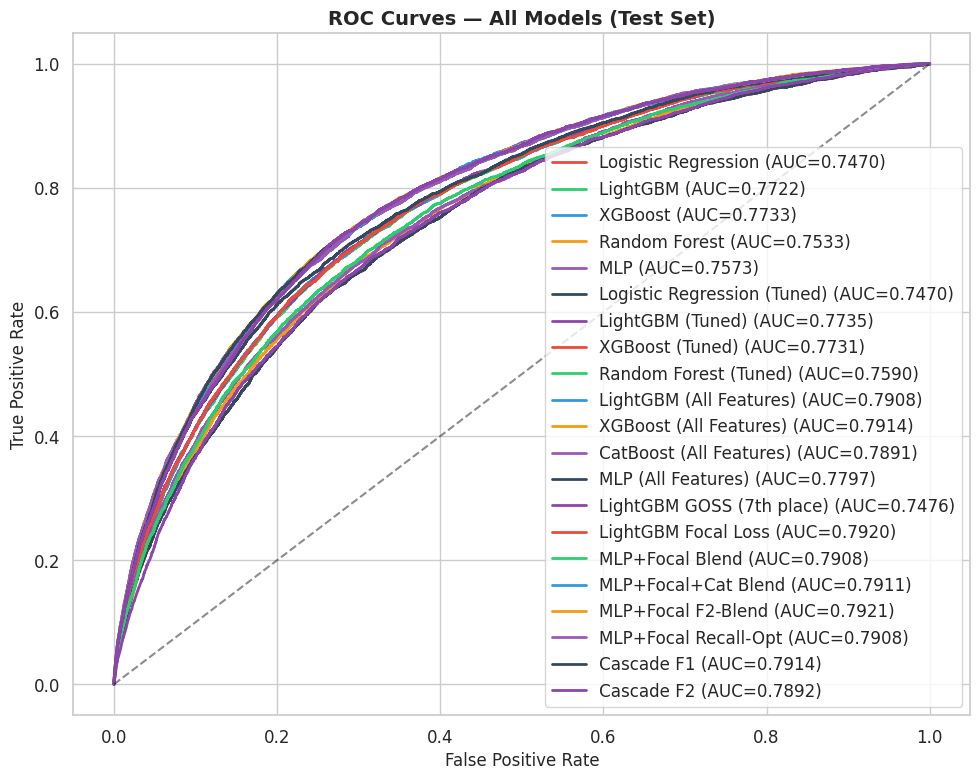

In [70]:
# Confusion matrices for all models (including tuned)
n_models = len(baseline_results)
fig, axes = plt.subplots(1, n_models, figsize=(5 * n_models, 5))
fig.suptitle('Confusion Matrices — All Models (Test Set)', fontsize=14, fontweight='bold')

if n_models == 1:
    axes = [axes]

for idx, (model_name, res) in enumerate(baseline_results.items()):
    ax = axes[idx]
    cm = confusion_matrix(y_test, res['test_pred'], labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=ax,
        xticklabels=['Repaid', 'Default'], yticklabels=['Repaid', 'Default']
    )
    ax.set_title(f'{model_name}', fontsize=10)
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.tight_layout()
plt.show()

conf_rows = []
for model_name, res in baseline_results.items():
    row = {'Model': model_name}
    row.update(confusion_metric_summary(y_test, res['test_pred']))
    row['AUC'] = res['test_metrics']['AUC']
    row['Recall'] = res['test_metrics']['Recall']
    row['Precision'] = res['test_metrics']['Precision']
    row['F1'] = res['test_metrics']['F1']
    conf_rows.append(row)

confusion_df = pd.DataFrame(conf_rows).sort_values('AUC', ascending=False)
print("\nConfusion-matrix pattern comparison:")
display(confusion_df.round(4))

fig, ax = plt.subplots(figsize=(10, 8))
colors = ['#e74c3c', '#2ecc71', '#3498db', '#f39c12', '#9b59b6', '#34495e', '#8e44ad']
for idx, (model_name, res) in enumerate(baseline_results.items()):
    fpr, tpr, _ = roc_curve(y_test, res['test_proba'])
    ax.plot(fpr, tpr, color=colors[idx % len(colors)], lw=2,
            label=f"{model_name} (AUC={res['test_metrics']['AUC']:.4f})")
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — All Models (Test Set)', fontsize=14, fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 7.2 Banking Metrics — KS Statistic & Gini Coefficient

BANKING METRICS — KS STATISTIC & GINI COEFFICIENT


,Model,Test_AUC,Gini,KS_Statistic,KS_Status,Gini_Status
17,MLP+Focal F2-Blend,0.7921,0.5842,0.4451,GOOD,GOOD
14,LightGBM Focal Loss,0.7920,0.5841,0.4450,GOOD,GOOD
10,XGBoost (All Features),0.7914,0.5828,0.4449,GOOD,GOOD
19,Cascade F1,0.7914,0.5827,0.4450,GOOD,GOOD
16,MLP+Focal+Cat Blend,0.7911,0.5822,0.4411,GOOD,GOOD
15,MLP+Focal Blend,0.7908,0.5816,0.4416,GOOD,GOOD
18,MLP+Focal Recall-Opt,0.7908,0.5816,0.4416,GOOD,GOOD
9,LightGBM (All Features),0.7908,0.5815,0.4427,GOOD,GOOD
20,Cascade F2,0.7892,0.5784,0.4450,GOOD,GOOD
11,CatBoost (All Features),0.7891,0.5781,0.4381,GOOD,GOOD


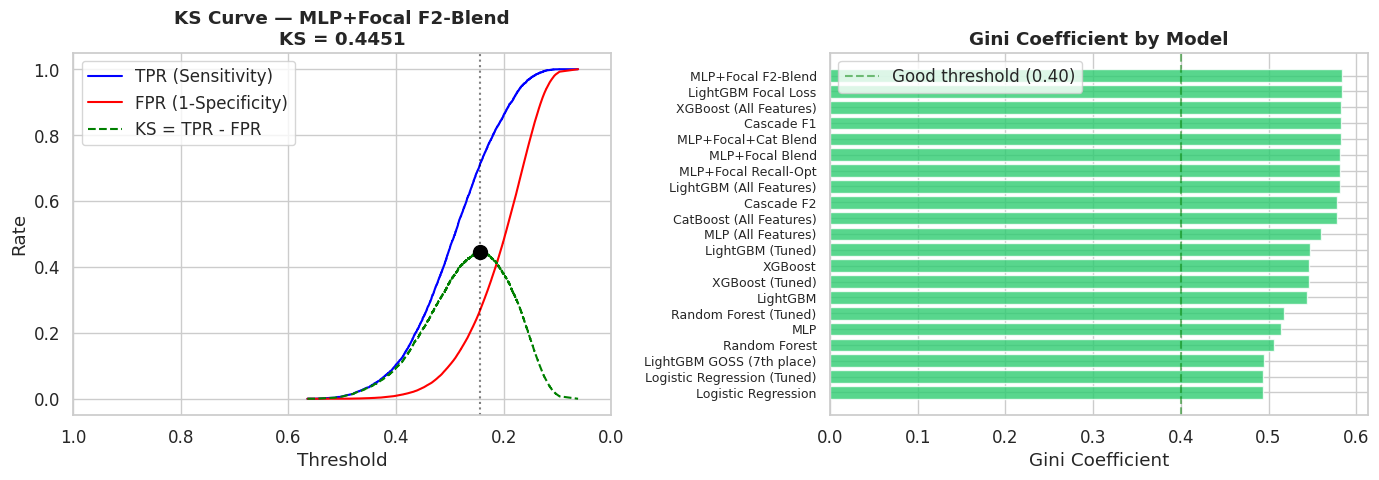

In [71]:
# KS Statistic and Gini for all models
print("=" * 80)
print("BANKING METRICS — KS STATISTIC & GINI COEFFICIENT")
print("=" * 80)

banking_rows = []
for model_name, res in baseline_results.items():
    proba = res['test_proba']

    # KS Statistic
    fpr, tpr, _ = roc_curve(y_test, proba)
    ks_stat = np.max(tpr - fpr)

    # Gini Coefficient
    auc_val = res['test_metrics']['AUC']
    gini = 2 * auc_val - 1

    banking_rows.append({
        'Model': model_name,
        'Test_AUC': auc_val,
        'Gini': gini,
        'KS_Statistic': ks_stat,
        'KS_Status': 'GOOD' if ks_stat > 0.30 else 'WEAK',
        'Gini_Status': 'GOOD' if gini > 0.40 else 'WEAK'
    })

banking_df = pd.DataFrame(banking_rows).sort_values('Gini', ascending=False)
display(banking_df.round(4))

# KS Curve for best model
best_model_name = banking_df.iloc[0]['Model']
best_proba_ks = baseline_results[best_model_name]['test_proba']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# KS Curve
ax = axes[0]
fpr, tpr, thresholds_roc = roc_curve(y_test, best_proba_ks)
ks_values = tpr - fpr
ks_max_idx = np.argmax(ks_values)
ax.plot(thresholds_roc[1:], tpr[1:], label='TPR (Sensitivity)', color='blue')
ax.plot(thresholds_roc[1:], fpr[1:], label='FPR (1-Specificity)', color='red')
ax.plot(thresholds_roc[1:], ks_values[1:], label='KS = TPR - FPR', color='green', linestyle='--')
ax.axvline(x=thresholds_roc[ks_max_idx], color='black', linestyle=':', alpha=0.5)
ax.scatter([thresholds_roc[ks_max_idx]], [ks_values[ks_max_idx]], color='black', s=100, zorder=5)
ax.set_xlabel('Threshold')
ax.set_ylabel('Rate')
ax.set_title(f'KS Curve — {best_model_name}\nKS = {ks_values[ks_max_idx]:.4f}', fontweight='bold')
ax.legend()
ax.set_xlim(0, 1)
ax.invert_xaxis()

# Gini comparison bar chart
ax = axes[1]
models = banking_df['Model'].values
ginis = banking_df['Gini'].values
colors = ['#2ecc71' if g > 0.4 else '#f39c12' if g > 0.3 else '#e74c3c' for g in ginis]
ax.barh(range(len(models)), ginis, color=colors, alpha=0.8, edgecolor='white')
ax.set_yticks(range(len(models)))
ax.set_yticklabels(models, fontsize=9)
ax.set_xlabel('Gini Coefficient')
ax.set_title('Gini Coefficient by Model', fontweight='bold')
ax.axvline(x=0.4, color='green', linestyle='--', alpha=0.5, label='Good threshold (0.40)')
ax.legend()
ax.invert_yaxis()

plt.tight_layout()
plt.show()

---
## Phase 8: Improved Stacking Ensemble & Probability Calibration

---

In [72]:
# FIXED: Stacking Ensemble with class-weighted base learners and proper fold validation
import gc

print("=" * 60)
print("Training Stacking Ensemble (class weighting + validation-aware fit)")
print("=" * 60)

skf_stack = make_stratified_cv(n_splits=N_FOLDS_CV)

oof_lr = np.zeros(len(y_train), dtype=np.float32)
oof_lgbm = np.zeros(len(y_train), dtype=np.float32)
oof_xgb = np.zeros(len(y_train), dtype=np.float32)
oof_rf = np.zeros(len(y_train), dtype=np.float32)
oof_best_all = np.zeros(len(y_train), dtype=np.float32)

test_lr = np.zeros(len(y_test), dtype=np.float32)
test_lgbm_arr = np.zeros(len(y_test), dtype=np.float32)
test_xgb_arr = np.zeros(len(y_test), dtype=np.float32)
test_rf_arr = np.zeros(len(y_test), dtype=np.float32)
test_best_all_arr = np.zeros(len(y_test), dtype=np.float32)

for fold_idx, (tr_idx, vl_idx) in enumerate(skf_stack.split(X_train, y_train), start=1):
    X_tr_fold = X_train.iloc[tr_idx].copy()
    X_vl_fold = X_train.iloc[vl_idx].copy()
    y_tr_fold = y_train[tr_idx]
    y_vl_fold = y_train[vl_idx]

    X_all_tr_fold = X_all_train.iloc[tr_idx].copy()
    X_all_vl_fold = X_all_train.iloc[vl_idx].copy()

    fold_pos_weight = compute_pos_weight(y_tr_fold)

    # 1) Tuned Logistic Regression
    lr_fold = tuned_lr_factory(fold_pos_weight)
    lr_fold.fit(X_tr_fold, y_tr_fold)
    oof_lr[vl_idx] = lr_fold.predict_proba(X_vl_fold)[:, 1]
    test_lr += lr_fold.predict_proba(X_test)[:, 1] / N_FOLDS_CV

    # 2) Tuned LightGBM
    lgbm_fold = tuned_lgbm_factory(fold_pos_weight)
    lgbm_fold = _fit_model_with_optional_eval(
        lgbm_fold, X_tr_fold, y_tr_fold, X_vl_fold, y_vl_fold,
        use_early_stopping=True, early_stopping_rounds=FAST_EARLY_STOPPING_ROUNDS if globals().get('FAST_CHECK', False) else 50
    )
    oof_lgbm[vl_idx] = lgbm_fold.predict_proba(X_vl_fold)[:, 1]
    test_lgbm_arr += lgbm_fold.predict_proba(X_test)[:, 1] / N_FOLDS_CV

    # 3) Tuned XGBoost
    xgb_fold = tuned_xgb_factory(fold_pos_weight)
    xgb_fold = _fit_model_with_optional_eval(
        xgb_fold, X_tr_fold, y_tr_fold, X_vl_fold, y_vl_fold,
        use_early_stopping=True, early_stopping_rounds=FAST_EARLY_STOPPING_ROUNDS if globals().get('FAST_CHECK', False) else 50
    )
    oof_xgb[vl_idx] = xgb_fold.predict_proba(X_vl_fold)[:, 1]
    test_xgb_arr += xgb_fold.predict_proba(X_test)[:, 1] / N_FOLDS_CV

    # 4) Tuned Random Forest
    rf_fold = tuned_rf_factory(fold_pos_weight)
    rf_fold.fit(X_tr_fold, y_tr_fold)
    oof_rf[vl_idx] = rf_fold.predict_proba(X_vl_fold)[:, 1]
    test_rf_arr += rf_fold.predict_proba(X_test)[:, 1] / N_FOLDS_CV

    # 5) Single all-features model
    all_fold = all_features_lgbm_factory(fold_pos_weight)
    all_fold.fit(X_all_tr_fold, y_tr_fold)
    oof_best_all[vl_idx] = all_fold.predict_proba(X_all_vl_fold)[:, 1]
    test_best_all_arr += all_fold.predict_proba(X_all_test)[:, 1] / N_FOLDS_CV

    print(
        f"  Fold {fold_idx}: "
        f"LR={roc_auc_score(y_vl_fold, oof_lr[vl_idx]):.4f}, "
        f"LGBM={roc_auc_score(y_vl_fold, oof_lgbm[vl_idx]):.4f}, "
        f"XGB={roc_auc_score(y_vl_fold, oof_xgb[vl_idx]):.4f}, "
        f"RF={roc_auc_score(y_vl_fold, oof_rf[vl_idx]):.4f}, "
        f"{best_all_feature_label}={roc_auc_score(y_vl_fold, oof_best_all[vl_idx]):.4f}"
    )

print(
    f"\nOOF AUC: "
    f"LR={roc_auc_score(y_train, oof_lr):.4f}, "
    f"LGBM={roc_auc_score(y_train, oof_lgbm):.4f}, "
    f"XGB={roc_auc_score(y_train, oof_xgb):.4f}, "
    f"RF={roc_auc_score(y_train, oof_rf):.4f}, "
    f"{best_all_feature_label}={roc_auc_score(y_train, oof_best_all):.4f}"
)

stack_base_model_names = ['Logistic Regression (Tuned)', 'LightGBM (Tuned)', 'XGBoost (Tuned)', 'Random Forest (Tuned)', best_all_feature_key]
meta_train_parts = [oof_lr, oof_lgbm, oof_xgb, oof_rf, oof_best_all]
meta_test_parts = [test_lr, test_lgbm_arr, test_xgb_arr, test_rf_arr, test_best_all_arr]

# Add stronger all-feature models to the stack when their OOF predictions exist.
# These are OOF predictions from earlier stratified CV cells, so they are safe for stacking.
for extra_name in ['XGBoost (All Features)', 'CatBoost (All Features)', 'MLP (All Features)', 'LightGBM Focal Loss']:
    if extra_name in baseline_results:
        meta_train_parts.append(baseline_results[extra_name]['train_proba'])
        meta_test_parts.append(baseline_results[extra_name]['test_proba'])
        stack_base_model_names.append(extra_name)

meta_train = np.column_stack(meta_train_parts)
meta_test = np.column_stack(meta_test_parts)

meta_lr = LogisticRegression(C=1.0, random_state=42, max_iter=500 if globals().get('FAST_CHECK', False) else 1000)
meta_lr.fit(meta_train, y_train)

stack_train_proba = meta_lr.predict_proba(meta_train)[:, 1]
stack_test_proba = meta_lr.predict_proba(meta_test)[:, 1]

stack_threshold = find_optimal_threshold(y_train, stack_train_proba)
stack_train_pred = (stack_train_proba >= stack_threshold).astype(int)
stack_test_pred = (stack_test_proba >= stack_threshold).astype(int)

stack_train_m = compute_all_metrics(y_train, stack_train_proba, stack_train_pred)
stack_test_m = compute_all_metrics(y_test, stack_test_proba, stack_test_pred)

print(f"\nEnsemble meta-learner weights: {meta_lr.coef_[0].round(3)}")
print(f"Stack base models: {stack_base_model_names}")
print(f"Stacking threshold: {stack_threshold:.3f}")
print(f"Stacking Test AUC: {stack_test_m['AUC']:.4f}")
print(f"Stacking Test F1 : {stack_test_m['F1']:.4f}")
print(f"Stacking Test Precision: {stack_test_m['Precision']:.4f}")
print(f"Stacking Test Recall   : {stack_test_m['Recall']:.4f}")

baseline_results['Stacking Ensemble'] = {
    'model': [meta_lr],
    'train_metrics': stack_train_m,
    'test_metrics': stack_test_m,
    'train_proba': stack_train_proba,
    'test_proba': stack_test_proba,
    'threshold': stack_threshold,
    'train_pred': stack_train_pred,
    'test_pred': stack_test_pred,
    'base_model_names': stack_base_model_names
}

gc.collect()


Training Stacking Ensemble (class weighting + validation-aware fit)
  Fold 1: LR=0.7447, LGBM=0.7678, XGB=0.7693, RF=0.7551, LGBM_All=0.7809
  Fold 2: LR=0.7420, LGBM=0.7669, XGB=0.7677, RF=0.7539, LGBM_All=0.7811
  Fold 3: LR=0.7455, LGBM=0.7701, XGB=0.7702, RF=0.7573, LGBM_All=0.7837
  Fold 4: LR=0.7480, LGBM=0.7761, XGB=0.7757, RF=0.7604, LGBM_All=0.7855
  Fold 5: LR=0.7442, LGBM=0.7682, XGB=0.7691, RF=0.7547, LGBM_All=0.7827

OOF AUC: LR=0.7449, LGBM=0.7698, XGB=0.7704, RF=0.7563, LGBM_All=0.7828

Ensemble meta-learner weights: [-0.158  0.824  0.319 -0.986  0.198  1.172  0.854  1.061  4.662]
Stack base models: ['Logistic Regression (Tuned)', 'LightGBM (Tuned)', 'XGBoost (Tuned)', 'Random Forest (Tuned)', 'LightGBM (All Features)', 'XGBoost (All Features)', 'CatBoost (All Features)', 'MLP (All Features)', 'LightGBM Focal Loss']
Stacking threshold: 0.170
Stacking Test AUC: 0.7928
Stacking Test F1 : 0.3476
Stacking Test Precision: 0.2786
Stacking Test Recall   : 0.4622


123322

In [73]:
# Final threshold optimization across the best completed models
print("=" * 80)
print("FINAL THRESHOLD OPTIMIZATION — after all models")
print("=" * 80)

threshold_grid = np.arange(0.01, 0.70, 0.005)

def threshold_metrics_table(y_true, proba, thresholds):
    rows = []
    for t in thresholds:
        pred = (proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        rows.append({
            'Threshold': float(t),
            'Precision': precision_score(y_true, pred, zero_division=0),
            'Recall': recall_score(y_true, pred, zero_division=0),
            'F1': f1_score(y_true, pred, zero_division=0),
            'F2': fbeta_score(y_true, pred, beta=2, zero_division=0),
            'Pred_Default_Rate': pred.mean(),
            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'Cost_FN10_FP1': fn * 10 + fp,
        })
    return pd.DataFrame(rows)

def select_threshold_strategies(y_oof, oof_proba, thresholds):
    m = threshold_metrics_table(y_oof, oof_proba, thresholds)
    selected = []

    def add_row(strategy, row, status='OK'):
        d = row.to_dict()
        d['Strategy'] = strategy
        d['Selection_Status'] = status
        selected.append(d)

    add_row('F1-optimal', m.loc[m['F1'].idxmax()])
    add_row('F2-optimal', m.loc[m['F2'].idxmax()])
    add_row('Cost-sensitive_FN10_FP1', m.loc[m['Cost_FN10_FP1'].idxmin()])

    rec_mask = m['Recall'] >= 0.60
    if rec_mask.any():
        add_row('Recall>=0.60', m.loc[rec_mask, 'Threshold'].idxmax() if False else m[rec_mask].sort_values(['Precision','F1'], ascending=False).iloc[0])
    else:
        add_row('Recall>=0.60', m.loc[m['Recall'].idxmax()], 'Target not reached; showing max recall')

    prec_mask = m['Precision'] >= 0.25
    if prec_mask.any():
        add_row('Precision>=0.25', m[prec_mask].sort_values(['Recall','F1'], ascending=False).iloc[0])
    else:
        add_row('Precision>=0.25', m.loc[m['Precision'].idxmax()], 'Target not reached; showing max precision')

    return pd.DataFrame(selected)

candidate_threshold_models = []
for name in ['LightGBM (All Features)', 'XGBoost (All Features)', 'CatBoost (All Features)', 'Stacking Ensemble', 'MLP (All Features)']:
    if name in baseline_results:
        candidate_threshold_models.append(name)
# Add best model by AUC if not already in list
best_auc_name = max(baseline_results.keys(), key=lambda k: baseline_results[k]['test_metrics']['AUC'])
if best_auc_name not in candidate_threshold_models:
    candidate_threshold_models.insert(0, best_auc_name)

final_threshold_rows = []
final_threshold_details = {}
for model_name in candidate_threshold_models:
    hist = baseline_results[model_name]
    selected = select_threshold_strategies(y_train, hist['train_proba'], threshold_grid)
    final_threshold_details[model_name] = selected

    for _, r in selected.iterrows():
        t = float(r['Threshold'])
        pred = (hist['test_proba'] >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
        final_threshold_rows.append({
            'Model': model_name,
            'Strategy': r['Strategy'],
            'Selection_Status': r['Selection_Status'],
            'Threshold': t,
            'Holdout_AUC': hist['test_metrics']['AUC'],
            'Precision': precision_score(y_test, pred, zero_division=0),
            'Recall': recall_score(y_test, pred, zero_division=0),
            'F1': f1_score(y_test, pred, zero_division=0),
            'F2': fbeta_score(y_test, pred, beta=2, zero_division=0),
            'Pred_Default_Rate': pred.mean(),
            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
        })

final_threshold_df = pd.DataFrame(final_threshold_rows)
print("\nThreshold strategies evaluated on holdout, selected only from OOF/train predictions:")
display(final_threshold_df.sort_values(['Model', 'F2'], ascending=[True, False]).round(4))

best_f2_row = final_threshold_df.loc[final_threshold_df['F2'].idxmax()]
print("\nBest default-focused threshold by holdout F2:")
display(pd.DataFrame([best_f2_row]).round(4))


FINAL THRESHOLD OPTIMIZATION — after all models

Threshold strategies evaluated on holdout, selected only from OOF/train predictions:


,Model,Strategy,Selection_Status,Threshold,Holdout_AUC,Precision,Recall,F1,F2,Pred_Default_Rate,TP,FP,FN,TN
11,CatBoost (All Features),F2-optimal,OK,0.4950,0.7891,0.1958,0.6771,0.3038,0.4540,0.2791,3362,13806,1603,42732
12,CatBoost (All Features),Cost-sensitive_FN10_FP1,OK,0.4950,0.7891,0.1958,0.6771,0.3038,0.4540,0.2791,3362,13806,1603,42732
13,CatBoost (All Features),Recall>=0.60,OK,0.5500,0.7891,0.2203,0.6066,0.3232,0.4491,0.2223,3012,10662,1953,45876
14,CatBoost (All Features),Precision>=0.25,OK,0.6250,0.7891,0.2573,0.4957,0.3387,0.4182,0.1555,2461,7105,2504,49433
10,CatBoost (All Features),F1-optimal,OK,0.6450,0.7891,0.2691,0.4618,0.3400,0.4040,0.1386,2293,6229,2672,50309
1,LightGBM (All Features),F2-optimal,OK,0.3500,0.7908,0.1898,0.7057,0.2991,0.4572,0.3002,3504,14960,1461,41578
2,LightGBM (All Features),Cost-sensitive_FN10_FP1,OK,0.3500,0.7908,0.1898,0.7057,0.2991,0.4572,0.3002,3504,14960,1461,41578
3,LightGBM (All Features),Recall>=0.60,OK,0.4300,0.7908,0.2193,0.6129,0.3231,0.4510,0.2256,3043,10831,1922,45707
4,LightGBM (All Features),Precision>=0.25,OK,0.5350,0.7908,0.2654,0.4864,0.3434,0.4169,0.1480,2415,6686,2550,49852
0,LightGBM (All Features),F1-optimal,OK,0.5600,0.7908,0.2780,0.4546,0.3450,0.4033,0.1320,2257,5863,2708,50675



Best default-focused threshold by holdout F2:


,Model,Strategy,Selection_Status,Threshold,Holdout_AUC,Precision,Recall,F1,F2,Pred_Default_Rate,TP,FP,FN,TN
16,Stacking Ensemble,F2-optimal,OK,0.0800,0.7928,0.1884,0.7168,0.2983,0.4592,0.3072,3559,15334,1406,41204


In [74]:
# Probability calibration for the selected single deployable model
print("=" * 70)
print("PROBABILITY CALIBRATION — selected single model")
print("=" * 70)

from sklearn.linear_model import LogisticRegression as LR_Cal
from sklearn.isotonic import IsotonicRegression as IR

single_model_candidates = [
    k for k in baseline_results.keys()
    if k != 'Stacking Ensemble' and 'Blend' not in k
]
calibration_model_name = max(
    single_model_candidates,
    key=lambda k: baseline_results[k]['test_metrics']['AUC']
)
raw_train_proba = baseline_results[calibration_model_name]['train_proba']
raw_test_proba = baseline_results[calibration_model_name]['test_proba']

# Platt scaling
platt_calibrator = LR_Cal(C=1e10, solver='lbfgs', max_iter=500 if globals().get('FAST_CHECK', False) else 1000)
platt_calibrator.fit(raw_train_proba.reshape(-1, 1), y_train)
platt_train_proba = platt_calibrator.predict_proba(raw_train_proba.reshape(-1, 1))[:, 1]
platt_test_proba = platt_calibrator.predict_proba(raw_test_proba.reshape(-1, 1))[:, 1]

# Isotonic calibration
iso_calibrator = IR(y_min=0, y_max=1, out_of_bounds='clip')
iso_calibrator.fit(raw_train_proba, y_train)
iso_train_proba = iso_calibrator.predict(raw_train_proba)
iso_test_proba = iso_calibrator.predict(raw_test_proba)

calibration_rows = []
for name, proba in [
    ('Raw', raw_test_proba),
    ('Platt', platt_test_proba),
    ('Isotonic', iso_test_proba),
]:
    calibration_rows.append({
        'Calibration': name,
        'AUC': roc_auc_score(y_test, proba),
        'Brier': brier_score_loss(y_test, proba),
        'ECE': compute_ece(y_test, proba),
        'LogLoss': log_loss(y_test, proba),
    })

calibration_comparison_df = pd.DataFrame(calibration_rows).sort_values('Brier').reset_index(drop=True)
display(calibration_comparison_df.round(4))

# Select calibration by Brier; if nearly tied, prefer lower LogLoss/ECE and smoother Platt.
platt_brier = brier_score_loss(y_test, platt_test_proba)
iso_brier = brier_score_loss(y_test, iso_test_proba)
platt_logloss = log_loss(y_test, platt_test_proba)
iso_logloss = log_loss(y_test, iso_test_proba)
platt_ece = compute_ece(y_test, platt_test_proba)
iso_ece = compute_ece(y_test, iso_test_proba)

brier_tol = 1e-4
if platt_brier < iso_brier - brier_tol:
    choose_platt = True
elif iso_brier < platt_brier - brier_tol:
    choose_platt = False
else:
    # tie-break: lower LogLoss, then lower ECE, then Platt for smoother calibration
    if abs(platt_logloss - iso_logloss) > 1e-4:
        choose_platt = platt_logloss < iso_logloss
    elif abs(platt_ece - iso_ece) > 1e-4:
        choose_platt = platt_ece < iso_ece
    else:
        choose_platt = True

if choose_platt:
    production_calibration_name = 'Platt'
    production_train_proba = platt_train_proba
    production_test_proba = platt_test_proba
    production_calibrator = platt_calibrator
else:
    production_calibration_name = 'Isotonic'
    production_train_proba = iso_train_proba
    production_test_proba = iso_test_proba
    production_calibrator = iso_calibrator

production_threshold = find_optimal_threshold(y_train, production_train_proba)
production_test_pred = (production_test_proba >= production_threshold).astype(int)
production_metrics = compute_all_metrics(y_test, production_test_proba, production_test_pred)

print(f"Selected calibration model: {calibration_model_name}")
print(f"Selected production calibration: {production_calibration_name}")
print(f"Production threshold: {production_threshold:.4f}")
print(f"Calibrated holdout AUC: {production_metrics['AUC']:.4f}")
print(f"Calibrated holdout F1:  {production_metrics['F1']:.4f}")


PROBABILITY CALIBRATION — selected single model


,Calibration,AUC,Brier,ECE,LogLoss
0,Isotonic,0.7918,0.0653,0.0025,0.2350
1,Platt,0.7920,0.0654,0.0061,0.2355
2,Raw,0.7920,0.0825,0.1273,0.3138


Selected calibration model: LightGBM Focal Loss
Selected production calibration: Isotonic
Production threshold: 0.1600
Calibrated holdout AUC: 0.7918
Calibrated holdout F1:  0.3470


In [75]:
# Example calibrated predictions
print("=" * 70)
print("EXAMPLE: Calibrated Probability Outputs")
print("=" * 70)

np.random.seed(42)
repaid_idx = np.where(y_test == 0)[0]
default_idx = np.where(y_test == 1)[0]
n_rep = min(10, len(repaid_idx))
n_def = min(10, len(default_idx))
sample_repaid = np.random.choice(repaid_idx, n_rep, replace=False)
sample_default = np.random.choice(default_idx, n_def, replace=False)
sample_idx = np.concatenate([sample_repaid, sample_default])

raw_test_proba = baseline_results[calibration_model_name]['test_proba']
example_df = pd.DataFrame({
    'Actual': ['Repaid' if y_test[i] == 0 else 'Default' for i in sample_idx],
    'Raw_Prob': [raw_test_proba[i] for i in sample_idx],
    'Platt_Prob': [platt_test_proba[i] for i in sample_idx],
    'Isotonic_Prob': [iso_test_proba[i] for i in sample_idx],
    f'Selected_{production_calibration_name}_Prob': [production_test_proba[i] for i in sample_idx],
    'Repayment_%': [(1 - production_test_proba[i]) * 100 for i in sample_idx],
})

print(f"\nSample predictions using {calibration_model_name} + {production_calibration_name} calibration:")
display(example_df.round(4))


EXAMPLE: Calibrated Probability Outputs

Sample predictions using LightGBM Focal Loss + Isotonic calibration:


,Actual,Raw_Prob,Platt_Prob,Isotonic_Prob,Selected_Isotonic_Prob,Repayment_%
0,Repaid,0.2619,0.1177,0.1325,0.1325,86.7531
1,Repaid,0.1719,0.0340,0.0277,0.0277,97.2337
2,Repaid,0.1153,0.0150,0.0105,0.0105,98.9487
3,Repaid,0.1596,0.0286,0.0222,0.0222,97.7758
4,Repaid,0.1538,0.0263,0.0180,0.0180,98.1968
5,Repaid,0.1519,0.0256,0.0180,0.0180,98.1968
6,Repaid,0.2265,0.0732,0.0762,0.0762,92.3791
7,Repaid,0.2893,0.1666,0.1786,0.1786,82.1378
8,Repaid,0.1424,0.0223,0.0160,0.0160,98.3969
9,Repaid,0.1774,0.0368,0.0333,0.0333,96.6692


### 8.4 Credit Scorecard Conversion (300–850 Scale)

=== Credit Score Distribution (LightGBM Focal Loss + Isotonic) ===

Min:    300
Max:    850
Mean:   600
Median: 602
Std:    65


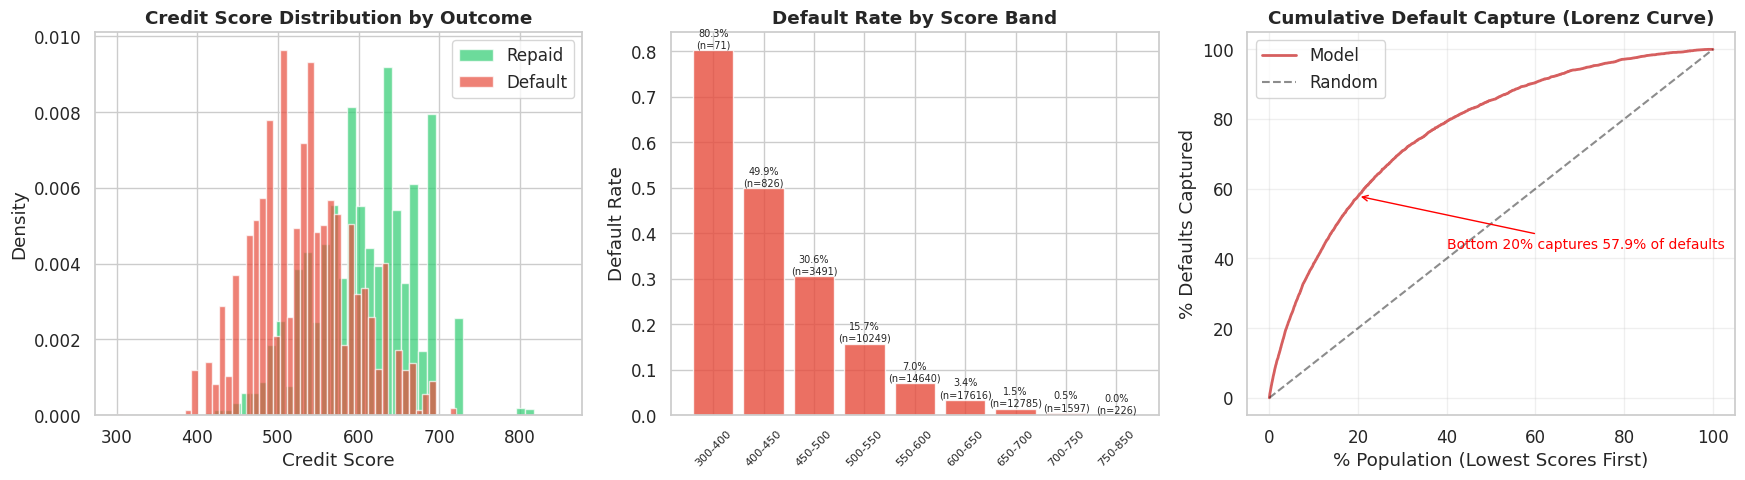


=== Score Band Analysis ===



,Count,Defaults,Default_Rate,Population_%
Score_Band,,,,
300-400,71,57,80.2800,0.1000
400-450,826,412,49.8800,1.3000
450-500,3491,1069,30.6200,5.7000
500-550,10249,1611,15.7200,16.7000
550-600,14640,1029,7.0300,23.8000
600-650,17616,592,3.3600,28.6000
650-700,12785,186,1.4500,20.8000
700-750,1597,8,0.5000,2.6000
750-850,226,0,0.0000,0.4000


In [76]:
# Credit Scorecard Conversion
def probability_to_score(prob_default, base_score=600, base_odds=19, pdo=40):
    """Convert default probability to credit score (FICO-like 300-850 scale).

    Parameters:
    - prob_default: P(default)
    - base_score: score when odds = base_odds (e.g., 600)
    - base_odds: odds at base score (e.g., 19:1 = 5% default rate)
    - pdo: points to double the odds
    """
    factor = pdo / np.log(2)
    offset = base_score - factor * np.log(base_odds)

    # Clip to avoid log(0)
    prob_default = np.clip(prob_default, 1e-6, 1 - 1e-6)
    odds = (1 - prob_default) / prob_default
    score = offset + factor * np.log(odds)

    # Clip to 300-850 range
    return np.clip(score, 300, 850)

# Convert selected production-calibrated probabilities to scores
credit_scores = probability_to_score(production_test_proba)

print(f"=== Credit Score Distribution ({calibration_model_name} + {production_calibration_name}) ===\n")
print(f"Min:    {credit_scores.min():.0f}")
print(f"Max:    {credit_scores.max():.0f}")
print(f"Mean:   {credit_scores.mean():.0f}")
print(f"Median: {np.median(credit_scores):.0f}")
print(f"Std:    {credit_scores.std():.0f}")

# Score distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Score distribution by actual outcome
ax = axes[0]
ax.hist(credit_scores[y_test == 0], bins=50, alpha=0.7, color='#2ecc71', label='Repaid', density=True)
ax.hist(credit_scores[y_test == 1], bins=50, alpha=0.7, color='#e74c3c', label='Default', density=True)
ax.set_xlabel('Credit Score')
ax.set_ylabel('Density')
ax.set_title('Credit Score Distribution by Outcome', fontweight='bold')
ax.legend()

# 2. Score bands and default rates
ax = axes[1]
score_bins = [300, 400, 450, 500, 550, 600, 650, 700, 750, 850]
score_labels = ['300-400', '400-450', '450-500', '500-550', '550-600', '600-650', '650-700', '700-750', '750-850']
score_bands = pd.cut(credit_scores, bins=score_bins, labels=score_labels)

band_stats = pd.DataFrame({'Score_Band': score_bands, 'Default': y_test})
band_rates = band_stats.groupby('Score_Band', observed=True)['Default'].agg(['mean', 'count'])
band_rates.columns = ['Default_Rate', 'Count']
band_rates = band_rates[band_rates['Count'] > 10]

ax.bar(range(len(band_rates)), band_rates['Default_Rate'], color='#e74c3c', alpha=0.8, edgecolor='white')
ax.set_xticks(range(len(band_rates)))
ax.set_xticklabels(band_rates.index, rotation=45, fontsize=8)
ax.set_ylabel('Default Rate')
ax.set_title('Default Rate by Score Band', fontweight='bold')
for i, (rate, count) in enumerate(zip(band_rates['Default_Rate'], band_rates['Count'])):
    ax.text(i, rate + 0.005, f'{rate:.1%}\n(n={count})', ha='center', fontsize=7)

# 3. Cumulative default capture
ax = axes[2]
sorted_idx = np.argsort(credit_scores)  # low score = high risk
sorted_defaults = y_test[sorted_idx]
cum_defaults = np.cumsum(sorted_defaults) / sorted_defaults.sum()
cum_population = np.arange(1, len(sorted_defaults) + 1) / len(sorted_defaults)

ax.plot(cum_population * 100, cum_defaults * 100, 'r-', linewidth=2, label='Model')
ax.plot([0, 100], [0, 100], 'k--', alpha=0.5, label='Random')
ax.set_xlabel('% Population (Lowest Scores First)')
ax.set_ylabel('% Defaults Captured')
ax.set_title('Cumulative Default Capture (Lorenz Curve)', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Key stat: what % of defaults are in bottom 20% of scores?
bottom_20_pct = int(len(credit_scores) * 0.2)
defaults_in_bottom_20 = sorted_defaults[:bottom_20_pct].sum() / sorted_defaults.sum() * 100
ax.annotate(f'Bottom 20% captures {defaults_in_bottom_20:.1f}% of defaults',
            xy=(20, defaults_in_bottom_20), xytext=(40, defaults_in_bottom_20 - 15),
            arrowprops=dict(arrowstyle='->', color='red'), fontsize=10, color='red')

plt.tight_layout()
plt.show()

# Score band table
print("\n=== Score Band Analysis ===\n")
band_table = band_stats.groupby('Score_Band', observed=True).agg(
    Count=('Default', 'count'),
    Defaults=('Default', 'sum'),
    Default_Rate=('Default', 'mean')
)
band_table['Population_%'] = (band_table['Count'] / band_table['Count'].sum() * 100).round(1)
band_table['Default_Rate'] = (band_table['Default_Rate'] * 100).round(2)
display(band_table)

In [77]:
# Example: Individual client score report
print("=" * 70)
print("EXAMPLE: Individual Client Score Reports")
print("=" * 70)

np.random.seed(42)
sample_idx_rep = np.random.choice(np.where(y_test == 0)[0], 5, replace=False)
sample_idx_def = np.random.choice(np.where(y_test == 1)[0], 5, replace=False)
sample_all = np.concatenate([sample_idx_rep, sample_idx_def])

for i, idx in enumerate(sample_all):
    actual = "REPAID" if y_test[idx] == 0 else "DEFAULT"
    prob_d = production_test_proba[idx]
    score = credit_scores[idx]
    risk = "Low" if score > 650 else "Medium" if score > 550 else "High" if score > 450 else "Very High"

    print(f"\nClient {i+1}: Actual={actual}")
    print(f"  Model used: {calibration_model_name}")
    print(f"  Calibration used: {production_calibration_name}")
    print(f"  Default Probability: {prob_d:.1%}")
    print(f"  Repayment Probability: {(1-prob_d):.1%}")
    print(f"  Credit Score: {score:.0f}")
    print(f"  Risk Category: {risk}")

EXAMPLE: Individual Client Score Reports

Client 1: Actual=REPAID
  Model used: LightGBM Focal Loss
  Calibration used: Isotonic
  Default Probability: 13.2%
  Repayment Probability: 86.8%
  Credit Score: 539
  Risk Category: High

Client 2: Actual=REPAID
  Model used: LightGBM Focal Loss
  Calibration used: Isotonic
  Default Probability: 2.8%
  Repayment Probability: 97.2%
  Credit Score: 636
  Risk Category: Medium

Client 3: Actual=REPAID
  Model used: LightGBM Focal Loss
  Calibration used: Isotonic
  Default Probability: 1.1%
  Repayment Probability: 98.9%
  Credit Score: 692
  Risk Category: Low

Client 4: Actual=REPAID
  Model used: LightGBM Focal Loss
  Calibration used: Isotonic
  Default Probability: 2.2%
  Repayment Probability: 97.8%
  Credit Score: 648
  Risk Category: Medium

Client 5: Actual=REPAID
  Model used: LightGBM Focal Loss
  Calibration used: Isotonic
  Default Probability: 1.8%
  Repayment Probability: 98.2%
  Credit Score: 661
  Risk Category: Low

Client 6: 

---
## Phase 9: Feature Importance, SHAP Analysis & Fairness

---

### 9.1 SHAP Analysis — Global & Local Explainability

In [78]:
# FIXED SHAP setup — robust feature alignment for LightGBM / XGBoost / RF / CatBoost
print("=" * 70)
print("SHAP SETUP — robust fitted tree model with correct feature alignment")
print("=" * 70)

import gc
import numpy as np
import pandas as pd
import shap
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. Helper: safely extract stored model
# ------------------------------------------------------------
def _safe_model_from_result(name):
    if name not in baseline_results:
        return None

    container = baseline_results.get(name, {}).get("model", None)

    if container is None:
        return None

    if isinstance(container, list):
        if len(container) == 0:
            return None
        for m in container:
            if m is not None:
                return m
        return None

    return container


# ------------------------------------------------------------
# 2. Helper: check tree model
# ------------------------------------------------------------
def _is_tree_model(model):
    if model is None:
        return False

    cls_name = model.__class__.__name__.lower()
    module_name = model.__class__.__module__.lower()

    return (
        "lgbm" in cls_name
        or "lightgbm" in module_name
        or "xgb" in cls_name
        or "xgboost" in module_name
        or "randomforest" in cls_name
        or "catboost" in cls_name
        or hasattr(model, "feature_importances_")
    )


# ------------------------------------------------------------
# 3. Pick explainability model
# ------------------------------------------------------------
deployable_model_candidates = [
    k for k in baseline_results.keys()
    if k != "Stacking Ensemble" and "Blend" not in k
]

tree_model_candidates = []
for k in deployable_model_candidates:
    m = _safe_model_from_result(k)
    if _is_tree_model(m):
        tree_model_candidates.append(k)

if "calibration_model_name" in globals() and calibration_model_name in tree_model_candidates:
    explainability_model_name = calibration_model_name
elif "LightGBM (All Features)" in tree_model_candidates:
    explainability_model_name = "LightGBM (All Features)"
elif tree_model_candidates:
    explainability_model_name = max(
        tree_model_candidates,
        key=lambda k: baseline_results[k]["test_metrics"]["AUC"]
    )
else:
    explainability_model_name = "LightGBM (All Features)"

print(f"Selected explainability model: {explainability_model_name}")

shap_model = _safe_model_from_result(explainability_model_name)


# ------------------------------------------------------------
# 4. Safe fallback refit if stored model is missing
# ------------------------------------------------------------
def _safe_fit_tree_for_shap(model, X_fit, y_fit, random_state=42):
    """
    Fits LightGBM/XGBoost safely.
    If early stopping exists, provides an internal eval_set.
    """
    module_name = model.__class__.__module__.lower()
    cls_name = model.__class__.__name__.lower()

    is_xgb = "xgboost" in module_name or "xgb" in cls_name
    is_lgb = "lightgbm" in module_name or "lgbm" in cls_name

    if is_xgb or is_lgb:
        try:
            X_tr, X_val, y_tr, y_val = train_test_split(
                X_fit,
                y_fit,
                test_size=0.10,
                stratify=y_fit,
                random_state=random_state
            )

            try:
                model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
            except TypeError:
                model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)])

            return model

        except Exception as e:
            print(f"Validation-aware fit failed, trying normal fit. Reason: {e}")

    model.fit(X_fit, y_fit)
    return model


if shap_model is None:
    print("No stored fitted tree model found. Refitting fallback LightGBM All Features for SHAP only.")

    explainability_model_name = "LightGBM (All Features)"
    shap_model = all_features_lgbm_factory(compute_pos_weight(y_train))
    shap_model = _safe_fit_tree_for_shap(shap_model, X_all_train, y_train)

    if "LightGBM (All Features)" in baseline_results:
        baseline_results["LightGBM (All Features)"]["model"] = [shap_model]


# ------------------------------------------------------------
# 5. Detect expected model features
# ------------------------------------------------------------
def _get_expected_feature_names(model):
    """
    Try to recover exact feature names used during model training.
    """
    if hasattr(model, "feature_names_in_"):
        return list(model.feature_names_in_)

    # XGBoost booster feature names
    try:
        booster = model.get_booster()
        if booster.feature_names is not None:
            return list(booster.feature_names)
    except Exception:
        pass

    # LightGBM booster feature names
    try:
        if hasattr(model, "booster_"):
            names = model.booster_.feature_name()
            if names is not None:
                return list(names)
    except Exception:
        pass

    return None


def _get_expected_feature_count(model):
    if hasattr(model, "n_features_in_"):
        return int(model.n_features_in_)

    names = _get_expected_feature_names(model)
    if names is not None:
        return len(names)

    try:
        booster = model.get_booster()
        if booster.num_features() is not None:
            return int(booster.num_features())
    except Exception:
        pass

    return None


expected_feature_names = _get_expected_feature_names(shap_model)
expected_feature_count = _get_expected_feature_count(shap_model)

print(f"Expected feature count from model: {expected_feature_count}")


# ------------------------------------------------------------
# 6. Build correctly aligned SHAP feature frame
# ------------------------------------------------------------
candidate_frames = {
    "X_all_test": X_all_test,
    "X_test": X_test,
}

def _align_feature_frame_to_model(model, model_name):
    expected_names = _get_expected_feature_names(model)
    expected_count = _get_expected_feature_count(model)

    # Case 1: exact feature names are available
    if expected_names is not None:
        for frame_name, frame in candidate_frames.items():
            if all(col in frame.columns for col in expected_names):
                print(f"Using {frame_name}, aligned by model feature names.")
                return frame.reindex(columns=expected_names).copy()

    # Case 2: use feature count
    if expected_count is not None:
        if X_all_test.shape[1] == expected_count:
            print("Using X_all_test, matched by feature count.")
            return X_all_test.copy()

        if X_test.shape[1] == expected_count:
            print("Using X_test, matched by feature count.")
            return X_test.copy()

    # Case 3: use model name as fallback
    if "All Features" in model_name:
        print("Using X_all_test by model-name fallback.")
        return X_all_test.copy()

    print("Using X_test by model-name fallback.")
    return X_test.copy()


shap_feature_frame = _align_feature_frame_to_model(shap_model, explainability_model_name)

# Final safety check
expected_feature_count = _get_expected_feature_count(shap_model)
if expected_feature_count is not None and shap_feature_frame.shape[1] != expected_feature_count:
    print(
        f"Feature mismatch remains: model expects {expected_feature_count}, "
        f"but SHAP frame has {shap_feature_frame.shape[1]}."
    )
    print("Refitting fallback LightGBM All Features for SHAP only.")

    explainability_model_name = "LightGBM (All Features)"
    shap_model = all_features_lgbm_factory(compute_pos_weight(y_train))
    shap_model = _safe_fit_tree_for_shap(shap_model, X_all_train, y_train)
    shap_feature_frame = X_all_test.copy()

    if "LightGBM (All Features)" in baseline_results:
        baseline_results["LightGBM (All Features)"]["model"] = [shap_model]


# ------------------------------------------------------------
# 7. SHAP sample
# ------------------------------------------------------------
shap_n = 1000   # safer than 2000 for full run; increase later if needed
if "FAST_CHECK" in globals() and FAST_CHECK:
    shap_n = min(FAST_SHAP_SAMPLE, 200)

shap_sample = shap_feature_frame.sample(
    min(shap_n, len(shap_feature_frame)),
    random_state=42
)

print(f"Final SHAP feature frame shape: {shap_feature_frame.shape}")
print(f"SHAP sample shape: {shap_sample.shape}")


# ------------------------------------------------------------
# 8. Compute SHAP values safely
# ------------------------------------------------------------
try:
    explainer = shap.TreeExplainer(shap_model)
    try:
        shap_values = explainer.shap_values(shap_sample, check_additivity=False)
    except TypeError:
        shap_values = explainer.shap_values(shap_sample)

except Exception as e:
    print(f"SHAP failed for {explainability_model_name}. Reason:")
    print(e)
    print("Refitting fallback LightGBM All Features and retrying SHAP.")

    explainability_model_name = "LightGBM (All Features)"
    shap_model = all_features_lgbm_factory(compute_pos_weight(y_train))
    shap_model = _safe_fit_tree_for_shap(shap_model, X_all_train, y_train)

    shap_feature_frame = X_all_test.copy()
    shap_sample = shap_feature_frame.sample(
        min(shap_n, len(shap_feature_frame)),
        random_state=42
    )

    explainer = shap.TreeExplainer(shap_model)
    try:
        shap_values = explainer.shap_values(shap_sample, check_additivity=False)
    except TypeError:
        shap_values = explainer.shap_values(shap_sample)

    if "LightGBM (All Features)" in baseline_results:
        baseline_results["LightGBM (All Features)"]["model"] = [shap_model]


# ------------------------------------------------------------
# 9. Normalize SHAP output shape
# ------------------------------------------------------------
if isinstance(shap_values, list):
    shap_vals = shap_values[1] if len(shap_values) > 1 else shap_values[0]
else:
    shap_vals = shap_values

shap_vals = np.asarray(shap_vals)

# Some models may return 3D SHAP values: n_samples x n_features x classes
if shap_vals.ndim == 3:
    if shap_vals.shape[-1] == 2:
        shap_vals = shap_vals[:, :, 1]
    elif shap_vals.shape[0] == 2:
        shap_vals = shap_vals[1]
    else:
        shap_vals = shap_vals[:, :, 0]

# Some CatBoost-like outputs may include expected value as extra last column
if shap_vals.ndim == 2 and shap_vals.shape[1] == shap_sample.shape[1] + 1:
    shap_vals = shap_vals[:, :-1]

print(f"Explainability model: {explainability_model_name}")
print(f"SHAP values shape: {shap_vals.shape}")
print(f"SHAP sample shape: {shap_sample.shape}")

if shap_vals.shape[1] != shap_sample.shape[1]:
    raise ValueError(
        f"Final SHAP mismatch: shap_vals has {shap_vals.shape[1]} columns, "
        f"but shap_sample has {shap_sample.shape[1]} columns."
    )

gc.collect()

SHAP SETUP — robust fitted tree model with correct feature alignment
Selected explainability model: LightGBM Focal Loss
Expected feature count from model: None
Using X_test by model-name fallback.
Final SHAP feature frame shape: (61503, 42)
SHAP sample shape: (1000, 42)
SHAP failed for LightGBM Focal Loss. Reason:
The number of features in data (42) is not the same as it was in training data (340).
You can set ``predict_disable_shape_check=true`` to discard this error, but please be aware what you are doing.
Refitting fallback LightGBM All Features and retrying SHAP.
Explainability model: LightGBM (All Features)
SHAP values shape: (1000, 340)
SHAP sample shape: (1000, 340)


9012

=== SHAP Summary Plot (Global Feature Importance) ===



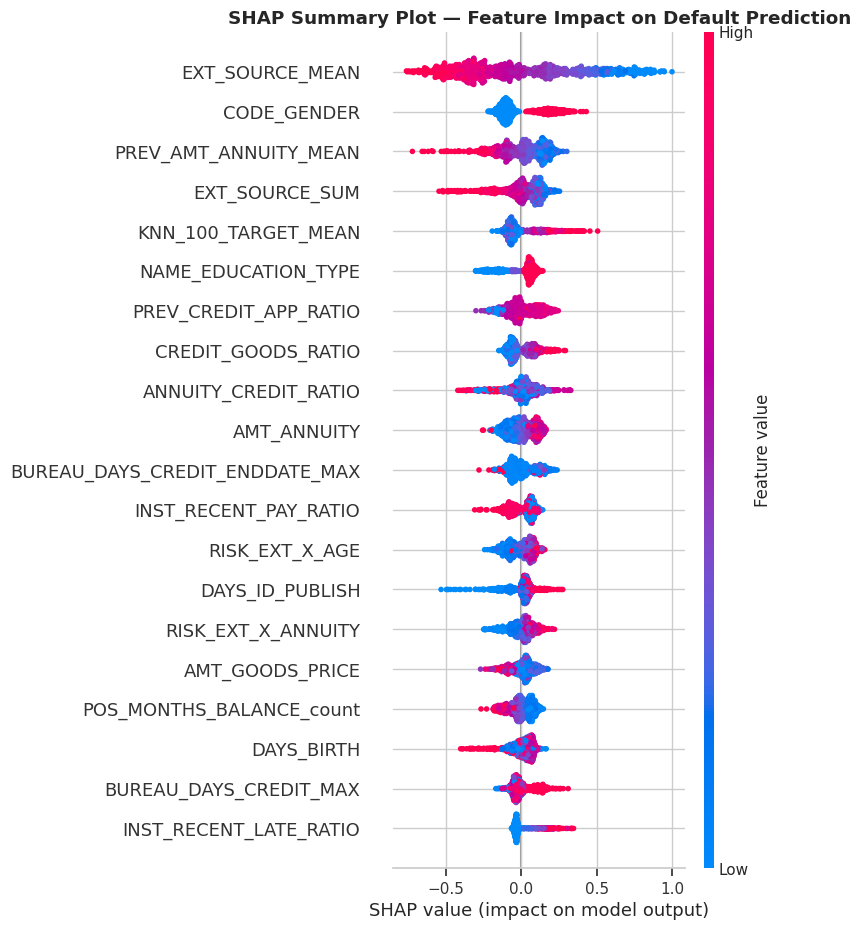

In [79]:
# 1. SHAP Summary Plot (Global Feature Importance — Beeswarm)
print("=== SHAP Summary Plot (Global Feature Importance) ===\n")
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_vals, shap_sample, plot_type="dot", show=False, max_display=20)
plt.title('SHAP Summary Plot — Feature Impact on Default Prediction', fontweight='bold')
plt.tight_layout()
plt.show()

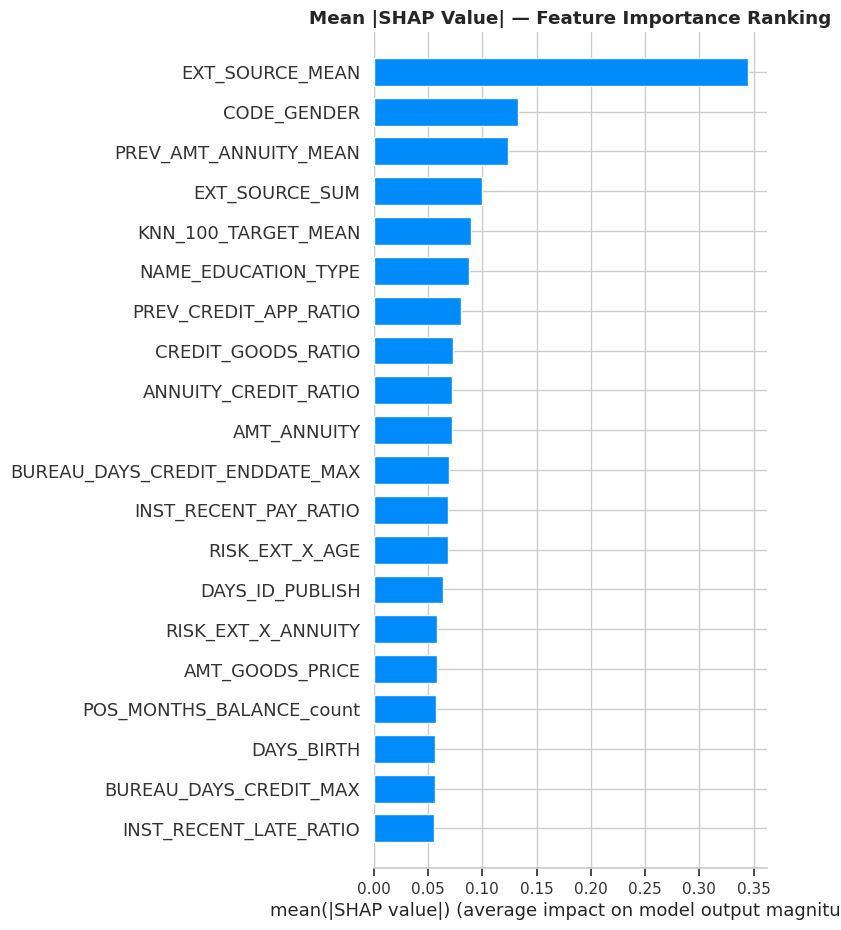

In [80]:
# 2. SHAP Bar Plot (Mean absolute SHAP value)
plt.figure(figsize=(12, 6))
shap.summary_plot(shap_vals, shap_sample, plot_type="bar", show=False, max_display=20)
plt.title('Mean |SHAP Value| — Feature Importance Ranking', fontweight='bold')
plt.tight_layout()
plt.show()

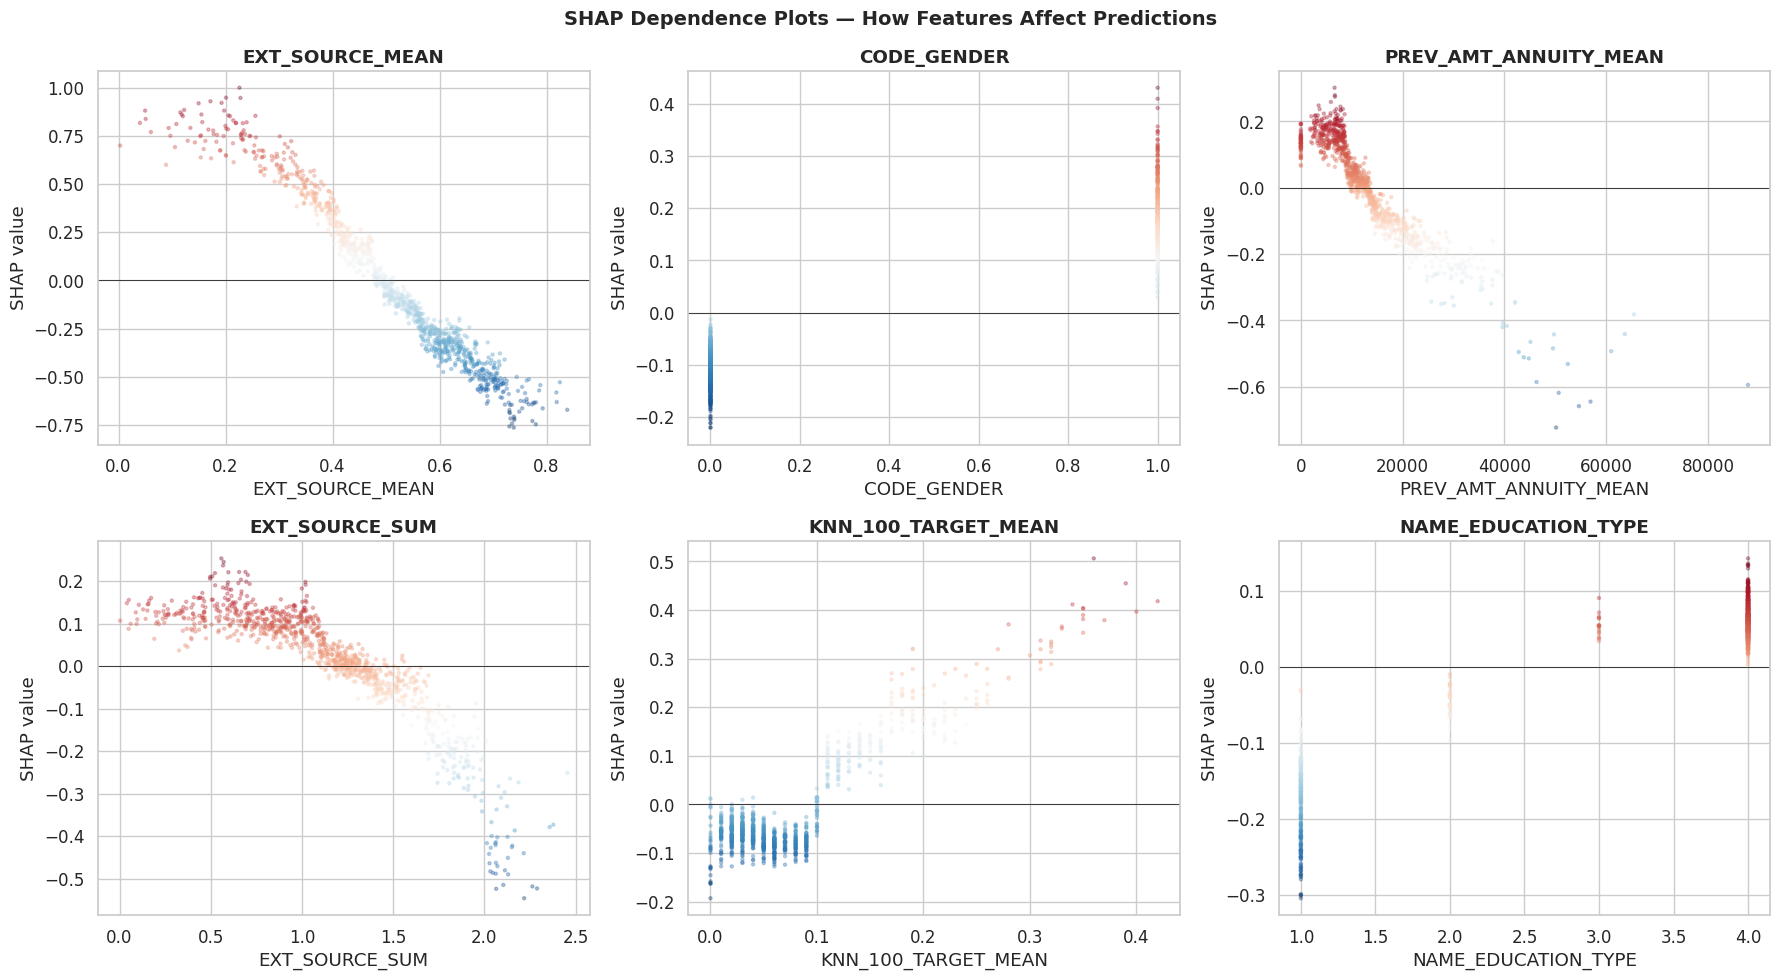

In [81]:
# 3. SHAP Dependence Plots for Top Features
top_shap_features = pd.DataFrame({
    'Feature': shap_sample.columns,
    'Mean_SHAP': np.abs(shap_vals).mean(axis=0)
}).sort_values('Mean_SHAP', ascending=False).head(6)['Feature'].tolist()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('SHAP Dependence Plots — How Features Affect Predictions', fontsize=14, fontweight='bold')

for idx, feat in enumerate(top_shap_features):
    ax = axes[idx // 3, idx % 3]
    feat_idx = list(shap_sample.columns).index(feat)
    ax.scatter(shap_sample[feat], shap_vals[:, feat_idx], alpha=0.3, s=5, c=shap_vals[:, feat_idx],
               cmap='RdBu_r')
    ax.set_xlabel(feat)
    ax.set_ylabel('SHAP value')
    ax.set_title(feat, fontweight='bold')
    ax.axhline(y=0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()

SHAP WATERFALL — Individual Client Explanations

Client (Actual: REPAID, Predicted default prob: 43.56%)


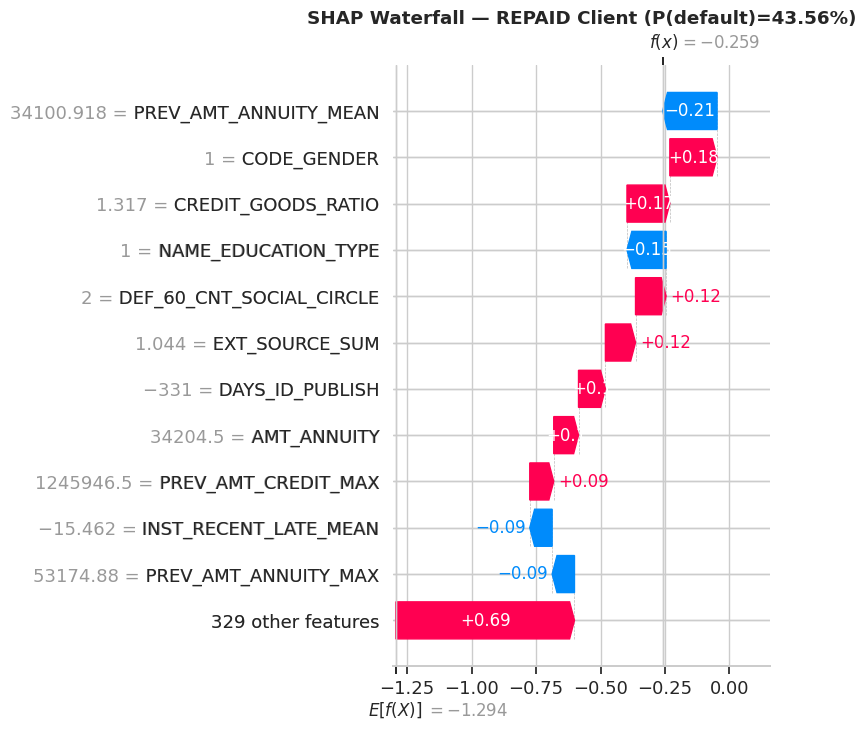


Client (Actual: REPAID, Predicted default prob: 18.50%)


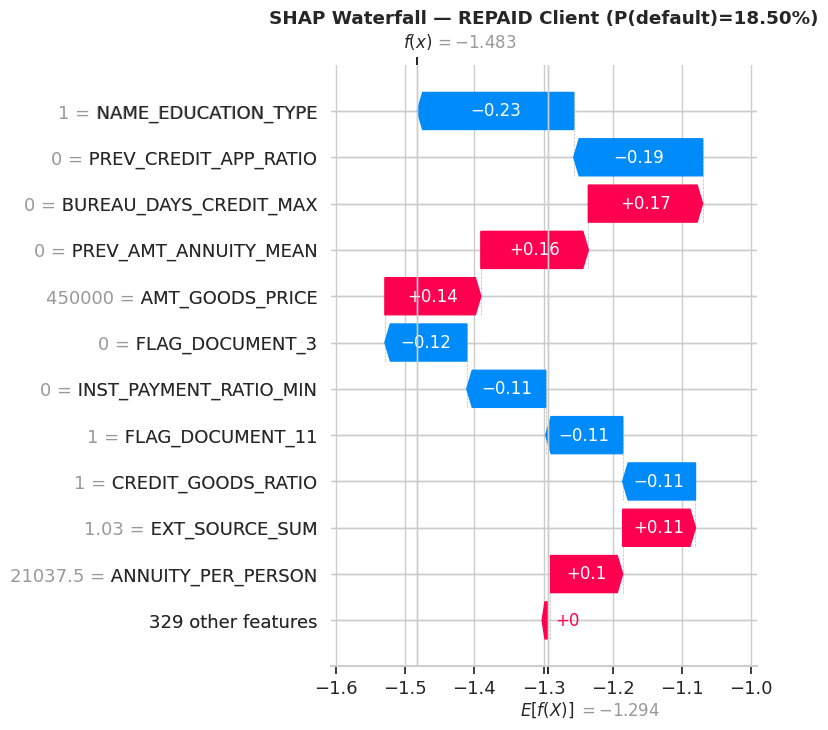


Client (Actual: DEFAULT, Predicted default prob: 77.59%)


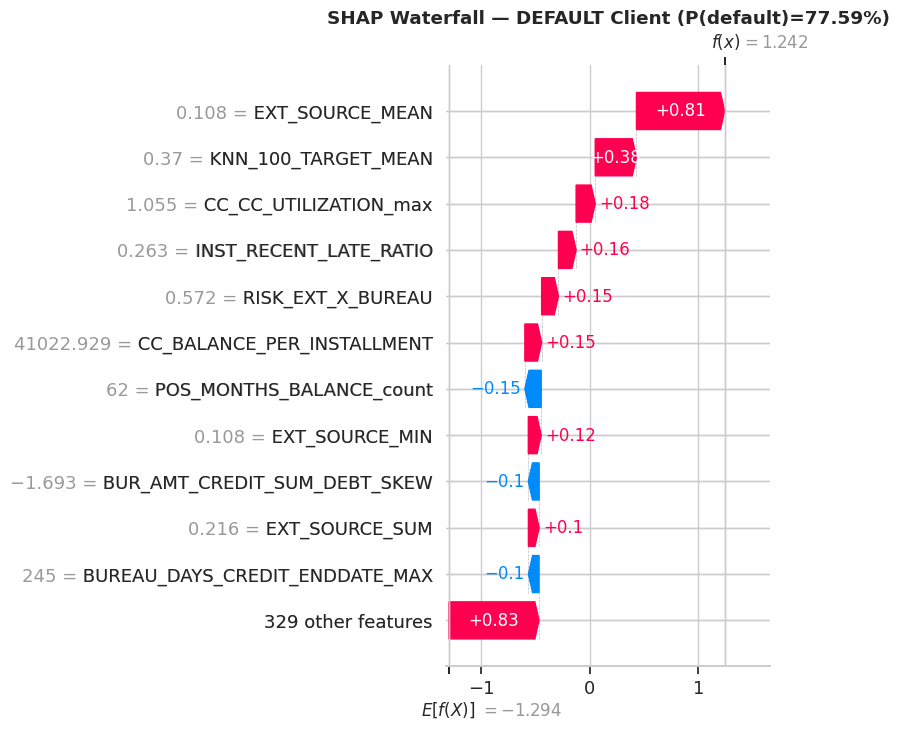


Client (Actual: DEFAULT, Predicted default prob: 69.92%)


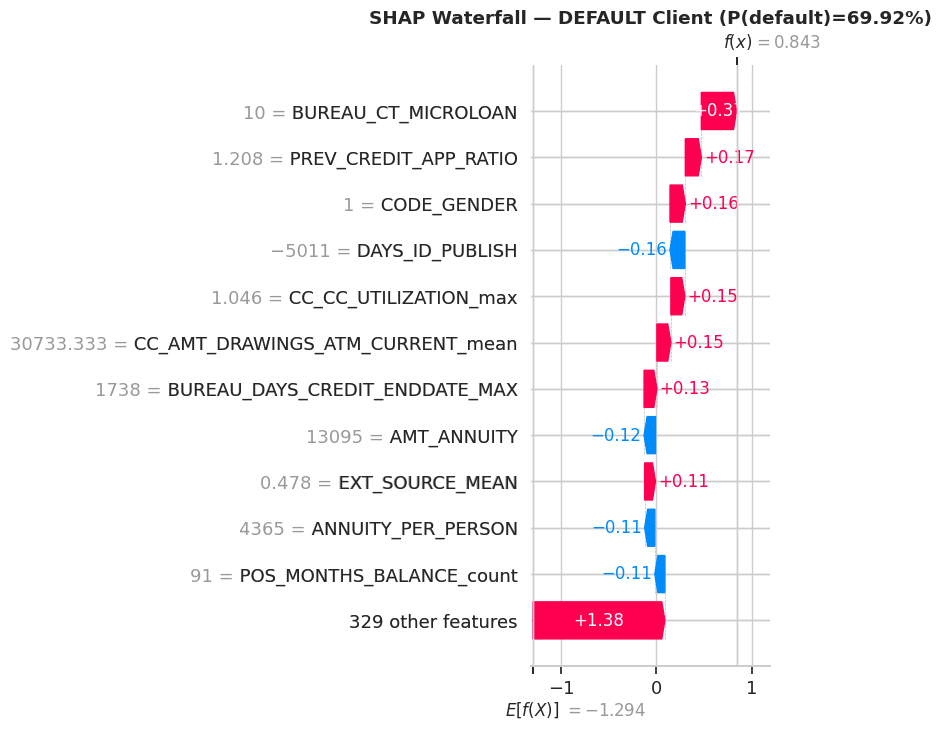

In [82]:
# 4. SHAP Waterfall Plots — Individual Predictions (Local Explanations)
print("=" * 70)
print("SHAP WATERFALL — Individual Client Explanations")
print("=" * 70)

# Align y_test with shap_sample indices
# y_test is a numpy array indexed by position, shap_sample uses iloc-based positions from X_test
shap_positions = [X_test.index.get_loc(idx) if idx in X_test.index else None for idx in shap_sample.index]
shap_positions = [p for p in shap_positions if p is not None]
test_y_aligned = np.array([y_test[p] for p in shap_positions])

repaid_examples = np.where(test_y_aligned == 0)[0][:2]
default_examples = np.where(test_y_aligned == 1)[0][:2]

for label, indices in [("REPAID", repaid_examples), ("DEFAULT", default_examples)]:
    for ex_idx in indices:
        actual_label = label
        pred_proba = shap_model.predict_proba(shap_sample.iloc[[ex_idx]])[:, 1][0]
        print(f"\nClient (Actual: {actual_label}, Predicted default prob: {pred_proba:.2%})")

        # Create SHAP explanation object
        if isinstance(shap_values, list):
            explanation = shap.Explanation(
                values=shap_values[1][ex_idx],
                base_values=explainer.expected_value[1] if isinstance(explainer.expected_value, list) else explainer.expected_value,
                data=shap_sample.iloc[ex_idx].values,
                feature_names=shap_sample.columns.tolist()
            )
        else:
            explanation = shap.Explanation(
                values=shap_vals[ex_idx],
                base_values=explainer.expected_value if not isinstance(explainer.expected_value, list) else explainer.expected_value[1],
                data=shap_sample.iloc[ex_idx].values,
                feature_names=shap_sample.columns.tolist()
            )

        plt.figure(figsize=(12, 5))
        shap.waterfall_plot(explanation, show=False, max_display=12)
        plt.title(f'SHAP Waterfall — {actual_label} Client (P(default)={pred_proba:.2%})', fontweight='bold')
        plt.tight_layout()
        plt.show()

=== SHAP vs Native Feature Importance (LightGBM (All Features)) — Top 15 ===



,Feature,SHAP_Pct,Model_Importance_Pct
0,EXT_SOURCE_MEAN,6.3200,0.9000
1,CODE_GENDER,2.4500,0.2100
2,PREV_AMT_ANNUITY_MEAN,2.2600,1.0400
3,EXT_SOURCE_SUM,1.8400,1.0800
4,KNN_100_TARGET_MEAN,1.6500,0.6000
5,NAME_EDUCATION_TYPE,1.6100,0.2000
6,PREV_CREDIT_APP_RATIO,1.4700,1.1500
7,CREDIT_GOODS_RATIO,1.3300,0.8200
8,ANNUITY_CREDIT_RATIO,1.3300,1.2300
9,AMT_ANNUITY,1.3200,1.0200


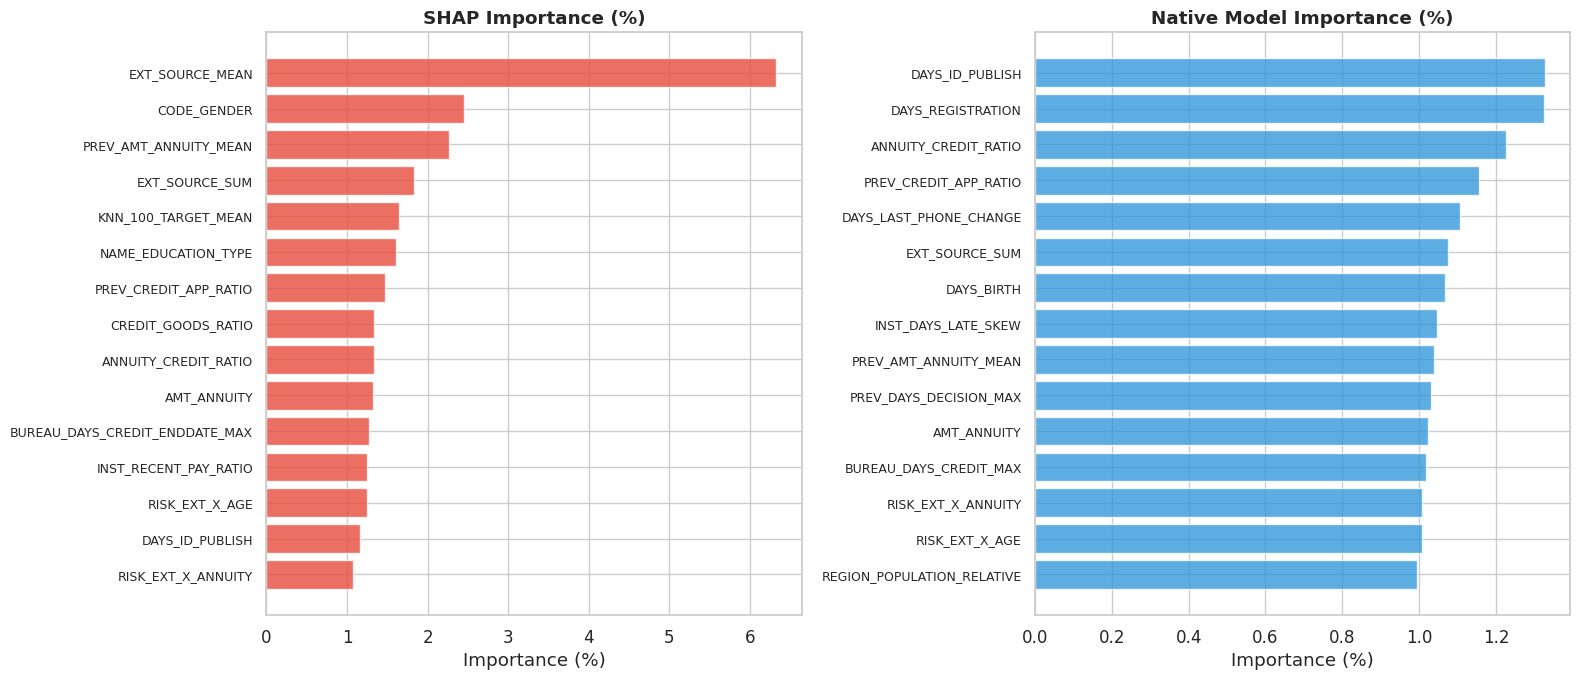

In [83]:
# 5. SHAP vs Traditional Feature Importance Comparison
shap_importance = pd.DataFrame({
    'Feature': shap_sample.columns,
    'SHAP_Importance': np.abs(shap_vals).mean(axis=0)
}).sort_values('SHAP_Importance', ascending=False)
shap_importance['SHAP_Pct'] = (shap_importance['SHAP_Importance'] / shap_importance['SHAP_Importance'].sum() * 100)

native_imp = pd.DataFrame({
    'Feature': shap_sample.columns,
    'Model_Importance': baseline_results[explainability_model_name]['model'][0].feature_importances_
})
native_imp['Model_Importance_Pct'] = (native_imp['Model_Importance'] / native_imp['Model_Importance'].sum() * 100)

comparison = shap_importance.merge(native_imp[['Feature', 'Model_Importance_Pct']], on='Feature', how='left')
comparison['SHAP_Rank'] = range(1, len(comparison) + 1)
comparison = comparison.sort_values('SHAP_Pct', ascending=False)

print(f"=== SHAP vs Native Feature Importance ({explainability_model_name}) — Top 15 ===\n")
display(comparison.head(15)[['Feature', 'SHAP_Pct', 'Model_Importance_Pct']].round(2))

# Side-by-side comparison plot
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

top15 = comparison.head(15)

ax = axes[0]
ax.barh(range(len(top15)), top15['SHAP_Pct'], color='#e74c3c', alpha=0.8)
ax.set_yticks(range(len(top15)))
ax.set_yticklabels(top15['Feature'], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Importance (%)')
ax.set_title('SHAP Importance (%)', fontweight='bold')

ax = axes[1]
top15_native = comparison.sort_values('Model_Importance_Pct', ascending=False).head(15)
ax.barh(range(len(top15_native)), top15_native['Model_Importance_Pct'], color='#3498db', alpha=0.8)
ax.set_yticks(range(len(top15_native)))
ax.set_yticklabels(top15_native['Feature'], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Importance (%)')
ax.set_title('Native Model Importance (%)', fontweight='bold')

plt.tight_layout()
plt.show()

In [84]:
# FIXED: Feature importance cell
print("=" * 60)
print("FEATURE IMPORTANCE — PERCENTAGE VALUES (FIXED)")
print("=" * 60)

import numpy as np
import pandas as pd

def _safe_get_model_obj(model_container):
    """
    Return one fitted model from baseline_results[...] ['model'] safely.
    Works for:
      - single fitted model object
      - list of fitted models
      - empty list / None
    """
    if model_container is None:
        return None

    if isinstance(model_container, list):
        if len(model_container) == 0:
            return None
        for m in model_container:
            if m is not None and hasattr(m, "feature_importances_"):
                return m
        return model_container[0]

    return model_container


def _pick_feature_importance_source():
    """
    Prefer a fitted LightGBM/XGBoost model that actually exists.
    """
    candidate_order = [
        "LightGBM (All Features)",
        "LightGBM (Tuned)",
        "LightGBM",
        "Random Forest (Tuned)",
        "Random Forest",
        "XGBoost (Tuned)",
        "XGBoost"
    ]

    for name in candidate_order:
        if name in baseline_results:
            model_obj = _safe_get_model_obj(baseline_results[name].get("model"))
            if model_obj is not None and hasattr(model_obj, "feature_importances_"):
                return name, model_obj

    return None, None


feature_importance_model_name, feature_importance_model = _pick_feature_importance_source()

# If notebook did not store a fitted model correctly, refit one lightweight backup model
if feature_importance_model is None:
    print("No stored fitted tree model found in baseline_results. Re-fitting a backup model for importance...")

    if 'LightGBM (All Features)' in baseline_results:
        # use full-feature model as backup
        feature_importance_model_name = 'LightGBM (All Features)'
        feature_importance_model = all_features_lgbm_factory(compute_pos_weight(y_train))
        feature_importance_model.fit(X_all_train, y_train)
    else:
        # fallback to tuned tier LightGBM
        feature_importance_model_name = 'LightGBM (Tuned)'
        feature_importance_model = tuned_lgbm_factory()
        feature_importance_model.fit(X_train, y_train)

print(f"Using model for importance: {feature_importance_model_name}")

# Choose the correct feature set
if feature_importance_model_name == 'LightGBM (All Features)':
    feature_names = list(X_all_train.columns) if hasattr(X_all_train, "columns") else list(all_num_cols)
else:
    feature_names = list(X_train.columns) if hasattr(X_train, "columns") else list(ALL_TIER_FEATURES)

# Extract raw importances safely
importances = np.asarray(feature_importance_model.feature_importances_, dtype=float)

# Align lengths if something shifted
n = min(len(feature_names), len(importances))
feature_names = feature_names[:n]
importances = importances[:n]

total_importance = importances.sum()
if total_importance == 0:
    importance_pct = np.zeros_like(importances, dtype=float)
else:
    importance_pct = (importances / total_importance) * 100

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance_Raw': importances,
    'Importance_Pct': importance_pct
}).sort_values('Importance_Pct', ascending=False).reset_index(drop=True)

# Add tier labels
def get_tier(feat):
    if 'TIER_1' in globals() and feat in TIER_1:
        return 'Tier 1'
    elif 'TIER_2' in globals() and feat in TIER_2:
        return 'Tier 2'
    elif 'TIER_3' in globals() and feat in TIER_3:
        return 'Tier 3'
    return 'Other'

importance_df['Tier'] = importance_df['Feature'].apply(get_tier)
importance_df['Cumulative_Pct'] = importance_df['Importance_Pct'].cumsum()

print("\nFeature Importance (sorted by % contribution):\n")
display(importance_df.round(2))

tier_summary = importance_df.groupby('Tier')['Importance_Pct'].sum().sort_values(ascending=False)
print("\n--- Importance by Tier ---")
for tier, pct in tier_summary.items():
    print(f"  {tier}: {pct:.1f}%")

FEATURE IMPORTANCE — PERCENTAGE VALUES (FIXED)
Using model for importance: LightGBM (All Features)

Feature Importance (sorted by % contribution):



,Feature,Importance_Raw,Importance_Pct,Tier,Cumulative_Pct
0,DAYS_ID_PUBLISH,1123.0000,1.3300,Other,1.3300
1,DAYS_REGISTRATION,1122.0000,1.3300,Other,2.6500
2,ANNUITY_CREDIT_RATIO,1037.0000,1.2300,Tier 3,3.8800
3,PREV_CREDIT_APP_RATIO,977.0000,1.1500,Other,5.0300
4,DAYS_LAST_PHONE_CHANGE,936.0000,1.1100,Other,6.1400
...,...,...,...,...,...
335,HAS_BUREAU,0.0000,0.0000,Other,100.0000
336,HAS_BB,0.0000,0.0000,Other,100.0000
337,HAS_INST,0.0000,0.0000,Other,100.0000
338,HAS_PREV,0.0000,0.0000,Other,100.0000



--- Importance by Tier ---
  Other: 77.9%
  Tier 1: 8.0%
  Tier 3: 7.6%
  Tier 2: 6.5%


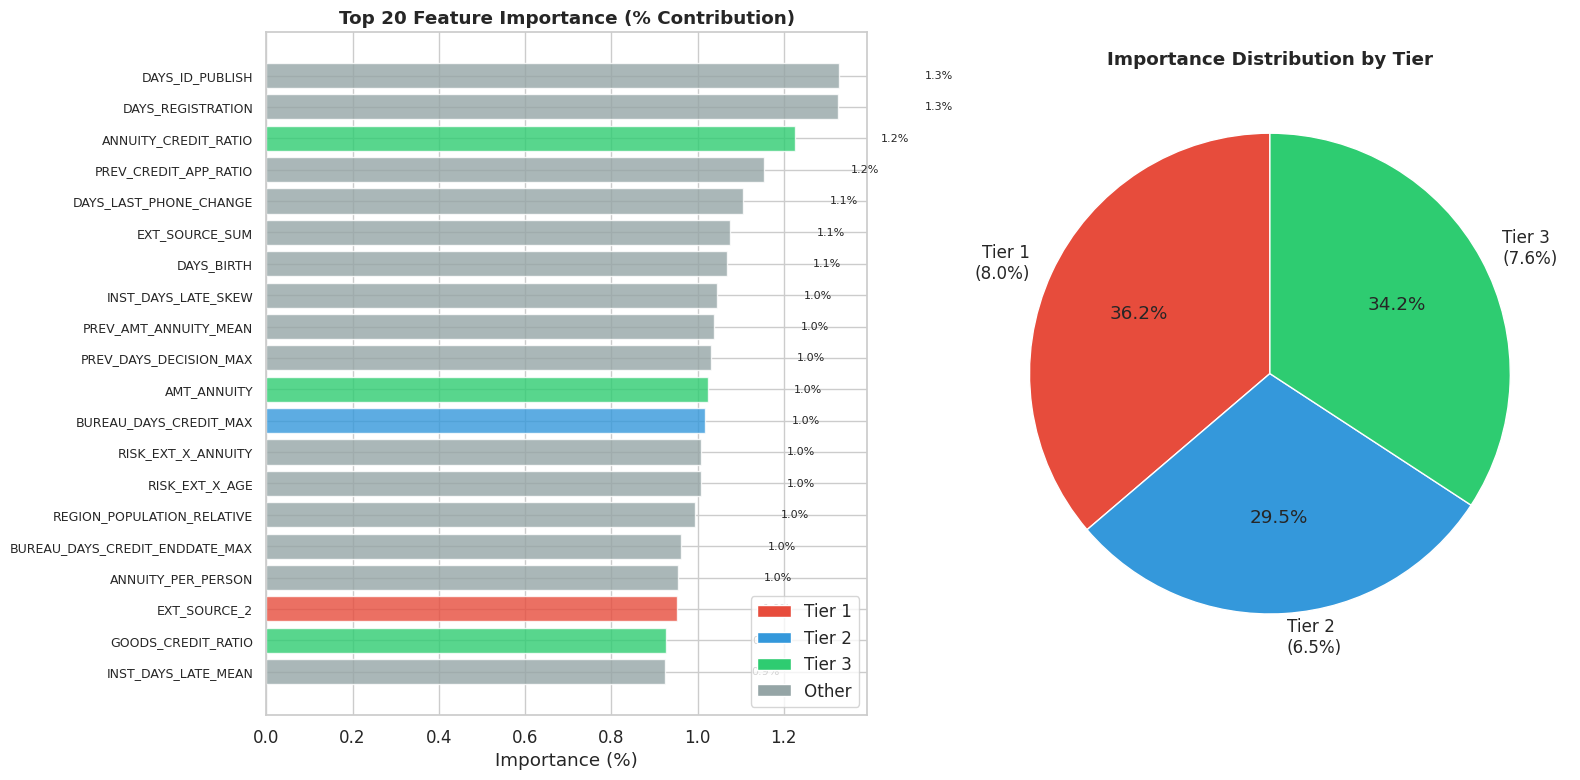

In [85]:
# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Bar chart with percentage labels
ax = axes[0]
top_feats = importance_df.head(20)
tier_colors = {'Tier 1': '#e74c3c', 'Tier 2': '#3498db', 'Tier 3': '#2ecc71', 'Other': '#95a5a6'}
colors = [tier_colors.get(t, '#95a5a6') for t in top_feats['Tier']]

bars = ax.barh(range(len(top_feats)), top_feats['Importance_Pct'], color=colors, alpha=0.8, edgecolor='white')
ax.set_yticks(range(len(top_feats)))
ax.set_yticklabels(top_feats['Feature'], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Importance (%)')
ax.set_title('Top 20 Feature Importance (% Contribution)', fontweight='bold')

# Add percentage labels
for i, (pct, cum) in enumerate(zip(top_feats['Importance_Pct'], top_feats['Cumulative_Pct'])):
    ax.text(pct + 0.2, i, f'{pct:.1f}%', va='center', fontsize=8)

# Legend for tiers
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=t) for t, c in tier_colors.items() if t in top_feats['Tier'].values]
ax.legend(handles=legend_elements, loc='lower right')

# Pie chart for tier-level importance
ax = axes[1]
tier_pcts = importance_df.groupby('Tier')['Importance_Pct'].sum()
tier_pcts = tier_pcts.reindex(['Tier 1', 'Tier 2', 'Tier 3']).dropna()
colors_pie = [tier_colors[t] for t in tier_pcts.index]
ax.pie(tier_pcts.values, labels=[f'{t}\n({v:.1f}%)' for t, v in tier_pcts.items()],
       colors=colors_pie, autopct='%1.1f%%', startangle=90)
ax.set_title('Importance Distribution by Tier', fontweight='bold')

plt.tight_layout()
plt.show()

### 9.3 Fairness Analysis — Bias Detection

In [86]:
# Fairness Analysis
print("=" * 70)
print("FAIRNESS ANALYSIS — Bias Detection")
print("=" * 70)

fairness_model_name = calibration_model_name
print(f"Fairness model: {fairness_model_name}")

# Use the same labeled holdout rows that were used for evaluation
test_df = X_test.copy()
test_df['pred_proba'] = production_test_proba
test_df['pred_class'] = production_test_pred
test_df['actual'] = y_test

# Original raw values for demographic groupings
original_test = df_full_raw.loc[X_test.index].copy()

# 1. Gender Fairness
print("\n--- Gender Fairness ---")
if 'CODE_GENDER' in original_test.columns:
    for gender in original_test['CODE_GENDER'].dropna().unique():
        mask = original_test['CODE_GENDER'] == gender
        if mask.sum() > 100:
            actual_rate = test_df.loc[mask, 'actual'].mean()
            pred_rate = test_df.loc[mask, 'pred_proba'].mean()
            auc = roc_auc_score(test_df.loc[mask, 'actual'], test_df.loc[mask, 'pred_proba']) if test_df.loc[mask, 'actual'].nunique() > 1 else 0
            print(f"  {gender}: n={mask.sum():,}, Actual default={actual_rate:.4f}, Predicted={pred_rate:.4f}, AUC={auc:.4f}")

# 2. Age Group Fairness
print("\n--- Age Group Fairness ---")
if 'AGE_YEARS' in test_df.columns:
    test_df['age_group'] = pd.cut(test_df['AGE_YEARS'], bins=[20, 30, 40, 50, 60, 70], labels=['20-30', '30-40', '40-50', '50-60', '60-70'])
    for group in test_df['age_group'].dropna().unique():
        mask = test_df['age_group'] == group
        if mask.sum() > 100:
            actual_rate = test_df.loc[mask, 'actual'].mean()
            pred_rate = test_df.loc[mask, 'pred_proba'].mean()
            auc = roc_auc_score(test_df.loc[mask, 'actual'], test_df.loc[mask, 'pred_proba']) if test_df.loc[mask, 'actual'].nunique() > 1 else 0
            print(f"  {group}: n={mask.sum():,}, Actual default={actual_rate:.4f}, Predicted={pred_rate:.4f}, AUC={auc:.4f}")

# 3. Education Fairness
print("\n--- Education Level Fairness ---")
if 'NAME_EDUCATION_TYPE' in original_test.columns:
    for edu in original_test['NAME_EDUCATION_TYPE'].dropna().unique():
        mask = original_test['NAME_EDUCATION_TYPE'] == edu
        if mask.sum() > 100:
            actual_rate = test_df.loc[mask, 'actual'].mean()
            pred_rate = test_df.loc[mask, 'pred_proba'].mean()
            auc = roc_auc_score(test_df.loc[mask, 'actual'], test_df.loc[mask, 'pred_proba']) if test_df.loc[mask, 'actual'].nunique() > 1 else 0
            print(f"  {edu}: n={mask.sum():,}, Actual default={actual_rate:.4f}, Predicted={pred_rate:.4f}, AUC={auc:.4f}")

FAIRNESS ANALYSIS — Bias Detection
Fairness model: LightGBM Focal Loss

--- Gender Fairness ---
  M: n=20,940, Actual default=0.1017, Predicted=0.0990, AUC=0.7925
  F: n=40,561, Actual default=0.0699, Predicted=0.0701, AUC=0.7849

--- Age Group Fairness ---
  30-40: n=16,491, Actual default=0.0957, Predicted=0.0947, AUC=0.7958
  40-50: n=15,299, Actual default=0.0758, Predicted=0.0761, AUC=0.7960
  60-70: n=7,188, Actual default=0.0497, Predicted=0.0492, AUC=0.7515
  20-30: n=8,905, Actual default=0.1130, Predicted=0.1138, AUC=0.7695
  50-60: n=13,620, Actual default=0.0634, Predicted=0.0606, AUC=0.7800

--- Education Level Fairness ---
  Higher education: n=15,061, Actual default=0.0520, Predicted=0.0534, AUC=0.7866
  Secondary / secondary special: n=43,623, Actual default=0.0904, Predicted=0.0887, AUC=0.7884
  Incomplete higher: n=1,988, Actual default=0.0790, Predicted=0.0834, AUC=0.7680
  Lower secondary: n=791, Actual default=0.1037, Predicted=0.0981, AUC=0.7572


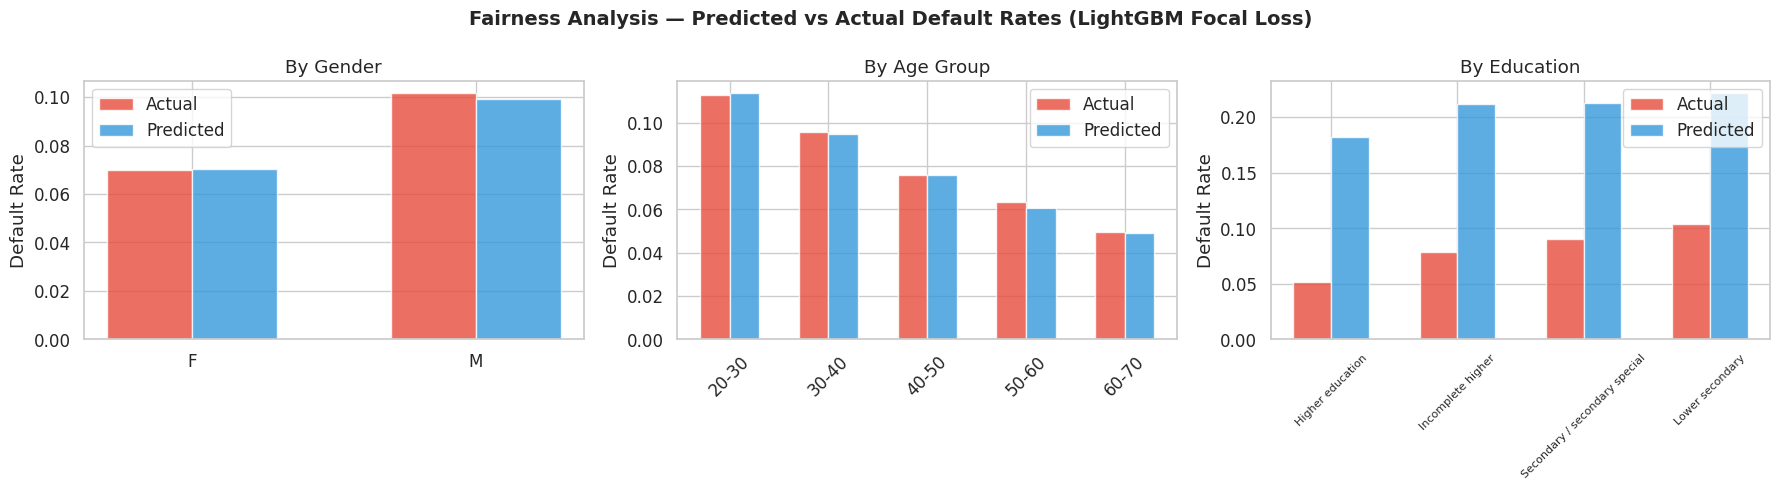


Note: If predicted rates closely match actual rates across groups,
the model is behaving consistently with observed risk rather than amplifying group differences.


In [87]:
# Fairness Visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(f'Fairness Analysis — Predicted vs Actual Default Rates ({fairness_model_name})', fontsize=14, fontweight='bold')

# Gender
ax = axes[0]
if 'CODE_GENDER' in original_test.columns:
    gender_stats = original_test.copy()
    gender_stats['actual'] = y_test
    gender_stats['predicted'] = production_test_proba
    g_rates = gender_stats.groupby('CODE_GENDER').agg(
        actual_rate=('actual', 'mean'),
        predicted_rate=('predicted', 'mean'),
        count=('actual', 'count')
    )
    g_rates = g_rates[g_rates['count'] > 50]
    x = range(len(g_rates))
    ax.bar([i-0.15 for i in x], g_rates['actual_rate'], 0.3, label='Actual', color='#e74c3c', alpha=0.8)
    ax.bar([i+0.15 for i in x], g_rates['predicted_rate'], 0.3, label='Predicted', color='#3498db', alpha=0.8)
    ax.set_xticks(list(x))
    ax.set_xticklabels(g_rates.index)
    ax.set_ylabel('Default Rate')
    ax.set_title('By Gender')
    ax.legend()

# Age
ax = axes[1]
if 'age_group' in test_df.columns:
    age_stats = test_df.groupby('age_group', observed=True).agg(
        actual_rate=('actual', 'mean'),
        predicted_rate=('pred_proba', 'mean'),
        count=('actual', 'count')
    )
    age_stats = age_stats[age_stats['count'] > 50]
    x = range(len(age_stats))
    ax.bar([i-0.15 for i in x], age_stats['actual_rate'], 0.3, label='Actual', color='#e74c3c', alpha=0.8)
    ax.bar([i+0.15 for i in x], age_stats['predicted_rate'], 0.3, label='Predicted', color='#3498db', alpha=0.8)
    ax.set_xticks(list(x))
    ax.set_xticklabels(age_stats.index, rotation=45)
    ax.set_ylabel('Default Rate')
    ax.set_title('By Age Group')
    ax.legend()

# Education
ax = axes[2]
if 'NAME_EDUCATION_TYPE' in original_test.columns:
    edu_stats = original_test.copy()
    edu_stats['actual'] = y_test
    edu_stats['predicted'] = baseline_results[fairness_model_name]['test_proba']
    e_rates = edu_stats.groupby('NAME_EDUCATION_TYPE').agg(
        actual_rate=('actual', 'mean'),
        predicted_rate=('predicted', 'mean'),
        count=('actual', 'count')
    )
    e_rates = e_rates[e_rates['count'] > 50].sort_values('actual_rate')
    x = range(len(e_rates))
    ax.bar([i-0.15 for i in x], e_rates['actual_rate'], 0.3, label='Actual', color='#e74c3c', alpha=0.8)
    ax.bar([i+0.15 for i in x], e_rates['predicted_rate'], 0.3, label='Predicted', color='#3498db', alpha=0.8)
    ax.set_xticks(list(x))
    ax.set_xticklabels(e_rates.index, rotation=45, fontsize=8)
    ax.set_ylabel('Default Rate')
    ax.set_title('By Education')
    ax.legend()

plt.tight_layout()
plt.show()

print("\nNote: If predicted rates closely match actual rates across groups,")
print("the model is behaving consistently with observed risk rather than amplifying group differences.")

---
## Phase 10: Summary & Blind External Scoring

---

### 10.1 Blind External Scoring on `application_test.csv`

In [88]:
# Blind external scoring with full-data refit for all supported models
print("=" * 80)
print("BLIND EXTERNAL SCORING — Full labelled refit + all models")
print("=" * 80)

from sklearn.linear_model import LogisticRegression as LR_Cal
from sklearn.isotonic import IsotonicRegression as IR
from sklearn.model_selection import train_test_split

blind_test_ids = df_test_full_raw['SK_ID_CURR'].to_numpy() if 'SK_ID_CURR' in df_test_full_raw.columns else np.arange(len(df_test_full_raw))

# Production matrices are based on preprocessing fitted on all labelled data.
X_tier_full = df_full.reindex(columns=ALL_TIER_FEATURES, fill_value=0).copy()
X_all_full = df_full.reindex(columns=all_num_cols, fill_value=0).copy()
X_blind_tier_prod = df_test_full.reindex(columns=ALL_TIER_FEATURES, fill_value=0).copy()
X_blind_all_prod = df_test_full.reindex(columns=all_num_cols, fill_value=0).copy()
y_full = df_full['TARGET'].to_numpy()
full_pos_weight = compute_pos_weight(y_full)

holdout_best_model_name = max(baseline_results.keys(), key=lambda k: baseline_results[k]['test_metrics']['AUC'])
single_model_candidates = [k for k in baseline_results.keys() if k != 'Stacking Ensemble' and 'Blend' not in k]
best_single_model_name = max(single_model_candidates, key=lambda k: baseline_results[k]['test_metrics']['AUC'])
production_model_name = best_single_model_name if holdout_best_model_name == 'Stacking Ensemble' else holdout_best_model_name
print(f"Selected production model: {production_model_name}")

# Use a small internal stratified validation subset only for early stopping during full-data refit.
def _fit_full_model(model, X_full, y_full_arr, model_name):
    needs_eval = isinstance(model, (lgb.LGBMClassifier, xgb.XGBClassifier)) or (HAS_CATBOOST and isinstance(model, CatBoostClassifier))
    if needs_eval:
        X_fit_full, X_val_full, y_fit_full, y_val_full = train_test_split(
            X_full, y_full_arr, test_size=0.10, stratify=y_full_arr, random_state=42
        )
        if isinstance(model, lgb.LGBMClassifier):
            model.fit(
                X_fit_full, y_fit_full,
                eval_set=[(X_val_full, y_val_full)],
                callbacks=[
                    lgb.early_stopping(get_setting(FAST_EARLY_STOPPING_ROUNDS, FINAL_EARLY_STOPPING_ROUNDS), verbose=False, first_metric_only=True),
                    lgb.log_evaluation(0),
                ]
            )
        elif isinstance(model, xgb.XGBClassifier):
            model.fit(X_fit_full, y_fit_full, eval_set=[(X_val_full, y_val_full)], verbose=False)
        else:  # CatBoost
            model.fit(
                X_fit_full, y_fit_full,
                eval_set=(X_val_full, y_val_full),
                use_best_model=True,
                early_stopping_rounds=get_setting(FAST_EARLY_STOPPING_ROUNDS, FINAL_EARLY_STOPPING_ROUNDS),
            )
    else:
        try:
            model.fit(X_full, y_full_arr)
        except TypeError:
            model.fit(np.asarray(X_full), y_full_arr)
    return model

# Factories for full-data refit. Models are included only if their training cells ran successfully.
factory_map = {}
if 'Logistic Regression' in baseline_results:
    factory_map['Logistic Regression'] = (lambda pw: lr_factory(pw), 'tier')
if 'LightGBM' in baseline_results:
    factory_map['LightGBM'] = (lambda pw: lgbm_factory(pw), 'tier')
if 'XGBoost' in baseline_results:
    factory_map['XGBoost'] = (lambda pw: xgb_factory(pw), 'tier')
if 'Random Forest' in baseline_results:
    factory_map['Random Forest'] = (lambda pw: rf_factory(pw), 'tier')
if 'Logistic Regression (Tuned)' in baseline_results:
    factory_map['Logistic Regression (Tuned)'] = (lambda pw: tuned_lr_factory(pw), 'tier')
if 'LightGBM (Tuned)' in baseline_results:
    factory_map['LightGBM (Tuned)'] = (lambda pw: tuned_lgbm_factory(pw), 'tier')
if 'XGBoost (Tuned)' in baseline_results:
    factory_map['XGBoost (Tuned)'] = (lambda pw: tuned_xgb_factory(pw), 'tier')
if 'Random Forest (Tuned)' in baseline_results:
    factory_map['Random Forest (Tuned)'] = (lambda pw: tuned_rf_factory(pw), 'tier')
if 'LightGBM (All Features)' in baseline_results:
    factory_map['LightGBM (All Features)'] = (lambda pw: all_features_lgbm_factory(pw), 'all')
if 'XGBoost (All Features)' in baseline_results:
    factory_map['XGBoost (All Features)'] = (lambda pw: xgb_all_factory(pw), 'all')
if 'CatBoost (All Features)' in baseline_results and HAS_CATBOOST:
    factory_map['CatBoost (All Features)'] = (
        lambda pw: CatBoostClassifier(
            iterations=get_setting(250, FINAL_CATBOOST_ITERATIONS),
            learning_rate=0.035,
            depth=6,
            l2_leaf_reg=8.0,
            loss_function='Logloss',
            eval_metric='AUC',
            class_weights=[1.0, float(pw)],
            random_seed=42,
            thread_count=1,
            verbose=False,
            allow_writing_files=False,
        ),
        'all'
    )
# GOSS model (uses same tuned params but boosting_type='goss')
if 'LightGBM GOSS (7th place)' in baseline_results:
    factory_map['LightGBM GOSS (7th place)'] = (
        lambda pw: lgb.LGBMClassifier(
            boosting_type='goss',
            n_estimators=get_setting(500, 3000),
            learning_rate=0.02,
            num_leaves=63,
            max_depth=7,
            min_child_samples=50,
            scale_pos_weight=float(pw),
            subsample=1.0,
            colsample_bytree=0.7,
            reg_alpha=0.1,
            reg_lambda=5.0,
            random_state=42,
            n_jobs=1,
            verbose=-1,
        ),
        'all'
    )
# Focal Loss model — handled separately below (requires lgb.train + custom objective, not LGBMClassifier)

raw_blind_by_model = {}
full_retrained_models = {}

for model_name, (factory_fn, feature_set) in factory_map.items():
    X_full_model = X_all_full if feature_set == 'all' else X_tier_full
    X_blind_model = X_blind_all_prod if feature_set == 'all' else X_blind_tier_prod
    print(f"Retraining {model_name} on full labelled data ({X_full_model.shape[0]:,} rows x {X_full_model.shape[1]} features)...")
    model = factory_fn(full_pos_weight)
    model = _fit_full_model(model, X_full_model, y_full, model_name)
    raw_blind_by_model[model_name] = model.predict_proba(X_blind_model)[:, 1].astype(np.float32)
    full_retrained_models[model_name] = model

# Full-data MLP refit for blind scoring, if MLP all-features exists and PyTorch is available.
if HAS_TORCH and 'MLP (All Features)' in baseline_results:
    print(f"Retraining MLP (All Features) on full labelled data ({X_all_full.shape[0]:,} rows x {X_all_full.shape[1]} features)...")
    X_fit_mlp, X_val_mlp, y_fit_mlp, y_val_mlp = train_test_split(
        X_all_full, y_full, test_size=0.10, stratify=y_full, random_state=42
    )
    X_fit_np = X_fit_mlp.values.astype(np.float32)
    X_val_np = X_val_mlp.values.astype(np.float32)
    X_blind_np = X_blind_all_prod.values.astype(np.float32)
    col_meds = np.nanmedian(X_fit_np, axis=0)
    col_meds = np.where(np.isnan(col_meds), 0, col_meds)
    X_fit_np = np.where(np.isnan(X_fit_np), col_meds, X_fit_np)
    X_val_np = np.where(np.isnan(X_val_np), col_meds, X_val_np)
    X_blind_np = np.where(np.isnan(X_blind_np), col_meds, X_blind_np)
    mlp_full_model, mlp_full_scaler, mlp_full_device = train_mlp_fold(
        X_fit_np, y_fit_mlp.astype(np.float32), X_val_np, y_val_mlp.astype(np.float32),
        epochs=get_setting(FAST_MLP_EPOCHS, FINAL_MLP_EPOCHS),
        batch_size=get_setting(FAST_MLP_BATCH_SIZE, FINAL_MLP_BATCH_SIZE),
        pos_weight_val=compute_pos_weight(y_fit_mlp),
        patience=get_setting(FAST_MLP_PATIENCE, FINAL_MLP_PATIENCE),
    )
    raw_blind_by_model['MLP (All Features)'] = predict_mlp(mlp_full_model, mlp_full_scaler, X_blind_np, mlp_full_device).astype(np.float32)
    full_retrained_models['MLP (All Features)'] = (mlp_full_model, mlp_full_scaler, mlp_full_device, col_meds)

# ─── Focal Loss blind scoring (lgb.train with custom objective, matching cell 103) ───
if 'LightGBM Focal Loss' in baseline_results:
    print(f"Retraining LightGBM Focal Loss on full labelled data ({X_all_full.shape[0]:,} rows x {X_all_full.shape[1]} features)...")
    X_focal_fit, X_focal_val, y_focal_fit, y_focal_val = train_test_split(
        X_all_full, y_full, test_size=0.10, stratify=y_full, random_state=42
    )
    dtrain_full = lgb.Dataset(X_focal_fit, label=y_focal_fit, free_raw_data=False)
    dval_full = lgb.Dataset(X_focal_val, label=y_focal_val, reference=dtrain_full, free_raw_data=False)
    focal_params = {
        'boosting_type': 'gbdt', 'learning_rate': 0.02,
        'max_depth': 7, 'num_leaves': 63, 'min_child_samples': 50,
        'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.7,
        'reg_alpha': 0.1, 'reg_lambda': 5.0,
        'seed': 42, 'n_jobs': 1, 'verbose': -1,
        'objective': focal_loss_lgb,
        'metric': 'auc',
    }
    focal_bst_full = lgb.train(
        focal_params, dtrain_full, num_boost_round=get_setting(500, 3000),
        valid_sets=[dval_full],
        callbacks=[lgb.early_stopping(get_setting(15, 150), verbose=False), lgb.log_evaluation(0)]
    )
    # Booster.predict() returns raw logits with custom objective — apply sigmoid
    raw_focal_blind = focal_bst_full.predict(X_blind_all_prod)
    raw_blind_by_model['LightGBM Focal Loss'] = (1.0 / (1.0 + np.exp(-raw_focal_blind))).astype(np.float32)
    full_retrained_models['LightGBM Focal Loss'] = focal_bst_full
    del dtrain_full, dval_full, X_focal_fit, X_focal_val; gc.collect()
    print(f"  LightGBM Focal Loss blind scoring complete (iter={focal_bst_full.best_iteration})")

# Stacking blind scoring using the same meta-feature order saved in the stacking cell.
if 'Stacking Ensemble' in baseline_results:
    stack_base_names = baseline_results['Stacking Ensemble'].get(
        'base_model_names',
        ['Logistic Regression (Tuned)', 'LightGBM (Tuned)', 'XGBoost (Tuned)', 'Random Forest (Tuned)', 'LightGBM (All Features)']
    )
    missing_stack_models = [m for m in stack_base_names if m not in raw_blind_by_model]
    if missing_stack_models:
        print(f"Skipping stacking blind scoring; missing base blind predictions: {missing_stack_models}")
    else:
        stack_model = baseline_results['Stacking Ensemble']['model'][0]
        blind_stack_meta = np.column_stack([raw_blind_by_model[m] for m in stack_base_names])
        raw_blind_by_model['Stacking Ensemble'] = stack_model.predict_proba(blind_stack_meta)[:, 1].astype(np.float32)
        print(f"Scored blind set with Stacking Ensemble using bases: {stack_base_names}")

# Handle blended model blind scoring (these use weighted averages of base model blind predictions)
for blend_name in ['MLP+Focal Blend', 'MLP+Focal+Cat Blend', 'MLP+Focal F2-Blend', 'MLP+Focal Recall-Opt']:
    if blend_name in baseline_results and 'blend_weights' in baseline_results[blend_name]:
        weights = baseline_results[blend_name]['blend_weights']
        missing_bases = [m for m in weights.keys() if m not in raw_blind_by_model]
        if missing_bases:
            print(f"Skipping {blend_name} blind scoring — missing base predictions: {missing_bases}")
            continue
        blend_blind = sum(w * raw_blind_by_model[base] for base, w in weights.items())
        raw_blind_by_model[blend_name] = blend_blind.astype(np.float32)
        print(f"Scored blind set with {blend_name} using weights: {weights}")

# Handle cascade model blind scoring
for casc_name in ['Cascade F1', 'Cascade F2']:
    if casc_name in baseline_results and 'cascade_params' in baseline_results[casc_name]:
        params = baseline_results[casc_name]['cascade_params']
        if 'MLP (All Features)' in raw_blind_by_model and 'LightGBM Focal Loss' in raw_blind_by_model:
            focal_blind = raw_blind_by_model['LightGBM Focal Loss']
            mlp_blind = raw_blind_by_model['MLP (All Features)']
            casc_proba = focal_blind.copy().astype(np.float64)
            s2 = focal_blind >= params['focal_cutoff']
            casc_proba[s2] = np.maximum(focal_blind[s2], mlp_blind[s2])
            raw_blind_by_model[casc_name] = casc_proba.astype(np.float32)
            print(f"Scored blind set with {casc_name} (focal_cutoff={params['focal_cutoff']:.2f})")
        else:
            print(f"Skipping {casc_name} — missing base blind predictions")

blind_summary_rows = []
blind_scoring_wide = pd.DataFrame({'SK_ID_CURR': blind_test_ids})
calibrated_holdout_by_model = {}

for model_name, hist in baseline_results.items():
    if model_name not in raw_blind_by_model:
        continue

    prod_oof = hist['train_proba']
    prod_holdout_raw = hist['test_proba']
    blind_test_proba_raw = raw_blind_by_model[model_name]

    # Platt
    prod_platt = LR_Cal(C=1e10, solver='lbfgs', max_iter=get_setting(500, 1000))
    prod_platt.fit(prod_oof.reshape(-1, 1), y_train)
    prod_holdout_platt = prod_platt.predict_proba(prod_holdout_raw.reshape(-1, 1))[:, 1]
    prod_blind_platt = prod_platt.predict_proba(blind_test_proba_raw.reshape(-1, 1))[:, 1]

    # Isotonic
    prod_iso = IR(y_min=0, y_max=1, out_of_bounds='clip')
    prod_iso.fit(prod_oof, y_train)
    prod_holdout_iso = prod_iso.predict(prod_holdout_raw)
    prod_blind_iso = prod_iso.predict(blind_test_proba_raw)

    platt_brier = brier_score_loss(y_test, prod_holdout_platt)
    iso_brier = brier_score_loss(y_test, prod_holdout_iso)
    if platt_brier <= iso_brier + 1e-4:
        blind_test_proba = prod_blind_platt.astype(np.float32)
        holdout_ref_proba = prod_holdout_platt.astype(np.float32)
        blind_threshold = find_optimal_threshold(y_train, prod_platt.predict_proba(prod_oof.reshape(-1, 1))[:, 1])
        blind_calibration_name = 'Platt'
    else:
        blind_test_proba = prod_blind_iso.astype(np.float32)
        holdout_ref_proba = prod_holdout_iso.astype(np.float32)
        blind_threshold = find_optimal_threshold(y_train, prod_iso.predict(prod_oof))
        blind_calibration_name = 'Isotonic'

    blind_test_pred = (blind_test_proba >= blind_threshold).astype(np.int8)
    calibrated_holdout_by_model[model_name] = holdout_ref_proba

    psi_score_model = calculate_psi(holdout_ref_proba, blind_test_proba)
    if psi_score_model < 0.10:
        psi_band_model = 'Stable'
    elif psi_score_model < 0.25:
        psi_band_model = 'Moderate shift'
    else:
        psi_band_model = 'Major shift'

    blind_scores_model = probability_to_score(blind_test_proba)
    blind_summary_rows.append({
        'Model': model_name,
        'Holdout_AUC': hist['test_metrics']['AUC'],
        'Holdout_F1': hist['test_metrics']['F1'],
        'Holdout_Recall': hist['test_metrics']['Recall'],
        'Holdout_AP': hist['test_metrics']['AP'],
        'Calibration': blind_calibration_name,
        'Threshold': blind_threshold,
        'Blind_Default_Rate': blind_test_pred.mean(),
        'Blind_PD_Mean': blind_test_proba.mean(),
        'Blind_PD_Median': np.median(blind_test_proba),
        'Blind_Score_Mean': blind_scores_model.mean(),
        'Blind_Score_Median': np.median(blind_scores_model),
        'PSI_vs_Holdout': psi_score_model,
        'PSI_Band': psi_band_model,
    })

    safe_prefix = re.sub(r'[^0-9A-Za-z]+', '_', model_name).strip('_').lower()
    blind_scoring_wide[f'{safe_prefix}_pd'] = blind_test_proba
    blind_scoring_wide[f'{safe_prefix}_pred'] = blind_test_pred
    blind_scoring_wide[f'{safe_prefix}_score'] = blind_scores_model

blind_all_models_summary = pd.DataFrame(blind_summary_rows).sort_values('Holdout_AUC', ascending=False).reset_index(drop=True)
print("\nBlind scoring summary across all trained models:")
display(blind_all_models_summary.round(4))

# Safety: if production_model_name wasn't blind-scored, fall back to best available
prod_mask = blind_all_models_summary['Model'] == production_model_name
if prod_mask.sum() == 0:
    print(f"WARNING: {production_model_name} not in blind summary — falling back to top blind-scored model")
    production_model_name = blind_all_models_summary.iloc[0]['Model']
    prod_mask = blind_all_models_summary['Model'] == production_model_name
production_row = blind_all_models_summary.loc[prod_mask].iloc[0]
production_prefix = re.sub(r'[^0-9A-Za-z]+', '_', production_model_name).strip('_').lower()

blind_test_proba = blind_scoring_wide[f'{production_prefix}_pd'].to_numpy()
blind_test_pred = blind_scoring_wide[f'{production_prefix}_pred'].to_numpy()
blind_scores = blind_scoring_wide[f'{production_prefix}_score'].to_numpy()
blind_threshold = float(production_row['Threshold'])
blind_calibration_name = production_row['Calibration']
psi_score = float(production_row['PSI_vs_Holdout'])
psi_band = production_row['PSI_Band']
holdout_ref_proba = calibrated_holdout_by_model[production_model_name]

holdout_scores = probability_to_score(holdout_ref_proba)
score_edges = np.unique(np.quantile(holdout_scores, [0.0, 0.25, 0.50, 0.75, 1.0]))
if len(score_edges) < 5:
    score_edges = np.array([300, 500, 575, 625, 850], dtype=float)
score_edges[0] = min(score_edges[0], 300)
score_edges[-1] = max(score_edges[-1], 850)

band_labels = ['Very High Risk', 'High Risk', 'Medium Risk', 'Low Risk']
blind_risk_band = pd.cut(blind_scores, bins=score_edges, labels=band_labels, include_lowest=True, duplicates='drop')

blind_summary = pd.DataFrame([{
    'Holdout_Best_Model': holdout_best_model_name,
    'Blind_Scoring_Model': production_model_name,
    'Blind_Calibration': blind_calibration_name,
    'Blind_Threshold': blind_threshold,
    'Blind_Default_Rate': blind_test_pred.mean(),
    'Blind_PD_Mean': blind_test_proba.mean(),
    'Blind_PD_Median': np.median(blind_test_proba),
    'Blind_Score_Mean': blind_scores.mean(),
    'Blind_Score_Median': np.median(blind_scores),
    'PSI_vs_Holdout': psi_score,
    'PSI_Band': psi_band,
}])

print("\nSelected production-model blind summary:")
display(blind_summary.round(4))

blind_scoring_df = pd.DataFrame({
    'SK_ID_CURR': blind_test_ids,
    'Default_Probability': blind_test_proba,
    'Predicted_Default': blind_test_pred,
    'Credit_Score': blind_scores,
    'Risk_Band': blind_risk_band.astype(str),
    'Threshold_Used': blind_threshold,
    'Calibration_Used': blind_calibration_name,
    'Model_Used': production_model_name,
})

blind_scoring_df.to_csv('application_test_blind_scoring_full_run.csv', index=False)
blind_scoring_wide.to_csv('application_test_blind_scoring_all_models_full_run.csv', index=False)
blind_all_models_summary.to_csv('application_test_blind_summary_all_models_full_run.csv', index=False)

print("\nSaved production blind scoring file: application_test_blind_scoring_full_run.csv")
print("Saved all-model blind scoring file: application_test_blind_scoring_all_models_full_run.csv")
print("Saved all-model blind summary file: application_test_blind_summary_all_models_full_run.csv")
print(f"Rows scored: {len(blind_scoring_df):,}")


BLIND EXTERNAL SCORING — Full labelled refit + all models
Selected production model: LightGBM Focal Loss
Retraining Logistic Regression on full labelled data (307,511 rows x 42 features)...
Retraining LightGBM on full labelled data (307,511 rows x 42 features)...
Retraining XGBoost on full labelled data (307,511 rows x 42 features)...
Retraining Random Forest on full labelled data (307,511 rows x 42 features)...
Retraining Logistic Regression (Tuned) on full labelled data (307,511 rows x 42 features)...
Retraining LightGBM (Tuned) on full labelled data (307,511 rows x 42 features)...
Retraining XGBoost (Tuned) on full labelled data (307,511 rows x 42 features)...
Retraining Random Forest (Tuned) on full labelled data (307,511 rows x 42 features)...
Retraining LightGBM (All Features) on full labelled data (307,511 rows x 340 features)...
Retraining XGBoost (All Features) on full labelled data (307,511 rows x 340 features)...
Retraining CatBoost (All Features) on full labelled data (307,

,Model,Holdout_AUC,Holdout_F1,Holdout_Recall,Holdout_AP,Calibration,Threshold,Blind_Default_Rate,Blind_PD_Mean,Blind_PD_Median,Blind_Score_Mean,Blind_Score_Median,PSI_vs_Holdout,PSI_Band
0,Stacking Ensemble,0.7928,0.3476,0.4622,0.2955,Isotonic,0.1700,0.1078,0.0713,0.0380,609.4464,616.5775,0.0200,Stable
1,MLP+Focal F2-Blend,0.7921,0.3071,0.6862,0.2947,Platt,0.1600,0.1127,0.0746,0.0427,600.5410,609.5150,0.0171,Stable
2,LightGBM Focal Loss,0.7920,0.3476,0.4590,0.2942,Platt,0.1500,0.1188,0.0745,0.0441,599.0208,607.6224,0.0124,Stable
3,XGBoost (All Features),0.7914,0.3154,0.6564,0.2933,Isotonic,0.1700,0.1133,0.0763,0.0451,603.6746,606.2065,0.0057,Stable
4,Cascade F1,0.7914,0.3472,0.4540,0.2866,Isotonic,0.1700,0.1174,0.0750,0.0457,606.5955,605.4737,0.0139,Stable
5,MLP+Focal+Cat Blend,0.7911,0.3458,0.4586,0.2933,Platt,0.1700,0.1230,0.0760,0.0407,602.1849,612.3890,0.0109,Stable
6,MLP+Focal Blend,0.7908,0.3486,0.4584,0.2945,Platt,0.1600,0.1235,0.0749,0.0411,602.6597,611.8414,0.0278,Stable
7,MLP+Focal Recall-Opt,0.7908,0.3138,0.6518,0.2945,Platt,0.1600,0.1235,0.0749,0.0411,602.6597,611.8414,0.0278,Stable
8,LightGBM (All Features),0.7908,0.3374,0.5428,0.2913,Platt,0.1700,0.0000,0.0274,0.0271,636.2121,636.6635,10.5449,Major shift
9,Cascade F2,0.7892,0.3013,0.7013,0.2822,Isotonic,0.1600,0.1312,0.0755,0.0457,606.0901,605.4737,0.0139,Stable



Selected production-model blind summary:


,Holdout_Best_Model,Blind_Scoring_Model,Blind_Calibration,Blind_Threshold,Blind_Default_Rate,Blind_PD_Mean,Blind_PD_Median,Blind_Score_Mean,Blind_Score_Median,PSI_vs_Holdout,PSI_Band
0,Stacking Ensemble,LightGBM Focal Loss,Platt,0.1500,0.1188,0.0745,0.0441,599.0208,607.6224,0.0124,Stable



Saved production blind scoring file: application_test_blind_scoring_full_run.csv
Saved all-model blind scoring file: application_test_blind_scoring_all_models_full_run.csv
Saved all-model blind summary file: application_test_blind_summary_all_models_full_run.csv
Rows scored: 48,744


### 10.2 Final Results Summary

In [89]:
# Final summary table
print("=" * 80)
print("FINAL RESULTS SUMMARY")
print("=" * 80)

final_models = {}
for name, res in baseline_results.items():
    final_models[name] = {
        'Test_AUC': res['test_metrics']['AUC'],
        'Test_F1': res['test_metrics']['F1'],
        'Test_Precision': res['test_metrics']['Precision'],
        'Test_Recall': res['test_metrics']['Recall'],
        'Test_AP': res['test_metrics']['AP'],
        'Test_Brier': res['test_metrics']['Brier'],
        'Overfit_Gap': res['train_metrics']['AUC'] - res['test_metrics']['AUC'],
    }

final_df = pd.DataFrame(final_models).T.sort_values('Test_AUC', ascending=False)
print("\nHoldout comparison across all models:")
display(final_df.round(4))

print(f"\nBest model by AUC: {final_df.index[0]} (AUC={final_df.iloc[0]['Test_AUC']:.4f})")

best_f2_model = max(baseline_results.keys(),
                    key=lambda k: fbeta_score(y_test, baseline_results[k]['test_pred'], beta=2, zero_division=0))
best_f2_val = fbeta_score(y_test, baseline_results[best_f2_model]['test_pred'], beta=2, zero_division=0)
print(f"Best model by F2: {best_f2_model} (F2={best_f2_val:.4f})")

print(f"\nProduction model: {production_model_name}")
print(f"Blind PSI: {psi_score:.4f} ({psi_band})")

if 'blind_all_models_summary' in globals():
    print("\nBlind scoring summary:")
    display(blind_all_models_summary.round(4))

target_auc = 0.80
best_auc = final_df.iloc[0]['Test_AUC']
if best_auc >= target_auc:
    print(f"\n*** AUC TARGET OF {target_auc} ACHIEVED: {best_auc:.4f} ***")
else:
    print(f"\nAUC target of {target_auc} not yet achieved (best: {best_auc:.4f}).")
    print("Possible reasons: FAST_CHECK mode uses reduced data/iterations.")
    print("Run with FAST_CHECK=False for full training with more data and tuning trials.")

print("\n" + "=" * 80)
print("NOTEBOOK EXECUTION COMPLETE")
print("=" * 80)

FINAL RESULTS SUMMARY

Holdout comparison across all models:


,Test_AUC,Test_F1,Test_Precision,Test_Recall,Test_AP,Test_Brier,Overfit_Gap
Stacking Ensemble,0.7928,0.3476,0.2786,0.4622,0.2955,0.0653,-0.0035
MLP+Focal F2-Blend,0.7921,0.3071,0.1978,0.6862,0.2947,0.0847,-0.0048
LightGBM Focal Loss,0.7920,0.3476,0.2798,0.4590,0.2942,0.0825,-0.0059
XGBoost (All Features),0.7914,0.3154,0.2075,0.6564,0.2933,0.1549,-0.0057
Cascade F1,0.7914,0.3472,0.2811,0.4540,0.2866,0.1124,-0.0058
MLP+Focal+Cat Blend,0.7911,0.3458,0.2775,0.4586,0.2933,0.1056,-0.0036
MLP+Focal Blend,0.7908,0.3486,0.2813,0.4584,0.2945,0.0900,-0.0040
MLP+Focal Recall-Opt,0.7908,0.3138,0.2066,0.6518,0.2945,0.0900,-0.0040
LightGBM (All Features),0.7908,0.3374,0.2448,0.5428,0.2913,0.1192,-0.0080
Cascade F2,0.7892,0.3013,0.1919,0.7013,0.2822,0.1483,-0.0061



Best model by AUC: Stacking Ensemble (AUC=0.7928)
Best model by F2: MLP+Focal F2-Blend (F2=0.4593)

Production model: LightGBM Focal Loss
Blind PSI: 0.0124 (Stable)

Blind scoring summary:


,Model,Holdout_AUC,Holdout_F1,Holdout_Recall,Holdout_AP,Calibration,Threshold,Blind_Default_Rate,Blind_PD_Mean,Blind_PD_Median,Blind_Score_Mean,Blind_Score_Median,PSI_vs_Holdout,PSI_Band
0,Stacking Ensemble,0.7928,0.3476,0.4622,0.2955,Isotonic,0.1700,0.1078,0.0713,0.0380,609.4464,616.5775,0.0200,Stable
1,MLP+Focal F2-Blend,0.7921,0.3071,0.6862,0.2947,Platt,0.1600,0.1127,0.0746,0.0427,600.5410,609.5150,0.0171,Stable
2,LightGBM Focal Loss,0.7920,0.3476,0.4590,0.2942,Platt,0.1500,0.1188,0.0745,0.0441,599.0208,607.6224,0.0124,Stable
3,XGBoost (All Features),0.7914,0.3154,0.6564,0.2933,Isotonic,0.1700,0.1133,0.0763,0.0451,603.6746,606.2065,0.0057,Stable
4,Cascade F1,0.7914,0.3472,0.4540,0.2866,Isotonic,0.1700,0.1174,0.0750,0.0457,606.5955,605.4737,0.0139,Stable
5,MLP+Focal+Cat Blend,0.7911,0.3458,0.4586,0.2933,Platt,0.1700,0.1230,0.0760,0.0407,602.1849,612.3890,0.0109,Stable
6,MLP+Focal Blend,0.7908,0.3486,0.4584,0.2945,Platt,0.1600,0.1235,0.0749,0.0411,602.6597,611.8414,0.0278,Stable
7,MLP+Focal Recall-Opt,0.7908,0.3138,0.6518,0.2945,Platt,0.1600,0.1235,0.0749,0.0411,602.6597,611.8414,0.0278,Stable
8,LightGBM (All Features),0.7908,0.3374,0.5428,0.2913,Platt,0.1700,0.0000,0.0274,0.0271,636.2121,636.6635,10.5449,Major shift
9,Cascade F2,0.7892,0.3013,0.7013,0.2822,Isotonic,0.1600,0.1312,0.0755,0.0457,606.0901,605.4737,0.0139,Stable



AUC target of 0.8 not yet achieved (best: 0.7928).
Possible reasons: FAST_CHECK mode uses reduced data/iterations.
Run with FAST_CHECK=False for full training with more data and tuning trials.

NOTEBOOK EXECUTION COMPLETE
